# 5. Rolling-origin result consolidation and Diebold–Mariano tests

Run this section in a fresh Colab session whenever needed. Upload saved result ZIPs from the same cutoff-safe dataset; models are not retrained. It combines fold-level metrics and paired predictions, runs pre-specified DM comparisons, and downloads metrics, paired loss differences, test results, and saved predictions.


In [ ]:
# SECTION 5: CONSOLIDATE SAVED RESULTS AND RUN PAIRED DIEBOLD-MARIANO TESTS
# No models are retrained here. Upload previously downloaded rolling-origin ZIPs.
import re
import zipfile
import shutil
from pathlib import Path

import pandas as pd
import numpy as np
from scipy.stats import t as student_t
from statsmodels.stats.multitest import multipletests
from google.colab import files

print("Upload the saved rolling-origin ZIPs for one or more datasets.")
uploaded_result_bundles = files.upload()
zip_names = [x for x in uploaded_result_bundles if x.lower().endswith(".zip")]
if not zip_names:
    raise ValueError("Upload at least one rolling-origin results ZIP.")

ROOT = Path("/content/combined_uploaded_model_results")
IMPORT = Path("/content/imported_model_result_bundles")
for folder in [ROOT, IMPORT]:
    if folder.exists():
        shutil.rmtree(folder)
    folder.mkdir(parents=True)

metric_frames, prediction_frames = [], []
dataset_frames, behavior_frames = [], []
dataset_by_bundle = {}
inventory = []

for i, name in enumerate(zip_names):
    dest = IMPORT / f"bundle_{i:02d}_{Path(name).stem}"
    dest.mkdir()

    with zipfile.ZipFile(name) as z:
        members = z.namelist()
        metric_files = [
            m for m in members
            if Path(m).name == "rolling_origin_fold_metrics.csv"
        ]
        prediction_files = [
            m for m in members
            if "/predictions/" in ("/" + m) and m.lower().endswith(".csv")
        ]
        dataset_files = [
            m for m in members
            if Path(m).name == "dataset_characteristics.csv"
        ]
        behavior_files = [
            m for m in members
            if Path(m).name == "behavior_type_distribution.csv"
        ]

        if not metric_files:
            print("Skipping bundle without rolling metrics:", name)
            continue

        z.extractall(dest)

        for m in metric_files:
            q = pd.read_csv(dest / m)
            q["source_bundle"] = name
            metric_frames.append(q)

        for m in prediction_files:
            q = pd.read_csv(dest / m)
            q["source_bundle"] = name
            q["source_prediction_file"] = m
            prediction_frames.append(q)

        for m in dataset_files:
            q = pd.read_csv(dest / m)
            q["source_bundle"] = name
            dataset_frames.append(q)
            if "dataset_file" in q and len(q):
                dataset_by_bundle[name] = str(q["dataset_file"].iloc[0])

        for m in behavior_files:
            q = pd.read_csv(dest / m)
            q["source_bundle"] = name
            behavior_frames.append(q)

        inventory.append({
            "bundle": name,
            "metric_files": len(metric_files),
            "prediction_files": len(prediction_files),
        })

# Infer dataset labels for bundles without dataset_characteristics.csv.
known_datasets = sorted(set(dataset_by_bundle.values()))
for bundle in zip_names:
    if bundle in dataset_by_bundle:
        continue
    matches = [
        d for d in known_datasets
        if Path(d).stem in Path(bundle).stem
    ]
    if len(matches) == 1:
        dataset_by_bundle[bundle] = matches[0]
    elif len(known_datasets) == 1:
        dataset_by_bundle[bundle] = known_datasets[0]

# Check daily inputs by values, allowing harmless CSV float precision differences.
input_files_by_dataset = {}
for i, name in enumerate(zip_names):
    folder = IMPORT / f"bundle_{i:02d}_{Path(name).stem}"
    paths = list(folder.rglob("input_daily_timeseries.csv"))
    dataset_name = dataset_by_bundle.get(name)
    if paths and dataset_name:
        input_files_by_dataset.setdefault(dataset_name, []).extend(paths)

def _same_daily_input(a, b):
    if a.shape != b.shape or not a.columns.equals(b.columns):
        return False

    for col in a.columns:
        if (pd.api.types.is_numeric_dtype(a[col])
                and pd.api.types.is_numeric_dtype(b[col])):
            if not np.allclose(
                a[col].to_numpy(dtype=float),
                b[col].to_numpy(dtype=float),
                rtol=1e-9,
                atol=1e-10,
                equal_nan=True,
            ):
                return False
        elif not a[col].astype("string").equals(b[col].astype("string")):
            return False

    return True

for dataset_name, paths in input_files_by_dataset.items():
    reference = pd.read_csv(paths[0])
    for path in paths[1:]:
        current = pd.read_csv(path)
        if not _same_daily_input(reference, current):
            raise ValueError(
                f"Daily input values differ for {dataset_name}: {path}"
            )

print("Daily input tables match within numeric tolerance.")

if not metric_frames:
    raise ValueError("No rolling_origin_fold_metrics.csv was found.")

metrics = pd.concat(metric_frames, ignore_index=True, sort=False)
metrics["dataset_file"] = (
    metrics["source_bundle"].map(dataset_by_bundle).fillna("unknown_dataset")
)

keys = [
    c for c in [
        "dataset_file", "group", "model", "fold", "target",
        "horizon_days", "variant"
    ]
    if c in metrics
]
if metrics.duplicated(keys, keep=False).any():
    raise ValueError("Duplicate model/fold outputs; upload one bundle per model group.")

metrics.to_csv(ROOT / "combined_rolling_origin_fold_metrics.csv", index=False)

group_keys = [
    c for c in [
        "dataset_file", "group", "model", "target", "horizon_days", "variant"
    ]
    if c in metrics
]
summary_rows = []

for key, g in metrics.groupby(group_keys, dropna=False):
    key = key if isinstance(key, tuple) else (key,)
    row = dict(zip(group_keys, key))
    row["n_folds"] = g["fold"].nunique()

    for metric_name in ["RMSE", "MAE", "R2", "MASE"]:
        if metric_name in g:
            values = pd.to_numeric(g[metric_name], errors="coerce").dropna()
            row[metric_name + "_fold_scores"] = "; ".join(
                f"{fold}:{value:.6g}"
                for fold, value in zip(g.loc[values.index, "fold"], values)
            )
            row[metric_name + "_mean"] = values.mean() if len(values) else np.nan
            row[metric_name + "_sd"] = (
                values.std(ddof=1) if len(values) > 1 else np.nan
            )
            row[metric_name + "_range"] = (
                values.max() - values.min() if len(values) else np.nan
            )
    summary_rows.append(row)

summary = pd.DataFrame(summary_rows)
summary.to_csv(ROOT / "combined_rolling_origin_summary.csv", index=False)
pd.DataFrame(inventory).to_csv(ROOT / "uploaded_bundle_inventory.csv", index=False)

if not prediction_frames:
    raise ValueError("No saved rolling-origin prediction CSVs were found.")

pred = pd.concat(prediction_frames, ignore_index=True, sort=False)
pred["dataset_file"] = (
    pred["source_bundle"].map(dataset_by_bundle).fillna("unknown_dataset")
)

# Read forecast labels from each prediction filename and match its metric row.
def _norm_model(value):
    return re.sub(r"[^a-z0-9]", "", str(value).lower())

_file_meta = {}
file_keys = pred[["source_bundle", "source_prediction_file"]].drop_duplicates()

for bundle, relpath in file_keys.itertuples(index=False, name=None):
    stem = Path(relpath).stem
    match = re.fullmatch(
        r"(.+)_(fold_\d+_\d+)_(Avg_(?:Elapsed|Remaining)_Time)_h(\d+)_(.+)",
        stem,
    )
    if not match:
        raise ValueError(f"Could not read labels from prediction filename: {relpath}")

    model_key, fold, target, horizon, variant = match.groups()

    for prefix in ("Classical_", "Tree_", "DeepLearning_"):
        if model_key.startswith(prefix):
            model_key = model_key[len(prefix):]
            break

    candidates = metrics[metrics["source_bundle"].eq(bundle)].copy()
    candidates = candidates[
        candidates["fold"].astype(str).eq(fold)
        & candidates["target"].astype(str).eq(target)
        & candidates["variant"].astype(str).eq(variant)
        & pd.to_numeric(candidates["horizon_days"], errors="coerce").eq(int(horizon))
        & candidates["model"].map(_norm_model).eq(_norm_model(model_key))
    ]

    if len(candidates) != 1:
        raise ValueError(
            f"Could not uniquely match {relpath} to its metrics row "
            f"(found {len(candidates)} matches)."
        )

    row = candidates.iloc[0]
    _file_meta[(bundle, relpath)] = {
        "group": row["group"],
        "model": row["model"],
        "fold": fold,
        "target": target,
        "horizon_days": int(horizon),
        "variant": variant,
    }

for col in ["group", "model", "fold", "target", "horizon_days", "variant"]:
    pred[col] = [
        _file_meta[(bundle, relpath)][col]
        for bundle, relpath in zip(
            pred["source_bundle"], pred["source_prediction_file"]
        )
    ]

if dataset_frames:
    metadata = pd.concat(dataset_frames, ignore_index=True, sort=False)
    metadata.to_csv(ROOT / "dataset_characteristics_from_bundles.csv", index=False)
else:
    metadata = pd.DataFrame()

if behavior_frames:
    pd.concat(behavior_frames, ignore_index=True, sort=False).to_csv(
        ROOT / "behavior_type_distributions_from_bundles.csv", index=False
    )

required = {
    "group", "model", "fold", "target", "horizon_days", "variant",
    "cutoff_date", "target_date", "y_true", "y_pred",
}
missing = required - set(pred.columns)
if missing:
    raise ValueError(f"Saved prediction files lack DM fields: {sorted(missing)}")

# Parse mixed date-only and ISO timestamp formats consistently.
for col in ["cutoff_date", "target_date"]:
    pred[col] = pd.to_datetime(
        pred[col], format="mixed", errors="coerce", utc=True
    )
for col in ["y_true", "y_pred", "horizon_days"]:
    pred[col] = pd.to_numeric(pred[col], errors="coerce")

bad_dates = pred[["cutoff_date", "target_date"]].isna().sum()
if bad_dates.any():
    raise ValueError(f"Unparsed dates in prediction files: {bad_dates.to_dict()}")

PKEY = ["fold", "cutoff_date", "target_date"]
paired, tests, fold_rows = [], [], []

def getrows(group, model, target, horizon, variant):
    q = pred[
        (pred.dataset_file.astype(str) == str(dataset))
        & (pred.group.astype(str) == str(group))
        & (pred.model.astype(str) == str(model))
        & (pred.target.astype(str) == str(target))
        & (pred.horizon_days == int(horizon))
        & (pred.variant.astype(str) == str(variant))
    ]
    return q.drop_duplicates(PKEY, keep="last")

def compare(family, name, target, horizon, a_label, b_label, a, b):
    x = a[PKEY + ["y_true", "y_pred"]].rename(
        columns={"y_true": "actual_a", "y_pred": "pred_a"}
    )
    y = b[PKEY + ["y_true", "y_pred"]].rename(
        columns={"y_true": "actual_b", "y_pred": "pred_b"}
    )
    q = x.merge(y, on=PKEY, how="inner", validate="one_to_one").dropna()
    if q.empty:
        return
    if not np.allclose(q.actual_a, q.actual_b, rtol=1e-9, atol=1e-10):
        raise ValueError("Paired forecasts have different actual target values.")

    q["loss_a"] = (q.actual_a - q.pred_a) ** 2
    q["loss_b"] = (q.actual_b - q.pred_b) ** 2
    q["loss_difference_a_minus_b"] = q.loss_a - q.loss_b
    q["comparison_family"] = family
    q["comparison"] = name
    q["dataset_file"] = dataset
    q["target"] = target
    q["horizon_days"] = int(horizon)
    q["model_a"] = a_label
    q["model_b"] = b_label
    paired.extend(q.to_dict("records"))

    d = q.loss_difference_a_minus_b.to_numpy(float)
    n = len(d)
    mean_difference = float(d.mean())
    z = d - mean_difference
    long_run_variance = float(np.dot(z, z) / n)
    max_lag = min(int(horizon) - 1, n - 1)

    # Newey-West HAC within folds; do not bridge fold boundaries.
    for lag in range(1, max_lag + 1):
        cross = 0.0
        for _, g in q.sort_values(PKEY).groupby("fold", sort=False):
            values = g.loss_difference_a_minus_b.to_numpy(float) - mean_difference
            if len(values) > lag:
                cross += float(np.dot(values[lag:], values[:-lag]))
        long_run_variance += 2 * (1 - lag / (max_lag + 1)) * cross / n

    se = np.sqrt(long_run_variance / n) if long_run_variance > 0 else np.nan
    hln = np.sqrt(
        max((n + 1 - 2 * horizon + horizon * (horizon - 1) / n) / n, 0)
    ) if n else np.nan
    statistic = (
        mean_difference / se * hln
        if np.isfinite(se) and se > 0 and hln > 0
        else np.nan
    )
    p_value = (
        2 * student_t.sf(abs(statistic), df=max(n - 1, 1))
        if np.isfinite(statistic)
        else np.nan
    )
    rmse_a = float(np.sqrt(q.loss_a.mean()))
    rmse_b = float(np.sqrt(q.loss_b.mean()))

    tests.append({
        "comparison_family": family,
        "comparison": name,
        "dataset_file": dataset,
        "target": target,
        "horizon_days": int(horizon),
        "model_a": a_label,
        "model_b": b_label,
        "n_paired_origins": n,
        "n_folds": q.fold.nunique(),
        "mean_squared_error_difference_a_minus_b": mean_difference,
        "difference_ci95_low": mean_difference - 1.96 * se if np.isfinite(se) else np.nan,
        "difference_ci95_high": mean_difference + 1.96 * se if np.isfinite(se) else np.nan,
        "RMSE_a": rmse_a,
        "RMSE_b": rmse_b,
        "RMSE_difference_a_minus_b": rmse_a - rmse_b,
        "DM_statistic": statistic,
        "p_value_raw": p_value,
        "HAC_max_lag": max_lag,
        "small_sample_correction": "Harvey-Leybourne-Newbold",
        "loss": "squared error",
    })

    for fold, g in q.groupby("fold", sort=False):
        fold_rows.append({
            "comparison_family": family,
            "comparison": name,
            "dataset_file": dataset,
            "target": target,
            "horizon_days": horizon,
            "fold": fold,
            "n_paired_origins": len(g),
            "mean_squared_error_difference_a_minus_b":
                g.loss_difference_a_minus_b.mean(),
            "RMSE_a": np.sqrt(g.loss_a.mean()),
            "RMSE_b": np.sqrt(g.loss_b.mean()),
        })

# Primary comparisons: feature variants within SARIMAX.
contrasts = [
    ("PerformanceOnly", "WorkloadAware"),
    ("WorkloadAware", "WorkloadPlusActor"),
    ("PerformanceOnly", "WorkloadPlusActor"),
]

for dataset in sorted(pred["dataset_file"].dropna().astype(str).unique()):
    for target in ["Avg_Elapsed_Time", "Avg_Remaining_Time"]:
        for horizon in [1, 3, 7]:
            for va, vb in contrasts:
                a = getrows("Classical", "SARIMAX", target, horizon, va)
                b = getrows("Classical", "SARIMAX", target, horizon, vb)
                if len(a) and len(b):
                    compare(
                        "primary_SARIMAX_feature_variants",
                        va + "_vs_" + vb,
                        target, horizon,
                        "SARIMAX:" + va, "SARIMAX:" + vb,
                        a, b,
                    )

# Secondary comparisons: other models versus SARIMAX with WorkloadPlusActor.
for dataset in sorted(pred["dataset_file"].dropna().astype(str).unique()):
    model_pairs = pred[["group", "model"]].drop_duplicates().itertuples(
        index=False, name=None
    )
    for group, model in model_pairs:
        if str(group) == "Classical" and str(model) == "SARIMAX":
            continue
        for target in ["Avg_Elapsed_Time", "Avg_Remaining_Time"]:
            for horizon in [1, 3, 7]:
                a = getrows("Classical", "SARIMAX", target, horizon, "WorkloadPlusActor")
                b = getrows(group, model, target, horizon, "WorkloadPlusActor")
                if len(a) and len(b):
                    compare(
                        "secondary_model_comparisons",
                        str(group) + ":" + str(model) + "_vs_SARIMAX",
                        target, horizon,
                        "SARIMAX:WorkloadPlusActor",
                        str(group) + ":" + str(model) + ":WorkloadPlusActor",
                        a, b,
                    )

out = pd.DataFrame(tests)
if len(out):
    out["p_value_holm"] = np.nan
    for family, g in out.groupby("comparison_family"):
        valid = g.p_value_raw.notna()
        if valid.any():
            out.loc[g.index[valid], "p_value_holm"] = multipletests(
                g.loc[valid, "p_value_raw"], method="holm"
            )[1]
    out["favored_by_mean_loss"] = np.where(
        out.mean_squared_error_difference_a_minus_b > 0,
        out.model_b,
        np.where(
            out.mean_squared_error_difference_a_minus_b < 0,
            out.model_a,
            "tie",
        ),
    )
else:
    print("No DM comparisons were produced; check prediction labels and dates.")

paired_df = pd.DataFrame(paired)
fold_df = pd.DataFrame(fold_rows)

out.to_csv(ROOT / "diebold_mariano_results.csv", index=False)
paired_df.to_csv(ROOT / "paired_squared_loss_differences.csv", index=False)
fold_df.to_csv(ROOT / "dm_fold_effects.csv", index=False)
pred.to_csv(ROOT / "combined_test_predictions.csv", index=False)

all_fold_metrics = metrics
combined_summary = summary
combined_test_predictions = pred

artifact_rows = []
for path in IMPORT.rglob("*"):
    if not path.is_file():
        continue
    rel = path.relative_to(IMPORT)
    suffix = path.suffix.lower()
    kind = (
        "model" if suffix in {".joblib", ".pkl", ".keras"}
        else "SHAP" if suffix == ".npz" or "shap" in str(rel).lower()
        else "prediction/design/metric" if suffix == ".csv"
        else "other"
    )
    artifact_rows.append({
        "kind": kind,
        "file": path.name,
        "path": str(path),
        "size_MB": round(path.stat().st_size / 1024**2, 3),
    })
pd.DataFrame(artifact_rows).to_csv(ROOT / "artifact_inventory.csv", index=False)

print("DM loss: paired squared errors. Positive A-minus-B favors model B.")
print(
    "Horizons tested separately; HAC lag h-1; folds treated as separate "
    "segments; HLN correction; Holm adjustment within primary/secondary families."
)
display(metrics)
display(summary)
display(out)

archive = shutil.make_archive(
    "/content/combined_uploaded_model_results",
    "zip",
    root_dir=ROOT,
)
files.download(archive)

Upload the saved rolling-origin ZIPs for one or more datasets.


Saving BPIC2012_final_online_daily_time_series_cutoff_safe_Chronos_2_rolling_origin_results.zip to BPIC2012_final_online_daily_time_series_cutoff_safe_Chronos_2_rolling_origin_results (1).zip
Saving BPIC2012_final_online_daily_time_series_cutoff_safe_TimesFM_2.5_rolling_origin_results.zip to BPIC2012_final_online_daily_time_series_cutoff_safe_TimesFM_2.5_rolling_origin_results (1).zip
Saving classical_rolling_origin_results.zip to classical_rolling_origin_results (1).zip
Saving deep_rolling_origin_results.zip to deep_rolling_origin_results (1).zip
Saving tree_rolling_origin_results.zip to tree_rolling_origin_results (1).zip
Daily input tables match within numeric tolerance.
DM loss: paired squared errors. Positive A-minus-B favors model B.
Horizons tested separately; HAC lag h-1; folds treated as separate segments; HLN correction; Holm adjustment within primary/secondary families.


,group,model,fold,train_fraction,test_window_fraction,target,horizon_days,variant,n_train,n_test,...,target_mode,readout,RMSE,MAE,R2,MASE,source_bundle,n_train_raw,n_test_origins_before_horizon_purge,dataset_file
0,FrozenFoundationModel_SupervisedReadout,Chronos-2,fold_70_10,0.7,0.1,Avg_Elapsed_Time,1,PerformanceOnly,75,14,...,direct_future_level_y_t_plus_h,Ridge prediction layer,41.681443,34.091736,0.592449,0.601306,BPIC2012_final_online_daily_time_series_cutoff...,NaN,NaN,unknown_dataset
1,FrozenFoundationModel_SupervisedReadout,Chronos-2,fold_70_10,0.7,0.1,Avg_Elapsed_Time,1,WorkloadAware,75,14,...,direct_future_level_y_t_plus_h,Ridge prediction layer,42.677480,34.089614,0.572738,0.601269,BPIC2012_final_online_daily_time_series_cutoff...,NaN,NaN,unknown_dataset
2,FrozenFoundationModel_SupervisedReadout,Chronos-2,fold_70_10,0.7,0.1,Avg_Elapsed_Time,1,WorkloadPlusActor,75,14,...,direct_future_level_y_t_plus_h,Ridge prediction layer,43.820709,34.871783,0.549541,0.615064,BPIC2012_final_online_daily_time_series_cutoff...,NaN,NaN,unknown_dataset
3,FrozenFoundationModel_SupervisedReadout,Chronos-2,fold_70_10,0.7,0.1,Avg_Elapsed_Time,3,PerformanceOnly,73,12,...,direct_future_level_y_t_plus_h,Ridge prediction layer,48.833473,40.053099,0.500178,0.706452,BPIC2012_final_online_daily_time_series_cutoff...,NaN,NaN,unknown_dataset
4,FrozenFoundationModel_SupervisedReadout,Chronos-2,fold_70_10,0.7,0.1,Avg_Elapsed_Time,3,WorkloadAware,73,12,...,direct_future_level_y_t_plus_h,Ridge prediction layer,50.084736,42.226282,0.474236,0.744782,BPIC2012_final_online_daily_time_series_cutoff...,NaN,NaN,unknown_dataset
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
589,Tree,XGBoost,fold_90_10,NaN,NaN,Avg_Remaining_Time,7,WorkloadPlusActor,116,9,...,NaN,NaN,88.495820,85.146546,-29.936979,2.089011,tree_rolling_origin_results (1).zip,137.0,16.0,unknown_dataset
590,Tree,LightGBM,fold_90_10,NaN,NaN,Avg_Remaining_Time,7,WorkloadPlusActor,116,9,...,NaN,NaN,88.340576,84.043962,-29.828532,2.061960,tree_rolling_origin_results (1).zip,137.0,16.0,unknown_dataset
591,Tree,XGBoost,fold_90_10,NaN,NaN,Avg_Remaining_Time,7,ProportionsOnly,116,9,...,NaN,NaN,92.952358,89.874374,-33.131330,2.205005,tree_rolling_origin_results (1).zip,137.0,16.0,unknown_dataset
592,Tree,XGBoost,fold_90_10,NaN,NaN,Avg_Remaining_Time,7,CountsOnly,116,9,...,NaN,NaN,89.389427,87.504772,-30.564921,2.146868,tree_rolling_origin_results (1).zip,137.0,16.0,unknown_dataset


,dataset_file,group,model,target,horizon_days,variant,n_folds,RMSE_fold_scores,RMSE_mean,RMSE_sd,...,MAE_sd,MAE_range,R2_fold_scores,R2_mean,R2_sd,R2_range,MASE_fold_scores,MASE_mean,MASE_sd,MASE_range
0,unknown_dataset,Classical,ARX-HAC,Avg_Elapsed_Time,1,PerformanceOnly,3,fold_70_10:51.1266; fold_80_10:33.9998; fold_9...,41.128037,8.916907,...,8.984949,17.393236,fold_70_10:0.386816; fold_80_10:0.63765; fold_...,0.519428,0.126034,0.250834,fold_70_10:0.778362; fold_80_10:0.4637; fold_9...,0.594348,0.163978,0.314662
1,unknown_dataset,Classical,ARX-HAC,Avg_Elapsed_Time,1,WorkloadAware,3,fold_70_10:50.196; fold_80_10:43.1407; fold_90...,56.644495,17.635565,...,15.282749,29.282055,fold_70_10:0.408935; fold_80_10:0.416621; fold...,-0.014381,0.739872,1.285321,fold_70_10:0.73239; fold_80_10:0.597862; fold_...,0.808130,0.256661,0.496276
2,unknown_dataset,Classical,ARX-HAC,Avg_Elapsed_Time,1,WorkloadPlusActor,3,fold_70_10:52.226; fold_80_10:34.548; fold_90_...,43.228216,8.843272,...,6.745914,13.456379,fold_70_10:0.360163; fold_80_10:0.625871; fold...,0.466519,0.140558,0.265708,fold_70_10:0.725518; fold_80_10:0.480017; fold...,0.593824,0.123724,0.245501
3,unknown_dataset,Classical,ARX-HAC,Avg_Elapsed_Time,3,PerformanceOnly,3,fold_70_10:52.179; fold_80_10:36.2951; fold_90...,42.516378,8.482699,...,7.690252,15.276510,fold_70_10:0.429348; fold_80_10:0.622263; fold...,0.536912,0.098357,0.192914,fold_70_10:0.76788; fold_80_10:0.490104; fold_...,0.615837,0.140745,0.277776
4,unknown_dataset,Classical,ARX-HAC,Avg_Elapsed_Time,3,WorkloadAware,3,fold_70_10:60.1514; fold_80_10:41.8767; fold_9...,53.982391,10.484442,...,9.124441,18.021519,fold_70_10:0.241646; fold_80_10:0.497149; fold...,0.234038,0.266995,0.533828,fold_70_10:0.848509; fold_80_10:0.634921; fold...,0.806997,0.155531,0.302639
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
193,unknown_dataset,Tree,XGBoost,Avg_Remaining_Time,7,DurationsOnly,3,fold_70_10:37.0173; fold_80_10:46.0925; fold_9...,55.711923,24.937045,...,25.610231,48.711663,fold_70_10:0.000980117; fold_80_10:-5.59053; f...,-10.826764,14.189954,26.891722,fold_70_10:0.780681; fold_80_10:1.0307; fold_9...,1.277411,0.655861,1.240169
194,unknown_dataset,Tree,XGBoost,Avg_Remaining_Time,7,PerformanceOnly,3,fold_70_10:45.9309; fold_80_10:47.7676; fold_9...,62.452288,27.040797,...,30.792294,55.432814,fold_70_10:-0.538069; fold_80_10:-6.07828; fol...,-13.422693,17.736514,33.113661,fold_70_10:0.867863; fold_80_10:0.97477; fold_...,1.373532,0.785082,1.410101
195,unknown_dataset,Tree,XGBoost,Avg_Remaining_Time,7,ProportionsOnly,3,fold_70_10:34.9682; fold_80_10:44.0499; fold_9...,57.323472,31.187854,...,31.471418,58.150054,fold_70_10:0.108519; fold_80_10:-5.01935; fold...,-12.680719,17.895373,33.239850,fold_70_10:0.735858; fold_80_10:0.929168; fold...,1.290010,0.798281,1.469147
196,unknown_dataset,Tree,XGBoost,Avg_Remaining_Time,7,WorkloadAware,3,fold_70_10:42.5668; fold_80_10:53.2092; fold_9...,61.725325,24.550632,...,26.892072,52.073970,fold_70_10:-0.321011; fold_80_10:-7.7828; fold...,-12.892082,15.759622,30.251422,fold_70_10:0.821987; fold_80_10:1.15918; fold_...,1.376068,0.688633,1.325046


,comparison_family,comparison,dataset_file,target,horizon_days,model_a,model_b,n_paired_origins,n_folds,mean_squared_error_difference_a_minus_b,...,RMSE_a,RMSE_b,RMSE_difference_a_minus_b,DM_statistic,p_value_raw,HAC_max_lag,small_sample_correction,loss,p_value_holm,favored_by_mean_loss
0,primary_SARIMAX_feature_variants,PerformanceOnly_vs_WorkloadAware,unknown_dataset,Avg_Elapsed_Time,1,SARIMAX:PerformanceOnly,SARIMAX:WorkloadAware,43,3,-2719.109568,...,41.477541,66.629543,-25.152002,-2.771262,0.008285,0,Harvey-Leybourne-Newbold,squared error,0.149130,SARIMAX:PerformanceOnly
1,primary_SARIMAX_feature_variants,WorkloadAware_vs_WorkloadPlusActor,unknown_dataset,Avg_Elapsed_Time,1,SARIMAX:WorkloadAware,SARIMAX:WorkloadPlusActor,43,3,2319.585678,...,66.629543,46.042483,20.587059,2.162062,0.036358,0,Harvey-Leybourne-Newbold,squared error,0.618092,SARIMAX:WorkloadPlusActor
2,primary_SARIMAX_feature_variants,PerformanceOnly_vs_WorkloadPlusActor,unknown_dataset,Avg_Elapsed_Time,1,SARIMAX:PerformanceOnly,SARIMAX:WorkloadPlusActor,43,3,-399.523889,...,41.477541,46.042483,-4.564943,-0.963952,0.340587,0,Harvey-Leybourne-Newbold,squared error,1.000000,SARIMAX:PerformanceOnly
3,primary_SARIMAX_feature_variants,PerformanceOnly_vs_WorkloadAware,unknown_dataset,Avg_Elapsed_Time,3,SARIMAX:PerformanceOnly,SARIMAX:WorkloadAware,37,3,-1328.618600,...,44.527063,57.543705,-13.016642,-1.557033,0.128211,2,Harvey-Leybourne-Newbold,squared error,1.000000,SARIMAX:PerformanceOnly
4,primary_SARIMAX_feature_variants,WorkloadAware_vs_WorkloadPlusActor,unknown_dataset,Avg_Elapsed_Time,3,SARIMAX:WorkloadAware,SARIMAX:WorkloadPlusActor,37,3,718.095569,...,57.543705,50.923299,6.620406,0.654178,0.517155,2,Harvey-Leybourne-Newbold,squared error,1.000000,SARIMAX:WorkloadPlusActor
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
67,secondary_model_comparisons,Tree:XGBoost_vs_SARIMAX,unknown_dataset,Avg_Elapsed_Time,3,SARIMAX:WorkloadPlusActor,Tree:XGBoost:WorkloadPlusActor,37,3,832.973654,...,50.923299,41.954842,8.968457,1.174686,0.247832,2,Harvey-Leybourne-Newbold,squared error,1.000000,Tree:XGBoost:WorkloadPlusActor
68,secondary_model_comparisons,Tree:XGBoost_vs_SARIMAX,unknown_dataset,Avg_Elapsed_Time,7,SARIMAX:WorkloadPlusActor,Tree:XGBoost:WorkloadPlusActor,25,3,2296.837240,...,62.037738,39.393448,22.644290,0.987091,0.333445,6,Harvey-Leybourne-Newbold,squared error,1.000000,Tree:XGBoost:WorkloadPlusActor
69,secondary_model_comparisons,Tree:XGBoost_vs_SARIMAX,unknown_dataset,Avg_Remaining_Time,1,SARIMAX:WorkloadPlusActor,Tree:XGBoost:WorkloadPlusActor,43,3,1517.903072,...,67.196778,54.749464,12.447313,2.163276,0.036259,0,Harvey-Leybourne-Newbold,squared error,1.000000,Tree:XGBoost:WorkloadPlusActor
70,secondary_model_comparisons,Tree:XGBoost_vs_SARIMAX,unknown_dataset,Avg_Remaining_Time,3,SARIMAX:WorkloadPlusActor,Tree:XGBoost:WorkloadPlusActor,37,3,1291.862048,...,70.091913,60.174863,9.917049,1.288825,0.205680,2,Harvey-Leybourne-Newbold,squared error,1.000000,Tree:XGBoost:WorkloadPlusActor


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
report = combined_summary.copy()

def mean_sd(row, metric):
    mean = row.get(f"{metric}_mean", np.nan)
    sd = row.get(f"{metric}_sd", np.nan)
    return f"{mean:.2f} ± {sd:.2f}" if pd.notna(mean) else ""

for metric in ["RMSE", "MAE", "MASE", "R2"]:
    report[f"{metric} mean ± SD"] = report.apply(
        lambda row: mean_sd(row, metric), axis=1
    )

show_cols = [
    "group", "model", "variant",
    "RMSE mean ± SD", "MAE mean ± SD",
    "MASE mean ± SD", "R2 mean ± SD",
]

for target in ["Avg_Elapsed_Time", "Avg_Remaining_Time"]:
    for horizon in [1, 3, 7]:
        table = report[
            (report["target"] == target)
            & (report["horizon_days"] == horizon)
        ][show_cols].sort_values(["variant", "RMSE mean ± SD"])
        print(f"{target}, horizon {horizon} day(s)")
        display(table)

dm_cols = [
    "comparison_family", "comparison", "target", "horizon_days",
    "n_paired_origins", "RMSE_a", "RMSE_b",
    "RMSE_difference_a_minus_b", "p_value_holm", "favored_by_mean_loss",
]
if len(out):
    display(out[dm_cols].sort_values("p_value_holm"))

Avg_Elapsed_Time, horizon 1 day(s)


,group,model,variant,RMSE mean ± SD,MAE mean ± SD,MASE mean ± SD,R2 mean ± SD
162,Tree,XGBoost,CountsOnly,42.16 ± 7.52,34.41 ± 5.51,0.60 ± 0.10,0.49 ± 0.11
163,Tree,XGBoost,DurationsOnly,40.02 ± 8.48,31.76 ± 6.75,0.55 ± 0.12,0.54 ± 0.12
108,FrozenFoundationModel_SupervisedReadout,Chronos-2,PerformanceOnly,34.66 ± 6.16,29.25 ± 5.20,0.51 ± 0.09,0.66 ± 0.06
144,Tree,LightGBM,PerformanceOnly,35.06 ± 9.53,30.11 ± 7.65,0.52 ± 0.14,0.65 ± 0.13
126,FrozenFoundationModel_SupervisedReadout,TimesFM-2.5,PerformanceOnly,36.02 ± 8.97,30.56 ± 6.31,0.53 ± 0.12,0.64 ± 0.12
164,Tree,XGBoost,PerformanceOnly,36.05 ± 10.54,30.49 ± 8.30,0.53 ± 0.15,0.63 ± 0.15
18,Classical,SARIMAX,PerformanceOnly,40.85 ± 9.04,34.90 ± 7.94,0.61 ± 0.15,0.52 ± 0.14
0,Classical,ARX-HAC,PerformanceOnly,41.13 ± 8.92,34.13 ± 8.98,0.59 ± 0.16,0.52 ± 0.13
90,DeepLearning,LSTM+NoAttention,PerformanceOnly,50.46 ± 26.67,40.89 ± 23.57,0.71 ± 0.42,0.19 ± 0.59
54,DeepLearning,GRU+NoAttention,PerformanceOnly,50.81 ± 23.73,41.98 ± 19.53,0.73 ± 0.35,0.20 ± 0.53


Avg_Elapsed_Time, horizon 3 day(s)


,group,model,variant,RMSE mean ± SD,MAE mean ± SD,MASE mean ± SD,R2 mean ± SD
168,Tree,XGBoost,CountsOnly,43.67 ± 6.61,35.99 ± 4.80,0.63 ± 0.09,0.51 ± 0.05
169,Tree,XGBoost,DurationsOnly,43.97 ± 6.99,36.42 ± 7.89,0.63 ± 0.14,0.50 ± 0.07
111,FrozenFoundationModel_SupervisedReadout,Chronos-2,PerformanceOnly,38.76 ± 8.79,32.25 ± 7.99,0.56 ± 0.14,0.61 ± 0.10
129,FrozenFoundationModel_SupervisedReadout,TimesFM-2.5,PerformanceOnly,38.81 ± 9.09,29.89 ± 7.28,0.52 ± 0.13,0.61 ± 0.10
3,Classical,ARX-HAC,PerformanceOnly,42.52 ± 8.48,35.38 ± 7.69,0.62 ± 0.14,0.54 ± 0.10
170,Tree,XGBoost,PerformanceOnly,43.57 ± 7.33,37.43 ± 6.38,0.65 ± 0.12,0.51 ± 0.07
21,Classical,SARIMAX,PerformanceOnly,44.42 ± 5.18,36.68 ± 3.68,0.64 ± 0.07,0.49 ± 0.02
147,Tree,LightGBM,PerformanceOnly,45.78 ± 9.19,37.83 ± 6.06,0.66 ± 0.11,0.46 ± 0.12
57,DeepLearning,GRU+NoAttention,PerformanceOnly,50.57 ± 24.22,36.38 ± 17.12,0.63 ± 0.30,0.28 ± 0.49
39,DeepLearning,GRU+Attention,PerformanceOnly,50.76 ± 22.53,37.70 ± 18.95,0.66 ± 0.34,0.28 ± 0.46


Avg_Elapsed_Time, horizon 7 day(s)


,group,model,variant,RMSE mean ± SD,MAE mean ± SD,MASE mean ± SD,R2 mean ± SD
174,Tree,XGBoost,CountsOnly,35.34 ± 6.73,28.61 ± 6.78,0.50 ± 0.12,0.61 ± 0.13
175,Tree,XGBoost,DurationsOnly,42.45 ± 21.60,35.35 ± 16.76,0.62 ± 0.30,0.49 ± 0.24
132,FrozenFoundationModel_SupervisedReadout,TimesFM-2.5,PerformanceOnly,37.70 ± 15.96,32.55 ± 12.19,0.57 ± 0.22,0.61 ± 0.05
6,Classical,ARX-HAC,PerformanceOnly,40.22 ± 21.49,35.04 ± 20.03,0.61 ± 0.36,0.54 ± 0.24
114,FrozenFoundationModel_SupervisedReadout,Chronos-2,PerformanceOnly,40.80 ± 20.31,35.61 ± 18.03,0.62 ± 0.32,0.55 ± 0.12
24,Classical,SARIMAX,PerformanceOnly,41.71 ± 25.88,32.96 ± 21.50,0.58 ± 0.38,0.52 ± 0.27
150,Tree,LightGBM,PerformanceOnly,44.55 ± 24.94,35.80 ± 14.53,0.62 ± 0.26,0.46 ± 0.24
176,Tree,XGBoost,PerformanceOnly,47.68 ± 27.91,38.46 ± 19.87,0.67 ± 0.35,0.36 ± 0.36
96,DeepLearning,LSTM+NoAttention,PerformanceOnly,52.97 ± 29.66,44.22 ± 25.94,0.77 ± 0.46,0.20 ± 0.42
60,DeepLearning,GRU+NoAttention,PerformanceOnly,58.11 ± 23.99,44.72 ± 20.17,0.78 ± 0.36,0.06 ± 0.10


... (3 outputs left out)

,group,model,variant,RMSE mean ± SD,MAE mean ± SD,MASE mean ± SD,R2 mean ± SD
186,Tree,XGBoost,CountsOnly,55.88 ± 22.88,50.81 ± 24.49,1.21 ± 0.63,-2.64 ± 2.82
187,Tree,XGBoost,DurationsOnly,52.76 ± 23.16,48.51 ± 25.14,1.16 ± 0.64,-2.30 ± 2.74
120,FrozenFoundationModel_SupervisedReadout,Chronos-2,PerformanceOnly,49.62 ± 24.68,45.26 ± 25.30,1.08 ± 0.64,-1.98 ± 2.70
12,Classical,ARX-HAC,PerformanceOnly,51.62 ± 35.33,45.20 ± 36.42,1.09 ± 0.91,-2.68 ± 4.25
138,FrozenFoundationModel_SupervisedReadout,TimesFM-2.5,PerformanceOnly,53.99 ± 27.39,48.65 ± 29.15,1.17 ± 0.74,-2.58 ± 3.17
30,Classical,SARIMAX,PerformanceOnly,54.48 ± 20.43,46.87 ± 20.90,1.12 ± 0.54,-2.45 ± 2.42
66,DeepLearning,GRU+NoAttention,PerformanceOnly,56.22 ± 38.80,50.72 ± 39.05,1.22 ± 0.98,-3.33 ± 5.28
156,Tree,LightGBM,PerformanceOnly,57.09 ± 22.43,51.00 ± 24.12,1.22 ± 0.62,-2.79 ± 2.82
188,Tree,XGBoost,PerformanceOnly,57.46 ± 22.91,50.37 ± 24.38,1.20 ± 0.62,-2.83 ± 2.88
48,DeepLearning,GRU+Attention,PerformanceOnly,58.71 ± 33.05,53.97 ± 32.16,1.29 ± 0.81,-3.41 ± 4.39


Avg_Remaining_Time, horizon 7 day(s)


,group,model,variant,RMSE mean ± SD,MAE mean ± SD,MASE mean ± SD,R2 mean ± SD
192,Tree,XGBoost,CountsOnly,56.29 ± 29.20,53.56 ± 29.95,1.28 ± 0.76,-11.93 ± 16.37
193,Tree,XGBoost,DurationsOnly,55.71 ± 24.94,53.44 ± 25.61,1.28 ± 0.66,-10.83 ± 14.19
33,Classical,SARIMAX,PerformanceOnly,55.02 ± 27.98,50.85 ± 29.00,1.22 ± 0.74,-11.20 ± 15.49
87,DeepLearning,LSTM+Attention,PerformanceOnly,56.16 ± 27.76,52.06 ± 30.09,1.25 ± 0.76,-11.13 ± 16.11
123,FrozenFoundationModel_SupervisedReadout,Chronos-2,PerformanceOnly,58.37 ± 30.26,54.16 ± 32.60,1.30 ± 0.83,-12.84 ± 17.78
15,Classical,ARX-HAC,PerformanceOnly,58.93 ± 32.72,54.19 ± 35.30,1.30 ± 0.89,-13.20 ± 19.69
159,Tree,LightGBM,PerformanceOnly,59.57 ± 27.24,55.26 ± 29.92,1.32 ± 0.76,-12.52 ± 16.77
51,DeepLearning,GRU+Attention,PerformanceOnly,62.20 ± 36.39,59.01 ± 37.83,1.42 ± 0.96,-15.56 ± 22.90
194,Tree,XGBoost,PerformanceOnly,62.45 ± 27.04,57.39 ± 30.79,1.37 ± 0.79,-13.42 ± 17.74
141,FrozenFoundationModel_SupervisedReadout,TimesFM-2.5,PerformanceOnly,63.27 ± 32.78,59.04 ± 34.57,1.41 ± 0.87,-15.50 ± 19.29


,comparison_family,comparison,target,horizon_days,n_paired_origins,RMSE_a,RMSE_b,RMSE_difference_a_minus_b,p_value_holm,favored_by_mean_loss
0,primary_SARIMAX_feature_variants,PerformanceOnly_vs_WorkloadAware,Avg_Elapsed_Time,1,43,41.477541,66.629543,-25.152002,0.149130,SARIMAX:PerformanceOnly
1,primary_SARIMAX_feature_variants,WorkloadAware_vs_WorkloadPlusActor,Avg_Elapsed_Time,1,43,66.629543,46.042483,20.587059,0.618092,SARIMAX:WorkloadPlusActor
2,primary_SARIMAX_feature_variants,PerformanceOnly_vs_WorkloadPlusActor,Avg_Elapsed_Time,1,43,41.477541,46.042483,-4.564943,1.000000,SARIMAX:PerformanceOnly
3,primary_SARIMAX_feature_variants,PerformanceOnly_vs_WorkloadAware,Avg_Elapsed_Time,3,37,44.527063,57.543705,-13.016642,1.000000,SARIMAX:PerformanceOnly
4,primary_SARIMAX_feature_variants,WorkloadAware_vs_WorkloadPlusActor,Avg_Elapsed_Time,3,37,57.543705,50.923299,6.620406,1.000000,SARIMAX:WorkloadPlusActor
...,...,...,...,...,...,...,...,...,...,...
67,secondary_model_comparisons,Tree:XGBoost_vs_SARIMAX,Avg_Elapsed_Time,3,37,50.923299,41.954842,8.968457,1.000000,Tree:XGBoost:WorkloadPlusActor
68,secondary_model_comparisons,Tree:XGBoost_vs_SARIMAX,Avg_Elapsed_Time,7,25,62.037738,39.393448,22.644290,1.000000,Tree:XGBoost:WorkloadPlusActor
69,secondary_model_comparisons,Tree:XGBoost_vs_SARIMAX,Avg_Remaining_Time,1,43,67.196778,54.749464,12.447313,1.000000,Tree:XGBoost:WorkloadPlusActor
70,secondary_model_comparisons,Tree:XGBoost_vs_SARIMAX,Avg_Remaining_Time,3,37,70.091913,60.174863,9.917049,1.000000,Tree:XGBoost:WorkloadPlusActor


In [ ]:
dm_cols = [
    "comparison_family", "comparison", "target", "horizon_days",
    "n_paired_origins", "RMSE_a", "RMSE_b",
    "RMSE_difference_a_minus_b", "p_value_holm",
    "favored_by_mean_loss",
]

dm_results = out[dm_cols].sort_values(
    ["target", "horizon_days", "comparison_family", "p_value_holm"]
).round(4)

print("All planned DM comparisons")
display(dm_results)

print("Comparisons significant after Holm adjustment (p < 0.05)")
display(dm_results[dm_results["p_value_holm"] < 0.05])

All planned DM comparisons


,comparison_family,comparison,target,horizon_days,n_paired_origins,RMSE_a,RMSE_b,RMSE_difference_a_minus_b,p_value_holm,favored_by_mean_loss
0,primary_SARIMAX_feature_variants,PerformanceOnly_vs_WorkloadAware,Avg_Elapsed_Time,1,43,41.4775,66.6295,-25.1520,0.1491,SARIMAX:PerformanceOnly
1,primary_SARIMAX_feature_variants,WorkloadAware_vs_WorkloadPlusActor,Avg_Elapsed_Time,1,43,66.6295,46.0425,20.5871,0.6181,SARIMAX:WorkloadPlusActor
2,primary_SARIMAX_feature_variants,PerformanceOnly_vs_WorkloadPlusActor,Avg_Elapsed_Time,1,43,41.4775,46.0425,-4.5649,1.0000,SARIMAX:PerformanceOnly
18,secondary_model_comparisons,FrozenFoundationModel_SupervisedReadout:Chrono...,Avg_Elapsed_Time,1,37,48.4148,36.8209,11.5939,1.0000,FrozenFoundationModel_SupervisedReadout:Chrono...
24,secondary_model_comparisons,FrozenFoundationModel_SupervisedReadout:TimesF...,Avg_Elapsed_Time,1,37,48.4148,39.2572,9.1575,1.0000,FrozenFoundationModel_SupervisedReadout:TimesF...
...,...,...,...,...,...,...,...,...,...,...
47,secondary_model_comparisons,DeepLearning:LSTM+NoAttention_vs_SARIMAX,Avg_Remaining_Time,7,25,69.8438,66.1402,3.7035,1.0000,DeepLearning:LSTM+NoAttention:WorkloadPlusActor
53,secondary_model_comparisons,DeepLearning:LSTM+Attention_vs_SARIMAX,Avg_Remaining_Time,7,25,69.8438,67.1046,2.7391,1.0000,DeepLearning:LSTM+Attention:WorkloadPlusActor
59,secondary_model_comparisons,DeepLearning:GRU+NoAttention_vs_SARIMAX,Avg_Remaining_Time,7,25,69.8438,64.0057,5.8381,1.0000,DeepLearning:GRU+NoAttention:WorkloadPlusActor
65,secondary_model_comparisons,Tree:LightGBM_vs_SARIMAX,Avg_Remaining_Time,7,25,69.8438,59.6838,10.1600,1.0000,Tree:LightGBM:WorkloadPlusActor


Comparisons significant after Holm adjustment (p < 0.05)


,comparison_family,comparison,target,horizon_days,n_paired_origins,RMSE_a,RMSE_b,RMSE_difference_a_minus_b,p_value_holm,favored_by_mean_loss


In [ ]:
print("DM comparisons produced:", len(out))
print("Prediction rows:", len(pred))

sarimax = pred[
    (pred["group"] == "Classical")
    & (pred["model"] == "SARIMAX")
    & (pred["target"] == "Avg_Elapsed_Time")
    & (pred["horizon_days"] == 1)
]

for variant in ["PerformanceOnly", "WorkloadAware", "WorkloadPlusActor"]:
    rows = sarimax[sarimax["variant"] == variant]
    print(variant, "rows:", len(rows), "unique forecast keys:", len(rows.drop_duplicates(
        ["fold", "cutoff_date", "target_date"]
    )))

DM comparisons produced: 72
Prediction rows: 6810
PerformanceOnly rows: 43 unique forecast keys: 43
WorkloadAware rows: 43 unique forecast keys: 43
WorkloadPlusActor rows: 43 unique forecast keys: 43


Paper result report tables


In [ ]:
import io
import re
import zipfile
from pathlib import Path
from html import escape

import numpy as np
import pandas as pd
from google.colab import files
from IPython.display import display, HTML

# Optional: set the dataset name if the ZIP contains "unknown_dataset".
# Examples: "BPIC2011", "BPIC2012", "BPIC2017"
DATASET_LABEL = None

METRICS = ["RMSE", "MAE", "MASE", "R2"]
VARIANT_PAIRS = [
    ("PerformanceOnly", "WorkloadAware"),
    ("PerformanceOnly", "WorkloadPlusActor"),
    ("WorkloadAware", "WorkloadPlusActor"),
]
SHORT_NAMES = {
    "PerformanceOnly": "PO",
    "WorkloadAware": "WA",
    "WorkloadPlusActor": "WPA",
}

# ------------------------------------------------------------
# 1. Upload the combined model-results ZIP
# ------------------------------------------------------------
print("Upload ONE combined model-results ZIP for the dataset.")
uploaded = files.upload()

zip_names = [
    name for name in uploaded
    if name.lower().endswith(".zip")
]
if len(zip_names) != 1:
    raise ValueError("Please upload exactly one combined results ZIP.")

zip_name = zip_names[0]

with zipfile.ZipFile(io.BytesIO(uploaded[zip_name])) as archive:
    csv_names = [
        name for name in archive.namelist()
        if not name.endswith("/")
        and "__MACOSX" not in name
        and name.lower().endswith(".csv")
    ]

    # Prefer the combined fold table; do not load summary tables.
    preferred = [
        name for name in csv_names
        if Path(name).name.lower()
        == "combined_rolling_origin_fold_metrics.csv"
    ]

    if preferred:
        selected_files = preferred
    else:
        selected_files = [
            name for name in csv_names
            if Path(name).name.lower()
            == "rolling_origin_fold_metrics.csv"
        ]

    if not selected_files:
        raise FileNotFoundError(
            "No rolling-origin fold metrics CSV was found. "
            "Upload the combined results ZIP containing "
            "combined_rolling_origin_fold_metrics.csv."
        )

    frames = [
        pd.read_csv(io.BytesIO(archive.read(name)))
        for name in selected_files
    ]

fold_metrics = pd.concat(frames, ignore_index=True)
fold_metrics.columns = fold_metrics.columns.str.strip()

# ------------------------------------------------------------
# 2. Validate the fold-level data
# ------------------------------------------------------------
required = {
    "group", "model", "target", "horizon_days",
    "variant", "fold", *METRICS,
}
missing = required - set(fold_metrics.columns)
if missing:
    raise KeyError(
        f"Fold metrics are missing columns: {sorted(missing)}"
    )

if DATASET_LABEL:
    fold_metrics["dataset_file"] = DATASET_LABEL
elif "dataset_file" not in fold_metrics.columns:
    fold_metrics["dataset_file"] = Path(zip_name).stem

fold_metrics["dataset_file"] = (
    fold_metrics["dataset_file"].fillna("unknown_dataset")
)

for col in ["group", "model", "target", "variant", "fold"]:
    if fold_metrics[col].isna().any():
        raise ValueError(f"Missing identifiers in column: {col}")
    fold_metrics[col] = fold_metrics[col].astype(str).str.strip()

fold_metrics["horizon_days"] = pd.to_numeric(
    fold_metrics["horizon_days"], errors="raise"
).astype(int)

for metric in METRICS:
    fold_metrics[metric] = pd.to_numeric(
        fold_metrics[metric], errors="raise"
    ).replace([np.inf, -np.inf], np.nan)

# Keep the three main input variants.
fold_metrics = fold_metrics[
    fold_metrics["variant"].isin(SHORT_NAMES)
].copy()

if fold_metrics.empty:
    raise ValueError("No PO, WA, or WPA fold results were found.")

base_keys = [
    "dataset_file", "group", "model",
    "target", "horizon_days",
]
unique_keys = base_keys + ["variant", "fold"]

# Remove identical duplicate metric records.
fold_metrics = fold_metrics.drop_duplicates(
    subset=unique_keys + METRICS
)

# Conflicting records must not be silently averaged.
conflicts = fold_metrics.duplicated(
    subset=unique_keys, keep=False
)
if conflicts.any():
    display(fold_metrics.loc[conflicts, unique_keys + METRICS])
    raise ValueError(
        "Conflicting results exist for the same model, "
        "variant, target, horizon, and fold."
    )

# ------------------------------------------------------------
# 3. Establish the fold order separately for each dataset
# ------------------------------------------------------------
def fold_sort_key(value):
    numbers = re.findall(r"\d+(?:\.\d+)?", str(value))
    return (tuple(float(x) for x in numbers), str(value))

fold_orders = {}

for dataset, group in fold_metrics.groupby("dataset_file"):
    order = sorted(
        group["fold"].unique(),
        key=fold_sort_key,
    )

    if len(order) > 3:
        raise ValueError(
            f"{dataset}: found {len(order)} fold identifiers: {order}. "
            "Check that this ZIP contains one evaluation run."
        )

    fold_orders[dataset] = order
    print(f"\nDataset: {dataset}")
    for i, fold in enumerate(order, start=1):
        print(f"  F{i} = {fold}")

    if len(order) < 3:
        print("  Warning: fewer than three folds are available.")

# ------------------------------------------------------------
# 4. Build comparisons within each fold
# ------------------------------------------------------------
paired_frames = []

for baseline_variant, compared_variant in VARIANT_PAIRS:
    baseline = fold_metrics[
        fold_metrics["variant"] == baseline_variant
    ][base_keys + ["fold"] + METRICS].rename(
        columns={m: f"{m}_baseline" for m in METRICS}
    )

    compared = fold_metrics[
        fold_metrics["variant"] == compared_variant
    ][base_keys + ["fold"] + METRICS].rename(
        columns={m: f"{m}_compared" for m in METRICS}
    )

    # Outer merge preserves incomplete fold coverage.
    paired = baseline.merge(
        compared,
        on=base_keys + ["fold"],
        how="outer",
        validate="one_to_one",
    )

    if paired.empty:
        continue

    paired["Baseline variant"] = baseline_variant
    paired["Compared variant"] = compared_variant

    # Positive differences favor the compared variant.
    for metric in ["RMSE", "MAE", "MASE"]:
        paired[f"delta_{metric}"] = (
            paired[f"{metric}_baseline"]
            - paired[f"{metric}_compared"]
        )

    paired["delta_R2"] = (
        paired["R2_compared"] - paired["R2_baseline"]
    )

    paired_frames.append(paired)

paired_folds = pd.concat(paired_frames, ignore_index=True)

# ------------------------------------------------------------
# 5. Put the three fold values into each table cell
# ------------------------------------------------------------
def fold_cell(table, column, fold_order):
    values = table.set_index("fold")[column]
    parts = []

    # Always show three positions, including missing results.
    for i in range(3):
        if i < len(fold_order):
            value = values.get(fold_order[i], np.nan)
        else:
            value = np.nan

        formatted = "—" if pd.isna(value) else f"{value:.3f}"
        parts.append(f"F{i + 1}: {formatted}")

    return " | ".join(parts)

display_rows = []
comparison_keys = base_keys + [
    "Baseline variant", "Compared variant"
]

for key, group in paired_folds.groupby(
    comparison_keys, sort=True, dropna=False
):
    identifiers = dict(zip(comparison_keys, key))
    dataset = identifiers["dataset_file"]
    order = fold_orders[dataset]

    baseline_variant = identifiers["Baseline variant"]
    compared_variant = identifiers["Compared variant"]

    # Require both variants to exist somewhere in this setting.
    has_baseline = group[
        [f"{m}_baseline" for m in METRICS]
    ].notna().any().any()
    has_compared = group[
        [f"{m}_compared" for m in METRICS]
    ].notna().any().any()

    if not (has_baseline and has_compared):
        continue

    row = {
        "dataset_file": dataset,
        "group": identifiers["group"],
        "model": identifiers["model"],
        "target": identifiers["target"],
        "H (days)": identifiers["horizon_days"],
        "Comparison": (
            f"{SHORT_NAMES[baseline_variant]} → "
            f"{SHORT_NAMES[compared_variant]}"
        ),
    }

    for metric in METRICS:
        label = "R²" if metric == "R2" else metric
        row[f"{label} baseline"] = fold_cell(
            group, f"{metric}_baseline", order
        )
        row[f"{label} compared"] = fold_cell(
            group, f"{metric}_compared", order
        )
        row[f"Δ{label}"] = fold_cell(
            group, f"delta_{metric}", order
        )

    display_rows.append(row)

paper_table = pd.DataFrame(display_rows)

if paper_table.empty:
    raise ValueError("No usable variant comparisons were found.")

# ------------------------------------------------------------
# 6. Display tables by dataset and target
# ------------------------------------------------------------
print(
    "\nEach cell reports F1 | F2 | F3, not mean ± standard deviation.\n"
    "Positive Δ values favor the compared variant.\n"
    "Differences use matched folds; unavailable values remain missing."
)

for (dataset, target), table in paper_table.groupby(
    ["dataset_file", "target"], sort=True
):
    print(f"\n{dataset} — {target}")

    shown = table.drop(
        columns=["dataset_file", "target"]
    ).reset_index(drop=True)

    display(HTML(
        '<div style="max-height:750px; overflow:auto;">'
        + shown.to_html(index=False, escape=True, na_rep="—")
        + "</div>"
    ))

# ------------------------------------------------------------
# 7. Save and download the complete results
# ------------------------------------------------------------
output_dir = Path("/content/fold_results_tables")
output_dir.mkdir(parents=True, exist_ok=True)

formatted_path = output_dir / "paper_results_three_folds_per_cell.csv"
numeric_path = output_dir / "paired_variant_results_by_fold.csv"
raw_path = output_dir / "model_metrics_by_fold.csv"
mapping_path = output_dir / "fold_label_mapping.csv"

paper_table.to_csv(formatted_path, index=False)
paired_folds.to_csv(numeric_path, index=False)
fold_metrics.to_csv(raw_path, index=False)

mapping_rows = [
    {
        "dataset_file": dataset,
        "display_label": f"F{i + 1}",
        "original_fold": fold,
    }
    for dataset, order in fold_orders.items()
    for i, fold in enumerate(order)
]
pd.DataFrame(mapping_rows).to_csv(mapping_path, index=False)

download_path = Path("/content/paper_fold_results.zip")
with zipfile.ZipFile(
    download_path, "w", compression=zipfile.ZIP_DEFLATED
) as archive:
    for path in [
        formatted_path, numeric_path, raw_path, mapping_path
    ]:
        archive.write(path, arcname=path.name)

print(f"\nSaved: {download_path}")
files.download(str(download_path))

Upload ONE combined model-results ZIP for the dataset.


Saving combined_uploaded_model_results.zip to combined_uploaded_model_results (1).zip

Dataset: unknown_dataset
  F1 = fold_70_10
  F2 = fold_80_10
  F3 = fold_90_10

Each cell reports F1 | F2 | F3, not mean ± standard deviation.
Positive Δ values favor the compared variant.
Differences use matched folds; unavailable values remain missing.

unknown_dataset — Avg_Elapsed_Time


group,model,H (days),Comparison,RMSE baseline,RMSE compared,ΔRMSE,MAE baseline,MAE compared,ΔMAE,MASE baseline,MASE compared,ΔMASE,R² baseline,R² compared,ΔR²
Classical,ARX-HAC,1,PO → WA,F1: 51.127 | F2: 34.000 | F3: 38.258,F1: 50.196 | F2: 43.141 | F3: 76.597,F1: 0.931 | F2: -9.141 | F3: -38.339,F1: 44.130 | F2: 26.737 | F3: 31.523,F1: 41.524 | F2: 34.473 | F3: 63.755,F1: 2.606 | F2: -7.736 | F3: -32.232,F1: 0.778 | F2: 0.464 | F3: 0.541,F1: 0.732 | F2: 0.598 | F3: 1.094,F1: 0.046 | F2: -0.134 | F3: -0.553,F1: 0.387 | F2: 0.638 | F3: 0.534,F1: 0.409 | F2: 0.417 | F3: -0.869,F1: 0.022 | F2: -0.221 | F3: -1.403
Classical,ARX-HAC,1,PO → WPA,F1: 51.127 | F2: 34.000 | F3: 38.258,F1: 52.226 | F2: 34.548 | F3: 42.911,F1: -1.099 | F2: -0.548 | F3: -4.653,F1: 44.130 | F2: 26.737 | F3: 31.523,F1: 41.134 | F2: 27.678 | F3: 33.559,F1: 2.996 | F2: -0.941 | F3: -2.037,F1: 0.778 | F2: 0.464 | F3: 0.541,F1: 0.726 | F2: 0.480 | F3: 0.576,F1: 0.053 | F2: -0.016 | F3: -0.035,F1: 0.387 | F2: 0.638 | F3: 0.534,F1: 0.360 | F2: 0.626 | F3: 0.414,F1: -0.027 | F2: -0.012 | F3: -0.120
Classical,ARX-HAC,1,WA → WPA,F1: 50.196 | F2: 43.141 | F3: 76.597,F1: 52.226 | F2: 34.548 | F3: 42.911,F1: -2.030 | F2: 8.593 | F3: 33.686,F1: 41.524 | F2: 34.473 | F3: 63.755,F1: 41.134 | F2: 27.678 | F3: 33.559,F1: 0.390 | F2: 6.795 | F3: 30.195,F1: 0.732 | F2: 0.598 | F3: 1.094,F1: 0.726 | F2: 0.480 | F3: 0.576,F1: 0.007 | F2: 0.118 | F3: 0.518,F1: 0.409 | F2: 0.417 | F3: -0.869,F1: 0.360 | F2: 0.626 | F3: 0.414,F1: -0.049 | F2: 0.209 | F3: 1.282
Classical,ARX-HAC,3,PO → WA,F1: 52.179 | F2: 36.295 | F3: 39.075,F1: 60.151 | F2: 41.877 | F3: 59.919,F1: -7.972 | F2: -5.582 | F3: -20.844,F1: 43.536 | F2: 28.259 | F3: 34.351,F1: 48.107 | F2: 36.609 | F3: 54.631,F1: -4.571 | F2: -8.350 | F3: -20.280,F1: 0.768 | F2: 0.490 | F3: 0.590,F1: 0.849 | F2: 0.635 | F3: 0.938,F1: -0.081 | F2: -0.145 | F3: -0.348,F1: 0.429 | F2: 0.622 | F3: 0.559,F1: 0.242 | F2: 0.497 | F3: -0.037,F1: -0.188 | F2: -0.125 | F3: -0.596
Classical,ARX-HAC,3,PO → WPA,F1: 52.179 | F2: 36.295 | F3: 39.075,F1: 66.562 | F2: 33.573 | F3: 36.891,F1: -14.383 | F2: 2.722 | F3: 2.184,F1: 43.536 | F2: 28.259 | F3: 34.351,F1: 52.199 | F2: 28.507 | F3: 31.316,F1: -8.663 | F2: -0.248 | F3: 3.035,F1: 0.768 | F2: 0.490 | F3: 0.590,F1: 0.921 | F2: 0.494 | F3: 0.537,F1: -0.153 | F2: -0.004 | F3: 0.052,F1: 0.429 | F2: 0.622 | F3: 0.559,F1: 0.071 | F2: 0.677 | F3: 0.607,F1: -0.358 | F2: 0.055 | F3: 0.048
Classical,ARX-HAC,3,WA → WPA,F1: 60.151 | F2: 41.877 | F3: 59.919,F1: 66.562 | F2: 33.573 | F3: 36.891,F1: -6.411 | F2: 8.304 | F3: 23.028,F1: 48.107 | F2: 36.609 | F3: 54.631,F1: 52.199 | F2: 28.507 | F3: 31.316,F1: -4.091 | F2: 8.102 | F3: 23.315,F1: 0.849 | F2: 0.635 | F3: 0.938,F1: 0.921 | F2: 0.494 | F3: 0.537,F1: -0.072 | F2: 0.141 | F3: 0.400,F1: 0.242 | F2: 0.497 | F3: -0.037,F1: 0.071 | F2: 0.677 | F3: 0.607,F1: -0.170 | F2: 0.180 | F3: 0.644
Classical,ARX-HAC,7,PO → WA,F1: 62.654 | F2: 19.813 | F3: 38.197,F1: 63.285 | F2: 36.229 | F3: 53.470,F1: -0.632 | F2: -16.415 | F3: -15.273,F1: 56.557 | F2: 16.938 | F3: 31.614,F1: 49.952 | F2: 30.487 | F3: 45.161,F1: 6.605 | F2: -13.550 | F3: -13.547,F1: 0.998 | F2: 0.294 | F3: 0.543,F1: 0.881 | F2: 0.529 | F3: 0.775,F1: 0.116 | F2: -0.235 | F3: -0.232,F1: 0.439 | F2: 0.813 | F3: 0.375,F1: 0.428 | F2: 0.375 | F3: -0.225,F1: -0.011 | F2: -0.438 | F3: -0.600
Classical,ARX-HAC,7,PO → WPA,F1: 62.654 | F2: 19.813 | F3: 38.197,F1: 66.988 | F2: 39.089 | F3: 27.298,F1: -4.335 | F2: -19.275 | F3: 10.899,F1: 56.557 | F2: 16.938 | F3: 31.614,F1: 57.768 | F2: 29.201 | F3: 24.024,F1: -1.211 | F2: -12.263 | F3: 7.590,F1: 0.998 | F2: 0.294 | F3: 0.543,F1: 1.019 | F2: 0.506 | F3: 0.412,F1: -0.021 | F2: -0.213 | F3: 0.130,F1: 0.439 | F2: 0.813 | F3: 0.375,F1: 0.359 | F2: 0.273 | F3: 0.681,F1: -0.080 | F2: -0.540 | F3: 0.306
Classical,ARX-HAC,7,WA → WPA,F1: 63.285 | F2: 36.229 | F3: 53.470,F1: 66.988 | F2: 39.089 | F3: 27.298,F1: -3.703 | F2: -2.860 | F3: 26.173,F1: 49.952 | F2: 30.487 | F3: 4


unknown_dataset — Avg_Remaining_Time


group,model,H (days),Comparison,RMSE baseline,RMSE compared,ΔRMSE,MAE baseline,MAE compared,ΔMAE,MASE baseline,MASE compared,ΔMASE,R² baseline,R² compared,ΔR²
Classical,ARX-HAC,1,PO → WA,F1: 21.202 | F2: 38.796 | F3: 90.421,F1: 43.323 | F2: 33.742 | F3: 95.171,F1: -22.122 | F2: 5.053 | F3: -4.750,F1: 17.120 | F2: 28.869 | F3: 84.873,F1: 37.116 | F2: 27.245 | F3: 89.470,F1: -19.996 | F2: 1.624 | F3: -4.597,F1: 0.397 | F2: 0.672 | F3: 2.082,F1: 0.861 | F2: 0.634 | F3: 2.195,F1: -0.464 | F2: 0.038 | F3: -0.113,F1: 0.495 | F2: -1.098 | F3: -7.931,F1: -1.108 | F2: -0.587 | F3: -8.894,F1: -1.603 | F2: 0.511 | F3: -0.963
Classical,ARX-HAC,1,PO → WPA,F1: 21.202 | F2: 38.796 | F3: 90.421,F1: 52.545 | F2: 26.273 | F3: 100.432,F1: -31.343 | F2: 12.522 | F3: -10.011,F1: 17.120 | F2: 28.869 | F3: 84.873,F1: 42.955 | F2: 20.150 | F3: 95.182,F1: -25.835 | F2: 8.718 | F3: -10.309,F1: 0.397 | F2: 0.672 | F3: 2.082,F1: 0.996 | F2: 0.469 | F3: 2.335,F1: -0.599 | F2: 0.203 | F3: -0.253,F1: 0.495 | F2: -1.098 | F3: -7.931,F1: -2.102 | F2: 0.038 | F3: -10.018,F1: -2.597 | F2: 1.136 | F3: -2.087
Classical,ARX-HAC,1,WA → WPA,F1: 43.323 | F2: 33.742 | F3: 95.171,F1: 52.545 | F2: 26.273 | F3: 100.432,F1: -9.222 | F2: 7.469 | F3: -5.261,F1: 37.116 | F2: 27.245 | F3: 89.470,F1: 42.955 | F2: 20.150 | F3: 95.182,F1: -5.839 | F2: 7.094 | F3: -5.712,F1: 0.861 | F2: 0.634 | F3: 2.195,F1: 0.996 | F2: 0.469 | F3: 2.335,F1: -0.135 | F2: 0.165 | F3: -0.140,F1: -1.108 | F2: -0.587 | F3: -8.894,F1: -2.102 | F2: 0.038 | F3: -10.018,F1: -0.993 | F2: 0.625 | F3: -1.124
Classical,ARX-HAC,3,PO → WA,F1: 23.550 | F2: 40.022 | F3: 91.298,F1: 39.400 | F2: 26.139 | F3: 103.026,F1: -15.850 | F2: 13.883 | F3: -11.727,F1: 18.374 | F2: 30.561 | F3: 86.660,F1: 31.587 | F2: 22.156 | F3: 100.616,F1: -13.214 | F2: 8.404 | F3: -13.956,F1: 0.426 | F2: 0.711 | F3: 2.126,F1: 0.733 | F2: 0.516 | F3: 2.469,F1: -0.306 | F2: 0.196 | F3: -0.342,F1: 0.445 | F2: -0.956 | F3: -7.515,F1: -0.553 | F2: 0.166 | F3: -9.843,F1: -0.998 | F2: 1.121 | F3: -2.328
Classical,ARX-HAC,3,PO → WPA,F1: 23.550 | F2: 40.022 | F3: 91.298,F1: 37.458 | F2: 34.716 | F3: 106.617,F1: -13.908 | F2: 5.306 | F3: -15.319,F1: 18.374 | F2: 30.561 | F3: 86.660,F1: 31.909 | F2: 30.983 | F3: 104.827,F1: -13.536 | F2: -0.422 | F3: -18.167,F1: 0.426 | F2: 0.711 | F3: 2.126,F1: 0.740 | F2: 0.721 | F3: 2.572,F1: -0.314 | F2: -0.010 | F3: -0.446,F1: 0.445 | F2: -0.956 | F3: -7.515,F1: -0.403 | F2: -0.471 | F3: -10.612,F1: -0.849 | F2: 0.484 | F3: -3.097
Classical,ARX-HAC,3,WA → WPA,F1: 39.400 | F2: 26.139 | F3: 103.026,F1: 37.458 | F2: 34.716 | F3: 106.617,F1: 1.942 | F2: -8.577 | F3: -3.592,F1: 31.587 | F2: 22.156 | F3: 100.616,F1: 31.909 | F2: 30.983 | F3: 104.827,F1: -0.322 | F2: -8.827 | F3: -4.212,F1: 0.733 | F2: 0.516 | F3: 2.469,F1: 0.740 | F2: 0.721 | F3: 2.572,F1: -0.007 | F2: -0.205 | F3: -0.103,F1: -0.553 | F2: 0.166 | F3: -9.843,F1: -0.403 | F2: -0.471 | F3: -10.612,F1: 0.149 | F2: -0.637 | F3: -0.769
Classical,ARX-HAC,7,PO → WA,F1: 42.504 | F2: 37.683 | F3: 96.608,F1: 57.773 | F2: 30.691 | F3: 73.012,F1: -15.269 | F2: 6.992 | F3: 23.596,F1: 33.826 | F2: 33.805 | F3: 94.954,F1: 50.505 | F2: 26.276 | F3: 68.004,F1: -16.679 | F2: 7.529 | F3: 26.949,F1: 0.785 | F2: 0.787 | F3: 2.330,F1: 1.171 | F2: 0.611 | F3: 1.668,F1: -0.387 | F2: 0.175 | F3: 0.661,F1: -0.317 | F2: -3.405 | F3: -35.868,F1: -1.433 | F2: -1.922 | F3: -20.058,F1: -1.116 | F2: 1.483 | F3: 15.811
Classical,ARX-HAC,7,PO → WPA,F1: 42.504 | F2: 37.683 | F3: 96.608,F1: 55.430 | F2: 36.345 | F3: 93.956,F1: -12.926 | F2: 1.338 | F3: 2.651,F1: 33.826 | F2: 33.805 | F3: 94.954,F1: 45.057 | F2: 30.309 | F3: 87.197,F1: -11.231 | F2: 3.496 | F3: 7.756,F1: 0.785 | F2: 0.787 | F3: 2.330,F1: 1.045 | F2: 0.705 | F3: 2.139,F1: -0.261 | F2: 0.081 | F3: 0.190,F1: -0.317 | F2: -3.405 | F3: -35.868,F1: -1.240 | F2: -3.098 | F3: -33.873,F1: -0.923 | F2: 0.307 | F3: 1.996
Classical,ARX-HAC,7,WA → WPA,F1: 57.773 | F2: 30.691 | F3: 73.012,F1: 55.430 | F2: 36.345 | F3: 93.956,F1: 2.34


Saved: /content/paper_fold_results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import io
import re
import zipfile
from pathlib import Path
from html import escape

import numpy as np
import pandas as pd
from google.colab import files
from IPython.display import display, HTML

# Optional: set the dataset name if the ZIP contains "unknown_dataset".
# Examples: "BPIC2011", "BPIC2012", "BPIC2017"
DATASET_LABEL = None

METRICS = ["RMSE", "MAE", "MASE", "R2"]
VARIANT_PAIRS = [
    ("PerformanceOnly", "WorkloadAware"),
    ("PerformanceOnly", "WorkloadPlusActor"),
    ("WorkloadAware", "WorkloadPlusActor"),
]
SHORT_NAMES = {
    "PerformanceOnly": "PO",
    "WorkloadAware": "WA",
    "WorkloadPlusActor": "WPA",
}

# ------------------------------------------------------------
# 1. Upload the combined model-results ZIP
# ------------------------------------------------------------
print("Upload ONE combined model-results ZIP for the dataset.")
uploaded = files.upload()

zip_names = [
    name for name in uploaded
    if name.lower().endswith(".zip")
]
if len(zip_names) != 1:
    raise ValueError("Please upload exactly one combined results ZIP.")

zip_name = zip_names[0]

with zipfile.ZipFile(io.BytesIO(uploaded[zip_name])) as archive:
    csv_names = [
        name for name in archive.namelist()
        if not name.endswith("/")
        and "__MACOSX" not in name
        and name.lower().endswith(".csv")
    ]

    # Prefer the combined fold table; do not load summary tables.
    preferred = [
        name for name in csv_names
        if Path(name).name.lower()
        == "combined_rolling_origin_fold_metrics.csv"
    ]

    if preferred:
        selected_files = preferred
    else:
        selected_files = [
            name for name in csv_names
            if Path(name).name.lower()
            == "rolling_origin_fold_metrics.csv"
        ]

    if not selected_files:
        raise FileNotFoundError(
            "No rolling-origin fold metrics CSV was found. "
            "Upload the combined results ZIP containing "
            "combined_rolling_origin_fold_metrics.csv."
        )

    frames = [
        pd.read_csv(io.BytesIO(archive.read(name)))
        for name in selected_files
    ]

fold_metrics = pd.concat(frames, ignore_index=True)
fold_metrics.columns = fold_metrics.columns.str.strip()

# ------------------------------------------------------------
# 2. Validate the fold-level data
# ------------------------------------------------------------
required = {
    "group", "model", "target", "horizon_days",
    "variant", "fold", *METRICS,
}
missing = required - set(fold_metrics.columns)
if missing:
    raise KeyError(
        f"Fold metrics are missing columns: {sorted(missing)}"
    )

if DATASET_LABEL:
    fold_metrics["dataset_file"] = DATASET_LABEL
elif "dataset_file" not in fold_metrics.columns:
    fold_metrics["dataset_file"] = Path(zip_name).stem

fold_metrics["dataset_file"] = (
    fold_metrics["dataset_file"].fillna("unknown_dataset")
)

for col in ["group", "model", "target", "variant", "fold"]:
    if fold_metrics[col].isna().any():
        raise ValueError(f"Missing identifiers in column: {col}")
    fold_metrics[col] = fold_metrics[col].astype(str).str.strip()

fold_metrics["horizon_days"] = pd.to_numeric(
    fold_metrics["horizon_days"], errors="raise"
).astype(int)

for metric in METRICS:
    fold_metrics[metric] = pd.to_numeric(
        fold_metrics[metric], errors="raise"
    ).replace([np.inf, -np.inf], np.nan)

# Keep the three main input variants.
fold_metrics = fold_metrics[
    fold_metrics["variant"].isin(SHORT_NAMES)
].copy()

if fold_metrics.empty:
    raise ValueError("No PO, WA, or WPA fold results were found.")

base_keys = [
    "dataset_file", "group", "model",
    "target", "horizon_days",
]
unique_keys = base_keys + ["variant", "fold"]

# Remove identical duplicate metric records.
fold_metrics = fold_metrics.drop_duplicates(
    subset=unique_keys + METRICS
)

# Conflicting records must not be silently averaged.
conflicts = fold_metrics.duplicated(
    subset=unique_keys, keep=False
)
if conflicts.any():
    display(fold_metrics.loc[conflicts, unique_keys + METRICS])
    raise ValueError(
        "Conflicting results exist for the same model, "
        "variant, target, horizon, and fold."
    )

# ------------------------------------------------------------
# 3. Establish the fold order separately for each dataset
# ------------------------------------------------------------
def fold_sort_key(value):
    numbers = re.findall(r"\d+(?:\.\d+)?", str(value))
    return (tuple(float(x) for x in numbers), str(value))

fold_orders = {}

for dataset, group in fold_metrics.groupby("dataset_file"):
    order = sorted(
        group["fold"].unique(),
        key=fold_sort_key,
    )

    if len(order) > 3:
        raise ValueError(
            f"{dataset}: found {len(order)} fold identifiers: {order}. "
            "Check that this ZIP contains one evaluation run."
        )

    fold_orders[dataset] = order
    print(f"\nDataset: {dataset}")
    for i, fold in enumerate(order, start=1):
        print(f"  F{i} = {fold}")

    if len(order) < 3:
        print("  Warning: fewer than three folds are available.")

# ------------------------------------------------------------
# 4. Build comparisons within each fold
# ------------------------------------------------------------
paired_frames = []

for baseline_variant, compared_variant in VARIANT_PAIRS:
    baseline = fold_metrics[
        fold_metrics["variant"] == baseline_variant
    ][base_keys + ["fold"] + METRICS].rename(
        columns={m: f"{m}_baseline" for m in METRICS}
    )

    compared = fold_metrics[
        fold_metrics["variant"] == compared_variant
    ][base_keys + ["fold"] + METRICS].rename(
        columns={m: f"{m}_compared" for m in METRICS}
    )

    # Outer merge preserves incomplete fold coverage.
    paired = baseline.merge(
        compared,
        on=base_keys + ["fold"],
        how="outer",
        validate="one_to_one",
    )

    if paired.empty:
        continue

    paired["Baseline variant"] = baseline_variant
    paired["Compared variant"] = compared_variant

    # Positive differences favor the compared variant.
    for metric in ["RMSE", "MAE", "MASE"]:
        paired[f"delta_{metric}"] = (
            paired[f"{metric}_baseline"]
            - paired[f"{metric}_compared"]
        )

    paired["delta_R2"] = (
        paired["R2_compared"] - paired["R2_baseline"]
    )

    paired_frames.append(paired)

paired_folds = pd.concat(paired_frames, ignore_index=True)

# ------------------------------------------------------------
# 5. Put the three fold values into each table cell
# ------------------------------------------------------------
def fold_cell(table, column, fold_order):
    values = table.set_index("fold")[column]
    parts = []

    # Always show three positions, including missing results.
    for i in range(3):
        if i < len(fold_order):
            value = values.get(fold_order[i], np.nan)
        else:
            value = np.nan

        formatted = "—" if pd.isna(value) else f"{value:.3f}"
        parts.append(f"F{i + 1}: {formatted}")

    return " | ".join(parts)

display_rows = []
comparison_keys = base_keys + [
    "Baseline variant", "Compared variant"
]

for key, group in paired_folds.groupby(
    comparison_keys, sort=True, dropna=False
):
    identifiers = dict(zip(comparison_keys, key))
    dataset = identifiers["dataset_file"]
    order = fold_orders[dataset]

    baseline_variant = identifiers["Baseline variant"]
    compared_variant = identifiers["Compared variant"]

    # Require both variants to exist somewhere in this setting.
    has_baseline = group[
        [f"{m}_baseline" for m in METRICS]
    ].notna().any().any()
    has_compared = group[
        [f"{m}_compared" for m in METRICS]
    ].notna().any().any()

    if not (has_baseline and has_compared):
        continue

    row = {
        "dataset_file": dataset,
        "group": identifiers["group"],
        "model": identifiers["model"],
        "target": identifiers["target"],
        "H (days)": identifiers["horizon_days"],
        "Comparison": (
            f"{SHORT_NAMES[baseline_variant]} → "
            f"{SHORT_NAMES[compared_variant]}"
        ),
    }

    for metric in METRICS:
        label = "R²" if metric == "R2" else metric
        row[f"{label} baseline"] = fold_cell(
            group, f"{metric}_baseline", order
        )
        row[f"{label} compared"] = fold_cell(
            group, f"{metric}_compared", order
        )
        row[f"Δ{label}"] = fold_cell(
            group, f"delta_{metric}", order
        )

    display_rows.append(row)

paper_table = pd.DataFrame(display_rows)

if paper_table.empty:
    raise ValueError("No usable variant comparisons were found.")

# ------------------------------------------------------------
# 6. Display tables by dataset and target
# ------------------------------------------------------------
print(
    "\nEach cell reports F1 | F2 | F3, not mean ± standard deviation.\n"
    "Positive Δ values favor the compared variant.\n"
    "Differences use matched folds; unavailable values remain missing."
)

for (dataset, target), table in paper_table.groupby(
    ["dataset_file", "target"], sort=True
):
    print(f"\n{dataset} — {target}")

    shown = table.drop(
        columns=["dataset_file", "target"]
    ).reset_index(drop=True)

    display(HTML(
        '<div style="max-height:750px; overflow:auto;">'
        + shown.to_html(index=False, escape=True, na_rep="—")
        + "</div>"
    ))

# ------------------------------------------------------------
# 7. Save and download the complete results
# ------------------------------------------------------------
output_dir = Path("/content/fold_results_tables")
output_dir.mkdir(parents=True, exist_ok=True)

formatted_path = output_dir / "paper_results_three_folds_per_cell.csv"
numeric_path = output_dir / "paired_variant_results_by_fold.csv"
raw_path = output_dir / "model_metrics_by_fold.csv"
mapping_path = output_dir / "fold_label_mapping.csv"

paper_table.to_csv(formatted_path, index=False)
paired_folds.to_csv(numeric_path, index=False)
fold_metrics.to_csv(raw_path, index=False)

mapping_rows = [
    {
        "dataset_file": dataset,
        "display_label": f"F{i + 1}",
        "original_fold": fold,
    }
    for dataset, order in fold_orders.items()
    for i, fold in enumerate(order)
]
pd.DataFrame(mapping_rows).to_csv(mapping_path, index=False)

download_path = Path("/content/paper_fold_results.zip")
with zipfile.ZipFile(
    download_path, "w", compression=zipfile.ZIP_DEFLATED
) as archive:
    for path in [
        formatted_path, numeric_path, raw_path, mapping_path
    ]:
        archive.write(path, arcname=path.name)

print(f"\nSaved: {download_path}")
files.download(str(download_path))

Upload ONE combined model-results ZIP for the dataset.


Saving combined_uploaded_model_results.zip to combined_uploaded_model_results (1).zip

Dataset: unknown_dataset
  F1 = fold_70_10
  F2 = fold_80_10
  F3 = fold_90_10

Each cell reports F1 | F2 | F3, not mean ± standard deviation.
Positive Δ values favor the compared variant.
Differences use matched folds; unavailable values remain missing.

unknown_dataset — Avg_Elapsed_Time


group,model,H (days),Comparison,RMSE baseline,RMSE compared,ΔRMSE,MAE baseline,MAE compared,ΔMAE,MASE baseline,MASE compared,ΔMASE,R² baseline,R² compared,ΔR²
Classical,ARX-HAC,1,PO → WA,F1: 51.891 | F2: 51.147 | F3: 46.672,F1: 52.140 | F2: 49.610 | F3: 54.628,F1: -0.250 | F2: 1.537 | F3: -7.956,F1: 34.866 | F2: 35.188 | F3: 32.773,F1: 35.912 | F2: 34.351 | F3: 42.047,F1: -1.046 | F2: 0.836 | F3: -9.274,F1: 0.692 | F2: 0.691 | F3: 0.617,F1: 0.712 | F2: 0.675 | F3: 0.792,F1: -0.021 | F2: 0.016 | F3: -0.175,F1: 0.004 | F2: 0.272 | F3: 0.227,F1: -0.006 | F2: 0.315 | F3: -0.059,F1: -0.010 | F2: 0.043 | F3: -0.286
Classical,ARX-HAC,1,PO → WPA,F1: 51.891 | F2: 51.147 | F3: 46.672,F1: 51.292 | F2: 51.581 | F3: 50.960,F1: 0.599 | F2: -0.434 | F3: -4.288,F1: 34.866 | F2: 35.188 | F3: 32.773,F1: 39.590 | F2: 37.800 | F3: 38.594,F1: -4.724 | F2: -2.613 | F3: -5.821,F1: 0.692 | F2: 0.691 | F3: 0.617,F1: 0.785 | F2: 0.742 | F3: 0.727,F1: -0.094 | F2: -0.051 | F3: -0.110,F1: 0.004 | F2: 0.272 | F3: 0.227,F1: 0.027 | F2: 0.259 | F3: 0.078,F1: 0.023 | F2: -0.012 | F3: -0.149
Classical,ARX-HAC,1,WA → WPA,F1: 52.140 | F2: 49.610 | F3: 54.628,F1: 51.292 | F2: 51.581 | F3: 50.960,F1: 0.848 | F2: -1.971 | F3: 3.668,F1: 35.912 | F2: 34.351 | F3: 42.047,F1: 39.590 | F2: 37.800 | F3: 38.594,F1: -3.678 | F2: -3.449 | F3: 3.453,F1: 0.712 | F2: 0.675 | F3: 0.792,F1: 0.785 | F2: 0.742 | F3: 0.727,F1: -0.073 | F2: -0.068 | F3: 0.065,F1: -0.006 | F2: 0.315 | F3: -0.059,F1: 0.027 | F2: 0.259 | F3: 0.078,F1: 0.032 | F2: -0.056 | F3: 0.137
Classical,ARX-HAC,3,PO → WA,F1: 52.616 | F2: 52.869 | F3: 45.805,F1: 55.415 | F2: 52.296 | F3: 53.921,F1: -2.798 | F2: 0.573 | F3: -8.116,F1: 34.588 | F2: 36.153 | F3: 31.220,F1: 41.113 | F2: 35.736 | F3: 42.695,F1: -6.525 | F2: 0.417 | F3: -11.475,F1: 0.686 | F2: 0.710 | F3: 0.588,F1: 0.815 | F2: 0.702 | F3: 0.804,F1: -0.129 | F2: 0.008 | F3: -0.216,F1: 0.028 | F2: 0.264 | F3: 0.231,F1: -0.079 | F2: 0.280 | F3: -0.066,F1: -0.106 | F2: 0.016 | F3: -0.297
Classical,ARX-HAC,3,PO → WPA,F1: 52.616 | F2: 52.869 | F3: 45.805,F1: 53.483 | F2: 56.382 | F3: 48.746,F1: -0.867 | F2: -3.513 | F3: -2.941,F1: 34.588 | F2: 36.153 | F3: 31.220,F1: 43.403 | F2: 44.937 | F3: 38.044,F1: -8.816 | F2: -8.783 | F3: -6.824,F1: 0.686 | F2: 0.710 | F3: 0.588,F1: 0.861 | F2: 0.882 | F3: 0.716,F1: -0.175 | F2: -0.172 | F3: -0.129,F1: 0.028 | F2: 0.264 | F3: 0.231,F1: -0.005 | F2: 0.163 | F3: 0.129,F1: -0.032 | F2: -0.101 | F3: -0.102
Classical,ARX-HAC,3,WA → WPA,F1: 55.415 | F2: 52.296 | F3: 53.921,F1: 53.483 | F2: 56.382 | F3: 48.746,F1: 1.931 | F2: -4.086 | F3: 5.175,F1: 41.113 | F2: 35.736 | F3: 42.695,F1: 43.403 | F2: 44.937 | F3: 38.044,F1: -2.290 | F2: -9.200 | F3: 4.651,F1: 0.815 | F2: 0.702 | F3: 0.804,F1: 0.861 | F2: 0.882 | F3: 0.716,F1: -0.045 | F2: -0.181 | F3: 0.088,F1: -0.079 | F2: 0.280 | F3: -0.066,F1: -0.005 | F2: 0.163 | F3: 0.129,F1: 0.074 | F2: -0.117 | F3: 0.195
Classical,ARX-HAC,7,PO → WA,F1: 61.110 | F2: 60.443 | F3: 50.639,F1: 56.355 | F2: 54.991 | F3: 60.560,F1: 4.755 | F2: 5.452 | F3: -9.921,F1: 47.295 | F2: 43.905 | F3: 33.122,F1: 44.281 | F2: 38.512 | F3: 47.134,F1: 3.014 | F2: 5.393 | F3: -14.012,F1: 0.938 | F2: 0.862 | F3: 0.624,F1: 0.878 | F2: 0.756 | F3: 0.888,F1: 0.060 | F2: 0.106 | F3: -0.264,F1: -0.219 | F2: -0.027 | F3: 0.144,F1: -0.037 | F2: 0.150 | F3: -0.225,F1: 0.182 | F2: 0.177 | F3: -0.368
Classical,ARX-HAC,7,PO → WPA,F1: 61.110 | F2: 60.443 | F3: 50.639,F1: 57.849 | F2: 59.683 | F3: 57.192,F1: 3.261 | F2: 0.760 | F3: -6.553,F1: 47.295 | F2: 43.905 | F3: 33.122,F1: 49.154 | F2: 47.870 | F3: 43.147,F1: -1.859 | F2: -3.965 | F3: -10.025,F1: 0.938 | F2: 0.862 | F3: 0.624,F1: 0.975 | F2: 0.940 | F3: 0.813,F1: -0.037 | F2: -0.078 | F3: -0.189,F1: -0.219 | F2: -0.027 | F3: 0.144,F1: -0.092 | F2: -0.002 | F3: -0.092,F1: 0.127 | F2: 0.026 | F3: -0.236
Classical,ARX-HAC,7,WA → WPA,F1: 56.355 | F2: 54.991 | F3: 60.560,F1: 57.849 | F2: 59.683 | F3: 57.192,F1: -1.494 | F2: -4.692 | F3: 3.368,F1: 44.281 | F2: 38.512 | F3:


unknown_dataset — Avg_Remaining_Time


group,model,H (days),Comparison,RMSE baseline,RMSE compared,ΔRMSE,MAE baseline,MAE compared,ΔMAE,MASE baseline,MASE compared,ΔMASE,R² baseline,R² compared,ΔR²
Classical,ARX-HAC,1,PO → WA,F1: 60.531 | F2: 40.930 | F3: 53.089,F1: 62.886 | F2: 36.925 | F3: 33.870,F1: -2.355 | F2: 4.005 | F3: 19.219,F1: 44.681 | F2: 27.395 | F3: 41.119,F1: 43.389 | F2: 23.303 | F3: 24.525,F1: 1.292 | F2: 4.092 | F3: 16.594,F1: 0.860 | F2: 0.536 | F3: 0.813,F1: 0.835 | F2: 0.456 | F3: 0.485,F1: 0.025 | F2: 0.080 | F3: 0.328,F1: -0.718 | F2: 0.098 | F3: 0.041,F1: -0.854 | F2: 0.266 | F3: 0.610,F1: -0.136 | F2: 0.168 | F3: 0.569
Classical,ARX-HAC,1,PO → WPA,F1: 60.531 | F2: 40.930 | F3: 53.089,F1: 57.685 | F2: 37.419 | F3: 43.126,F1: 2.846 | F2: 3.511 | F3: 9.963,F1: 44.681 | F2: 27.395 | F3: 41.119,F1: 38.324 | F2: 26.065 | F3: 33.058,F1: 6.357 | F2: 1.330 | F3: 8.061,F1: 0.860 | F2: 0.536 | F3: 0.813,F1: 0.737 | F2: 0.510 | F3: 0.654,F1: 0.122 | F2: 0.026 | F3: 0.159,F1: -0.718 | F2: 0.098 | F3: 0.041,F1: -0.560 | F2: 0.246 | F3: 0.367,F1: 0.158 | F2: 0.148 | F3: 0.326
Classical,ARX-HAC,1,WA → WPA,F1: 62.886 | F2: 36.925 | F3: 33.870,F1: 57.685 | F2: 37.419 | F3: 43.126,F1: 5.201 | F2: -0.494 | F3: -9.256,F1: 43.389 | F2: 23.303 | F3: 24.525,F1: 38.324 | F2: 26.065 | F3: 33.058,F1: 5.066 | F2: -2.762 | F3: -8.533,F1: 0.835 | F2: 0.456 | F3: 0.485,F1: 0.737 | F2: 0.510 | F3: 0.654,F1: 0.097 | F2: -0.054 | F3: -0.169,F1: -0.854 | F2: 0.266 | F3: 0.610,F1: -0.560 | F2: 0.246 | F3: 0.367,F1: 0.294 | F2: -0.020 | F3: -0.243
Classical,ARX-HAC,3,PO → WA,F1: 57.291 | F2: 48.233 | F3: 54.025,F1: 58.255 | F2: 43.100 | F3: 49.669,F1: -0.963 | F2: 5.133 | F3: 4.356,F1: 42.976 | F2: 35.197 | F3: 40.813,F1: 35.658 | F2: 30.787 | F3: 37.584,F1: 7.318 | F2: 4.410 | F3: 3.229,F1: 0.827 | F2: 0.688 | F3: 0.807,F1: 0.686 | F2: 0.602 | F3: 0.743,F1: 0.141 | F2: 0.086 | F3: 0.064,F1: -0.453 | F2: -0.195 | F3: -0.072,F1: -0.502 | F2: 0.046 | F3: 0.094,F1: -0.049 | F2: 0.241 | F3: 0.166
Classical,ARX-HAC,3,PO → WPA,F1: 57.291 | F2: 48.233 | F3: 54.025,F1: 59.998 | F2: 42.544 | F3: 74.702,F1: -2.707 | F2: 5.689 | F3: -20.677,F1: 42.976 | F2: 35.197 | F3: 40.813,F1: 41.499 | F2: 29.324 | F3: 54.342,F1: 1.477 | F2: 5.873 | F3: -13.529,F1: 0.827 | F2: 0.688 | F3: 0.807,F1: 0.799 | F2: 0.574 | F3: 1.075,F1: 0.028 | F2: 0.115 | F3: -0.268,F1: -0.453 | F2: -0.195 | F3: -0.072,F1: -0.594 | F2: 0.071 | F3: -1.049,F1: -0.141 | F2: 0.265 | F3: -0.977
Classical,ARX-HAC,3,WA → WPA,F1: 58.255 | F2: 43.100 | F3: 49.669,F1: 59.998 | F2: 42.544 | F3: 74.702,F1: -1.744 | F2: 0.556 | F3: -25.033,F1: 35.658 | F2: 30.787 | F3: 37.584,F1: 41.499 | F2: 29.324 | F3: 54.342,F1: -5.841 | F2: 1.463 | F3: -16.758,F1: 0.686 | F2: 0.602 | F3: 0.743,F1: 0.799 | F2: 0.574 | F3: 1.075,F1: -0.112 | F2: 0.029 | F3: -0.331,F1: -0.502 | F2: 0.046 | F3: 0.094,F1: -0.594 | F2: 0.071 | F3: -1.049,F1: -0.091 | F2: 0.024 | F3: -1.143
Classical,ARX-HAC,7,PO → WA,F1: 56.389 | F2: 43.340 | F3: 60.754,F1: 60.706 | F2: 37.219 | F3: 48.000,F1: -4.317 | F2: 6.121 | F3: 12.754,F1: 44.891 | F2: 34.329 | F3: 44.024,F1: 44.034 | F2: 28.033 | F3: 34.296,F1: 0.857 | F2: 6.295 | F3: 9.728,F1: 0.864 | F2: 0.671 | F3: 0.871,F1: 0.847 | F2: 0.548 | F3: 0.678,F1: 0.016 | F2: 0.123 | F3: 0.192,F1: -0.362 | F2: -0.028 | F3: -0.214,F1: -0.578 | F2: 0.242 | F3: 0.242,F1: -0.216 | F2: 0.270 | F3: 0.456
Classical,ARX-HAC,7,PO → WPA,F1: 56.389 | F2: 43.340 | F3: 60.754,F1: 54.675 | F2: 35.558 | F3: 52.673,F1: 1.714 | F2: 7.782 | F3: 8.081,F1: 44.891 | F2: 34.329 | F3: 44.024,F1: 34.807 | F2: 25.593 | F3: 38.101,F1: 10.083 | F2: 8.735 | F3: 5.923,F1: 0.864 | F2: 0.671 | F3: 0.871,F1: 0.670 | F2: 0.501 | F3: 0.754,F1: 0.194 | F2: 0.171 | F3: 0.117,F1: -0.362 | F2: -0.028 | F3: -0.214,F1: -0.280 | F2: 0.308 | F3: 0.088,F1: 0.082 | F2: 0.336 | F3: 0.301
Classical,ARX-HAC,7,WA → WPA,F1: 60.706 | F2: 37.219 | F3: 48.000,F1: 54.675 | F2: 35.558 | F3: 52.673,F1: 6.031 | F2: 1.661 | F3: -4.673,F1: 44.034 | F2: 28.033 | F3: 34.296,F1: 34.807 | F2


Saved: /content/paper_fold_results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import io
import re
import zipfile
from pathlib import Path
from html import escape

import numpy as np
import pandas as pd
from google.colab import files
from IPython.display import display, HTML

# Optional: set the dataset name if the ZIP contains "unknown_dataset".
# Examples: "BPIC2011", "BPIC2012", "BPIC2017"
DATASET_LABEL = None

METRICS = ["RMSE", "MAE", "MASE", "R2"]
VARIANT_PAIRS = [
    ("PerformanceOnly", "WorkloadAware"),
    ("PerformanceOnly", "WorkloadPlusActor"),
    ("WorkloadAware", "WorkloadPlusActor"),
]
SHORT_NAMES = {
    "PerformanceOnly": "PO",
    "WorkloadAware": "WA",
    "WorkloadPlusActor": "WPA",
}

# ------------------------------------------------------------
# 1. Upload the combined model-results ZIP
# ------------------------------------------------------------
print("Upload ONE combined model-results ZIP for the dataset.")
uploaded = files.upload()

zip_names = [
    name for name in uploaded
    if name.lower().endswith(".zip")
]
if len(zip_names) != 1:
    raise ValueError("Please upload exactly one combined results ZIP.")

zip_name = zip_names[0]

with zipfile.ZipFile(io.BytesIO(uploaded[zip_name])) as archive:
    csv_names = [
        name for name in archive.namelist()
        if not name.endswith("/")
        and "__MACOSX" not in name
        and name.lower().endswith(".csv")
    ]

    # Prefer the combined fold table; do not load summary tables.
    preferred = [
        name for name in csv_names
        if Path(name).name.lower()
        == "combined_rolling_origin_fold_metrics.csv"
    ]

    if preferred:
        selected_files = preferred
    else:
        selected_files = [
            name for name in csv_names
            if Path(name).name.lower()
            == "rolling_origin_fold_metrics.csv"
        ]

    if not selected_files:
        raise FileNotFoundError(
            "No rolling-origin fold metrics CSV was found. "
            "Upload the combined results ZIP containing "
            "combined_rolling_origin_fold_metrics.csv."
        )

    frames = [
        pd.read_csv(io.BytesIO(archive.read(name)))
        for name in selected_files
    ]

fold_metrics = pd.concat(frames, ignore_index=True)
fold_metrics.columns = fold_metrics.columns.str.strip()

# ------------------------------------------------------------
# 2. Validate the fold-level data
# ------------------------------------------------------------
required = {
    "group", "model", "target", "horizon_days",
    "variant", "fold", *METRICS,
}
missing = required - set(fold_metrics.columns)
if missing:
    raise KeyError(
        f"Fold metrics are missing columns: {sorted(missing)}"
    )

if DATASET_LABEL:
    fold_metrics["dataset_file"] = DATASET_LABEL
elif "dataset_file" not in fold_metrics.columns:
    fold_metrics["dataset_file"] = Path(zip_name).stem

fold_metrics["dataset_file"] = (
    fold_metrics["dataset_file"].fillna("unknown_dataset")
)

for col in ["group", "model", "target", "variant", "fold"]:
    if fold_metrics[col].isna().any():
        raise ValueError(f"Missing identifiers in column: {col}")
    fold_metrics[col] = fold_metrics[col].astype(str).str.strip()

fold_metrics["horizon_days"] = pd.to_numeric(
    fold_metrics["horizon_days"], errors="raise"
).astype(int)

for metric in METRICS:
    fold_metrics[metric] = pd.to_numeric(
        fold_metrics[metric], errors="raise"
    ).replace([np.inf, -np.inf], np.nan)

# Keep the three main input variants.
fold_metrics = fold_metrics[
    fold_metrics["variant"].isin(SHORT_NAMES)
].copy()

if fold_metrics.empty:
    raise ValueError("No PO, WA, or WPA fold results were found.")

base_keys = [
    "dataset_file", "group", "model",
    "target", "horizon_days",
]
unique_keys = base_keys + ["variant", "fold"]

# Remove identical duplicate metric records.
fold_metrics = fold_metrics.drop_duplicates(
    subset=unique_keys + METRICS
)

# Conflicting records must not be silently averaged.
conflicts = fold_metrics.duplicated(
    subset=unique_keys, keep=False
)
if conflicts.any():
    display(fold_metrics.loc[conflicts, unique_keys + METRICS])
    raise ValueError(
        "Conflicting results exist for the same model, "
        "variant, target, horizon, and fold."
    )

# ------------------------------------------------------------
# 3. Establish the fold order separately for each dataset
# ------------------------------------------------------------
def fold_sort_key(value):
    numbers = re.findall(r"\d+(?:\.\d+)?", str(value))
    return (tuple(float(x) for x in numbers), str(value))

fold_orders = {}

for dataset, group in fold_metrics.groupby("dataset_file"):
    order = sorted(
        group["fold"].unique(),
        key=fold_sort_key,
    )

    if len(order) > 3:
        raise ValueError(
            f"{dataset}: found {len(order)} fold identifiers: {order}. "
            "Check that this ZIP contains one evaluation run."
        )

    fold_orders[dataset] = order
    print(f"\nDataset: {dataset}")
    for i, fold in enumerate(order, start=1):
        print(f"  F{i} = {fold}")

    if len(order) < 3:
        print("  Warning: fewer than three folds are available.")

# ------------------------------------------------------------
# 4. Build comparisons within each fold
# ------------------------------------------------------------
paired_frames = []

for baseline_variant, compared_variant in VARIANT_PAIRS:
    baseline = fold_metrics[
        fold_metrics["variant"] == baseline_variant
    ][base_keys + ["fold"] + METRICS].rename(
        columns={m: f"{m}_baseline" for m in METRICS}
    )

    compared = fold_metrics[
        fold_metrics["variant"] == compared_variant
    ][base_keys + ["fold"] + METRICS].rename(
        columns={m: f"{m}_compared" for m in METRICS}
    )

    # Outer merge preserves incomplete fold coverage.
    paired = baseline.merge(
        compared,
        on=base_keys + ["fold"],
        how="outer",
        validate="one_to_one",
    )

    if paired.empty:
        continue

    paired["Baseline variant"] = baseline_variant
    paired["Compared variant"] = compared_variant

    # Positive differences favor the compared variant.
    for metric in ["RMSE", "MAE", "MASE"]:
        paired[f"delta_{metric}"] = (
            paired[f"{metric}_baseline"]
            - paired[f"{metric}_compared"]
        )

    paired["delta_R2"] = (
        paired["R2_compared"] - paired["R2_baseline"]
    )

    paired_frames.append(paired)

paired_folds = pd.concat(paired_frames, ignore_index=True)

# ------------------------------------------------------------
# 5. Put the three fold values into each table cell
# ------------------------------------------------------------
def fold_cell(table, column, fold_order):
    values = table.set_index("fold")[column]
    parts = []

    # Always show three positions, including missing results.
    for i in range(3):
        if i < len(fold_order):
            value = values.get(fold_order[i], np.nan)
        else:
            value = np.nan

        formatted = "—" if pd.isna(value) else f"{value:.3f}"
        parts.append(f"F{i + 1}: {formatted}")

    return " | ".join(parts)

display_rows = []
comparison_keys = base_keys + [
    "Baseline variant", "Compared variant"
]

for key, group in paired_folds.groupby(
    comparison_keys, sort=True, dropna=False
):
    identifiers = dict(zip(comparison_keys, key))
    dataset = identifiers["dataset_file"]
    order = fold_orders[dataset]

    baseline_variant = identifiers["Baseline variant"]
    compared_variant = identifiers["Compared variant"]

    # Require both variants to exist somewhere in this setting.
    has_baseline = group[
        [f"{m}_baseline" for m in METRICS]
    ].notna().any().any()
    has_compared = group[
        [f"{m}_compared" for m in METRICS]
    ].notna().any().any()

    if not (has_baseline and has_compared):
        continue

    row = {
        "dataset_file": dataset,
        "group": identifiers["group"],
        "model": identifiers["model"],
        "target": identifiers["target"],
        "H (days)": identifiers["horizon_days"],
        "Comparison": (
            f"{SHORT_NAMES[baseline_variant]} → "
            f"{SHORT_NAMES[compared_variant]}"
        ),
    }

    for metric in METRICS:
        label = "R²" if metric == "R2" else metric
        row[f"{label} baseline"] = fold_cell(
            group, f"{metric}_baseline", order
        )
        row[f"{label} compared"] = fold_cell(
            group, f"{metric}_compared", order
        )
        row[f"Δ{label}"] = fold_cell(
            group, f"delta_{metric}", order
        )

    display_rows.append(row)

paper_table = pd.DataFrame(display_rows)

if paper_table.empty:
    raise ValueError("No usable variant comparisons were found.")

# ------------------------------------------------------------
# 6. Display tables by dataset and target
# ------------------------------------------------------------
print(
    "\nEach cell reports F1 | F2 | F3, not mean ± standard deviation.\n"
    "Positive Δ values favor the compared variant.\n"
    "Differences use matched folds; unavailable values remain missing."
)

for (dataset, target), table in paper_table.groupby(
    ["dataset_file", "target"], sort=True
):
    print(f"\n{dataset} — {target}")

    shown = table.drop(
        columns=["dataset_file", "target"]
    ).reset_index(drop=True)

    display(HTML(
        '<div style="max-height:750px; overflow:auto;">'
        + shown.to_html(index=False, escape=True, na_rep="—")
        + "</div>"
    ))

# ------------------------------------------------------------
# 7. Save and download the complete results
# ------------------------------------------------------------
output_dir = Path("/content/fold_results_tables")
output_dir.mkdir(parents=True, exist_ok=True)

formatted_path = output_dir / "paper_results_three_folds_per_cell.csv"
numeric_path = output_dir / "paired_variant_results_by_fold.csv"
raw_path = output_dir / "model_metrics_by_fold.csv"
mapping_path = output_dir / "fold_label_mapping.csv"

paper_table.to_csv(formatted_path, index=False)
paired_folds.to_csv(numeric_path, index=False)
fold_metrics.to_csv(raw_path, index=False)

mapping_rows = [
    {
        "dataset_file": dataset,
        "display_label": f"F{i + 1}",
        "original_fold": fold,
    }
    for dataset, order in fold_orders.items()
    for i, fold in enumerate(order)
]
pd.DataFrame(mapping_rows).to_csv(mapping_path, index=False)

download_path = Path("/content/paper_fold_results.zip")
with zipfile.ZipFile(
    download_path, "w", compression=zipfile.ZIP_DEFLATED
) as archive:
    for path in [
        formatted_path, numeric_path, raw_path, mapping_path
    ]:
        archive.write(path, arcname=path.name)

print(f"\nSaved: {download_path}")
files.download(str(download_path))

Upload ONE combined model-results ZIP for the dataset.


Saving combined_uploaded_model_results.zip to combined_uploaded_model_results (1).zip

Dataset: unknown_dataset
  F1 = fold_70_10
  F2 = fold_80_10
  F3 = fold_90_10

Each cell reports F1 | F2 | F3, not mean ± standard deviation.
Positive Δ values favor the compared variant.
Differences use matched folds; unavailable values remain missing.

unknown_dataset — Avg_Elapsed_Time


group,model,H (days),Comparison,RMSE baseline,RMSE compared,ΔRMSE,MAE baseline,MAE compared,ΔMAE,MASE baseline,MASE compared,ΔMASE,R² baseline,R² compared,ΔR²
Classical,ARX-HAC,1,PO → WA,F1: 51.891 | F2: 51.147 | F3: 46.672,F1: 52.140 | F2: 49.610 | F3: 54.628,F1: -0.250 | F2: 1.537 | F3: -7.956,F1: 34.866 | F2: 35.188 | F3: 32.773,F1: 35.912 | F2: 34.351 | F3: 42.047,F1: -1.046 | F2: 0.836 | F3: -9.274,F1: 0.692 | F2: 0.691 | F3: 0.617,F1: 0.712 | F2: 0.675 | F3: 0.792,F1: -0.021 | F2: 0.016 | F3: -0.175,F1: 0.004 | F2: 0.272 | F3: 0.227,F1: -0.006 | F2: 0.315 | F3: -0.059,F1: -0.010 | F2: 0.043 | F3: -0.286
Classical,ARX-HAC,1,PO → WPA,F1: 51.891 | F2: 51.147 | F3: 46.672,F1: 51.292 | F2: 51.581 | F3: 50.960,F1: 0.599 | F2: -0.434 | F3: -4.288,F1: 34.866 | F2: 35.188 | F3: 32.773,F1: 39.590 | F2: 37.800 | F3: 38.594,F1: -4.724 | F2: -2.613 | F3: -5.821,F1: 0.692 | F2: 0.691 | F3: 0.617,F1: 0.785 | F2: 0.742 | F3: 0.727,F1: -0.094 | F2: -0.051 | F3: -0.110,F1: 0.004 | F2: 0.272 | F3: 0.227,F1: 0.027 | F2: 0.259 | F3: 0.078,F1: 0.023 | F2: -0.012 | F3: -0.149
Classical,ARX-HAC,1,WA → WPA,F1: 52.140 | F2: 49.610 | F3: 54.628,F1: 51.292 | F2: 51.581 | F3: 50.960,F1: 0.848 | F2: -1.971 | F3: 3.668,F1: 35.912 | F2: 34.351 | F3: 42.047,F1: 39.590 | F2: 37.800 | F3: 38.594,F1: -3.678 | F2: -3.449 | F3: 3.453,F1: 0.712 | F2: 0.675 | F3: 0.792,F1: 0.785 | F2: 0.742 | F3: 0.727,F1: -0.073 | F2: -0.068 | F3: 0.065,F1: -0.006 | F2: 0.315 | F3: -0.059,F1: 0.027 | F2: 0.259 | F3: 0.078,F1: 0.032 | F2: -0.056 | F3: 0.137
Classical,ARX-HAC,3,PO → WA,F1: 52.616 | F2: 52.869 | F3: 45.805,F1: 55.415 | F2: 52.296 | F3: 53.921,F1: -2.798 | F2: 0.573 | F3: -8.116,F1: 34.588 | F2: 36.153 | F3: 31.220,F1: 41.113 | F2: 35.736 | F3: 42.695,F1: -6.525 | F2: 0.417 | F3: -11.475,F1: 0.686 | F2: 0.710 | F3: 0.588,F1: 0.815 | F2: 0.702 | F3: 0.804,F1: -0.129 | F2: 0.008 | F3: -0.216,F1: 0.028 | F2: 0.264 | F3: 0.231,F1: -0.079 | F2: 0.280 | F3: -0.066,F1: -0.106 | F2: 0.016 | F3: -0.297
Classical,ARX-HAC,3,PO → WPA,F1: 52.616 | F2: 52.869 | F3: 45.805,F1: 53.483 | F2: 56.382 | F3: 48.746,F1: -0.867 | F2: -3.513 | F3: -2.941,F1: 34.588 | F2: 36.153 | F3: 31.220,F1: 43.403 | F2: 44.937 | F3: 38.044,F1: -8.816 | F2: -8.783 | F3: -6.824,F1: 0.686 | F2: 0.710 | F3: 0.588,F1: 0.861 | F2: 0.882 | F3: 0.716,F1: -0.175 | F2: -0.172 | F3: -0.129,F1: 0.028 | F2: 0.264 | F3: 0.231,F1: -0.005 | F2: 0.163 | F3: 0.129,F1: -0.032 | F2: -0.101 | F3: -0.102
Classical,ARX-HAC,3,WA → WPA,F1: 55.415 | F2: 52.296 | F3: 53.921,F1: 53.483 | F2: 56.382 | F3: 48.746,F1: 1.931 | F2: -4.086 | F3: 5.175,F1: 41.113 | F2: 35.736 | F3: 42.695,F1: 43.403 | F2: 44.937 | F3: 38.044,F1: -2.290 | F2: -9.200 | F3: 4.651,F1: 0.815 | F2: 0.702 | F3: 0.804,F1: 0.861 | F2: 0.882 | F3: 0.716,F1: -0.045 | F2: -0.181 | F3: 0.088,F1: -0.079 | F2: 0.280 | F3: -0.066,F1: -0.005 | F2: 0.163 | F3: 0.129,F1: 0.074 | F2: -0.117 | F3: 0.195
Classical,ARX-HAC,7,PO → WA,F1: 61.110 | F2: 60.443 | F3: 50.639,F1: 56.355 | F2: 54.991 | F3: 60.560,F1: 4.755 | F2: 5.452 | F3: -9.921,F1: 47.295 | F2: 43.905 | F3: 33.122,F1: 44.281 | F2: 38.512 | F3: 47.134,F1: 3.014 | F2: 5.393 | F3: -14.012,F1: 0.938 | F2: 0.862 | F3: 0.624,F1: 0.878 | F2: 0.756 | F3: 0.888,F1: 0.060 | F2: 0.106 | F3: -0.264,F1: -0.219 | F2: -0.027 | F3: 0.144,F1: -0.037 | F2: 0.150 | F3: -0.225,F1: 0.182 | F2: 0.177 | F3: -0.368
Classical,ARX-HAC,7,PO → WPA,F1: 61.110 | F2: 60.443 | F3: 50.639,F1: 57.849 | F2: 59.683 | F3: 57.192,F1: 3.261 | F2: 0.760 | F3: -6.553,F1: 47.295 | F2: 43.905 | F3: 33.122,F1: 49.154 | F2: 47.870 | F3: 43.147,F1: -1.859 | F2: -3.965 | F3: -10.025,F1: 0.938 | F2: 0.862 | F3: 0.624,F1: 0.975 | F2: 0.940 | F3: 0.813,F1: -0.037 | F2: -0.078 | F3: -0.189,F1: -0.219 | F2: -0.027 | F3: 0.144,F1: -0.092 | F2: -0.002 | F3: -0.092,F1: 0.127 | F2: 0.026 | F3: -0.236
Classical,ARX-HAC,7,WA → WPA,F1: 56.355 | F2: 54.991 | F3: 60.560,F1: 57.849 | F2: 59.683 | F3: 57.192,F1: -1.494 | F2: -4.692 | F3: 3.368,F1: 44.281 | F2: 38.512 | F3:


unknown_dataset — Avg_Remaining_Time


group,model,H (days),Comparison,RMSE baseline,RMSE compared,ΔRMSE,MAE baseline,MAE compared,ΔMAE,MASE baseline,MASE compared,ΔMASE,R² baseline,R² compared,ΔR²
Classical,ARX-HAC,1,PO → WA,F1: 60.531 | F2: 40.930 | F3: 53.089,F1: 62.886 | F2: 36.925 | F3: 33.870,F1: -2.355 | F2: 4.005 | F3: 19.219,F1: 44.681 | F2: 27.395 | F3: 41.119,F1: 43.389 | F2: 23.303 | F3: 24.525,F1: 1.292 | F2: 4.092 | F3: 16.594,F1: 0.860 | F2: 0.536 | F3: 0.813,F1: 0.835 | F2: 0.456 | F3: 0.485,F1: 0.025 | F2: 0.080 | F3: 0.328,F1: -0.718 | F2: 0.098 | F3: 0.041,F1: -0.854 | F2: 0.266 | F3: 0.610,F1: -0.136 | F2: 0.168 | F3: 0.569
Classical,ARX-HAC,1,PO → WPA,F1: 60.531 | F2: 40.930 | F3: 53.089,F1: 57.685 | F2: 37.419 | F3: 43.126,F1: 2.846 | F2: 3.511 | F3: 9.963,F1: 44.681 | F2: 27.395 | F3: 41.119,F1: 38.324 | F2: 26.065 | F3: 33.058,F1: 6.357 | F2: 1.330 | F3: 8.061,F1: 0.860 | F2: 0.536 | F3: 0.813,F1: 0.737 | F2: 0.510 | F3: 0.654,F1: 0.122 | F2: 0.026 | F3: 0.159,F1: -0.718 | F2: 0.098 | F3: 0.041,F1: -0.560 | F2: 0.246 | F3: 0.367,F1: 0.158 | F2: 0.148 | F3: 0.326
Classical,ARX-HAC,1,WA → WPA,F1: 62.886 | F2: 36.925 | F3: 33.870,F1: 57.685 | F2: 37.419 | F3: 43.126,F1: 5.201 | F2: -0.494 | F3: -9.256,F1: 43.389 | F2: 23.303 | F3: 24.525,F1: 38.324 | F2: 26.065 | F3: 33.058,F1: 5.066 | F2: -2.762 | F3: -8.533,F1: 0.835 | F2: 0.456 | F3: 0.485,F1: 0.737 | F2: 0.510 | F3: 0.654,F1: 0.097 | F2: -0.054 | F3: -0.169,F1: -0.854 | F2: 0.266 | F3: 0.610,F1: -0.560 | F2: 0.246 | F3: 0.367,F1: 0.294 | F2: -0.020 | F3: -0.243
Classical,ARX-HAC,3,PO → WA,F1: 57.291 | F2: 48.233 | F3: 54.025,F1: 58.255 | F2: 43.100 | F3: 49.669,F1: -0.963 | F2: 5.133 | F3: 4.356,F1: 42.976 | F2: 35.197 | F3: 40.813,F1: 35.658 | F2: 30.787 | F3: 37.584,F1: 7.318 | F2: 4.410 | F3: 3.229,F1: 0.827 | F2: 0.688 | F3: 0.807,F1: 0.686 | F2: 0.602 | F3: 0.743,F1: 0.141 | F2: 0.086 | F3: 0.064,F1: -0.453 | F2: -0.195 | F3: -0.072,F1: -0.502 | F2: 0.046 | F3: 0.094,F1: -0.049 | F2: 0.241 | F3: 0.166
Classical,ARX-HAC,3,PO → WPA,F1: 57.291 | F2: 48.233 | F3: 54.025,F1: 59.998 | F2: 42.544 | F3: 74.702,F1: -2.707 | F2: 5.689 | F3: -20.677,F1: 42.976 | F2: 35.197 | F3: 40.813,F1: 41.499 | F2: 29.324 | F3: 54.342,F1: 1.477 | F2: 5.873 | F3: -13.529,F1: 0.827 | F2: 0.688 | F3: 0.807,F1: 0.799 | F2: 0.574 | F3: 1.075,F1: 0.028 | F2: 0.115 | F3: -0.268,F1: -0.453 | F2: -0.195 | F3: -0.072,F1: -0.594 | F2: 0.071 | F3: -1.049,F1: -0.141 | F2: 0.265 | F3: -0.977
Classical,ARX-HAC,3,WA → WPA,F1: 58.255 | F2: 43.100 | F3: 49.669,F1: 59.998 | F2: 42.544 | F3: 74.702,F1: -1.744 | F2: 0.556 | F3: -25.033,F1: 35.658 | F2: 30.787 | F3: 37.584,F1: 41.499 | F2: 29.324 | F3: 54.342,F1: -5.841 | F2: 1.463 | F3: -16.758,F1: 0.686 | F2: 0.602 | F3: 0.743,F1: 0.799 | F2: 0.574 | F3: 1.075,F1: -0.112 | F2: 0.029 | F3: -0.331,F1: -0.502 | F2: 0.046 | F3: 0.094,F1: -0.594 | F2: 0.071 | F3: -1.049,F1: -0.091 | F2: 0.024 | F3: -1.143
Classical,ARX-HAC,7,PO → WA,F1: 56.389 | F2: 43.340 | F3: 60.754,F1: 60.706 | F2: 37.219 | F3: 48.000,F1: -4.317 | F2: 6.121 | F3: 12.754,F1: 44.891 | F2: 34.329 | F3: 44.024,F1: 44.034 | F2: 28.033 | F3: 34.296,F1: 0.857 | F2: 6.295 | F3: 9.728,F1: 0.864 | F2: 0.671 | F3: 0.871,F1: 0.847 | F2: 0.548 | F3: 0.678,F1: 0.016 | F2: 0.123 | F3: 0.192,F1: -0.362 | F2: -0.028 | F3: -0.214,F1: -0.578 | F2: 0.242 | F3: 0.242,F1: -0.216 | F2: 0.270 | F3: 0.456
Classical,ARX-HAC,7,PO → WPA,F1: 56.389 | F2: 43.340 | F3: 60.754,F1: 54.675 | F2: 35.558 | F3: 52.673,F1: 1.714 | F2: 7.782 | F3: 8.081,F1: 44.891 | F2: 34.329 | F3: 44.024,F1: 34.807 | F2: 25.593 | F3: 38.101,F1: 10.083 | F2: 8.735 | F3: 5.923,F1: 0.864 | F2: 0.671 | F3: 0.871,F1: 0.670 | F2: 0.501 | F3: 0.754,F1: 0.194 | F2: 0.171 | F3: 0.117,F1: -0.362 | F2: -0.028 | F3: -0.214,F1: -0.280 | F2: 0.308 | F3: 0.088,F1: 0.082 | F2: 0.336 | F3: 0.301
Classical,ARX-HAC,7,WA → WPA,F1: 60.706 | F2: 37.219 | F3: 48.000,F1: 54.675 | F2: 35.558 | F3: 52.673,F1: 6.031 | F2: 1.661 | F3: -4.673,F1: 44.034 | F2: 28.033 | F3: 34.296,F1: 34.807 | F2


Saved: /content/paper_fold_results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

rmse and mase model ranking visuals



Upload the combined results ZIP for BPIC2012.


Saving combined_uploaded_model_results.zip to combined_uploaded_model_results (2).zip


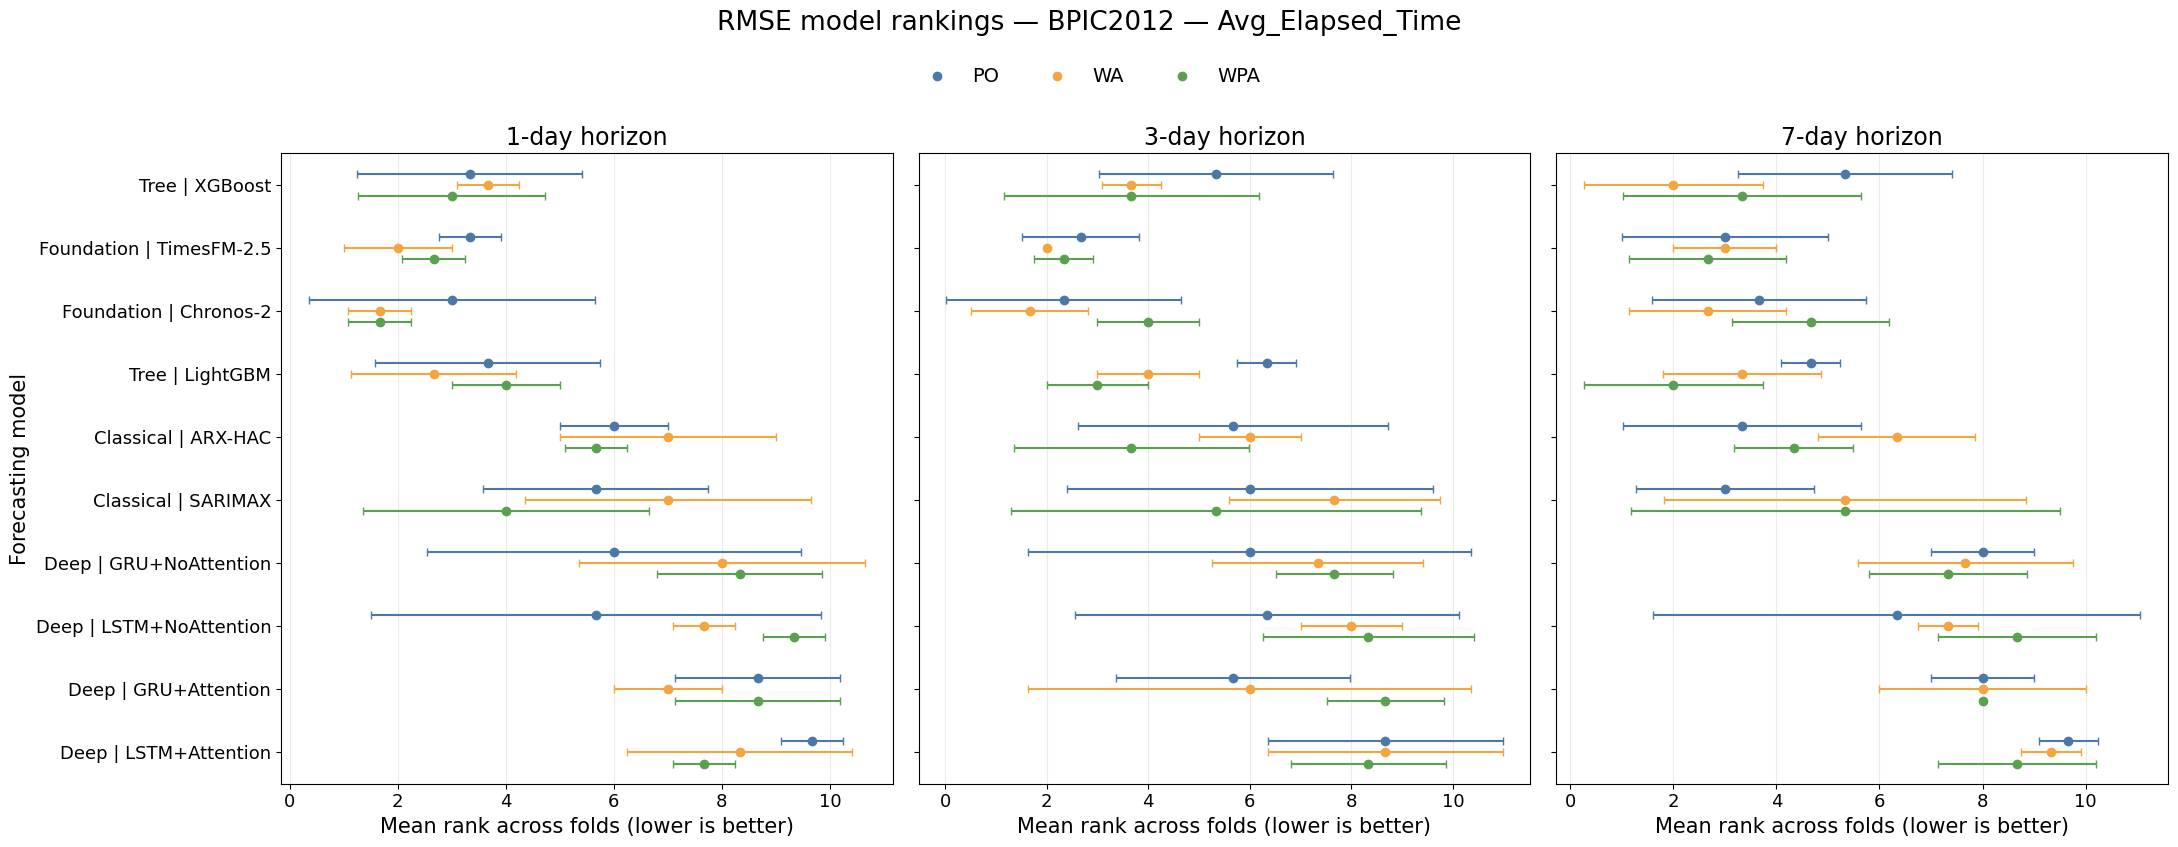

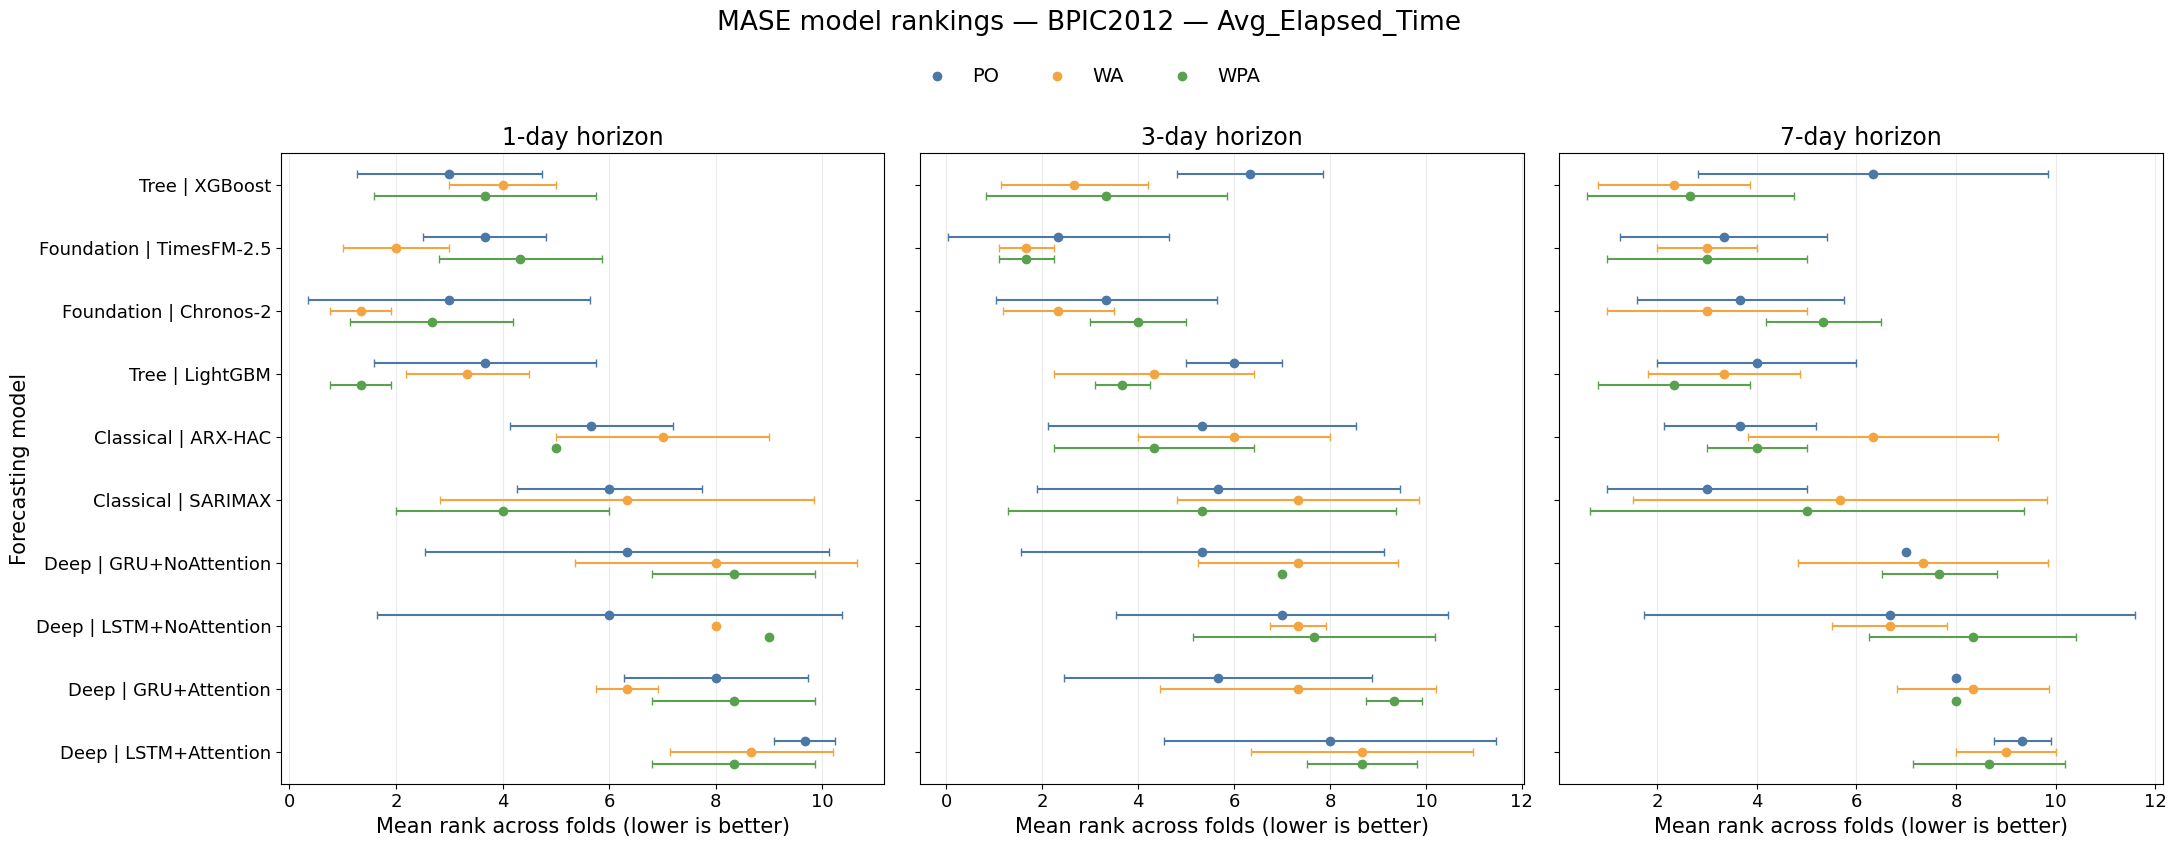

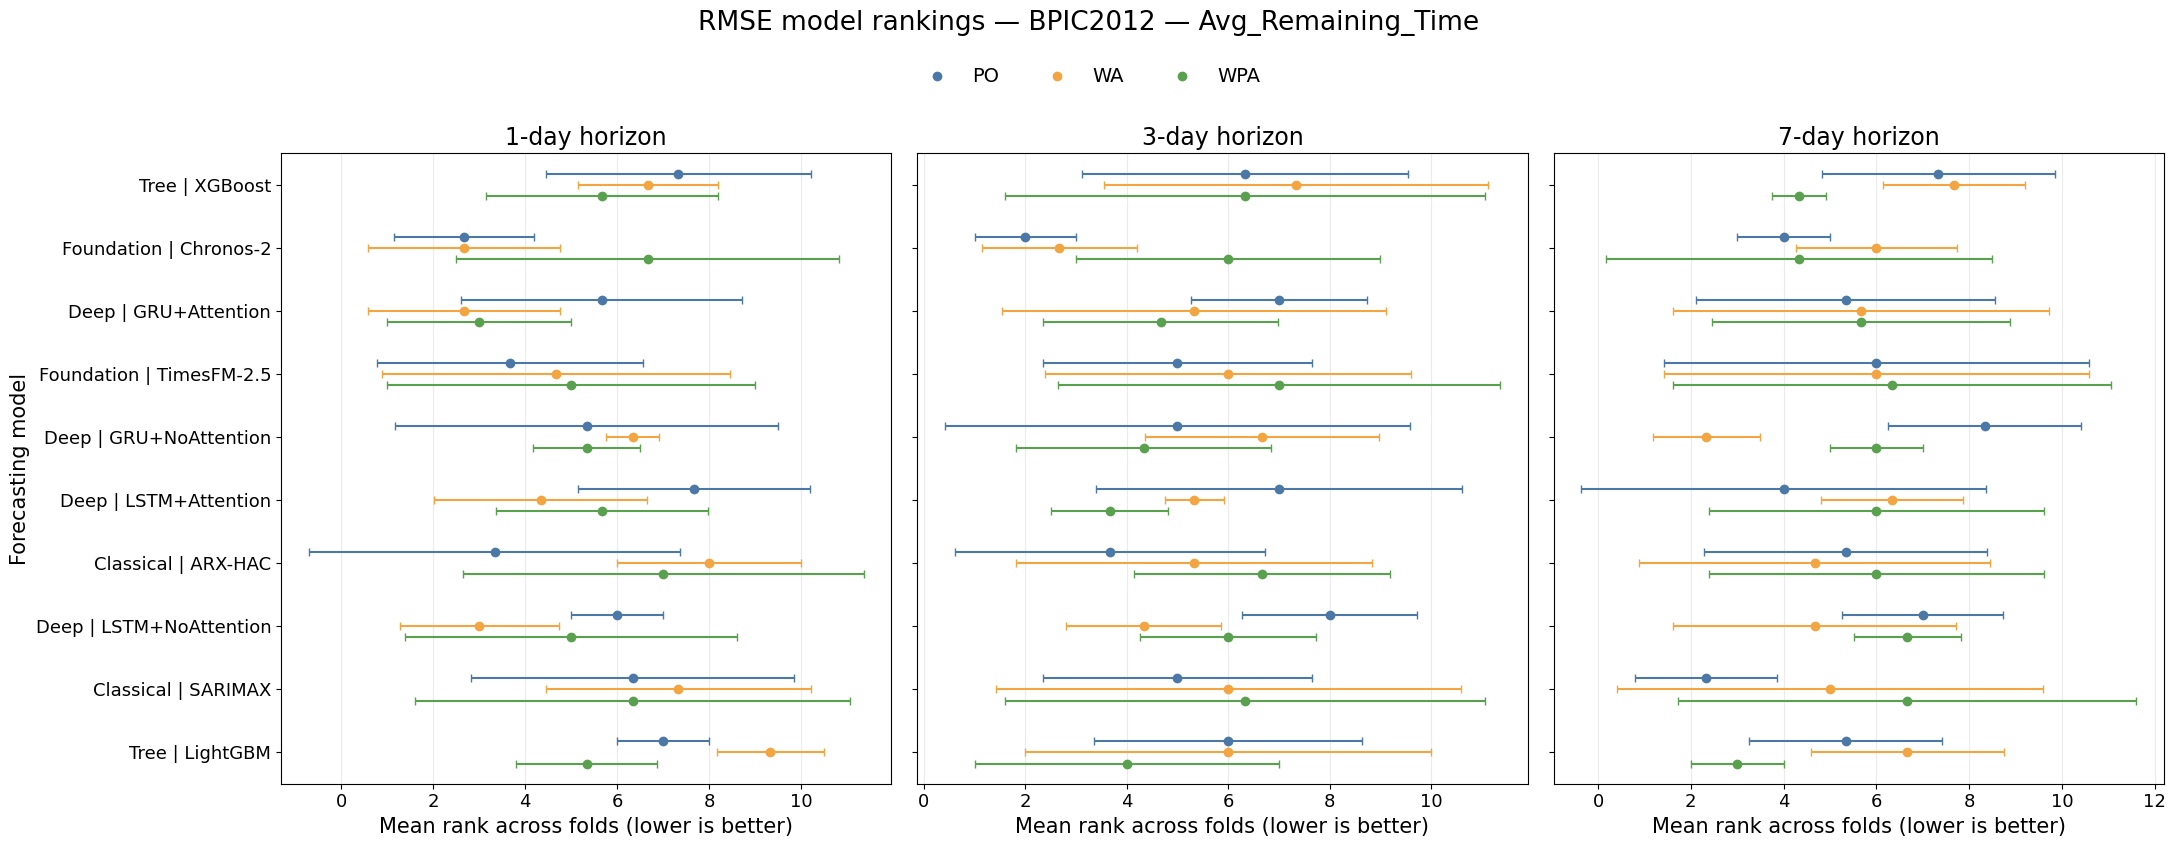

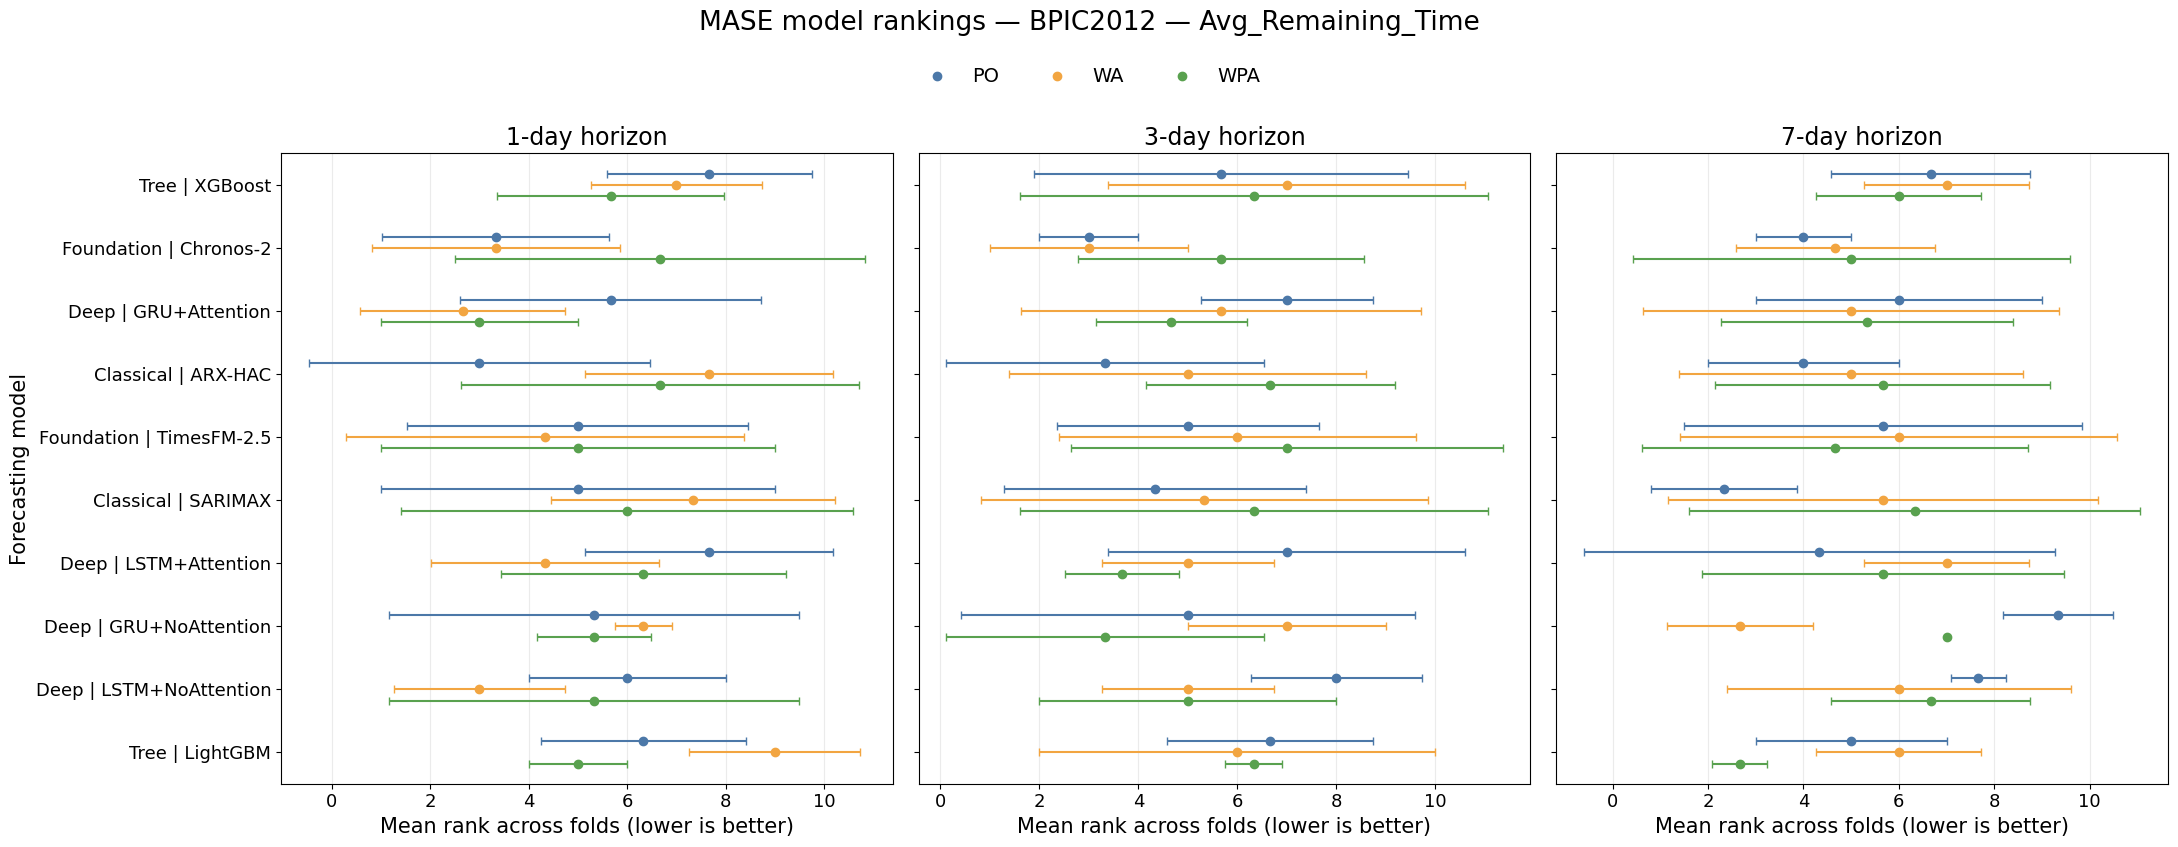

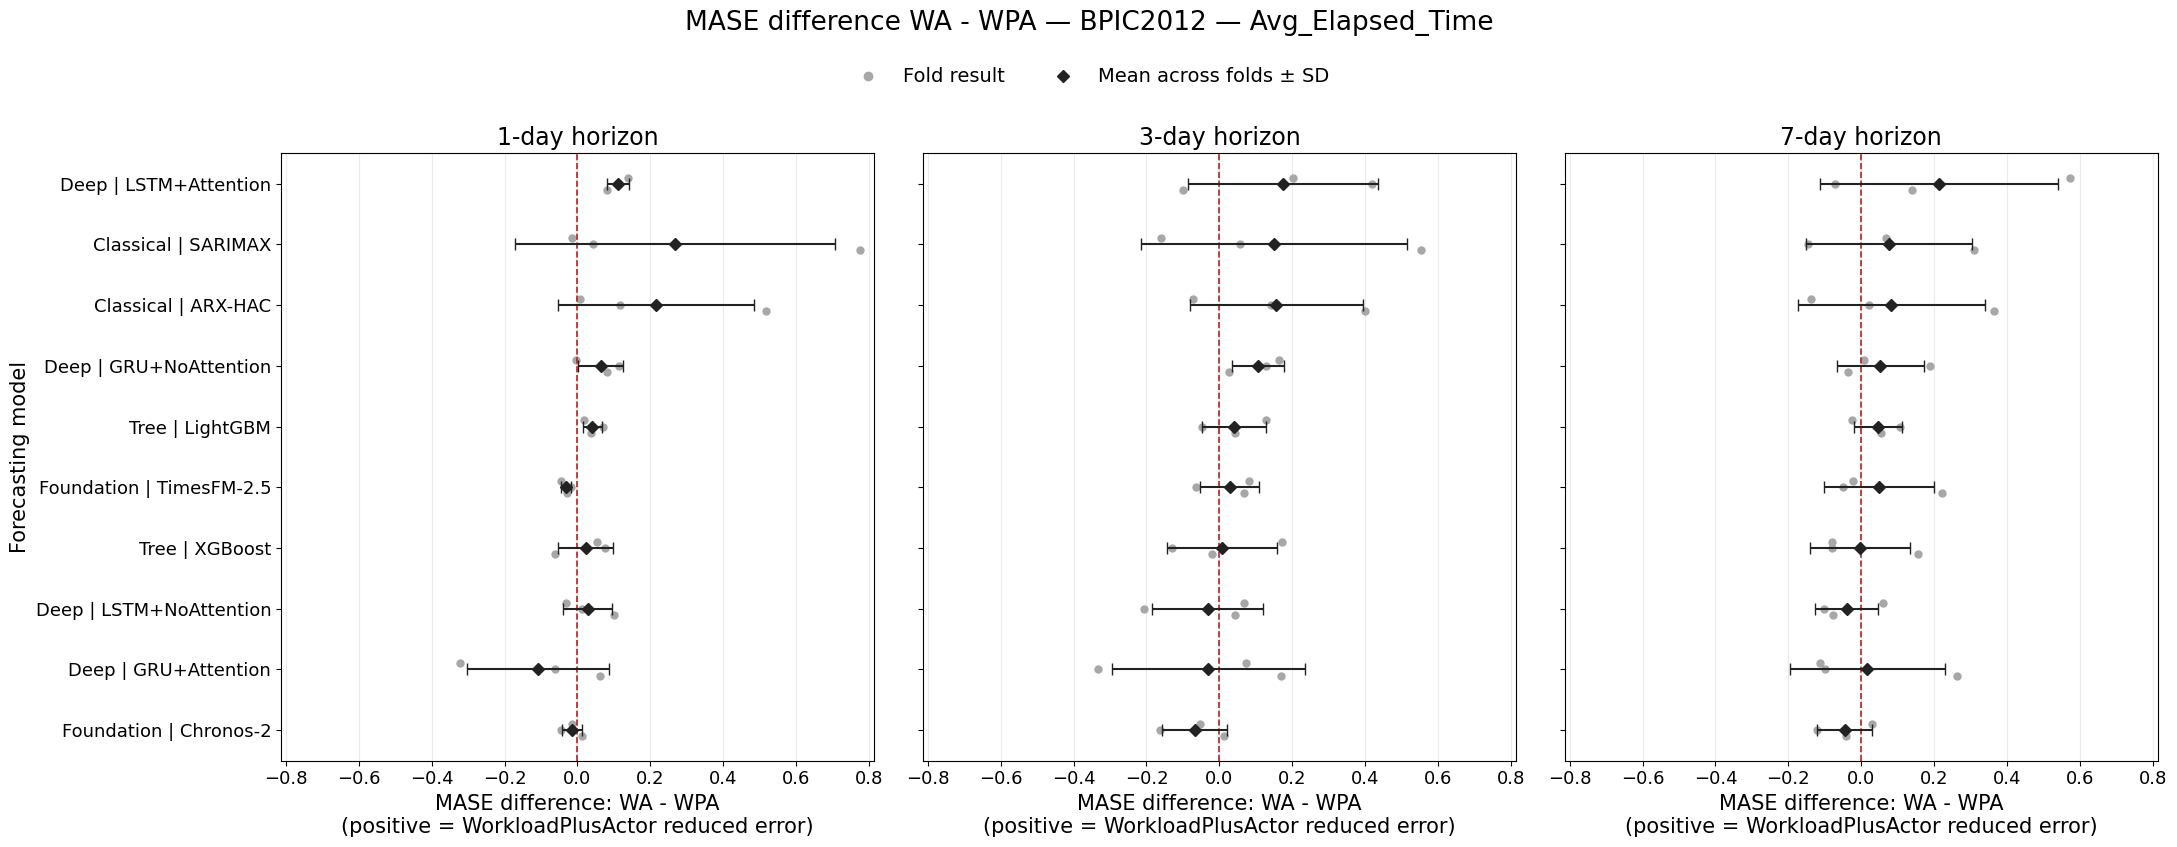

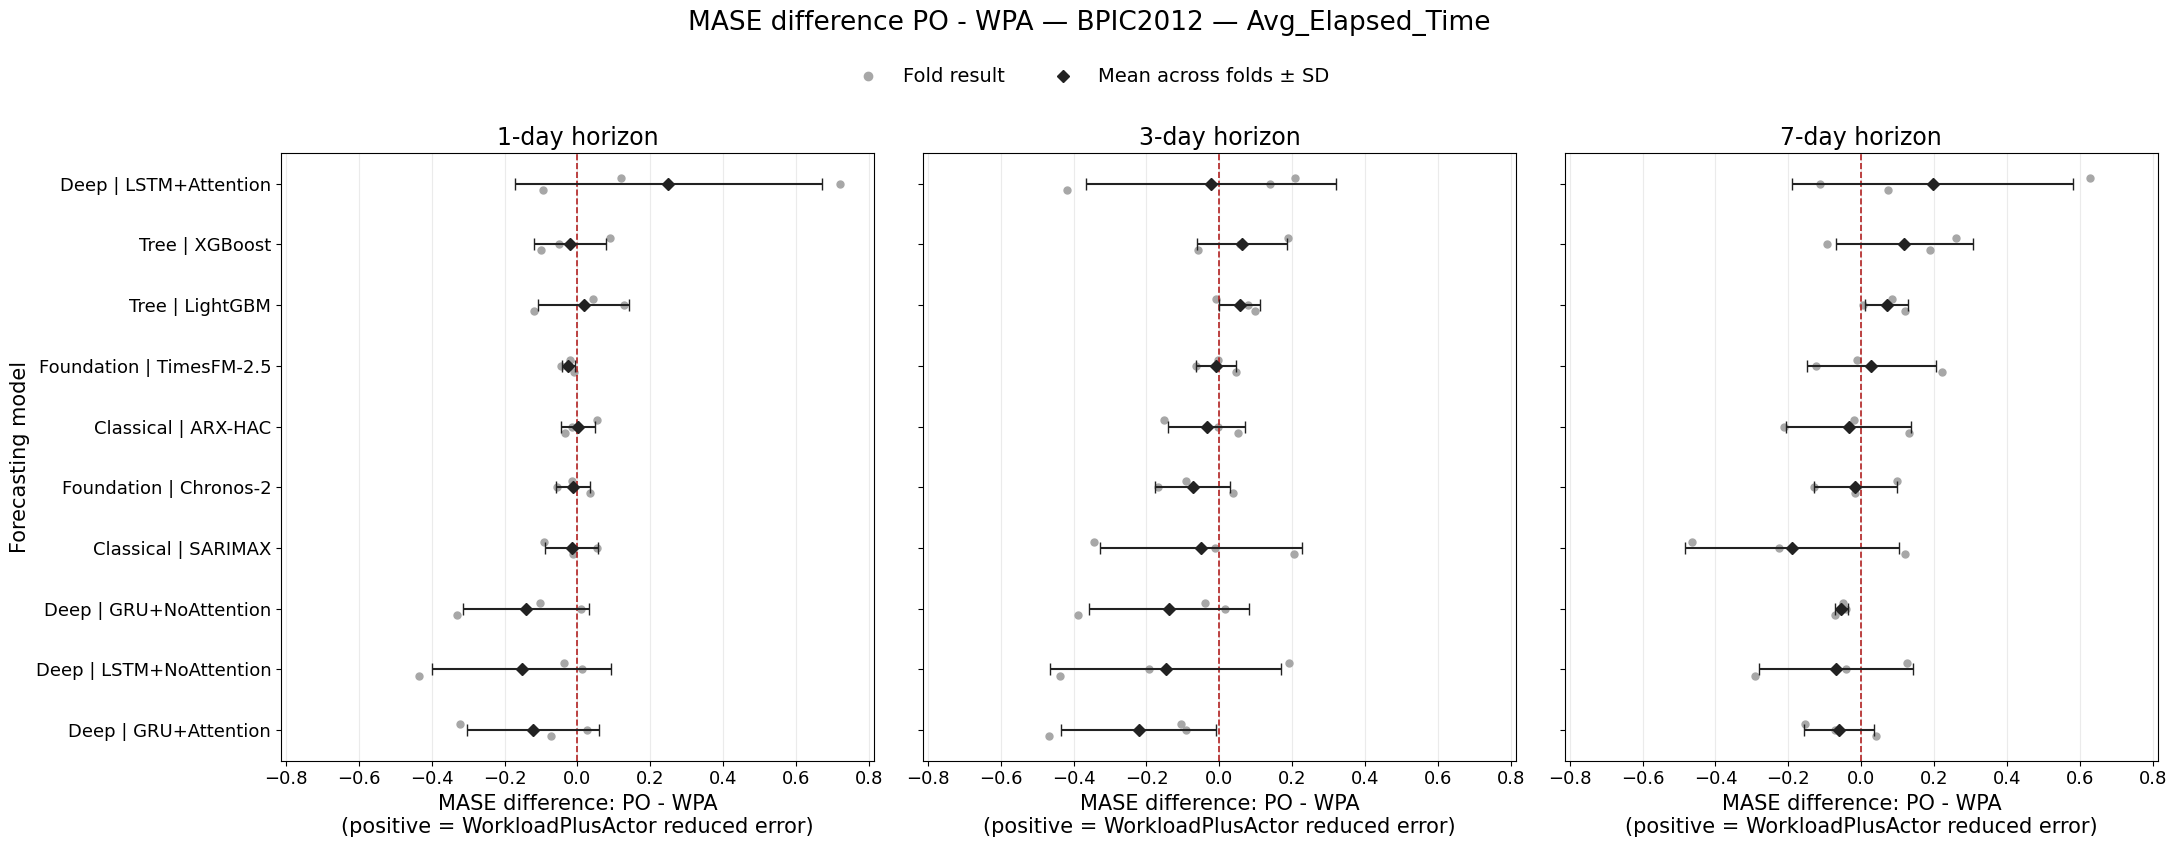

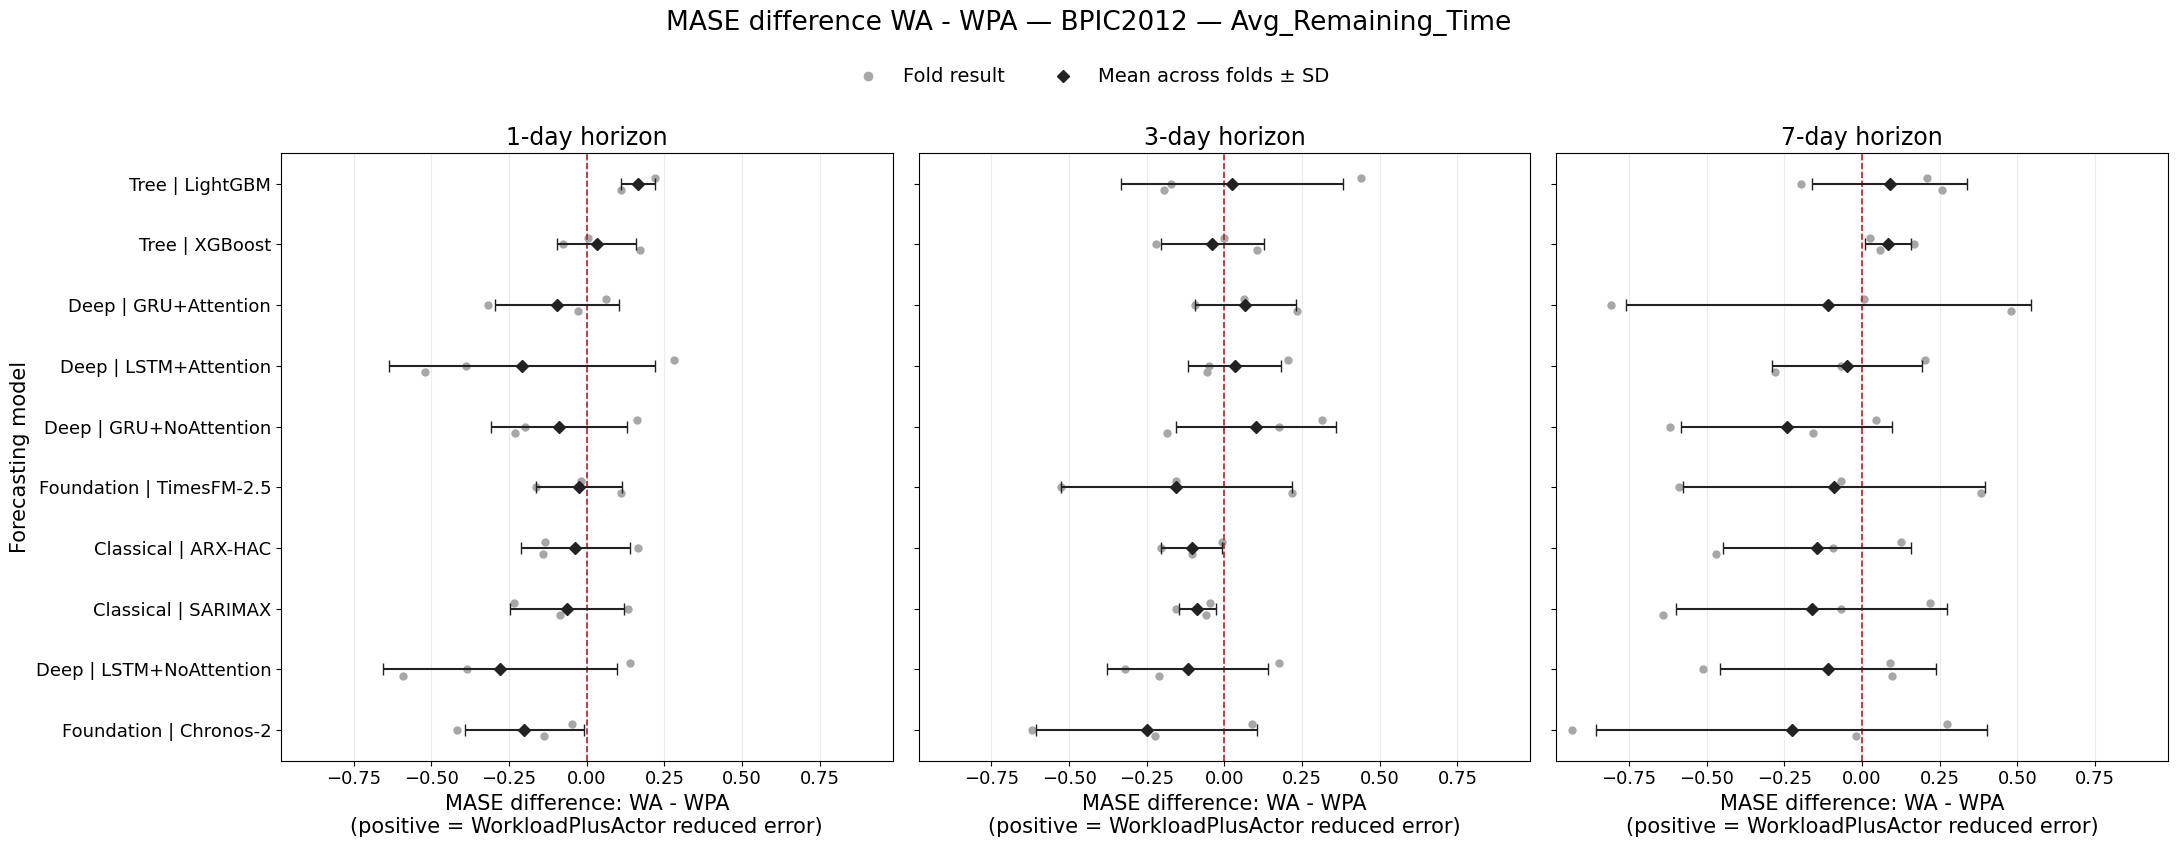

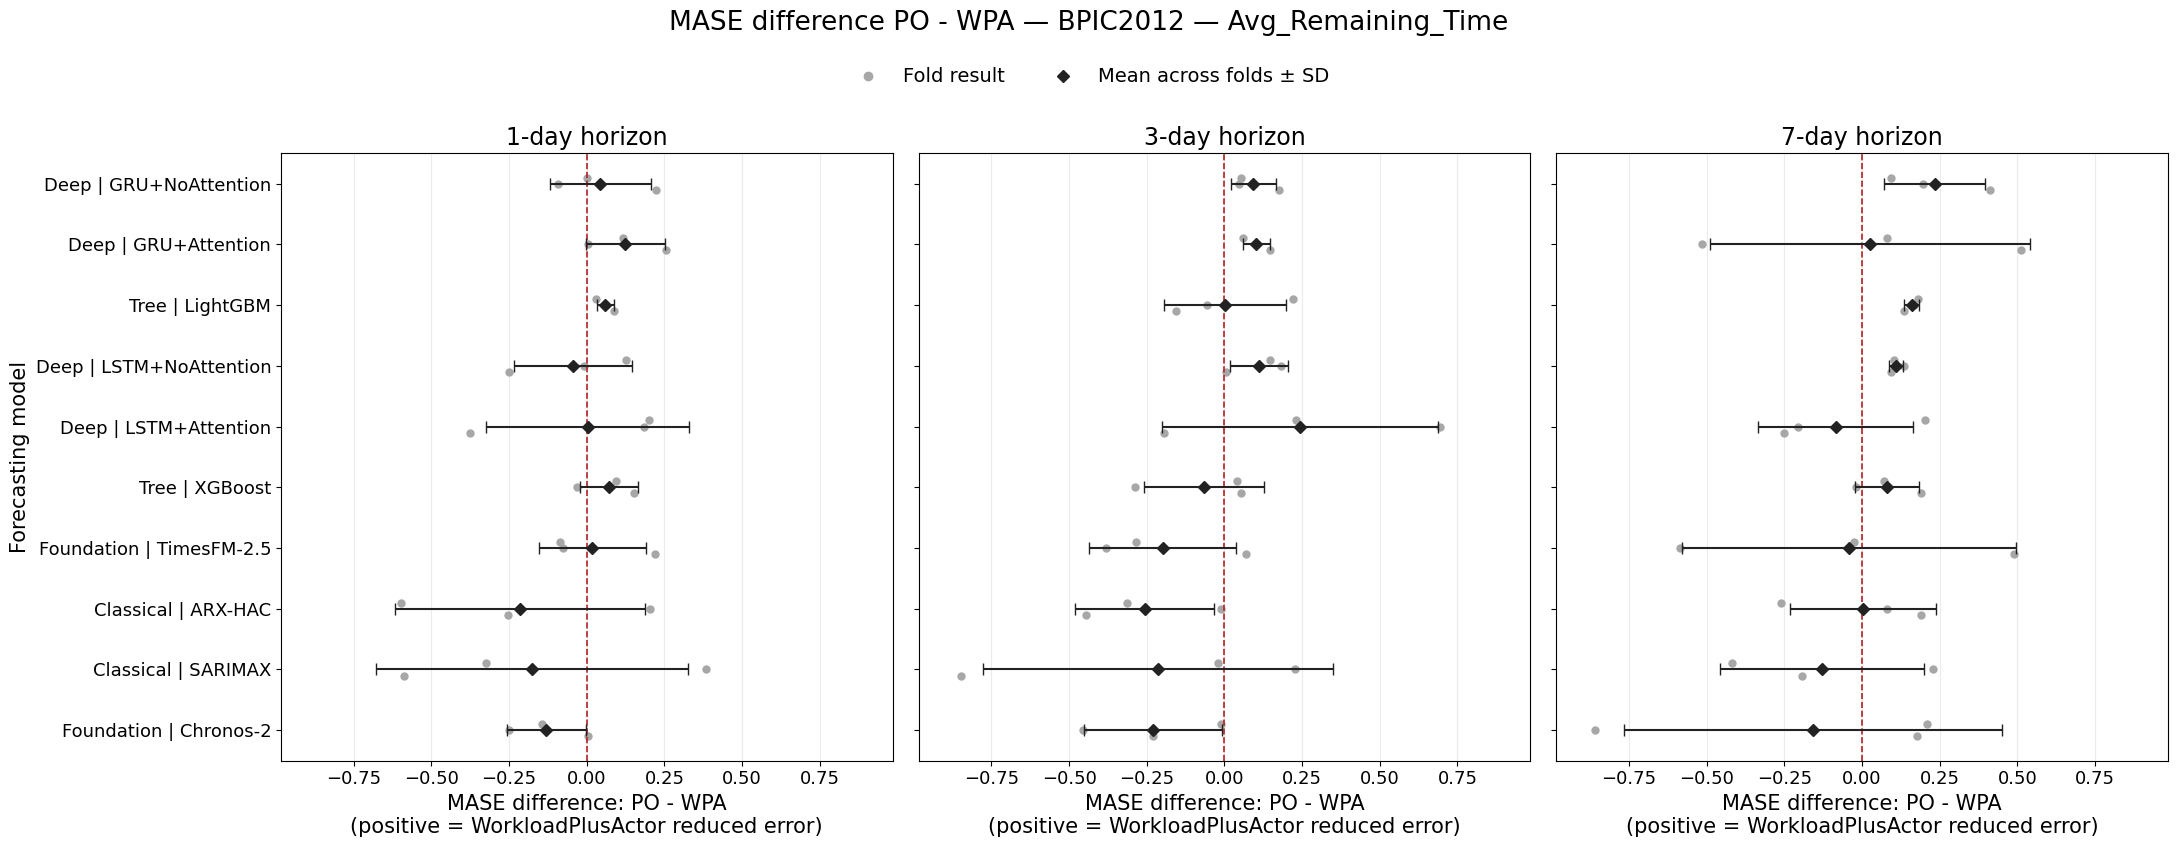

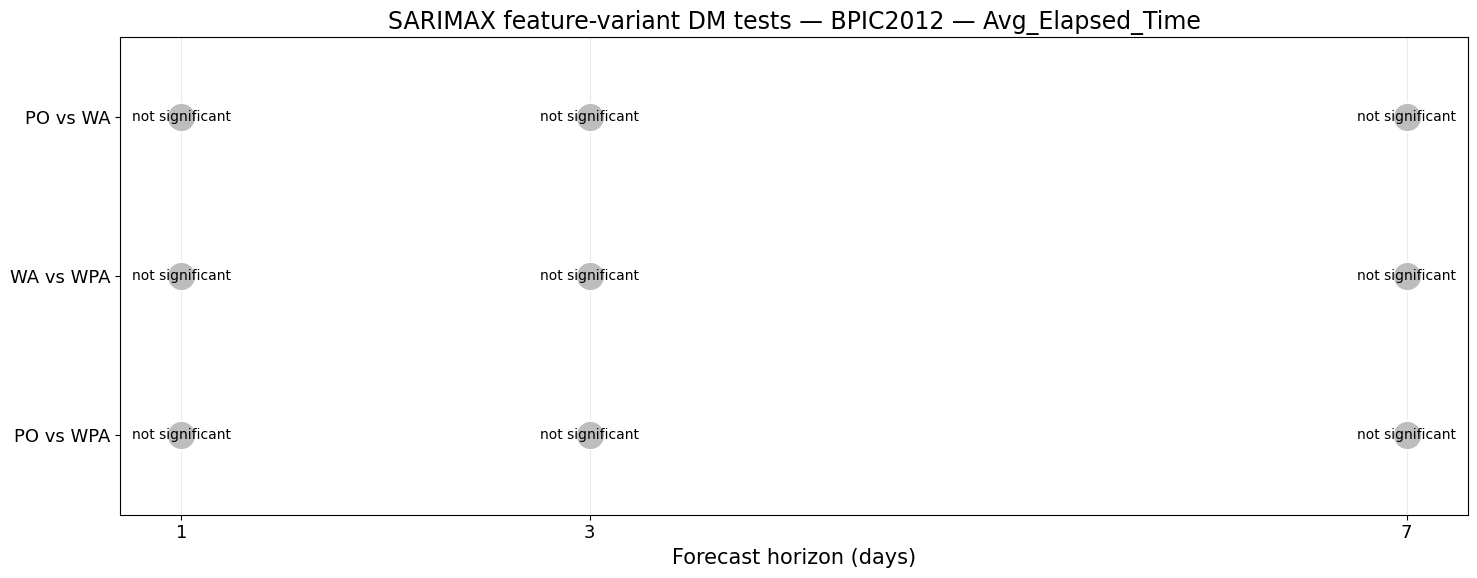

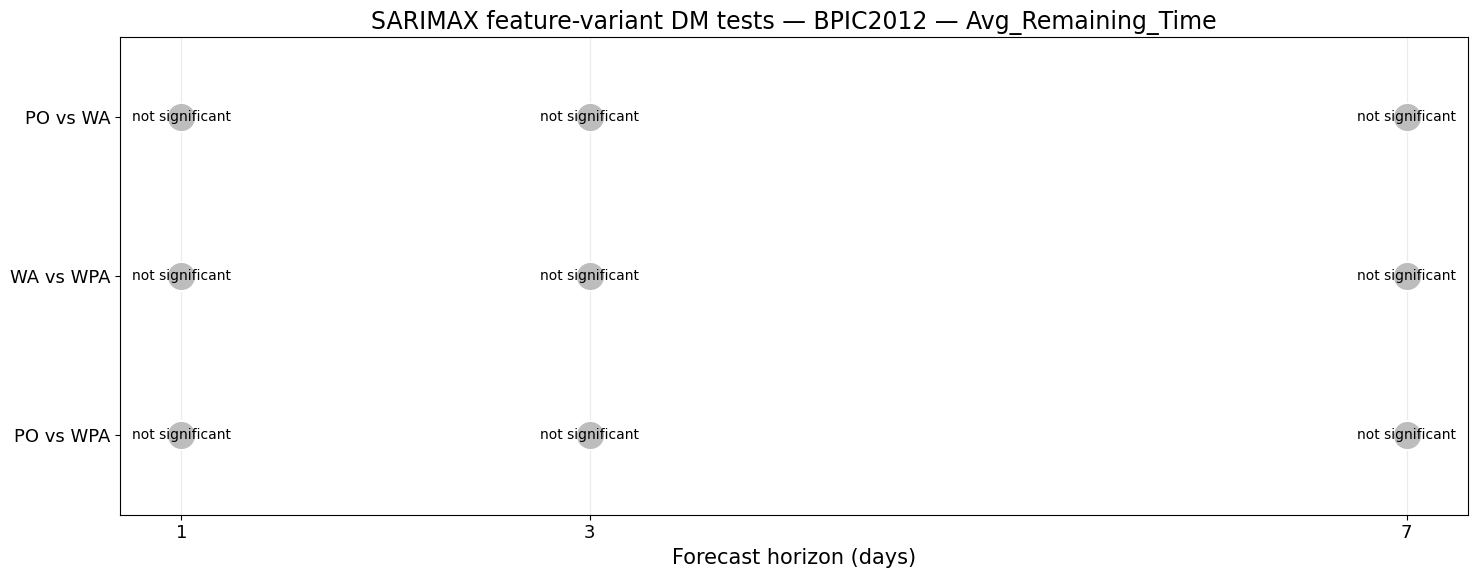

Created /content/BPIC2012_rankings_and_effects.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


Upload the combined results ZIP for BPIC2017.


Saving combined_uploaded_model_results.zip to combined_uploaded_model_results (3).zip


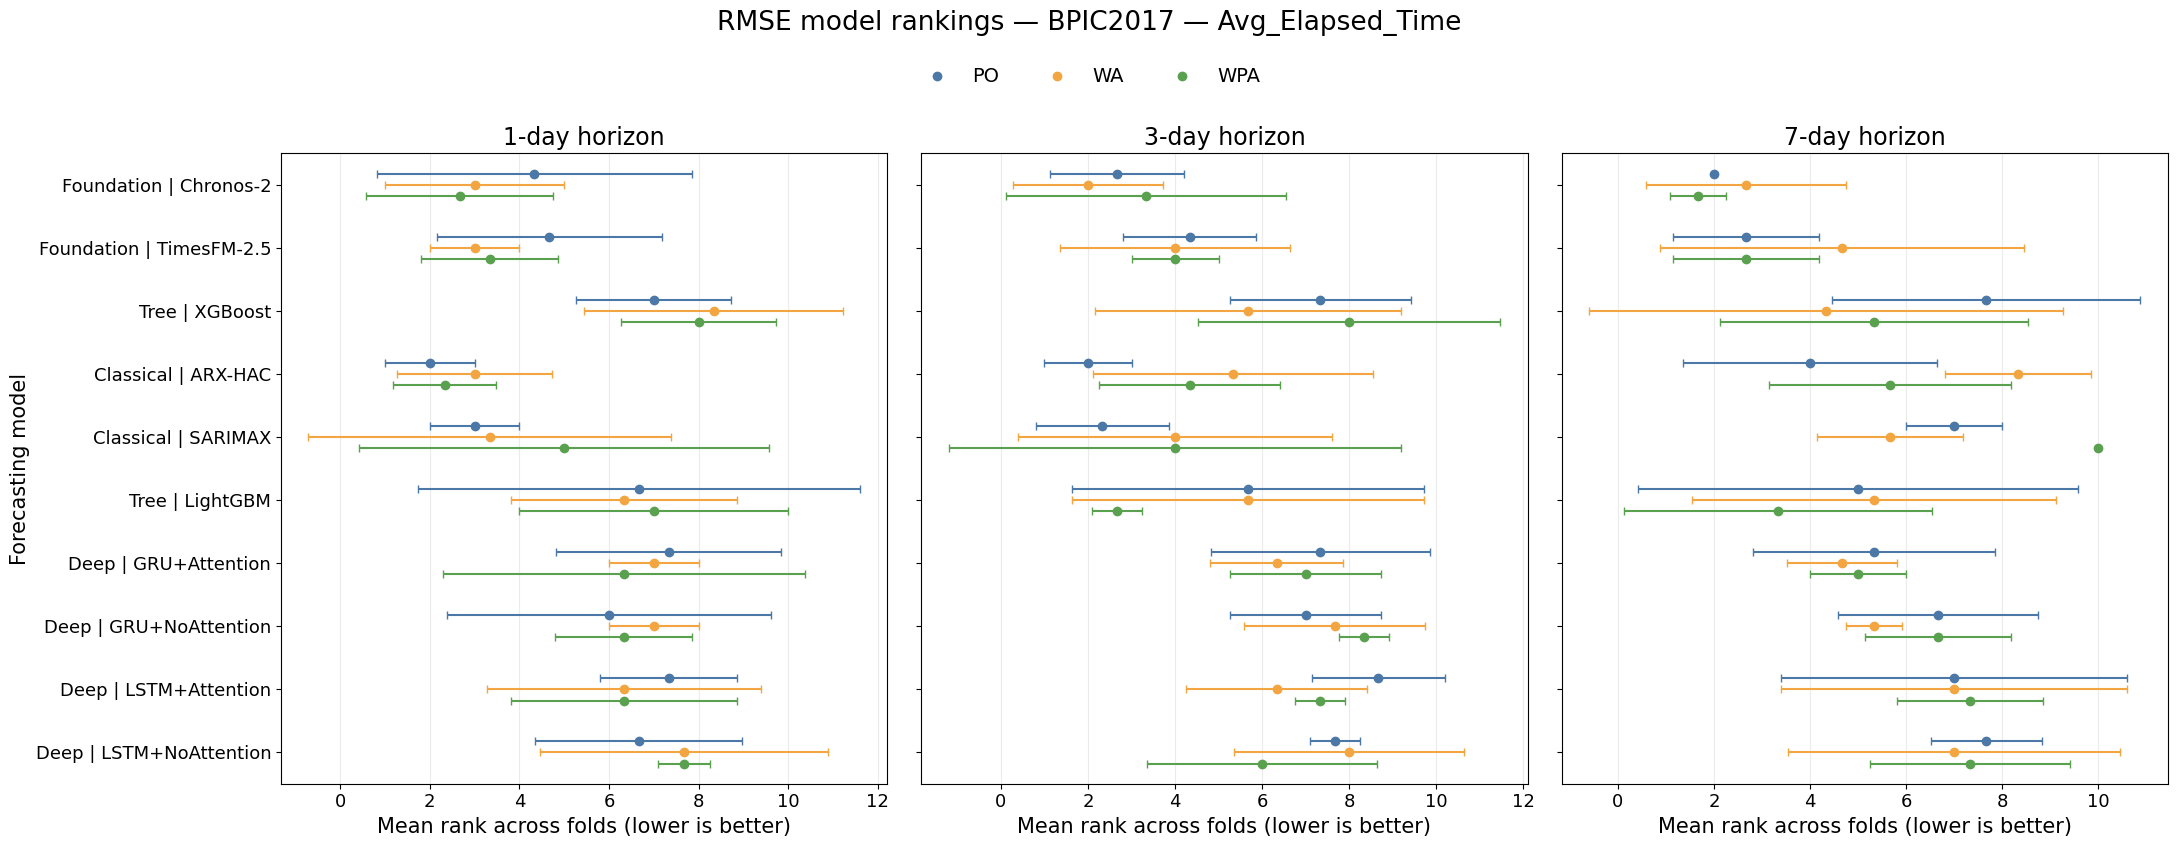

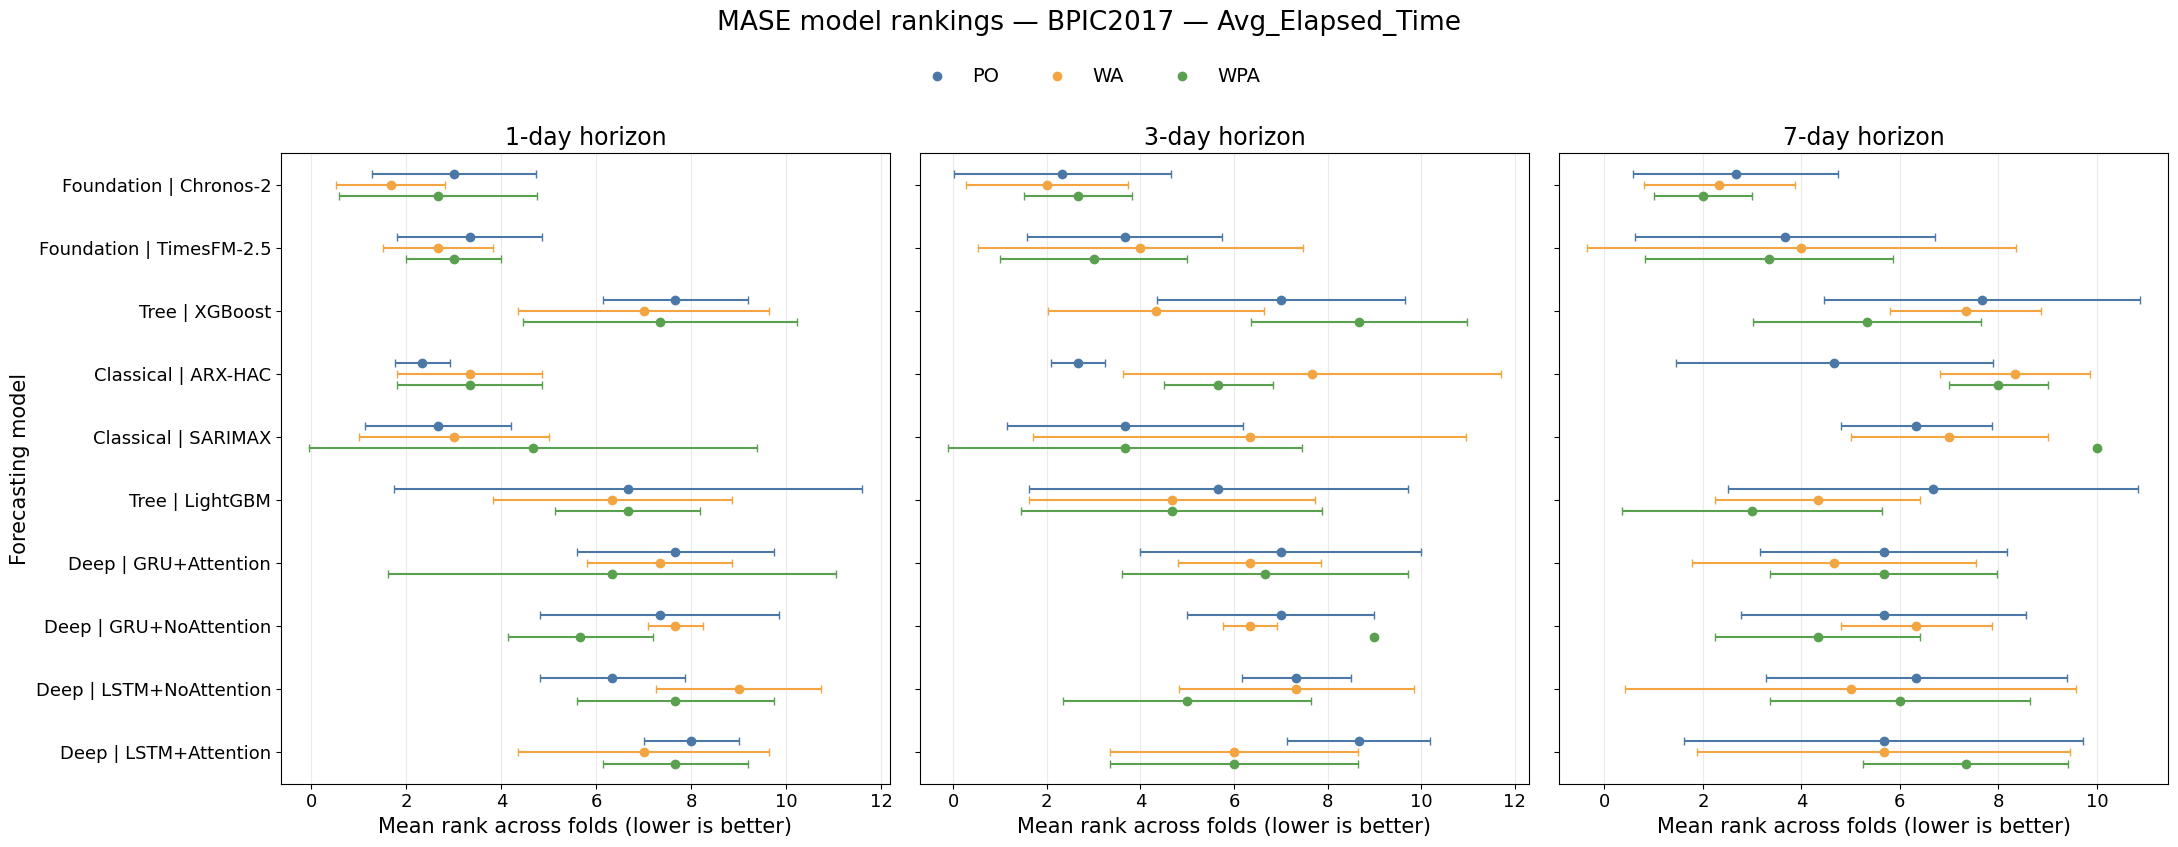

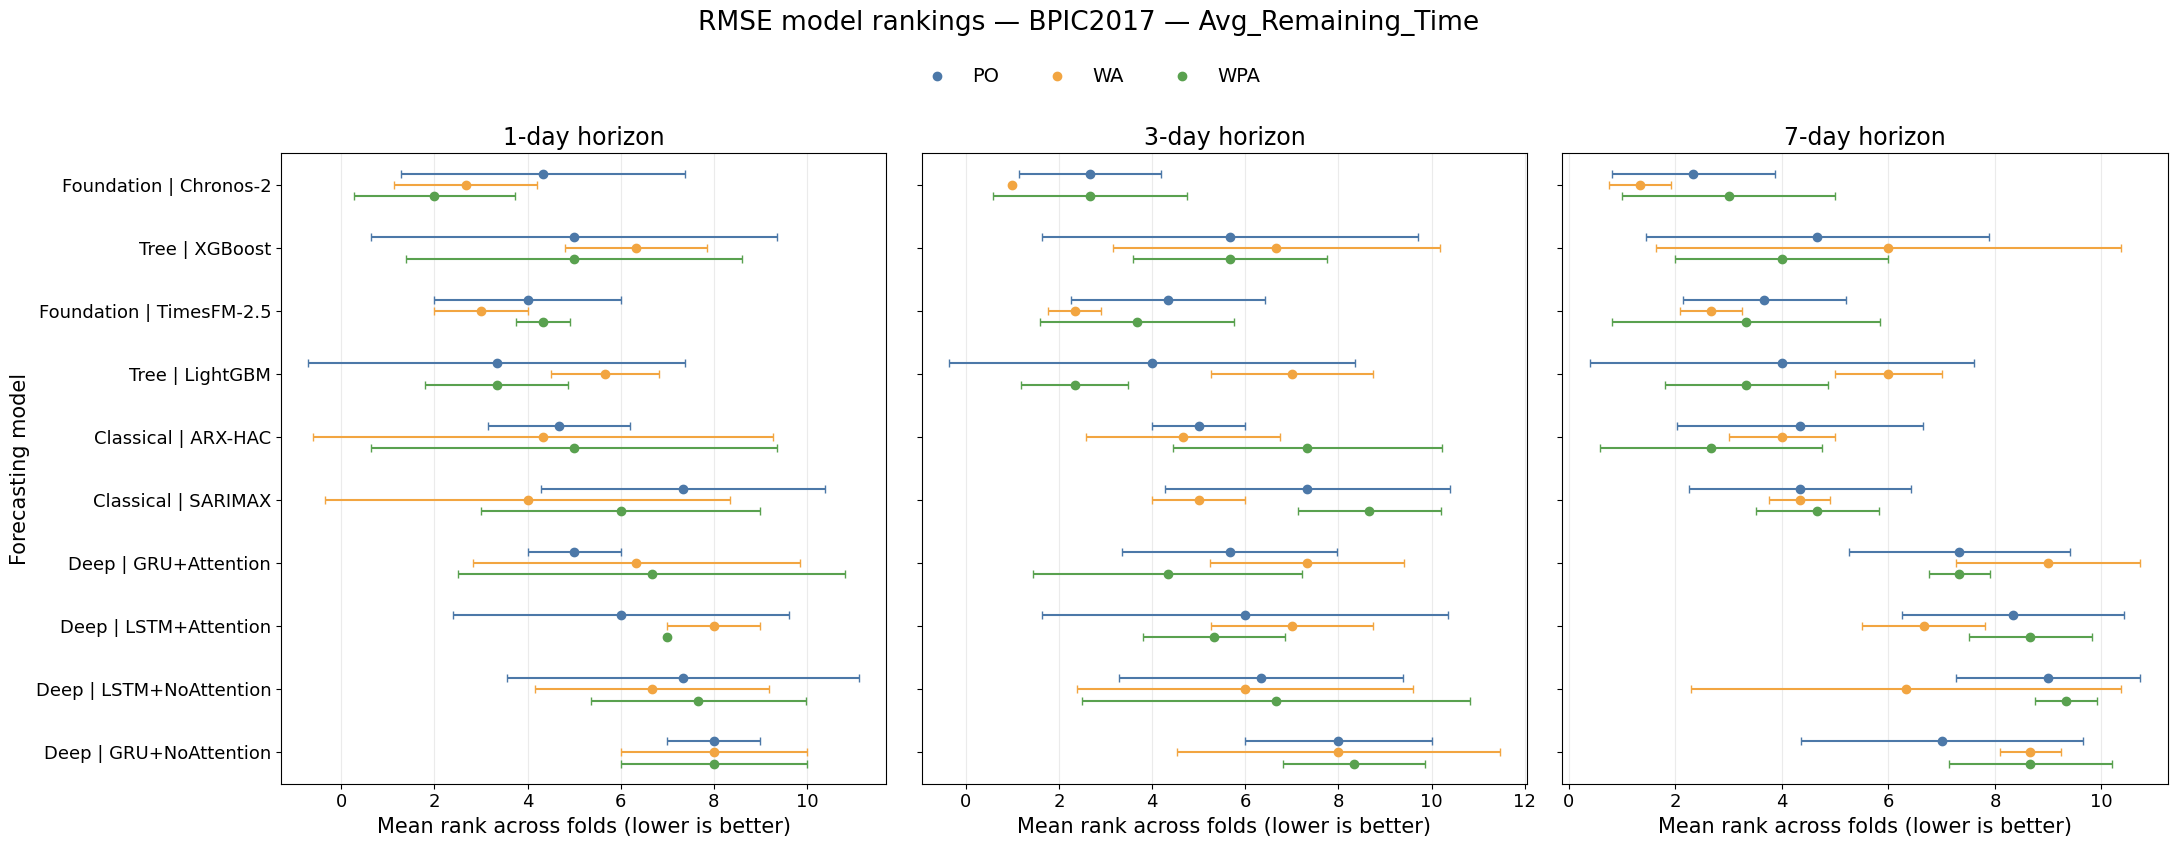

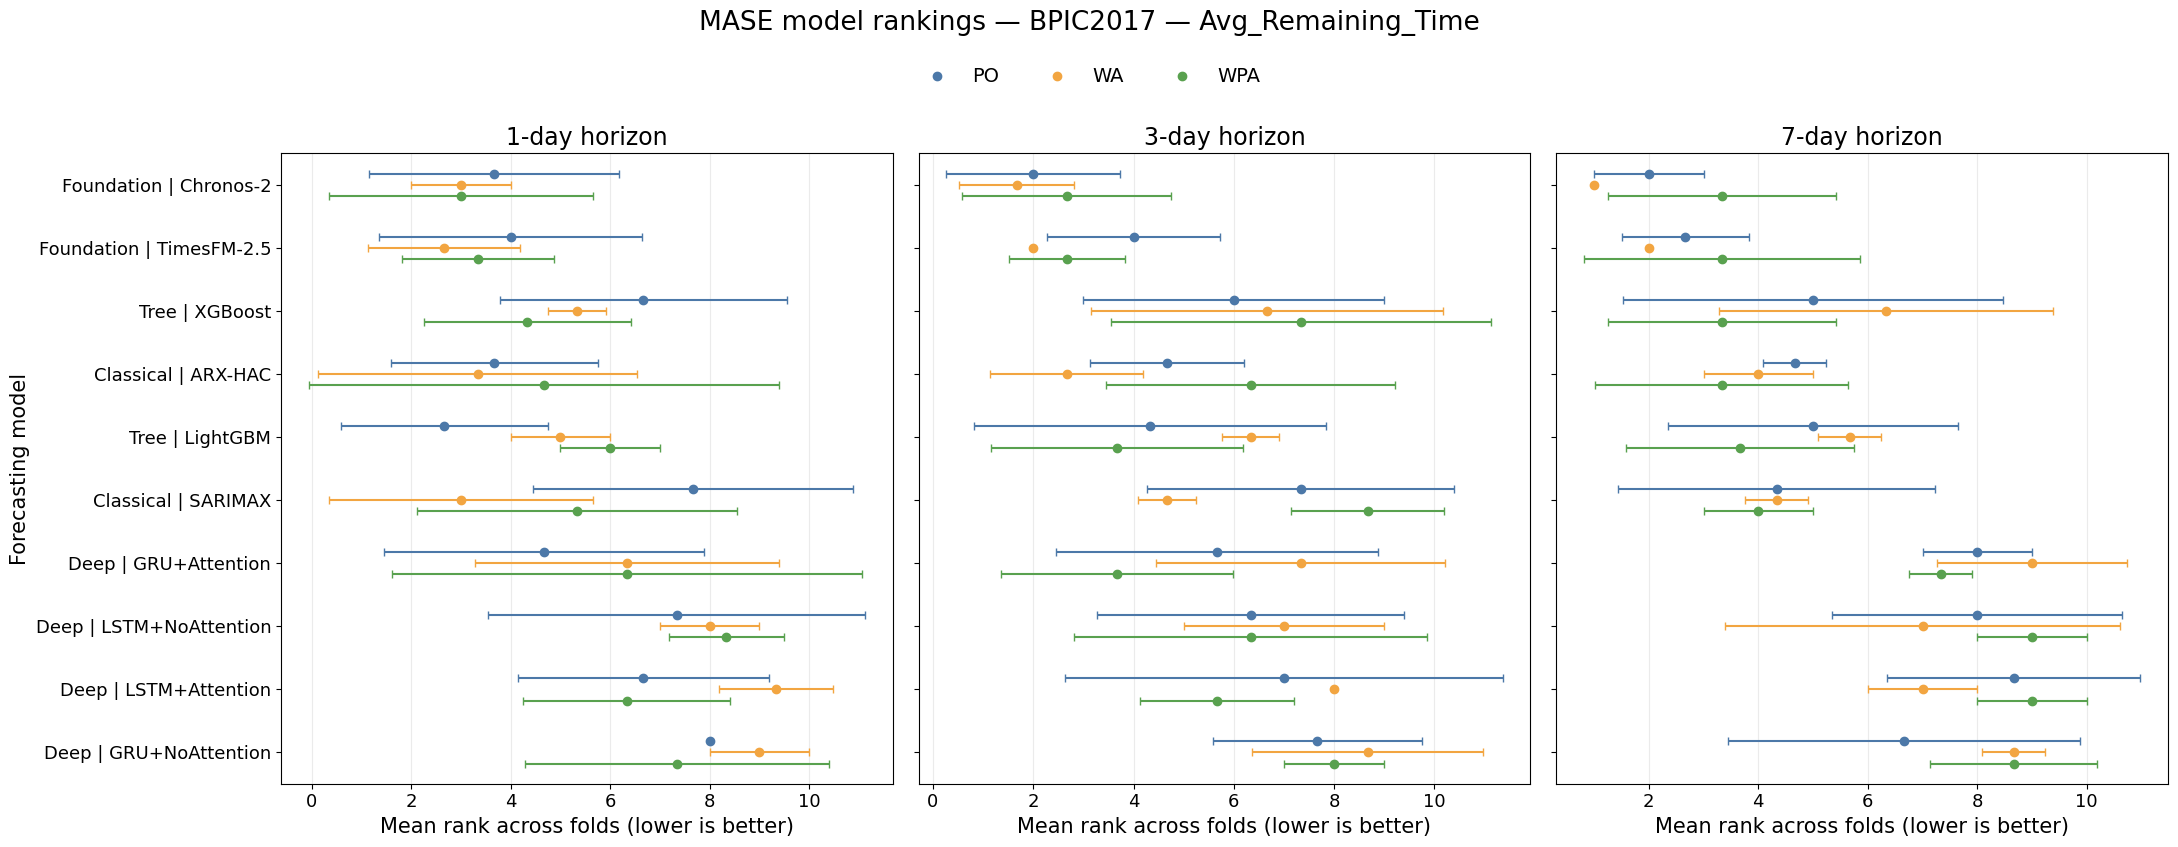

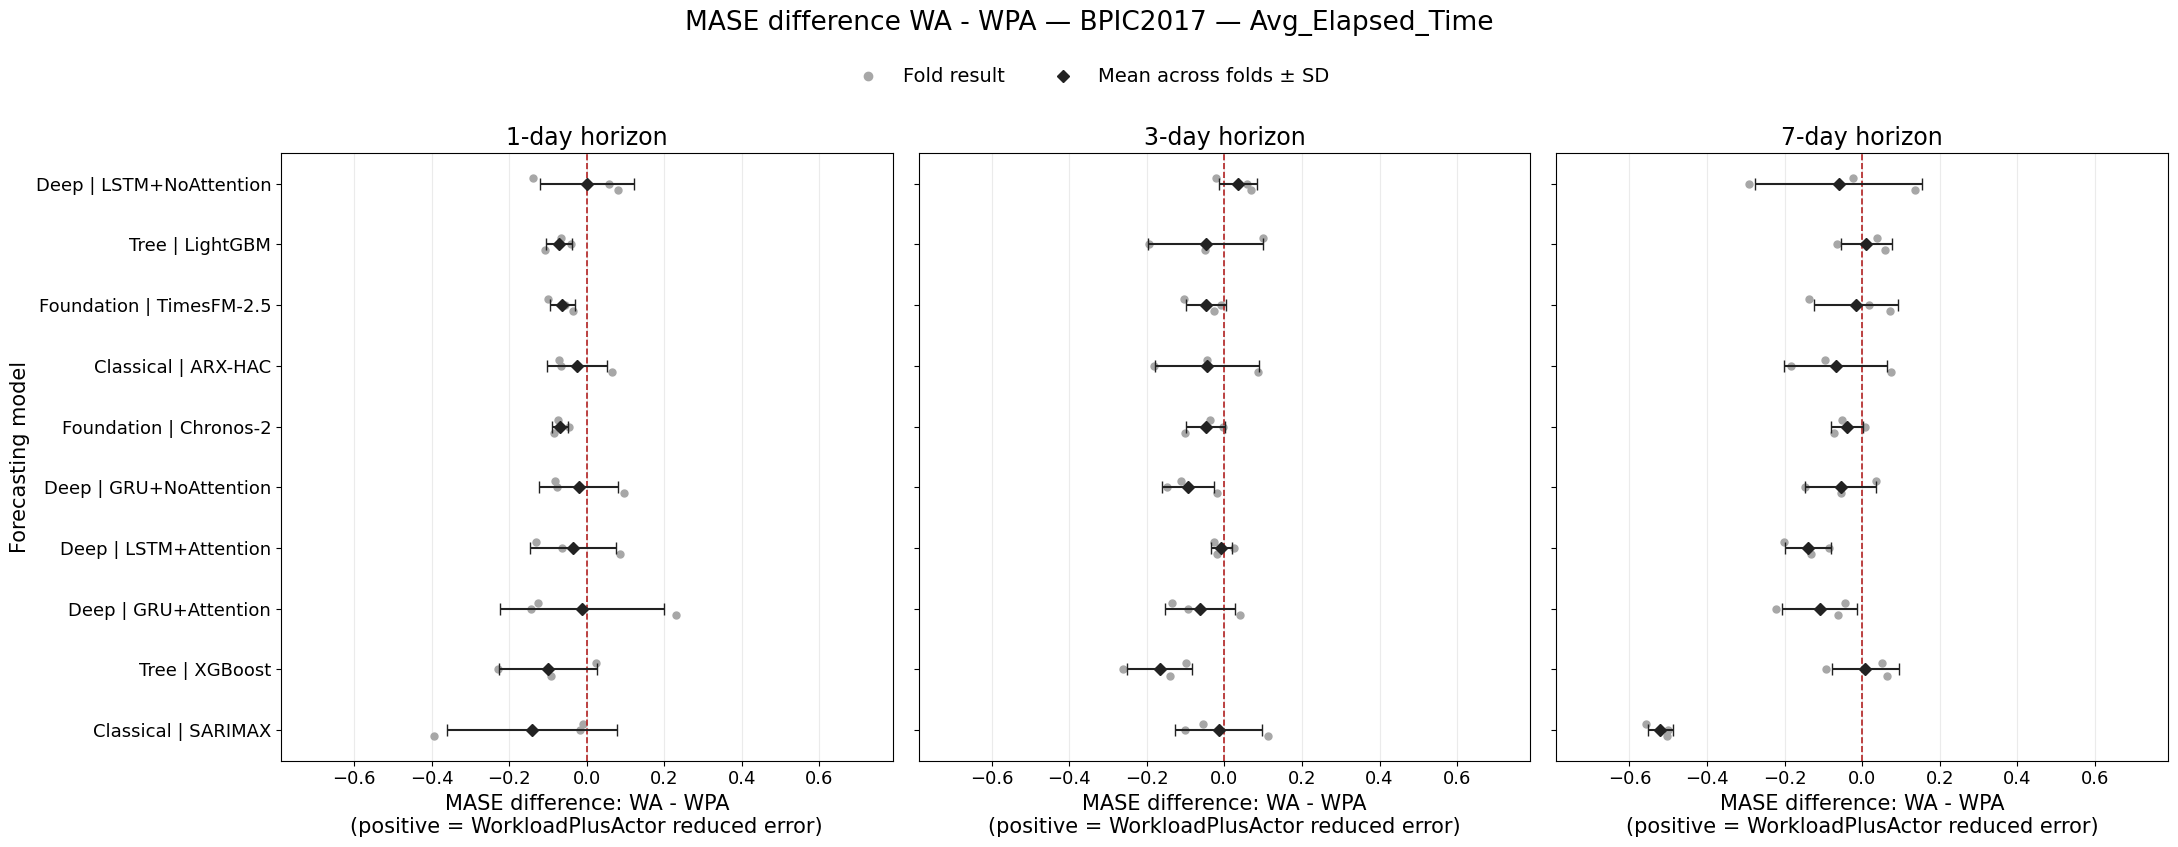

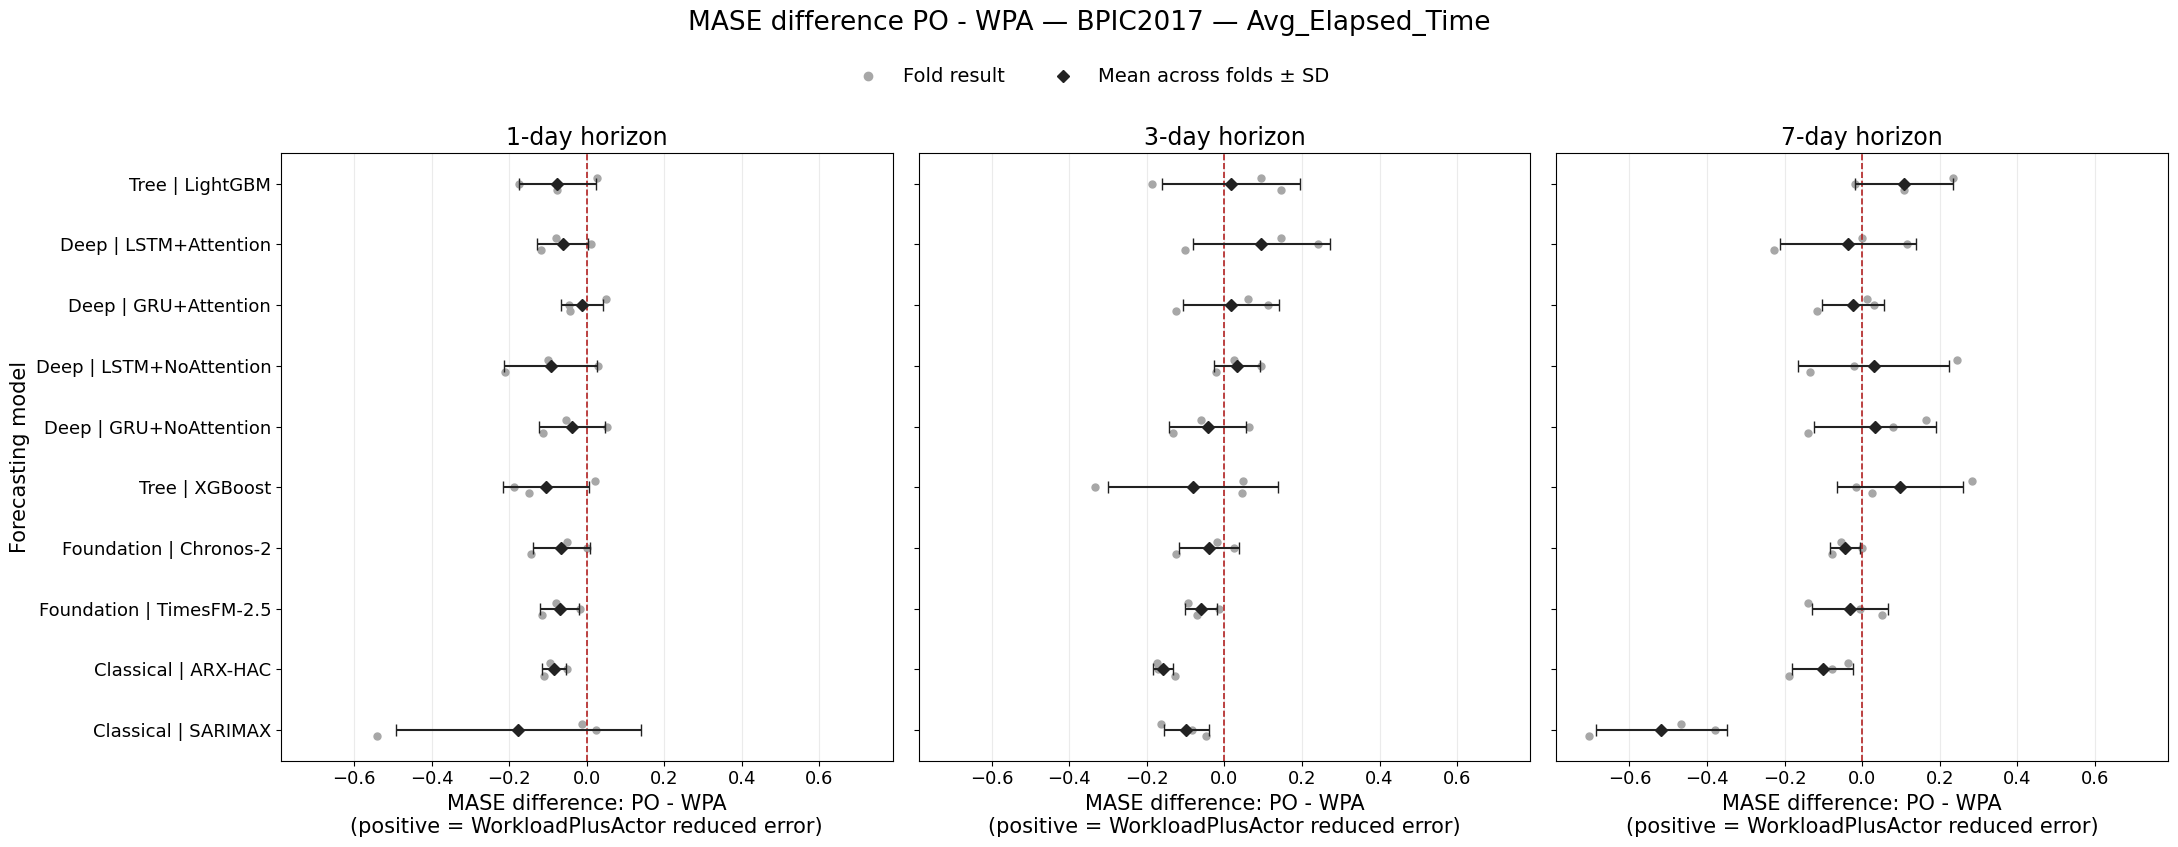

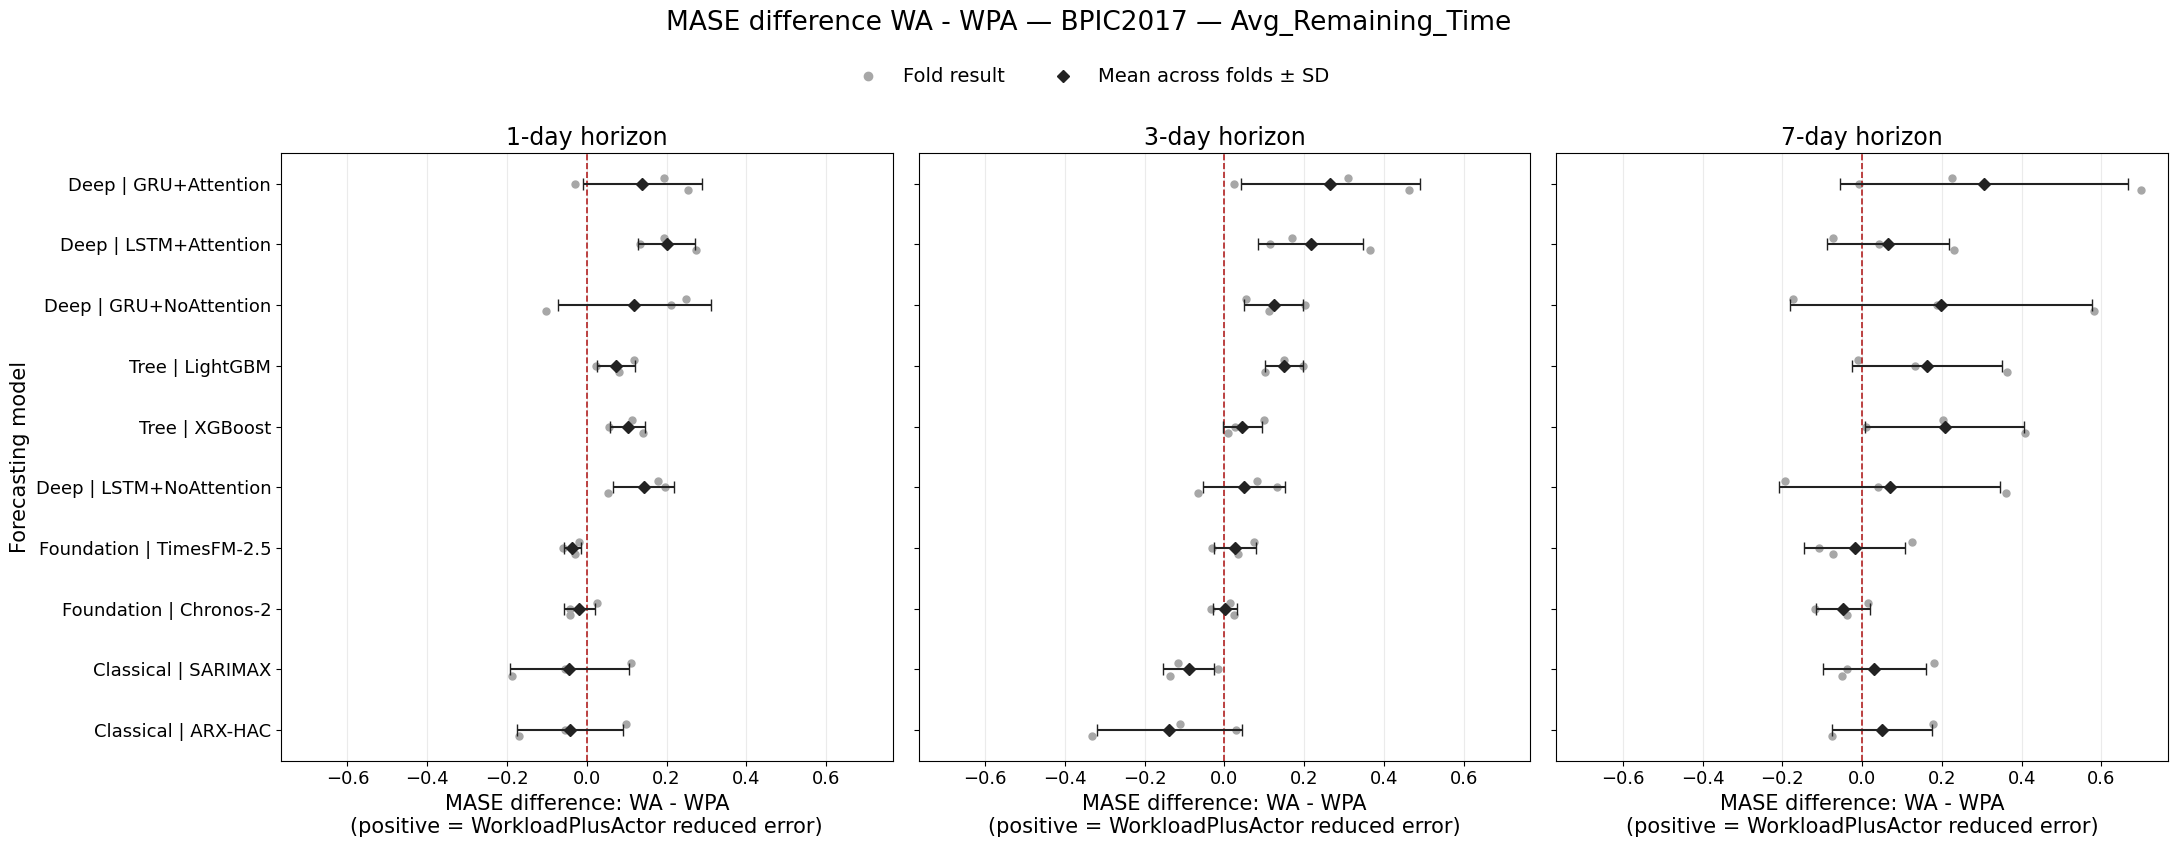

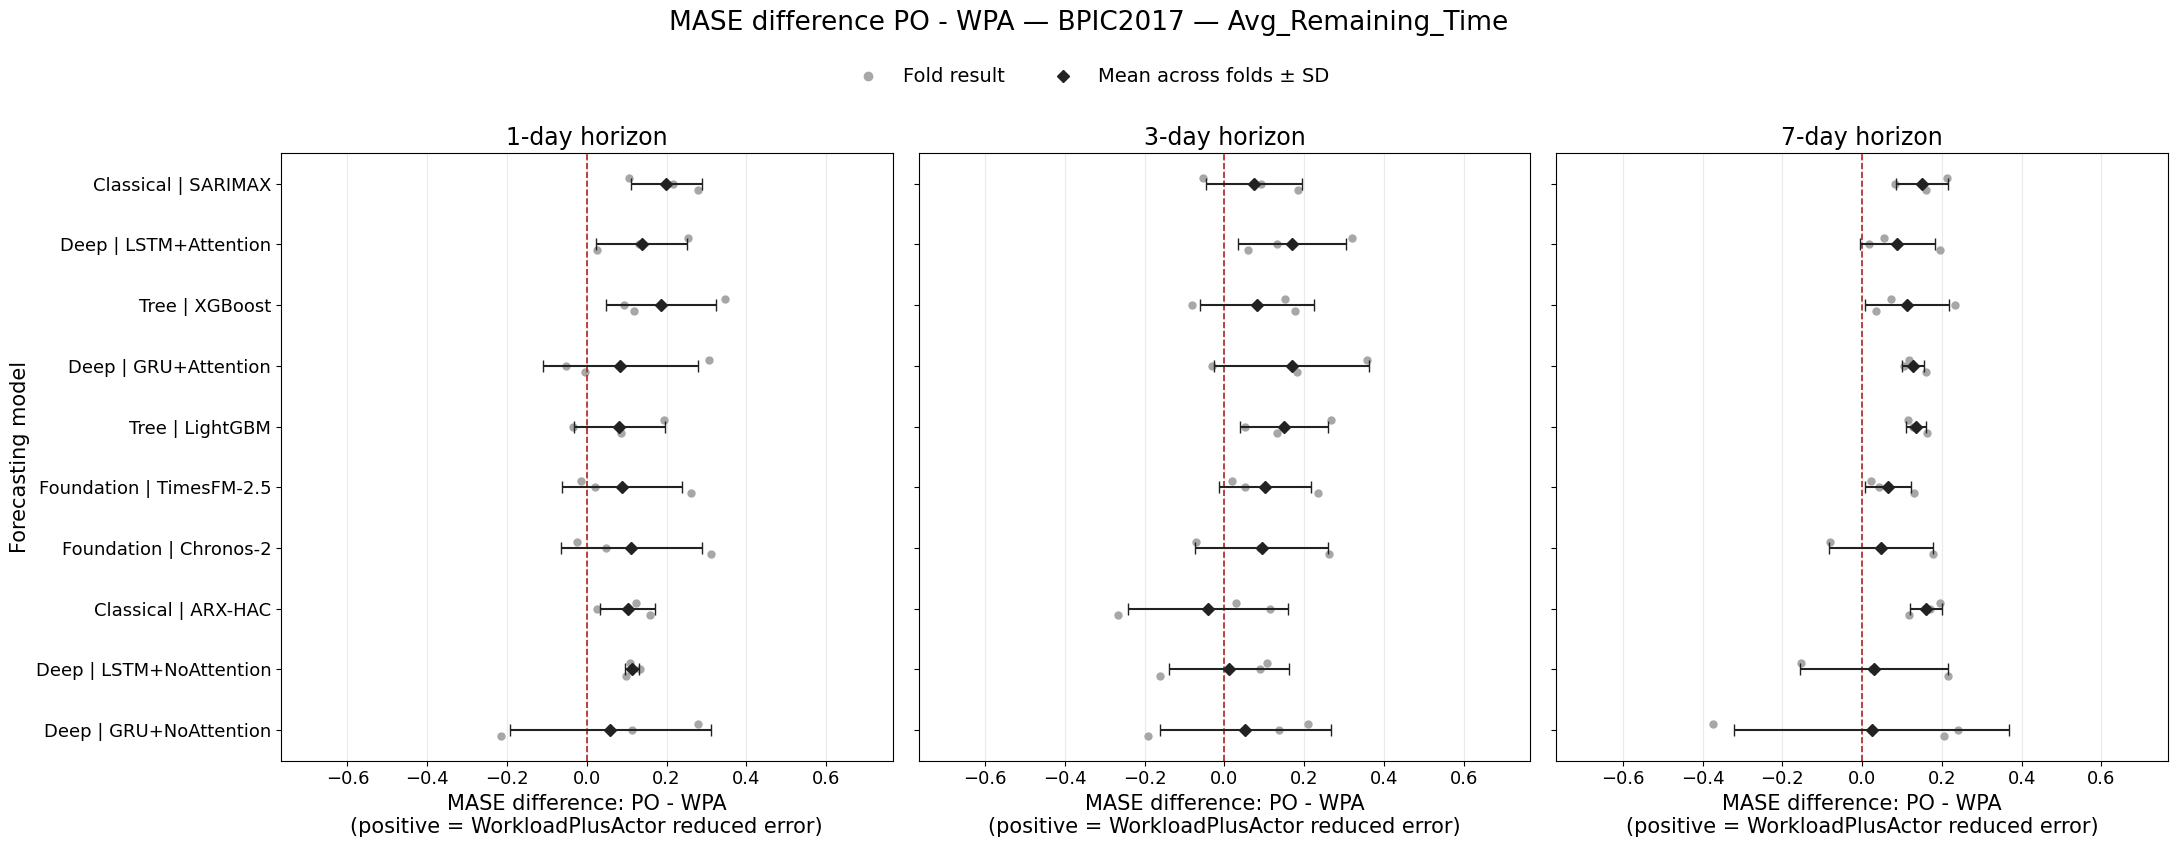

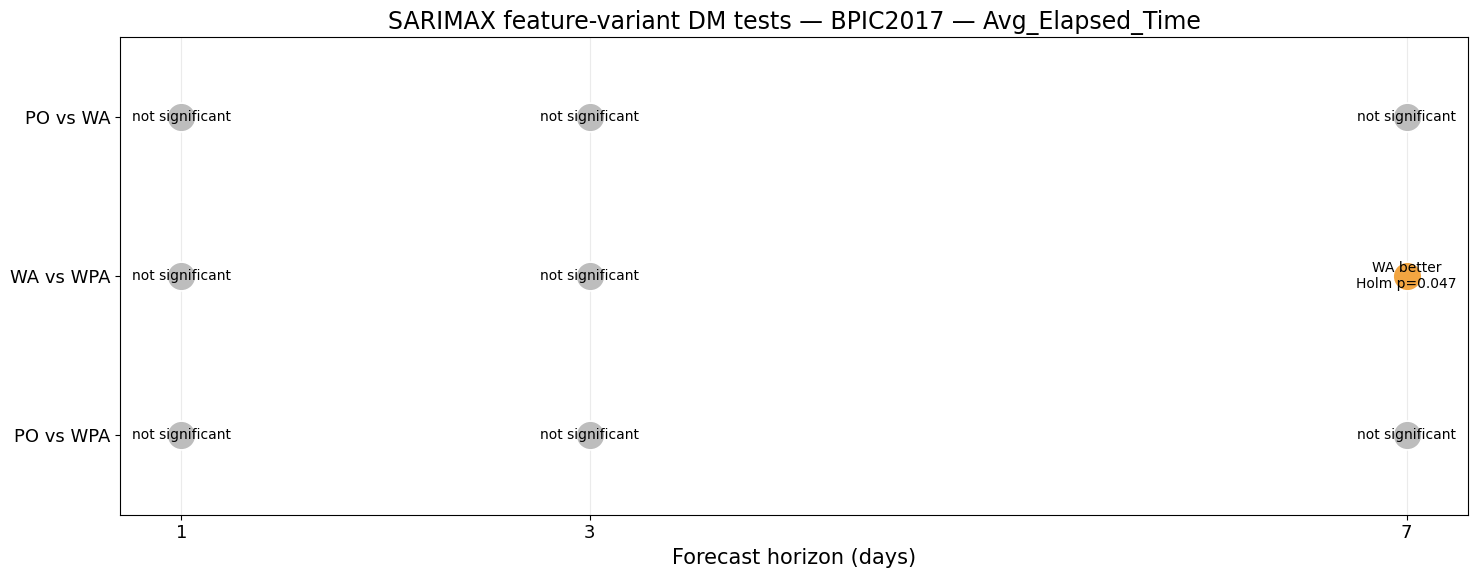

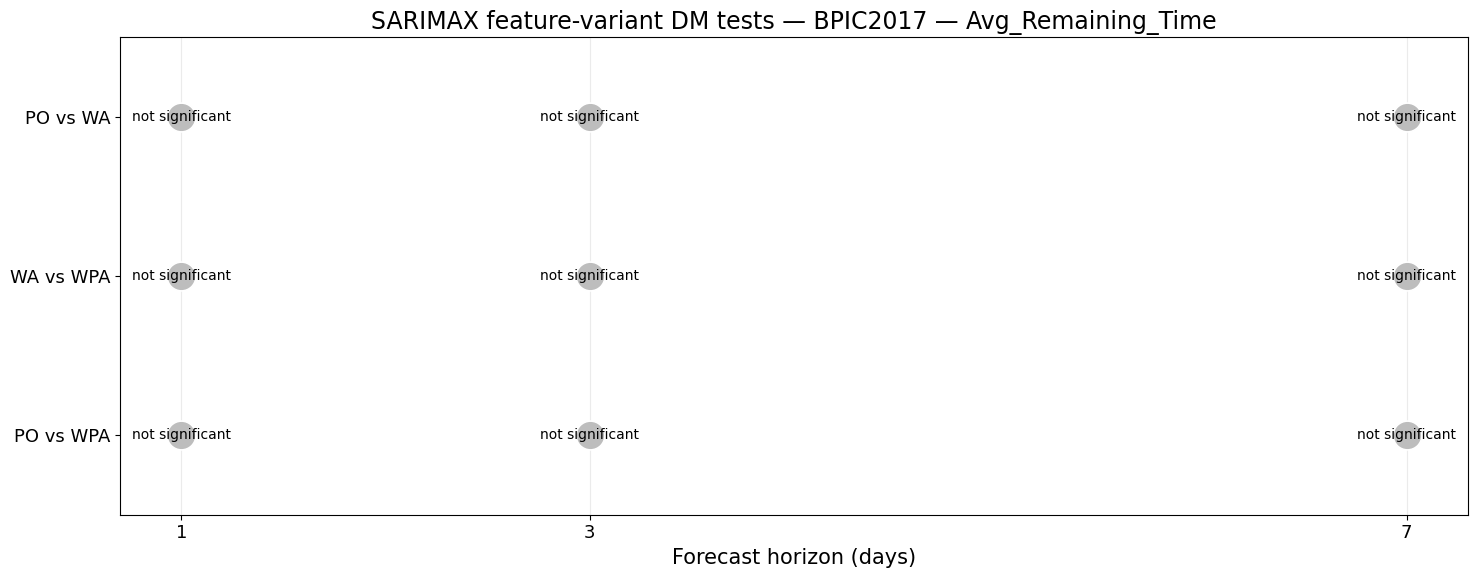

Created /content/BPIC2017_rankings_and_effects.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


Upload the combined results ZIP for BPIC2011.


Saving combined_uploaded_model_results.zip to combined_uploaded_model_results (4).zip


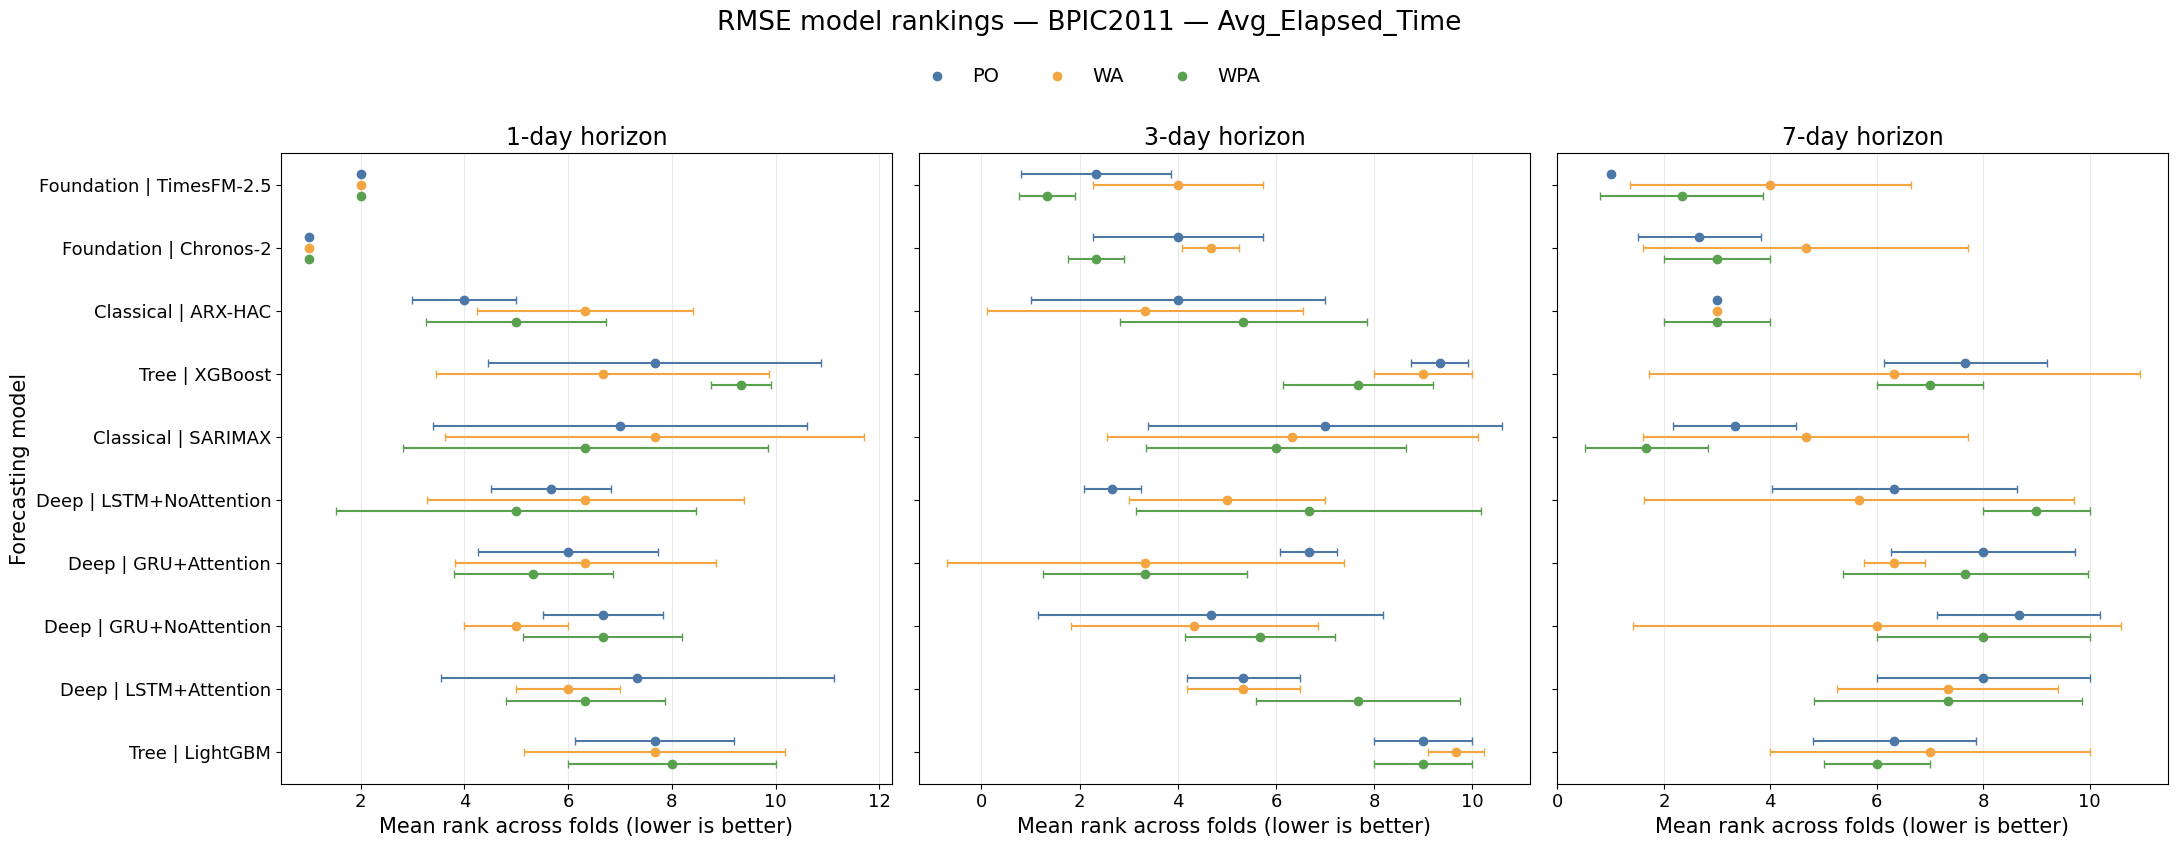

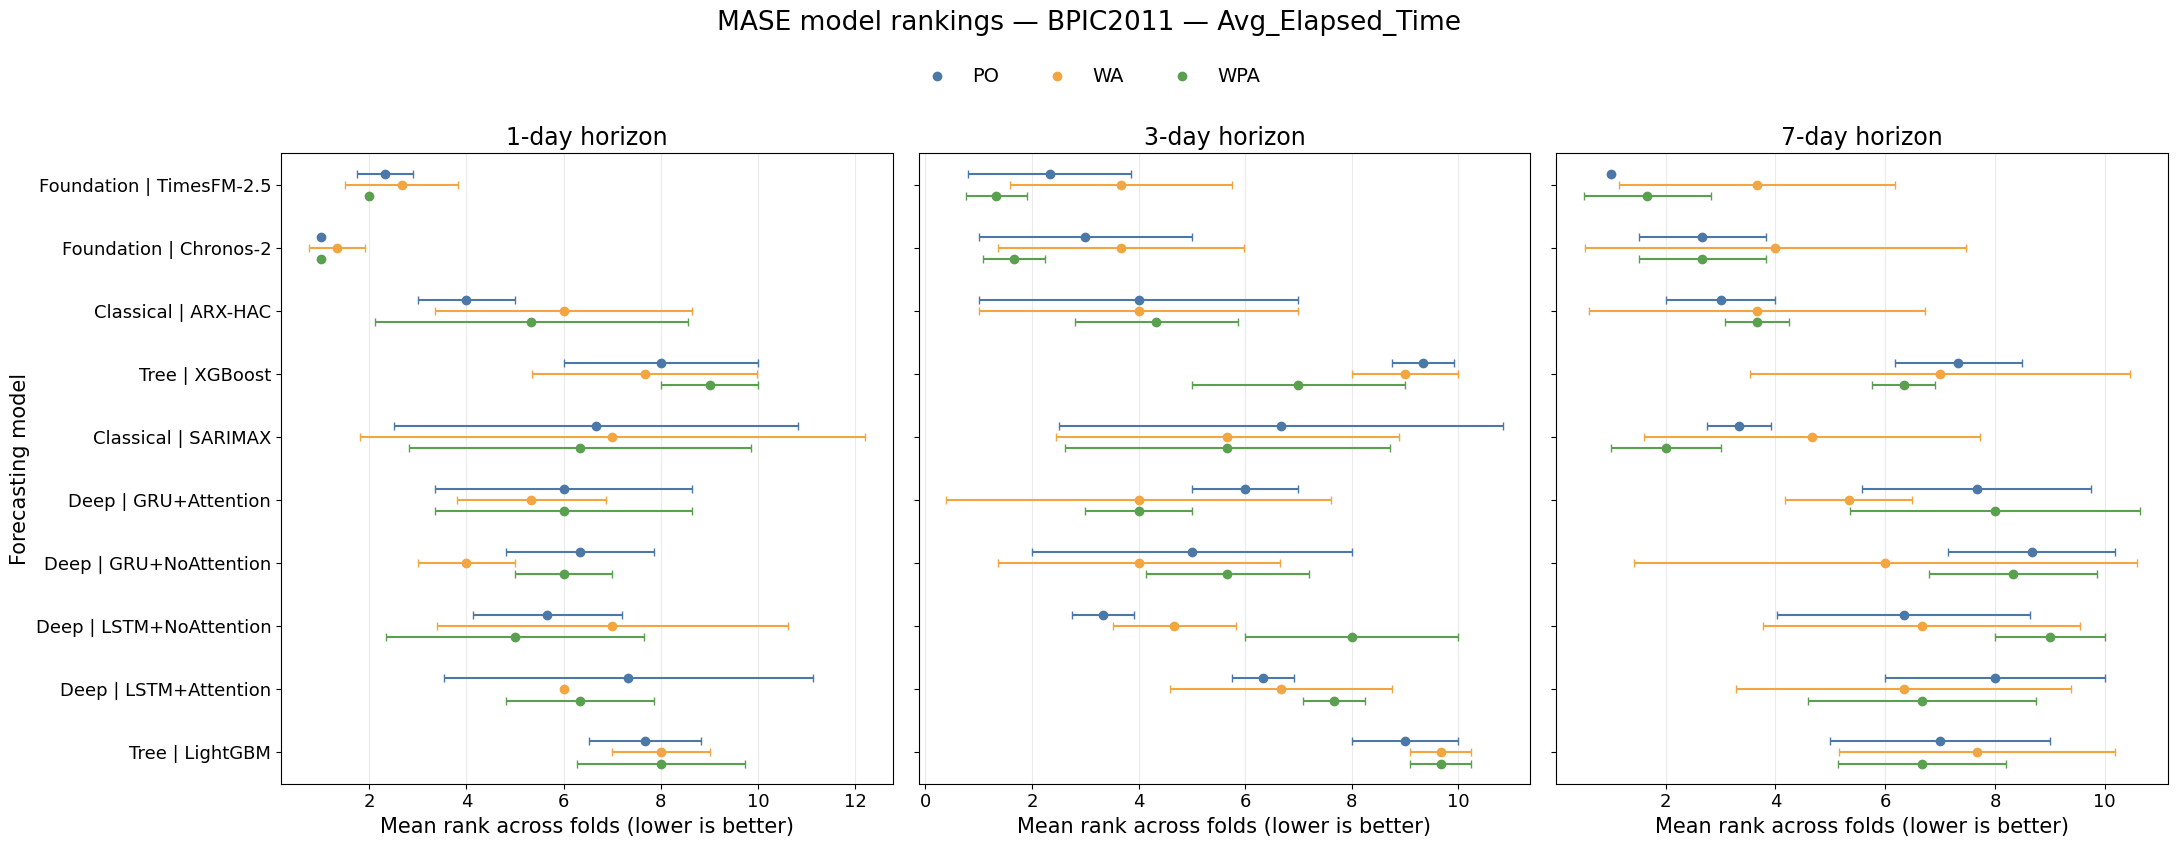

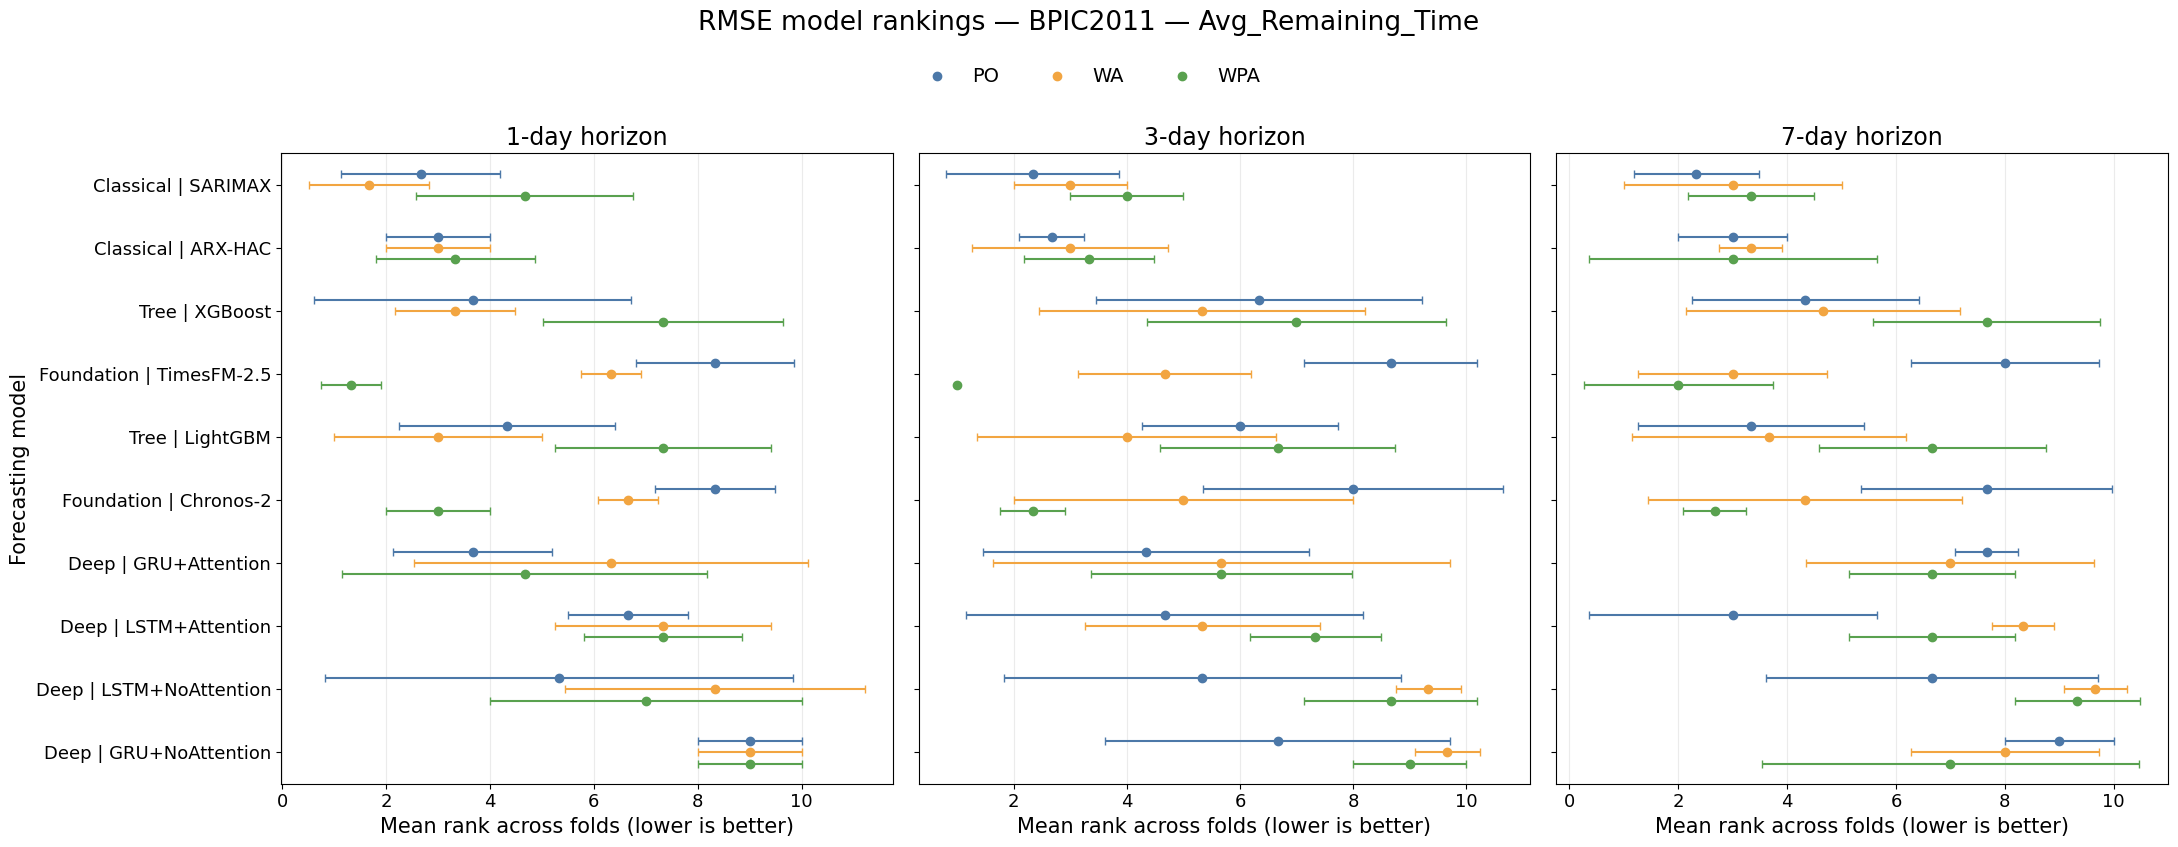

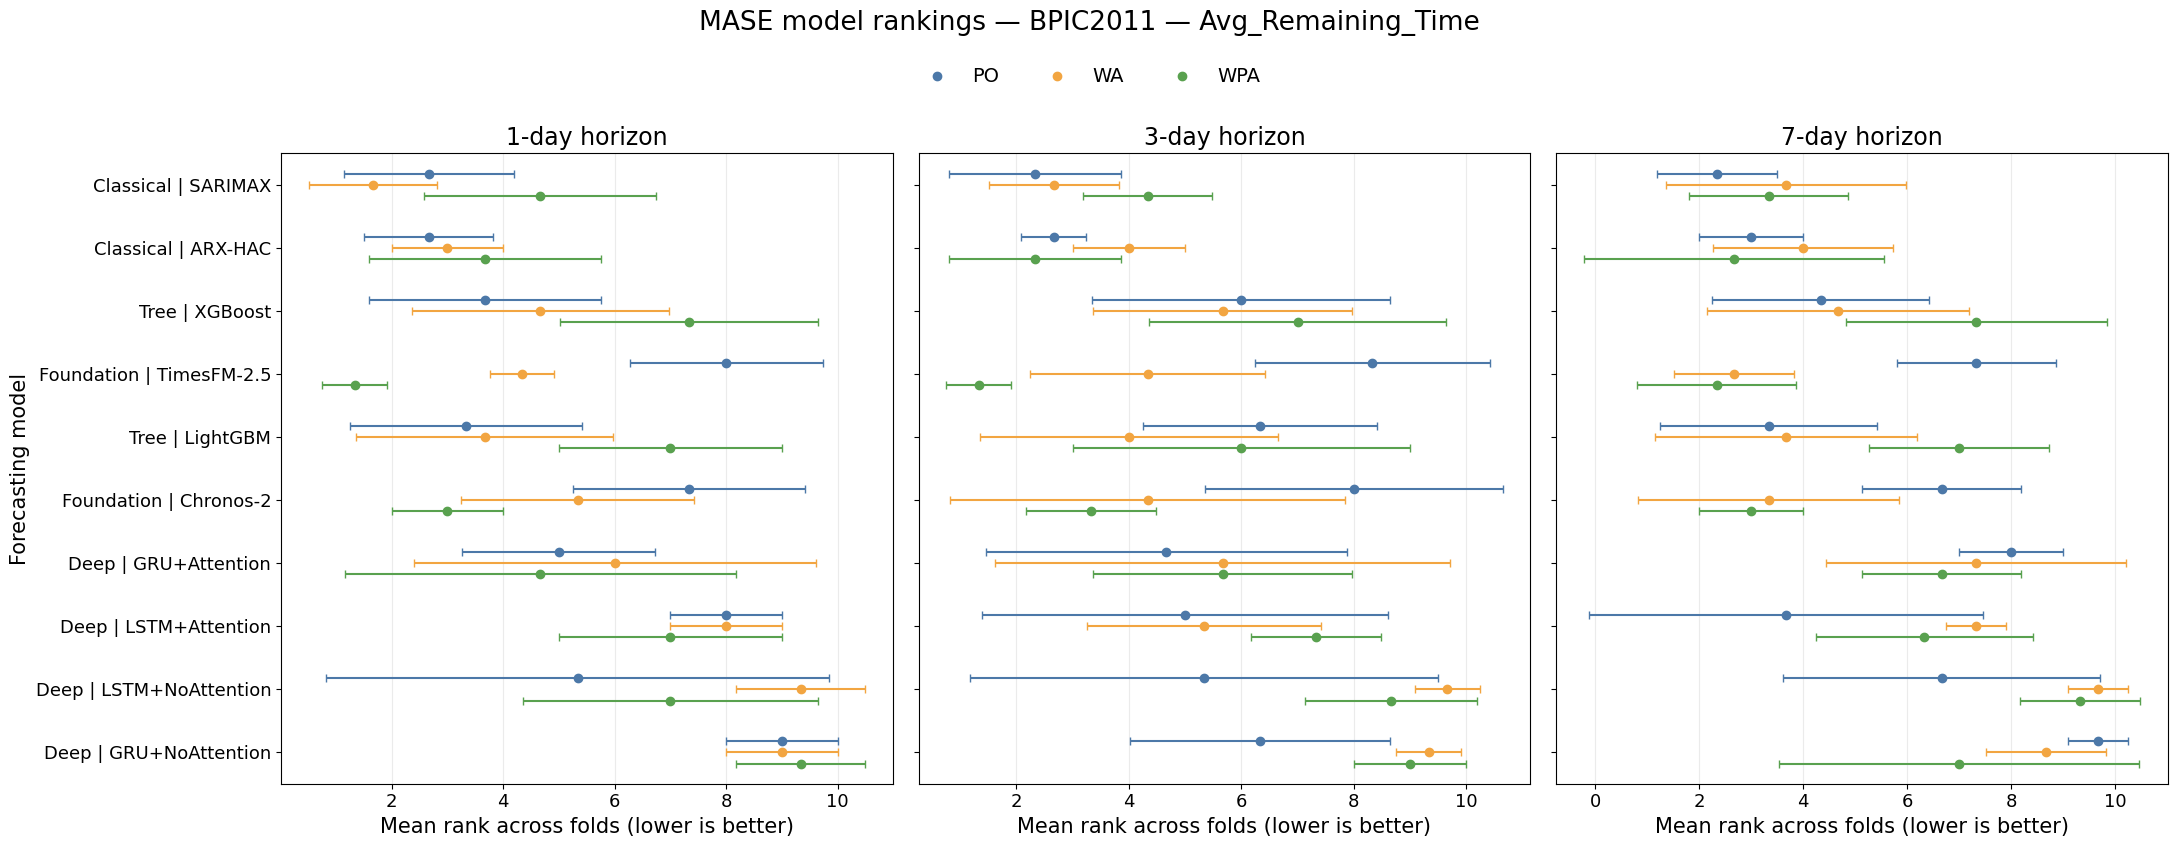

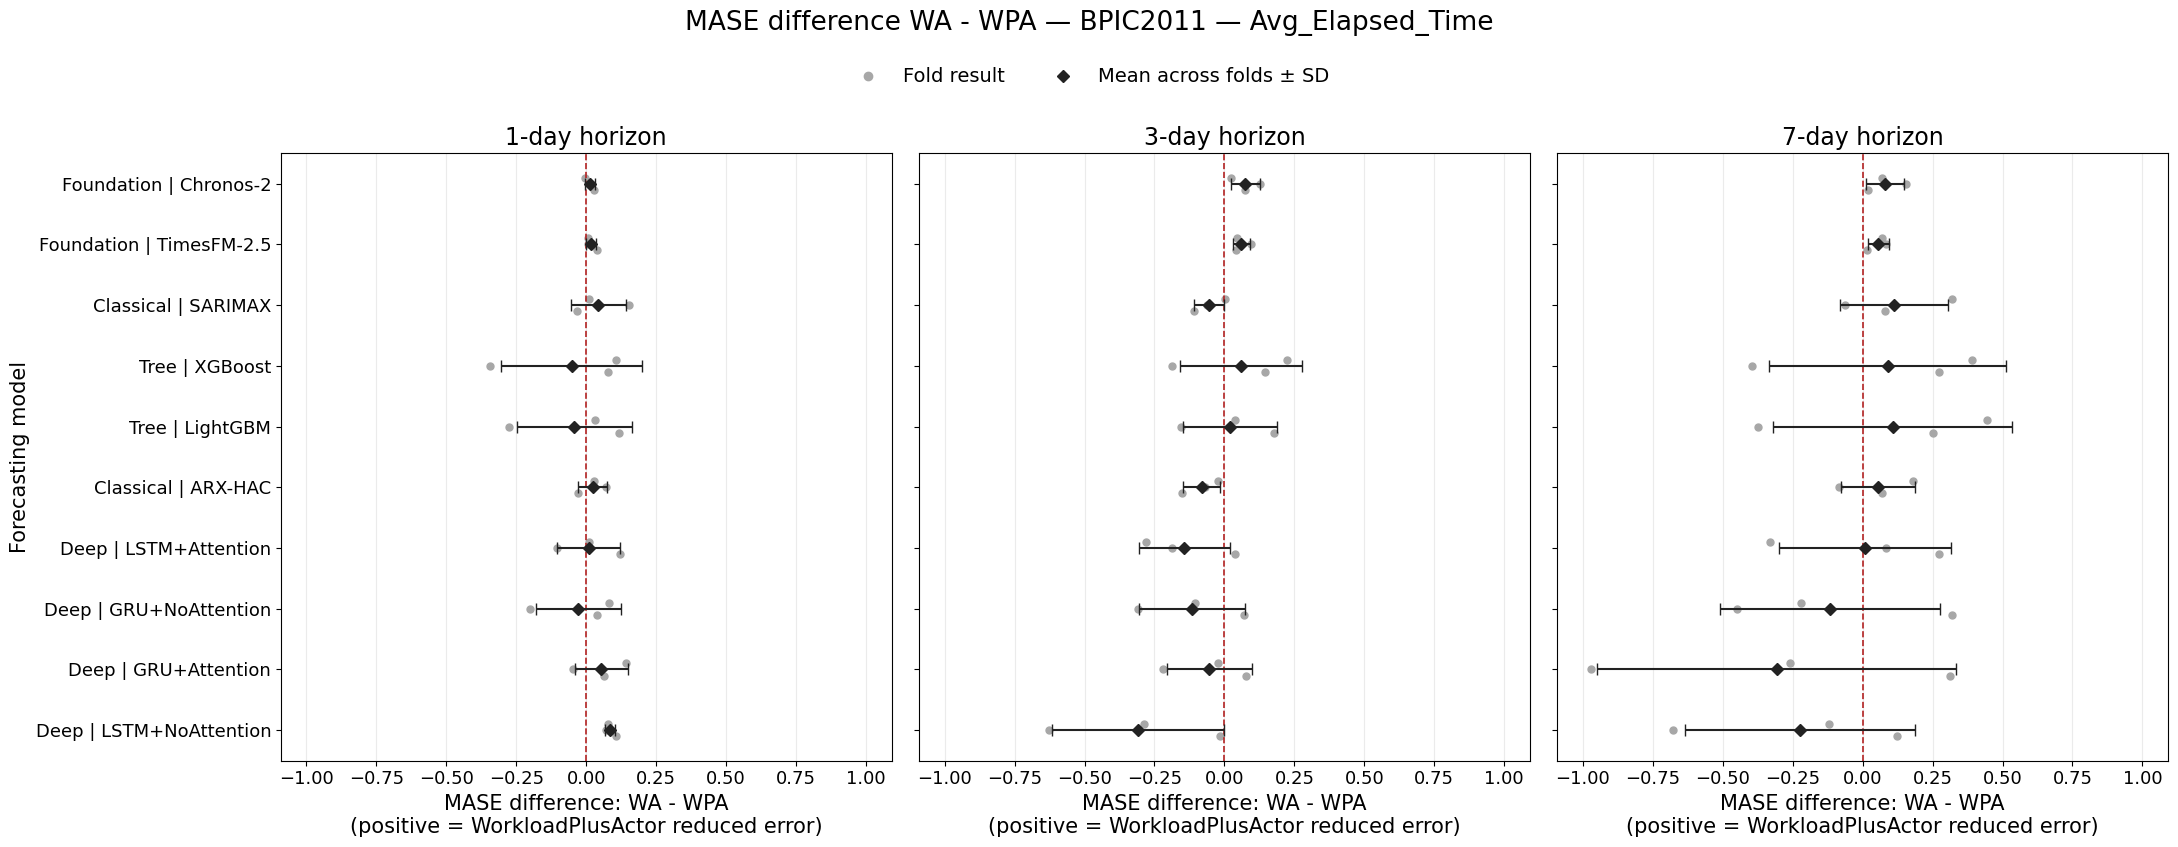

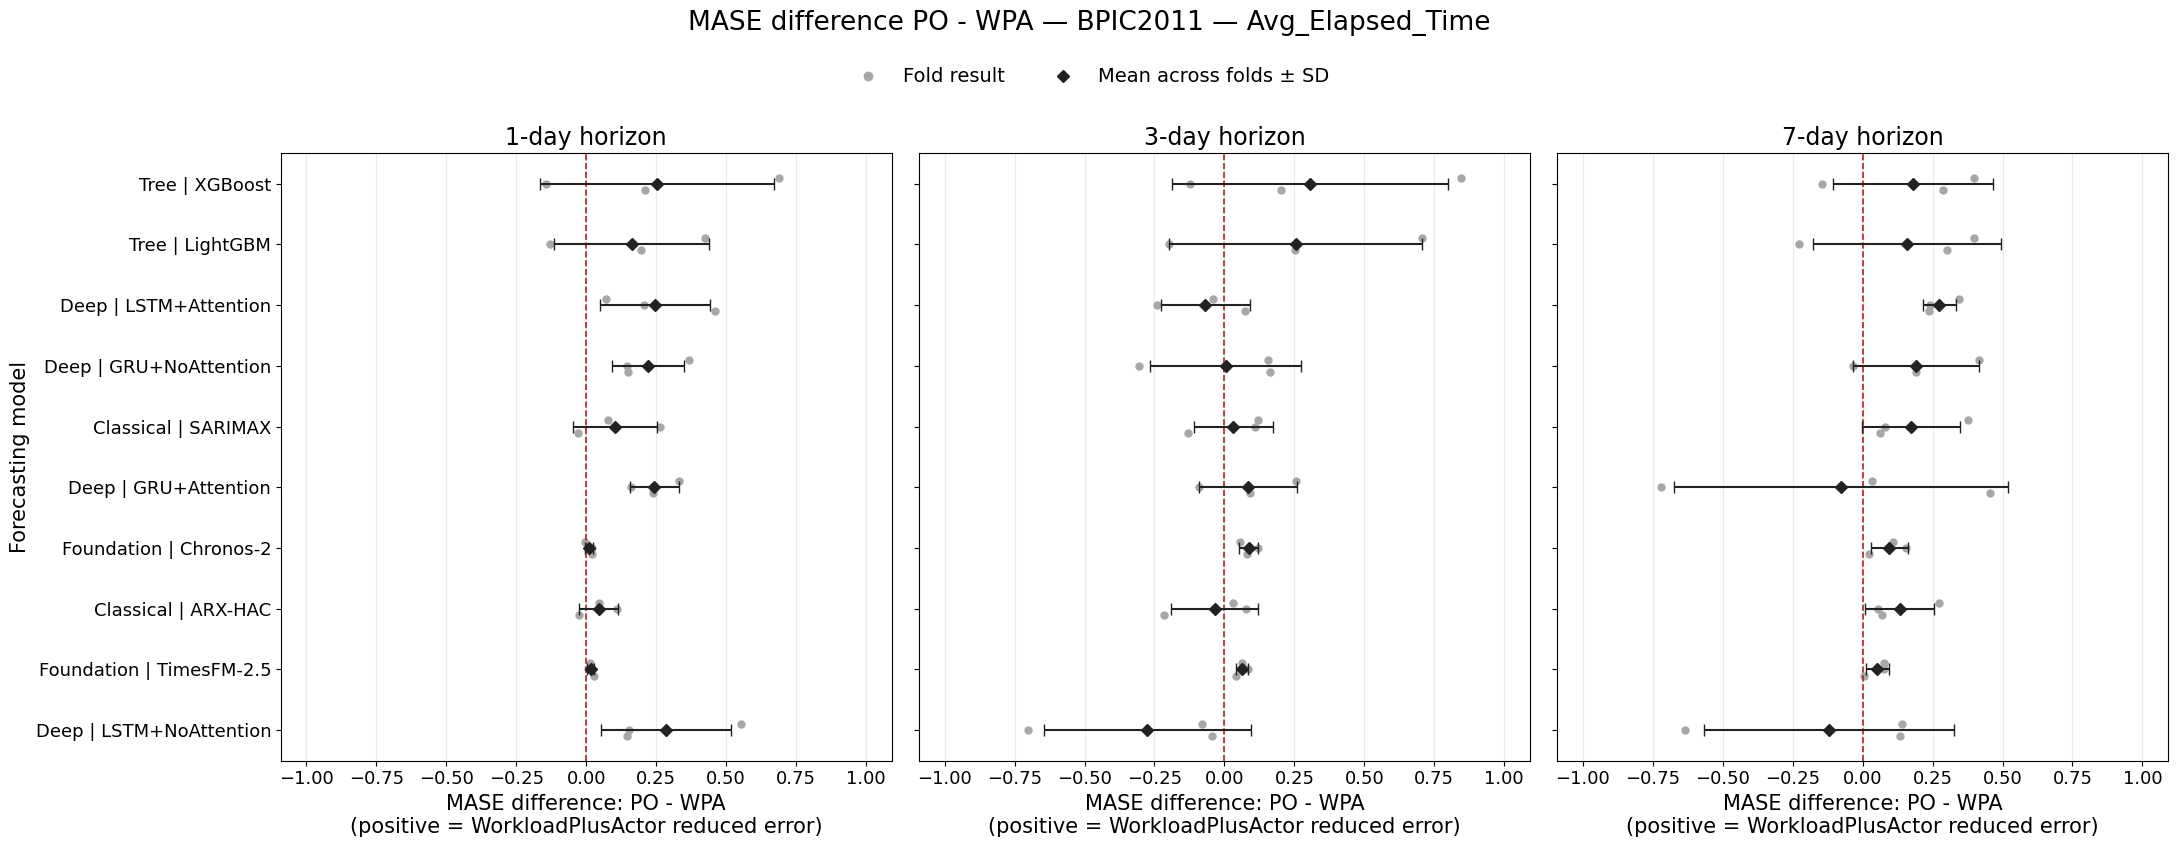

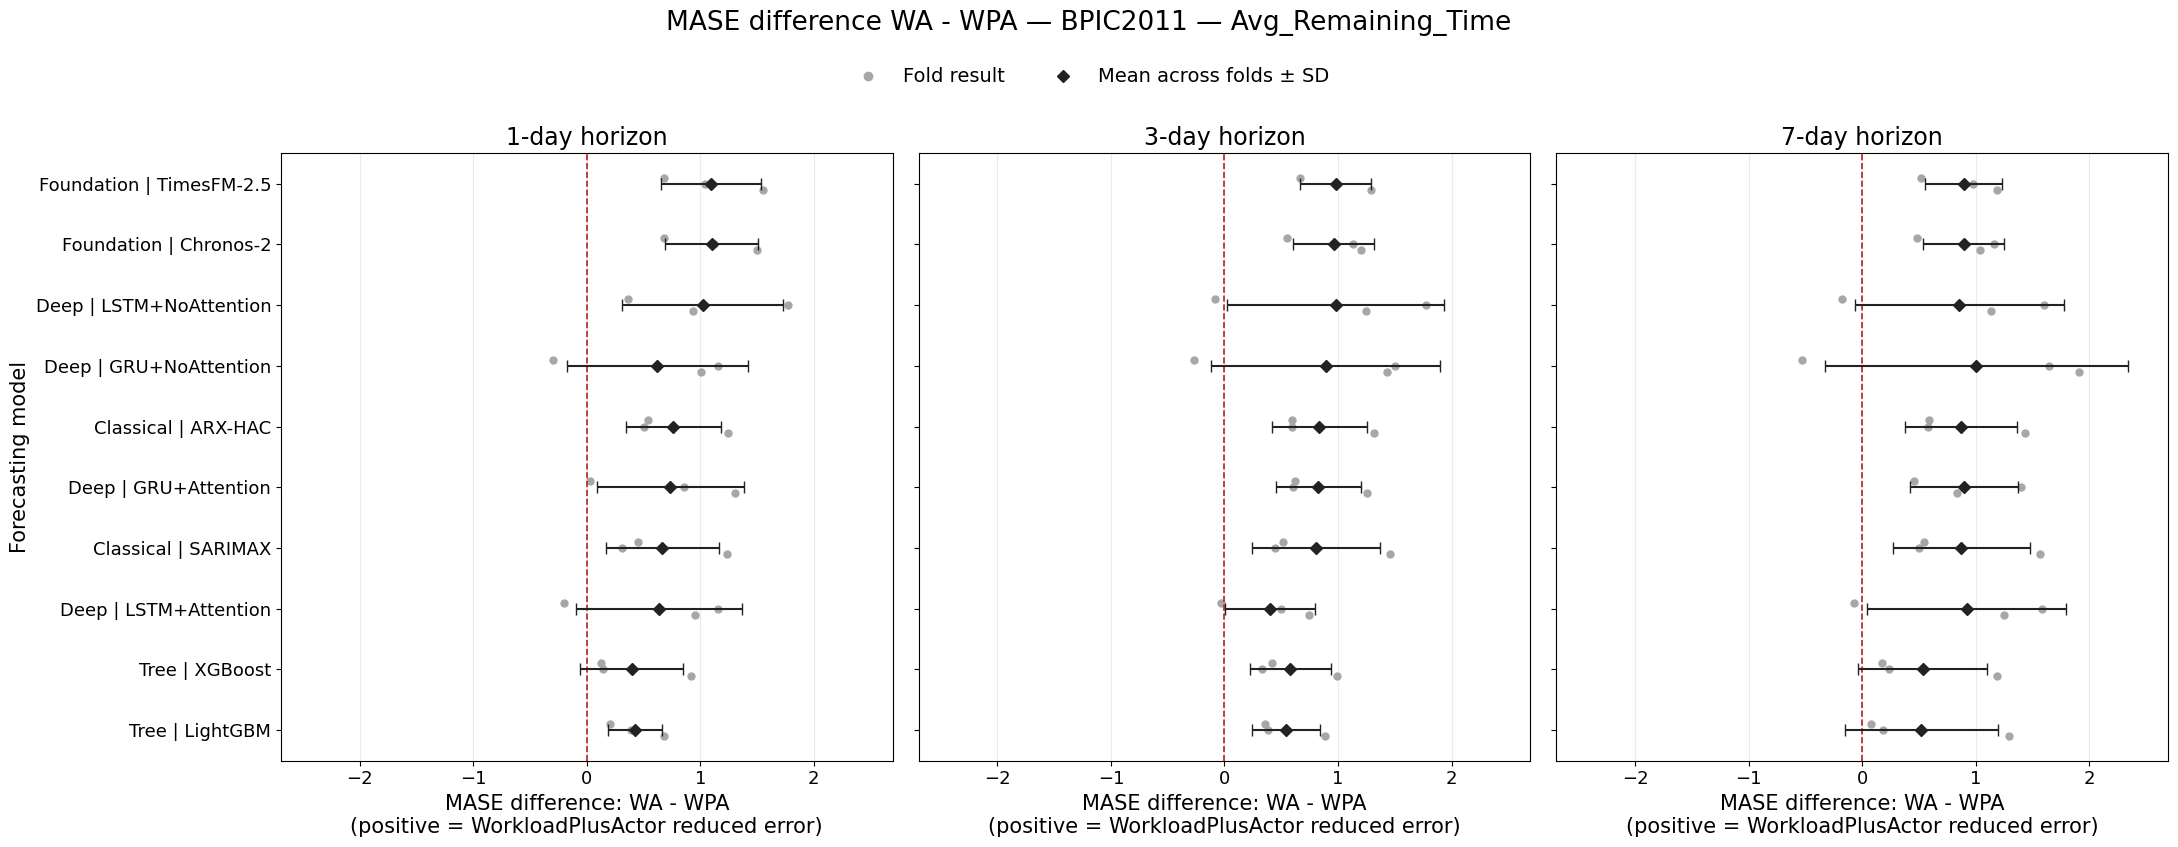

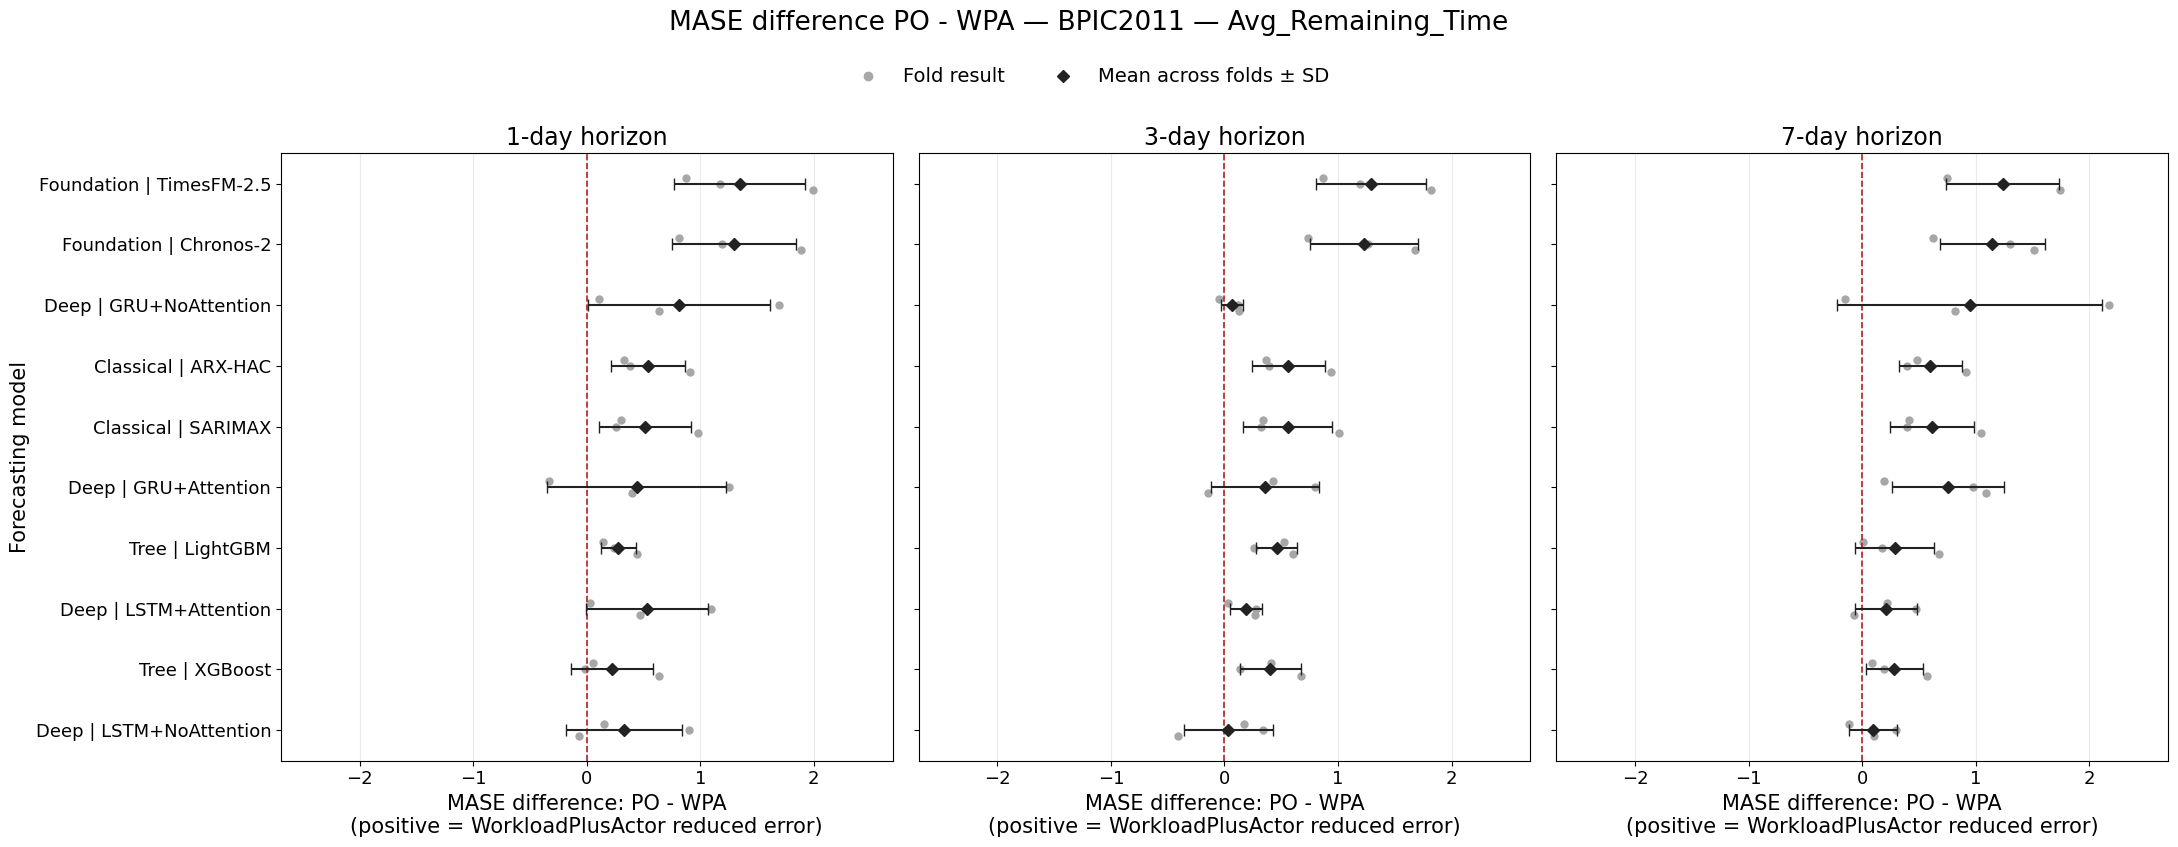

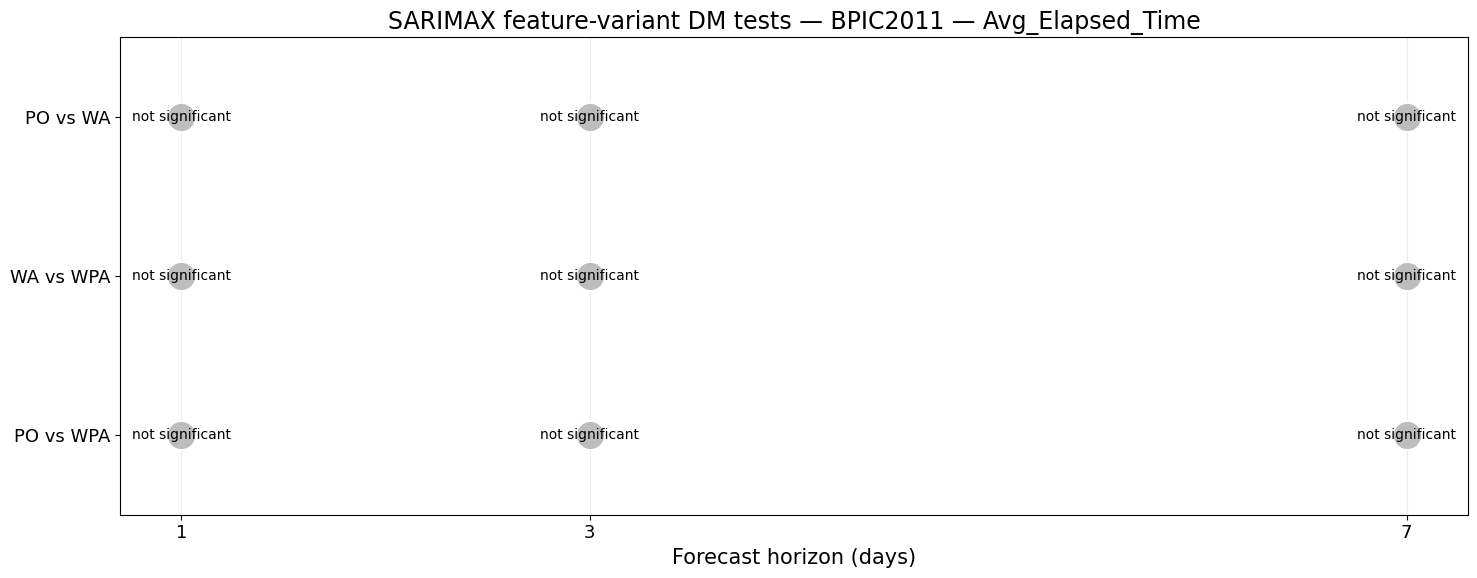

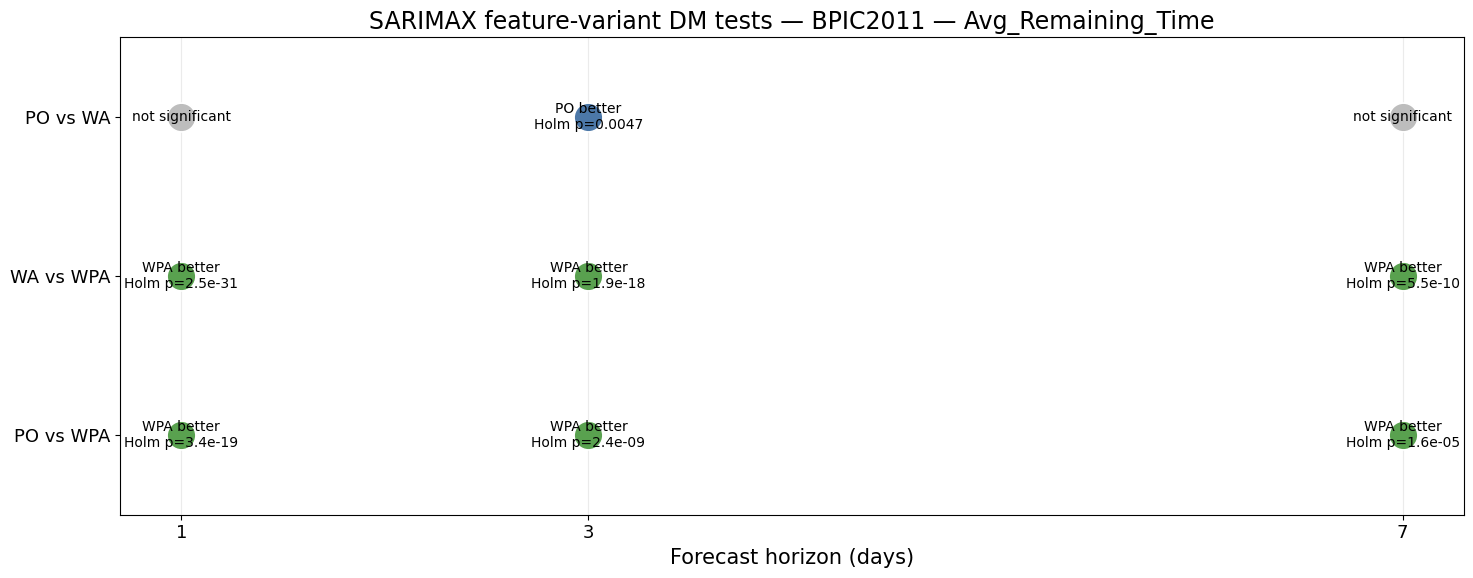

Created /content/BPIC2011_rankings_and_effects.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import io
import re
import zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from google.colab import files


# Larger text throughout the figures
plt.rcParams.update({
    "font.size": 14,
    "axes.titlesize": 17,
    "axes.labelsize": 15,
    "xtick.labelsize": 13,
    "ytick.labelsize": 13,
    "legend.fontsize": 14,
    "figure.titlesize": 19,
})

GROUP_DISPLAY = {
    "Classical": "Classical",
    "Tree": "Tree",
    "DeepLearning": "Deep",
    "FrozenFoundationModel_SupervisedReadout": "Foundation",
}

VARIANT_ORDER = [
    "PerformanceOnly",
    "WorkloadAware",
    "WorkloadPlusActor",
]

VARIANT_ABBREV = {
    "PerformanceOnly": "PO",
    "WorkloadAware": "WA",
    "WorkloadPlusActor": "WPA",
}

VARIANT_COLORS = {
    "PerformanceOnly": "#4C78A8",
    "WorkloadAware": "#F2A541",
    "WorkloadPlusActor": "#59A14F",
}

HORIZONS = [1, 3, 7]


def safe_name(value):
    return re.sub(r"[^A-Za-z0-9._-]+", "_", str(value)).strip("_")


def generate_dataset_figures(zip_bytes, dataset_label):
    # Load the fold metrics and, if present, the DM results from the ZIP.
    with zipfile.ZipFile(io.BytesIO(zip_bytes)) as archive:
        contents = set(archive.namelist())

        metrics_file = "combined_rolling_origin_fold_metrics.csv"
        dm_file = "diebold_mariano_results.csv"

        if metrics_file not in contents:
            raise FileNotFoundError(
                f"{metrics_file} was not found in the uploaded ZIP."
            )

        metrics = pd.read_csv(archive.open(metrics_file))

        if dm_file in contents:
            dm_results = pd.read_csv(archive.open(dm_file))
        else:
            dm_results = pd.DataFrame()

    # The archive may label the data "unknown_dataset"; use the dataset
    # selected in the upload loop instead.
    metrics["dataset_file"] = dataset_label
    if not dm_results.empty:
        dm_results["dataset_file"] = dataset_label

    required = {
        "group", "model", "fold", "target",
        "horizon_days", "variant", "RMSE", "MASE",
    }
    missing = required - set(metrics.columns)
    if missing:
        raise KeyError(
            f"Fold metrics are missing columns: {sorted(missing)}"
        )

    metrics["horizon_days"] = pd.to_numeric(
        metrics["horizon_days"], errors="coerce"
    )
    metrics["RMSE"] = pd.to_numeric(metrics["RMSE"], errors="coerce")
    metrics["MASE"] = pd.to_numeric(metrics["MASE"], errors="coerce")

    metrics = metrics.dropna(
        subset=["group", "model", "fold", "target",
                "horizon_days", "variant"]
    ).drop_duplicates(
        subset=[
            "group", "model", "fold", "target",
            "horizon_days", "variant",
        ],
        keep="last",
    )

    metrics["model_label"] = (
        metrics["group"].map(GROUP_DISPLAY)
        .fillna(metrics["group"].astype(str))
        + " | "
        + metrics["model"].astype(str)
    )

    output_dir = Path(f"/content/{dataset_label}_rankings_and_effects")
    output_dir.mkdir(parents=True, exist_ok=True)

    # -------------------------------------------------------------
    # 1. RMSE and MASE model rankings, with a panel for each horizon
    # -------------------------------------------------------------

    rank_frames = []

    for metric in ["RMSE", "MASE"]:
        usable = metrics.dropna(subset=[metric]).copy()

        # Rank models separately within each fold, target, horizon,
        # and feature variant. Rank 1 is best.
        usable["fold_rank"] = usable.groupby(
            ["target", "horizon_days", "variant", "fold"]
        )[metric].rank(
            method="average",
            ascending=True,
        )

        summary = (
            usable.groupby(
                [
                    "target", "horizon_days", "variant",
                    "group", "model", "model_label",
                ],
                as_index=False,
            )
            .agg(
                average_rank=("fold_rank", "mean"),
                rank_sd=("fold_rank", "std"),
                n_folds=("fold", "nunique"),
            )
        )
        summary["metric"] = metric
        rank_frames.append(summary)

    rank_results = pd.concat(rank_frames, ignore_index=True)
    rank_results.to_csv(output_dir / "model_ranks.csv", index=False)

    for target in metrics["target"].dropna().unique():
        target_results = rank_results[
            rank_results["target"] == target
        ]

        for metric in ["RMSE", "MASE"]:
            plot_data = target_results[
                target_results["metric"] == metric
            ].copy()
            if plot_data.empty:
                continue

            model_order = (
                plot_data.groupby("model_label")["average_rank"]
                .mean()
                .sort_values()
                .index.tolist()
            )
            y_position = {
                model: i for i, model in enumerate(model_order)
            }

            fig, axes = plt.subplots(
                1, 3,
                figsize=(22, max(8, 0.55 * len(model_order))),
                sharey=True,
            )

            offsets = {
                "PerformanceOnly": -0.18,
                "WorkloadAware": 0.0,
                "WorkloadPlusActor": 0.18,
            }

            for ax, horizon in zip(axes, HORIZONS):
                panel = plot_data[
                    plot_data["horizon_days"] == horizon
                ]

                for variant in VARIANT_ORDER:
                    variant_panel = panel[
                        panel["variant"] == variant
                    ]

                    for _, row in variant_panel.iterrows():
                        y = (
                            y_position[row["model_label"]]
                            + offsets[variant]
                        )
                        sd = row["rank_sd"]
                        xerr = 0.0 if pd.isna(sd) else float(sd)

                        ax.errorbar(
                            row["average_rank"],
                            y,
                            xerr=xerr,
                            fmt="o",
                            markersize=6,
                            capsize=3,
                            color=VARIANT_COLORS[variant],
                        )

                ax.set_title(f"{int(horizon)}-day horizon")
                ax.set_xlabel("Mean rank across folds (lower is better)")
                ax.grid(axis="x", alpha=0.25)
                ax.set_ylim(len(model_order) - 0.5, -0.5)

            axes[0].set_yticks(range(len(model_order)))
            axes[0].set_yticklabels(model_order)
            axes[0].set_ylabel("Forecasting model")

            legend_handles = [
                Line2D(
                    [0], [0],
                    marker="o",
                    linestyle="none",
                    color=VARIANT_COLORS[variant],
                    label=VARIANT_ABBREV[variant],
                )
                for variant in VARIANT_ORDER
                if variant in plot_data["variant"].unique()
            ]

            fig.legend(
                handles=legend_handles,
                loc="upper center",
                bbox_to_anchor=(0.5, 1.01),
                ncol=len(legend_handles),
                frameon=False,
            )
            fig.suptitle(
                f"{metric} model rankings — {dataset_label} — {target}",
                y=1.06,
            )
            fig.tight_layout()

            filename = (
                f"{dataset_label}_{safe_name(target)}_"
                f"{metric}_rankings_by_horizon.png"
            )
            fig.savefig(
                output_dir / filename,
                dpi=220,
                bbox_inches="tight",
            )
            plt.show()
            plt.close(fig)

    # -------------------------------------------------------------
    # 2. MASE difference plots for WA - WPA and PO - WPA
    #
    # Positive values mean WPA has lower MASE than the baseline
    # named before the minus sign.
    # -------------------------------------------------------------

    comparisons = [
        ("WorkloadAware", "WorkloadPlusActor", "WA - WPA", "WA_minus_WPA"),
        ("PerformanceOnly", "WorkloadPlusActor", "PO - WPA", "PO_minus_WPA"),
    ]

    effect_keys = [
        "group", "model", "fold", "target", "horizon_days"
    ]
    effect_frames = []

    for baseline, enriched, label, filename_label in comparisons:
        subset = metrics[
            metrics["variant"].isin([baseline, enriched])
        ]

        wide = subset.pivot_table(
            index=effect_keys,
            columns="variant",
            values="MASE",
            aggfunc="first",
        ).reset_index()

        if baseline not in wide.columns or enriched not in wide.columns:
            print(f"Skipping {label}: required variant results are missing.")
            continue

        wide = wide.dropna(subset=[baseline, enriched])
        wide["delta_MASE"] = wide[baseline] - wide[enriched]
        wide["comparison"] = label
        wide["filename_label"] = filename_label
        wide["model_label"] = (
            wide["group"].map(GROUP_DISPLAY)
            .fillna(wide["group"].astype(str))
            + " | "
            + wide["model"].astype(str)
        )
        effect_frames.append(wide)

    if not effect_frames:
        raise ValueError("No paired MASE results were found for WA-WPA or PO-WPA.")

    effects = pd.concat(effect_frames, ignore_index=True)
    effects.to_csv(
        output_dir / "MASE_difference_fold_values.csv",
        index=False,
    )

    effect_summary = (
        effects.groupby(
            [
                "target", "comparison", "filename_label",
                "horizon_days", "group", "model", "model_label",
            ],
            as_index=False,
        )
        .agg(
            mean_delta_MASE=("delta_MASE", "mean"),
            sd_delta_MASE=("delta_MASE", "std"),
            n_folds=("fold", "nunique"),
        )
    )
    effect_summary.to_csv(
        output_dir / "MASE_difference_summary.csv",
        index=False,
    )

    for target in effects["target"].dropna().unique():
        target_effects = effects[effects["target"] == target]
        target_summary = effect_summary[
            effect_summary["target"] == target
        ]

        # Use the same x-axis range for the two contrasts.
        max_extent = 0.0
        for _, row in target_summary.iterrows():
            extent = abs(row["mean_delta_MASE"])
            if pd.notna(row["sd_delta_MASE"]):
                extent += float(row["sd_delta_MASE"])
            max_extent = max(max_extent, extent)
        x_limit = max(max_extent * 1.15, 0.05)

        for baseline, enriched, label, filename_label in comparisons:
            plot_data = target_summary[
                target_summary["comparison"] == label
            ].copy()
            if plot_data.empty:
                continue

            model_order = (
                plot_data.groupby("model_label")["mean_delta_MASE"]
                .mean()
                .sort_values(ascending=False)
                .index.tolist()
            )
            y_position = {
                model: i for i, model in enumerate(model_order)
            }

            fig, axes = plt.subplots(
                1, 3,
                figsize=(22, max(8, 0.55 * len(model_order))),
                sharey=True,
            )

            for ax, horizon in zip(axes, HORIZONS):
                fold_panel = target_effects[
                    (target_effects["comparison"] == label)
                    & (target_effects["horizon_days"] == horizon)
                ]
                mean_panel = plot_data[
                    plot_data["horizon_days"] == horizon
                ]

                # Individual fold results.
                for model in model_order:
                    values = fold_panel.loc[
                        fold_panel["model_label"] == model,
                        "delta_MASE",
                    ].dropna().tolist()

                    jitter = np.linspace(-0.10, 0.10, len(values))
                    for offset, value in zip(jitter, values):
                        ax.plot(
                            value,
                            y_position[model] + offset,
                            "o",
                            color="#A7A7A7",
                            markersize=5,
                            zorder=2,
                        )

                # Mean across folds and fold-to-fold SD.
                for _, row in mean_panel.iterrows():
                    sd = row["sd_delta_MASE"]
                    xerr = 0.0 if pd.isna(sd) else float(sd)

                    ax.errorbar(
                        row["mean_delta_MASE"],
                        y_position[row["model_label"]],
                        xerr=xerr,
                        fmt="D",
                        color="#222222",
                        markersize=6,
                        capsize=4,
                        zorder=3,
                    )

                ax.axvline(
                    0,
                    color="#B22222",
                    linestyle="--",
                    linewidth=1.2,
                )
                ax.set_xlim(-x_limit, x_limit)
                ax.set_title(f"{int(horizon)}-day horizon")
                ax.set_xlabel(
                    f"MASE difference: {label}\n"
                    f"(positive = {enriched} reduced error)"
                )
                ax.grid(axis="x", alpha=0.25)
                ax.set_ylim(len(model_order) - 0.5, -0.5)

            axes[0].set_yticks(range(len(model_order)))
            axes[0].set_yticklabels(model_order)
            axes[0].set_ylabel("Forecasting model")

            fig.legend(
                handles=[
                    Line2D(
                        [0], [0],
                        marker="o",
                        linestyle="none",
                        color="#A7A7A7",
                        label="Fold result",
                    ),
                    Line2D(
                        [0], [0],
                        marker="D",
                        linestyle="none",
                        color="#222222",
                        label="Mean across folds ± SD",
                    ),
                ],
                loc="upper center",
                bbox_to_anchor=(0.5, 1.01),
                ncol=2,
                frameon=False,
            )
            fig.suptitle(
                f"MASE difference {label} — {dataset_label} — {target}",
                y=1.06,
            )
            fig.tight_layout()

            filename = (
                f"{dataset_label}_{safe_name(target)}_"
                f"{filename_label}_MASE_by_horizon.png"
            )
            fig.savefig(
                output_dir / filename,
                dpi=220,
                bbox_inches="tight",
            )
            plt.show()
            plt.close(fig)

    # -------------------------------------------------------------
    # 3. DM summaries for the primary SARIMAX comparisons
    # -------------------------------------------------------------

    if not dm_results.empty:
        required_dm = {
            "comparison_family", "comparison", "target", "horizon_days",
            "p_value_holm", "RMSE_difference_a_minus_b",
        }

        if required_dm.issubset(dm_results.columns):
            dm = dm_results[
                dm_results["comparison_family"]
                == "primary_SARIMAX_feature_variants"
            ].copy()

            dm_labels = {
                "PerformanceOnly_vs_WorkloadAware": "PO vs WA",
                "WorkloadAware_vs_WorkloadPlusActor": "WA vs WPA",
                "PerformanceOnly_vs_WorkloadPlusActor": "PO vs WPA",
            }

            for target in dm["target"].dropna().unique():
                panel = dm[dm["target"] == target].copy()
                comparisons_present = [
                    comparison for comparison in dm_labels
                    if comparison in panel["comparison"].unique()
                ]
                y_position = {
                    comparison: i
                    for i, comparison in enumerate(comparisons_present)
                }

                fig, ax = plt.subplots(
                    figsize=(15, max(6, 1.0 * len(comparisons_present)))
                )

                for _, row in panel.iterrows():
                    comparison = row["comparison"]
                    if comparison not in y_position:
                        continue

                    p_value = pd.to_numeric(
                        row["p_value_holm"], errors="coerce"
                    )
                    difference = pd.to_numeric(
                        row["RMSE_difference_a_minus_b"], errors="coerce"
                    )

                    if pd.isna(p_value) or p_value >= 0.05:
                        cell_text = "not significant"
                        color = "#BDBDBD"
                    else:
                        a, b = comparison.split("_vs_")
                        better = b if difference > 0 else a
                        cell_text = (
                            f"{VARIANT_ABBREV.get(better, better)} better\n"
                            f"Holm p={p_value:.2g}"
                        )
                        color = VARIANT_COLORS.get(better, "#777777")

                    x = int(row["horizon_days"])
                    y = y_position[comparison]
                    ax.scatter(
                        x, y, s=430,
                        color=color,
                        edgecolor="white",
                        linewidth=1.2,
                        zorder=2,
                    )
                    ax.text(
                        x, y, cell_text,
                        ha="center",
                        va="center",
                        fontsize=10,
                        zorder=3,
                    )

                ax.set_xticks(HORIZONS)
                ax.set_xlabel("Forecast horizon (days)")
                ax.set_yticks(range(len(comparisons_present)))
                ax.set_yticklabels(
                    [dm_labels[c] for c in comparisons_present]
                )
                ax.set_ylim(len(comparisons_present) - 0.5, -0.5)
                ax.set_title(
                    f"SARIMAX feature-variant DM tests — "
                    f"{dataset_label} — {target}"
                )
                ax.grid(axis="x", alpha=0.25)
                fig.tight_layout()

                filename = (
                    f"{dataset_label}_{safe_name(target)}_"
                    "SARIMAX_DM_summary.png"
                )
                fig.savefig(
                    output_dir / filename,
                    dpi=220,
                    bbox_inches="tight",
                )
                plt.show()
                plt.close(fig)

    # Bundle this dataset's figures and CSV summaries, then download.
    output_zip = Path(f"/content/{dataset_label}_rankings_and_effects.zip")

    with zipfile.ZipFile(output_zip, "w", zipfile.ZIP_DEFLATED) as archive:
        for path in output_dir.rglob("*"):
            if path.is_file():
                archive.write(path, arcname=path.relative_to(output_dir))

    print(f"Created {output_zip}")
    files.download(str(output_zip))


# ---------------------------------------------------------------------
# Run all three datasets. At each prompt, upload that dataset's
# combined_uploaded_model_results.zip.
# ---------------------------------------------------------------------

for dataset_label in ["BPIC2012", "BPIC2017", "BPIC2011"]:
    print(f"\nUpload the combined results ZIP for {dataset_label}.")
    uploaded = files.upload()

    zip_names = [
        name for name in uploaded
        if name.lower().endswith(".zip")
    ]
    if len(zip_names) != 1:
        raise ValueError(
            f"Upload exactly one ZIP for {dataset_label} at this prompt."
        )

    uploaded_zip_name = zip_names[0]
    generate_dataset_figures(
        uploaded[uploaded_zip_name],
        dataset_label,
    )


Upload the combined model-results ZIP for BPIC2012.


Saving combined_uploaded_model_results.zip to combined_uploaded_model_results (5).zip

Upload the combined model-results ZIP for BPIC2017.


Saving combined_uploaded_model_results.zip to combined_uploaded_model_results (6).zip

Upload the combined model-results ZIP for BPIC2011.


Saving combined_uploaded_model_results.zip to combined_uploaded_model_results (7).zip
Dataset-fold observations per model/target/horizon/comparison:
n_dataset_folds
9    120
Name: count, dtype: int64


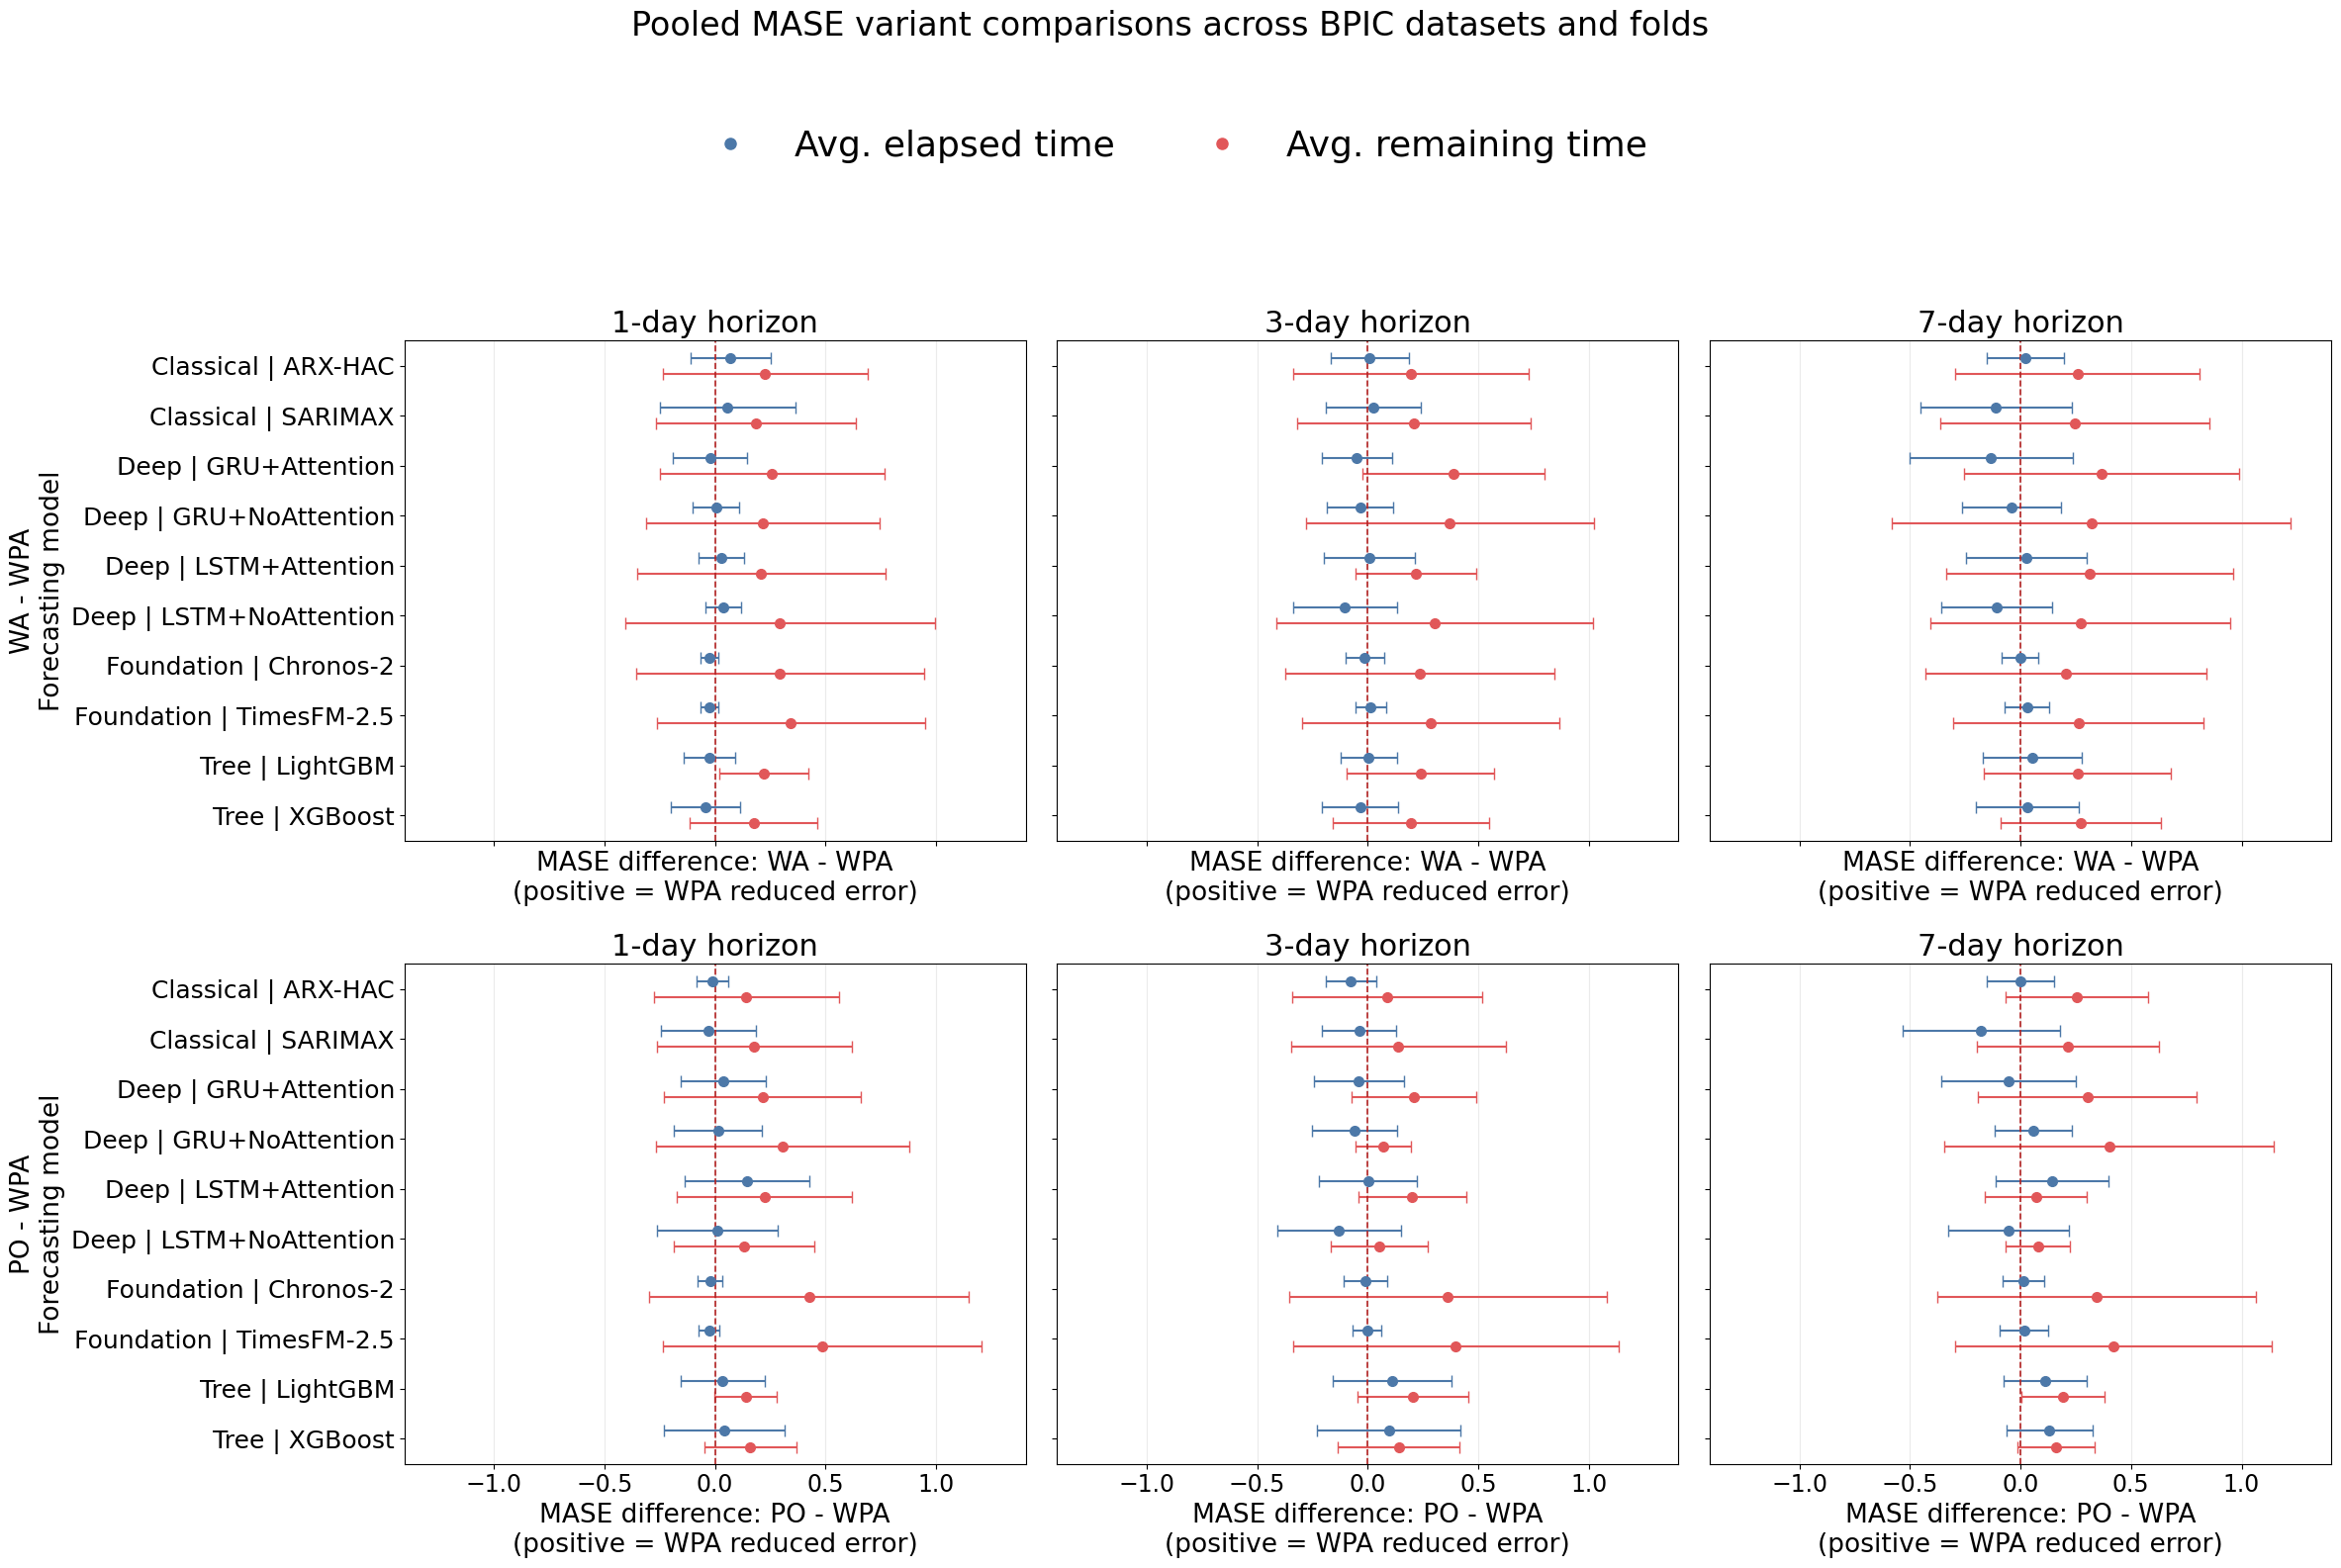

Created: /content/pooled_MASE_differences_all_datasets.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import io
import zipfile
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from google.colab import files


# =============================================================
# FONT SIZES — change these numbers to adjust the text
# =============================================================

plt.rcParams.update({
    "font.size": 18,
    "axes.titlesize": 22,
    "axes.labelsize": 19,
    "xtick.labelsize": 17,
    "ytick.labelsize": 18,
    "legend.fontsize": 18,
    "legend.title_fontsize": 19,
    "figure.titlesize": 24,
})

DATASETS = ["BPIC2012", "BPIC2017", "BPIC2011"]
HORIZONS = [1, 3, 7]

GROUP_DISPLAY = {
    "Classical": "Classical",
    "Tree": "Tree",
    "DeepLearning": "Deep",
    "FrozenFoundationModel_SupervisedReadout": "Foundation",
}

TARGET_ORDER = ["Avg_Elapsed_Time", "Avg_Remaining_Time"]

TARGET_LABELS = {
    "Avg_Elapsed_Time": "Avg. elapsed time",
    "Avg_Remaining_Time": "Avg. remaining time",
}

TARGET_COLORS = {
    "Avg_Elapsed_Time": "#4C78A8",
    "Avg_Remaining_Time": "#E15759",
}

COMPARISONS = [
    ("WorkloadAware", "WorkloadPlusActor", "WA - WPA"),
    ("PerformanceOnly", "WorkloadPlusActor", "PO - WPA"),
]


# =============================================================
# UPLOAD THE THREE DATASET ARCHIVES
# =============================================================

metric_frames = []

for dataset_label in DATASETS:
    print(f"\nUpload the combined model-results ZIP for {dataset_label}.")
    uploaded = files.upload()

    zip_names = [
        name for name in uploaded
        if name.lower().endswith(".zip")
    ]

    if len(zip_names) != 1:
        raise ValueError(
            f"Upload exactly one ZIP for {dataset_label} at this prompt."
        )

    with zipfile.ZipFile(io.BytesIO(uploaded[zip_names[0]])) as archive:
        metrics_file = "combined_rolling_origin_fold_metrics.csv"

        if metrics_file not in archive.namelist():
            raise FileNotFoundError(
                f"{metrics_file} was not found in {zip_names[0]}."
            )

        dataset_metrics = pd.read_csv(archive.open(metrics_file))

    dataset_metrics["dataset"] = dataset_label
    metric_frames.append(dataset_metrics)

all_metrics = pd.concat(metric_frames, ignore_index=True)

required = {
    "dataset", "group", "model", "fold", "target",
    "horizon_days", "variant", "MASE",
}

missing = required - set(all_metrics.columns)

if missing:
    raise KeyError(f"Metric data is missing columns: {sorted(missing)}")

all_metrics["horizon_days"] = pd.to_numeric(
    all_metrics["horizon_days"], errors="coerce"
)

all_metrics["MASE"] = pd.to_numeric(
    all_metrics["MASE"], errors="coerce"
)

all_metrics = all_metrics.dropna(
    subset=[
        "dataset", "group", "model", "fold",
        "target", "horizon_days", "variant",
    ]
).drop_duplicates(
    subset=[
        "dataset", "group", "model", "fold",
        "target", "horizon_days", "variant",
    ],
    keep="last",
)


# =============================================================
# PAIRED DIFFERENCES WITHIN EACH DATASET AND FOLD
# Positive difference means WPA has lower MASE.
# =============================================================

pair_keys = [
    "dataset", "group", "model", "fold", "target", "horizon_days"
]

effect_frames = []

for baseline, enriched, comparison_label in COMPARISONS:
    subset = all_metrics[
        all_metrics["variant"].isin([baseline, enriched])
    ]

    wide = subset.pivot_table(
        index=pair_keys,
        columns="variant",
        values="MASE",
        aggfunc="first",
    ).reset_index()

    if baseline not in wide.columns or enriched not in wide.columns:
        print(f"Skipping {comparison_label}: variants are missing.")
        continue

    wide = wide.dropna(subset=[baseline, enriched])
    wide["delta_MASE"] = wide[baseline] - wide[enriched]
    wide["comparison"] = comparison_label

    wide["model_label"] = (
        wide["group"].map(GROUP_DISPLAY)
        .fillna(wide["group"].astype(str))
        + " | "
        + wide["model"].astype(str)
    )

    effect_frames.append(wide)

if not effect_frames:
    raise ValueError(
        "No paired MASE results were found for WA-WPA or PO-WPA."
    )

paired = pd.concat(effect_frames, ignore_index=True)

pooled_summary = (
    paired.groupby(
        [
            "comparison", "target", "horizon_days",
            "group", "model", "model_label",
        ],
        as_index=False,
    )
    .agg(
        mean_delta_MASE=("delta_MASE", "mean"),
        sd_delta_MASE=("delta_MASE", "std"),
        n_dataset_folds=("delta_MASE", "count"),
        n_datasets=("dataset", "nunique"),
    )
)

print("Dataset-fold observations per model/target/horizon/comparison:")
print(pooled_summary["n_dataset_folds"].value_counts().sort_index())

paired.to_csv(
    "/content/pooled_MASE_difference_dataset_fold_values.csv",
    index=False,
)

pooled_summary.to_csv(
    "/content/pooled_MASE_difference_summary.csv",
    index=False,
)


# =============================================================
# POOLED FIGURE
# Rows: comparisons
# Columns: horizons
# Colours: targets
# =============================================================

model_order = sorted(pooled_summary["model_label"].unique())
y_position = {model: i for i, model in enumerate(model_order)}

max_extent = 0.0

for _, row in pooled_summary.iterrows():
    extent = abs(row["mean_delta_MASE"])

    if pd.notna(row["sd_delta_MASE"]):
        extent += float(row["sd_delta_MASE"])

    max_extent = max(max_extent, extent)

x_limit = max(max_extent * 1.15, 0.05)

fig, axes = plt.subplots(
    2, 3,
    figsize=(24, max(16, 1.3 * len(model_order))),
    sharex=True,
    sharey=True,
)

for row_index, (_, _, comparison_label) in enumerate(COMPARISONS):
    for col_index, horizon in enumerate(HORIZONS):
        ax = axes[row_index, col_index]

        panel = pooled_summary[
            (pooled_summary["comparison"] == comparison_label)
            & (pooled_summary["horizon_days"] == horizon)
        ]

        for target_index, target in enumerate(TARGET_ORDER):
            target_panel = panel[panel["target"] == target]
            offset = -0.16 if target_index == 0 else 0.16

            for _, result in target_panel.iterrows():
                sd = result["sd_delta_MASE"]
                xerr = 0.0 if pd.isna(sd) else float(sd)

                ax.errorbar(
                    result["mean_delta_MASE"],
                    y_position[result["model_label"]] + offset,
                    xerr=xerr,
                    fmt="o",
                    markersize=7,
                    capsize=4,
                    color=TARGET_COLORS[target],
                )

        ax.axvline(
            0,
            color="#B22222",
            linestyle="--",
            linewidth=1.2,
        )

        ax.set_xlim(-x_limit, x_limit)
        ax.set_title(f"{horizon}-day horizon")

        ax.set_xlabel(
            f"MASE difference: {comparison_label}\n"
            "(positive = WPA reduced error)"
        )

        ax.tick_params(axis="x", labelsize=17)
        ax.tick_params(axis="y", labelsize=18)
        ax.grid(axis="x", alpha=0.25)
        ax.set_ylim(len(model_order) - 0.5, -0.5)

for row_index, (_, _, comparison_label) in enumerate(COMPARISONS):
    axes[row_index, 0].set_yticks(range(len(model_order)))
    axes[row_index, 0].set_yticklabels(
        model_order,
        fontsize=18,
    )

    axes[row_index, 0].set_ylabel(
        f"{comparison_label}\nForecasting model"
    )

legend_handles = [
    Line2D(
        [0], [0],
        marker="o",
        linestyle="none",
        color=TARGET_COLORS[target],
        label=TARGET_LABELS[target],
        markersize=8,
    )
    for target in TARGET_ORDER
    if target in pooled_summary["target"].unique()
]

fig.suptitle(
    "Pooled MASE variant comparisons across BPIC datasets and folds",
    fontsize=24,
    y=0.995,
)

fig.legend(
    handles=legend_handles,
    loc="upper center",
    bbox_to_anchor=(0.5, 0.94),
    ncol=len(legend_handles),
    fontsize=26,
    frameon=False,
)

fig.tight_layout(rect=[0, 0, 1, 0.86])

figure_path = Path(
    "/content/pooled_MASE_differences_all_datasets.png"
)

fig.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight",
)

plt.show()
plt.close(fig)


# =============================================================
# DOWNLOAD FIGURE AND UNDERLYING DATA
# =============================================================

output_zip = Path(
    "/content/pooled_MASE_differences_all_datasets.zip"
)

with zipfile.ZipFile(
    output_zip, "w", zipfile.ZIP_DEFLATED
) as archive:
    archive.write(figure_path, arcname=figure_path.name)

    archive.write(
        "/content/pooled_MASE_difference_summary.csv",
        arcname="pooled_MASE_difference_summary.csv",
    )

    archive.write(
        "/content/pooled_MASE_difference_dataset_fold_values.csv",
        arcname="pooled_MASE_difference_dataset_fold_values.csv",
    )

print(f"Created: {output_zip}")
files.download(str(output_zip))


Upload the combined results ZIP for BPIC2012.


Saving combined_uploaded_model_results.zip to combined_uploaded_model_results (8).zip
Loaded combined_uploaded_model_results (8).zip as BPIC2012.

Upload the combined results ZIP for BPIC2017.


Saving combined_uploaded_model_results.zip to combined_uploaded_model_results (9).zip
Loaded combined_uploaded_model_results (9).zip as BPIC2017.

Upload the combined results ZIP for BPIC2011.


Saving combined_uploaded_model_results.zip to combined_uploaded_model_results (10).zip
Loaded combined_uploaded_model_results (10).zip as BPIC2011.

Folds found per dataset:
dataset
BPIC2011    3
BPIC2012    3
BPIC2017    3
Name: fold, dtype: int64


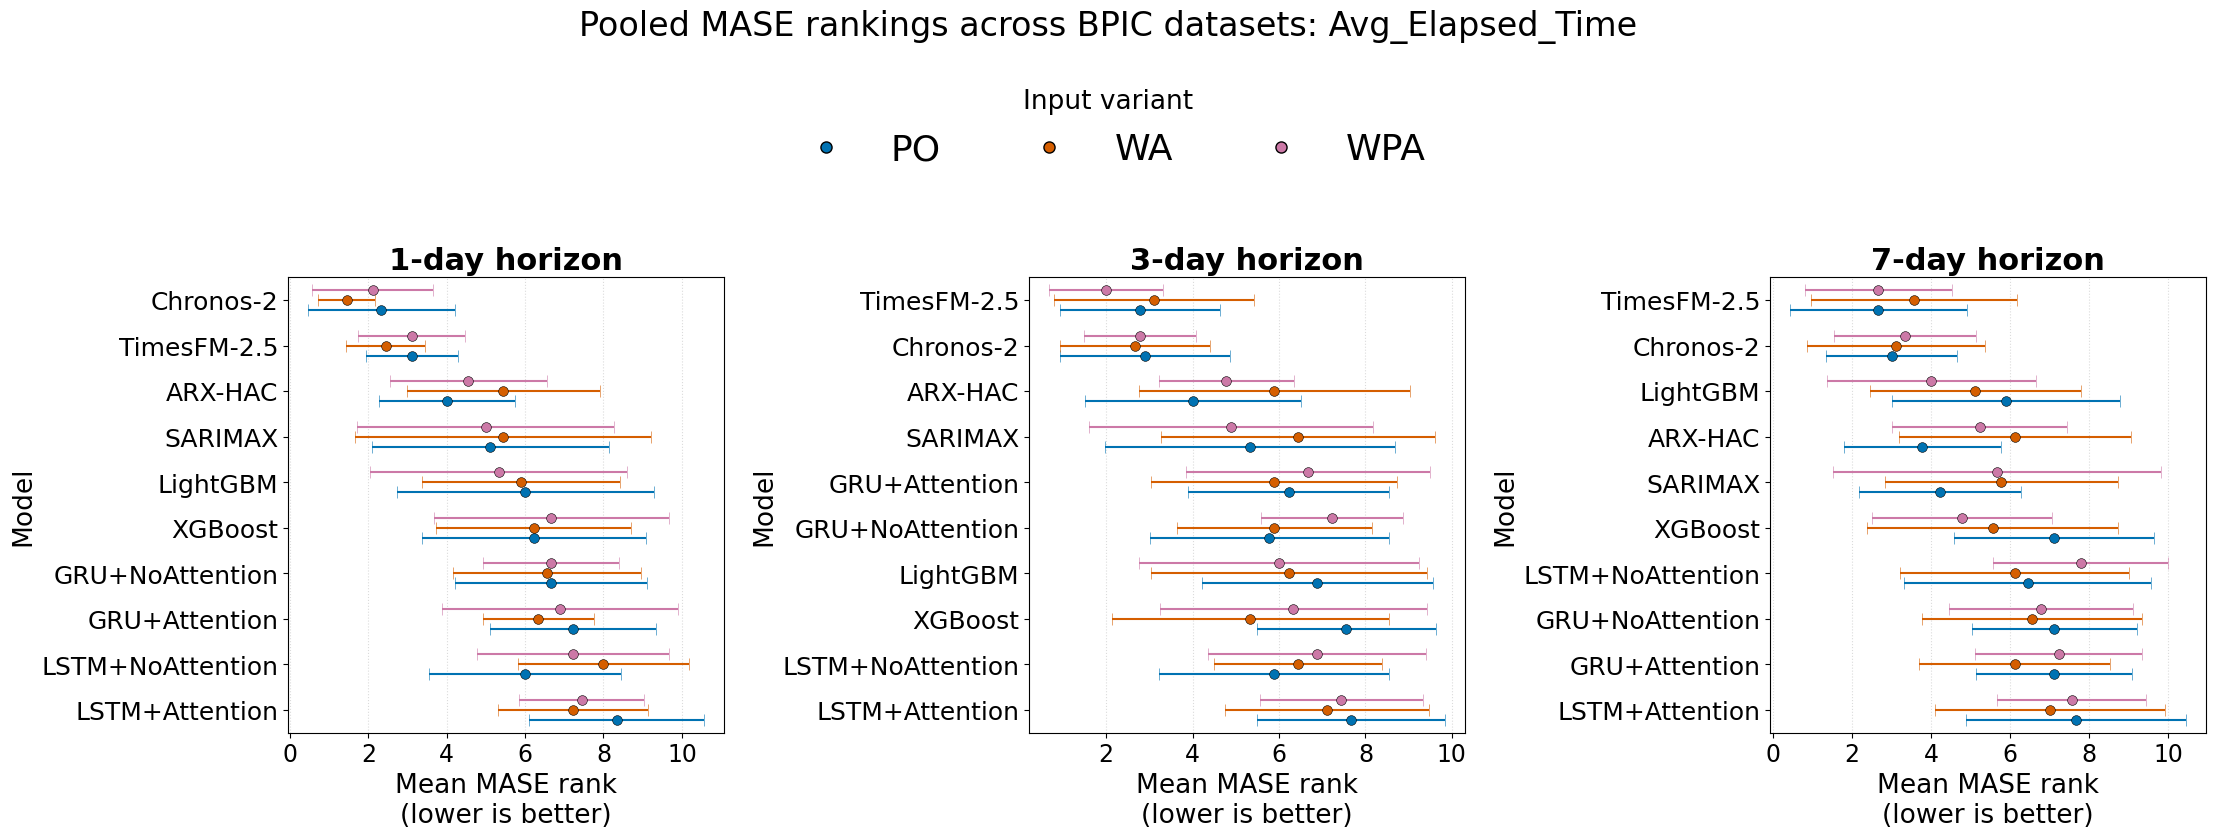

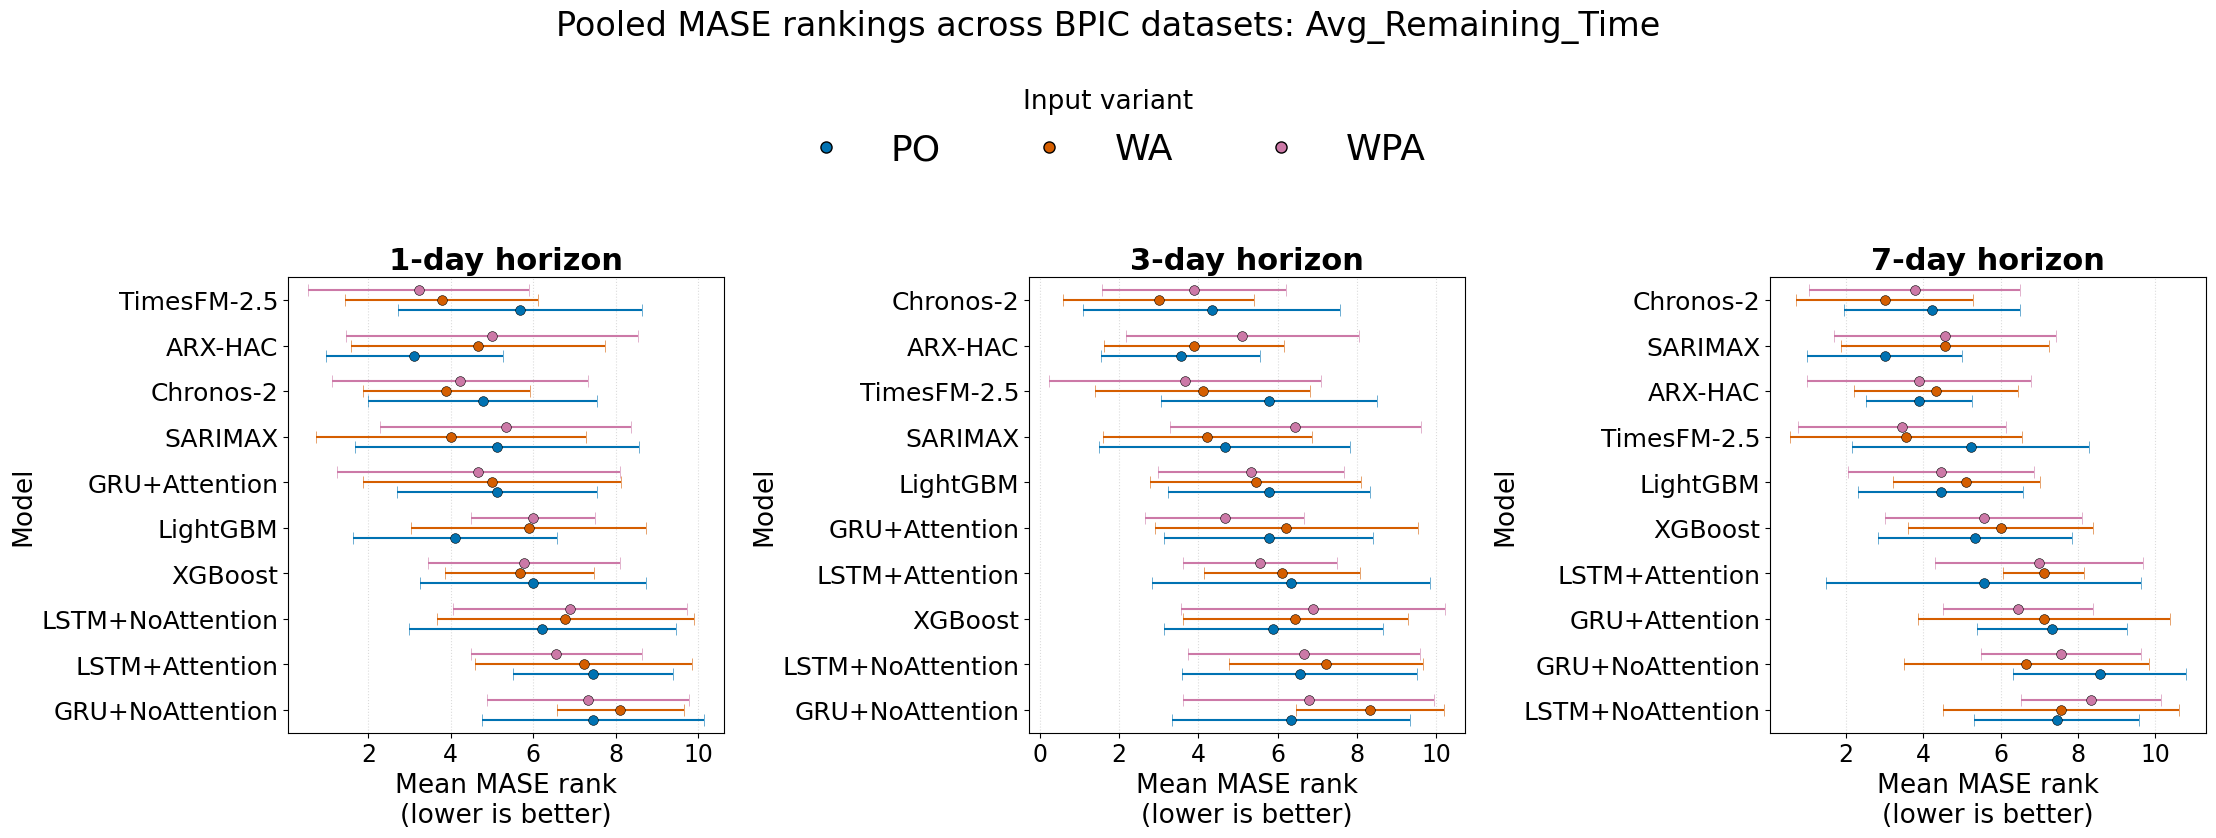

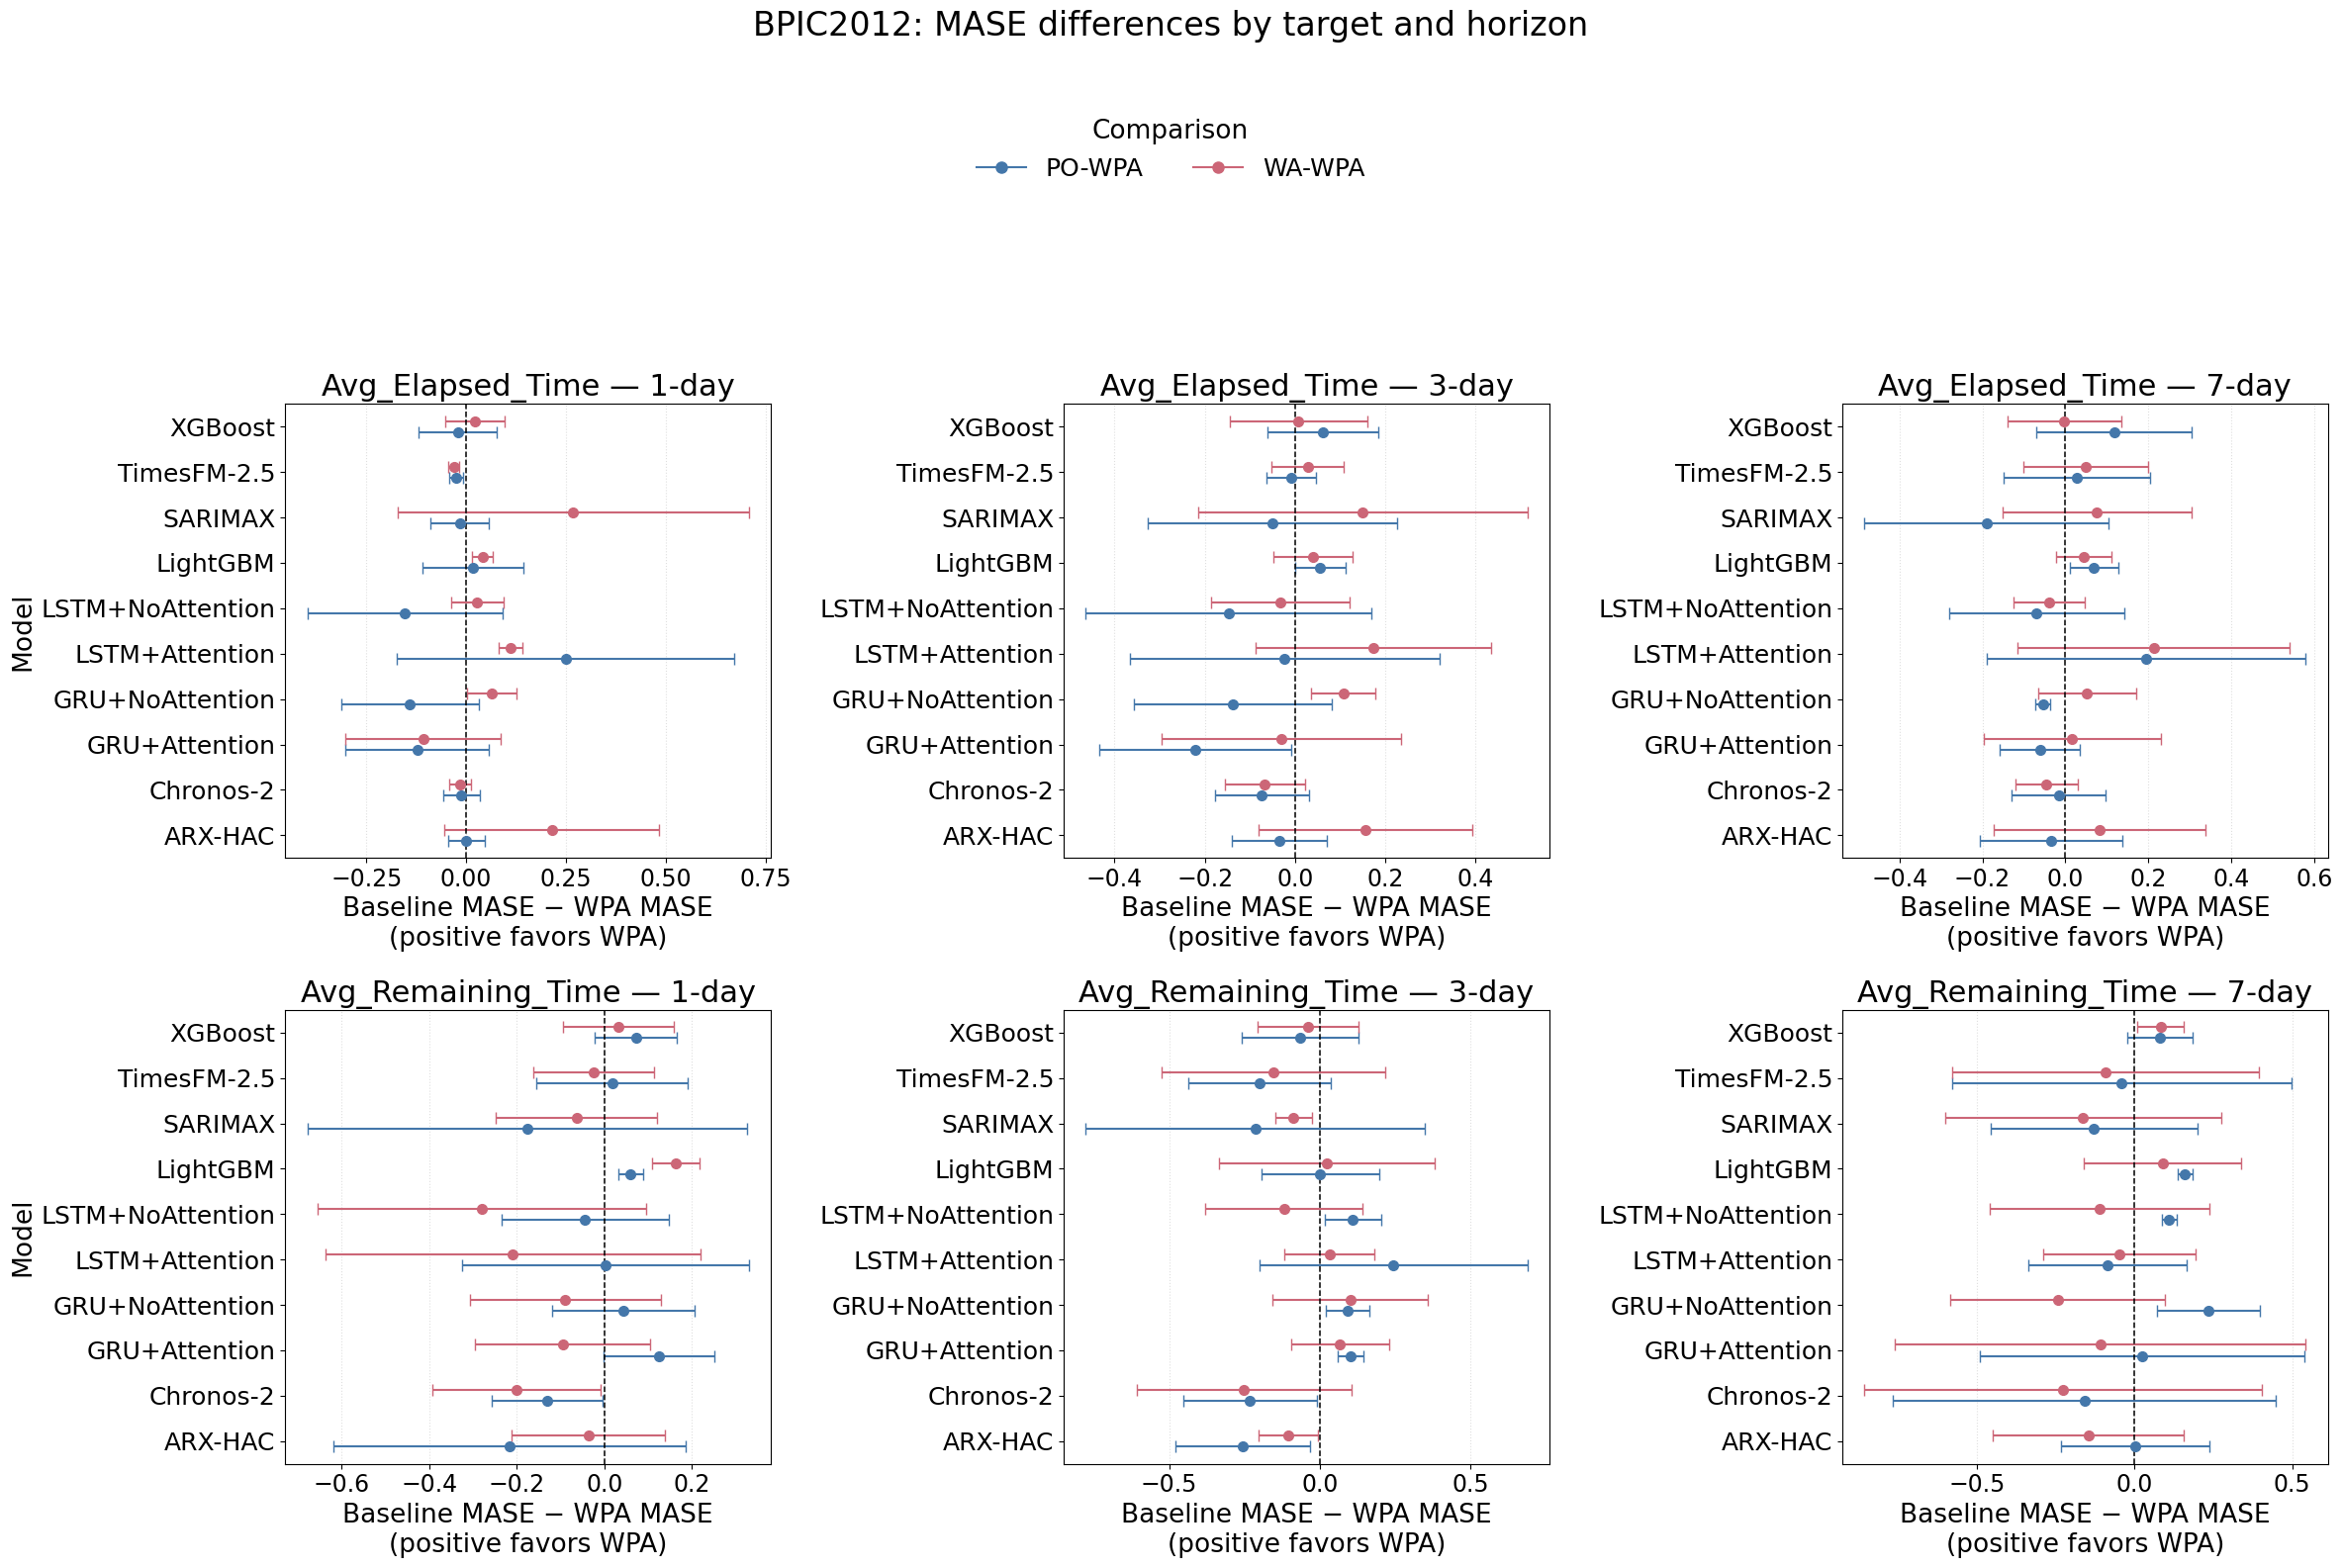

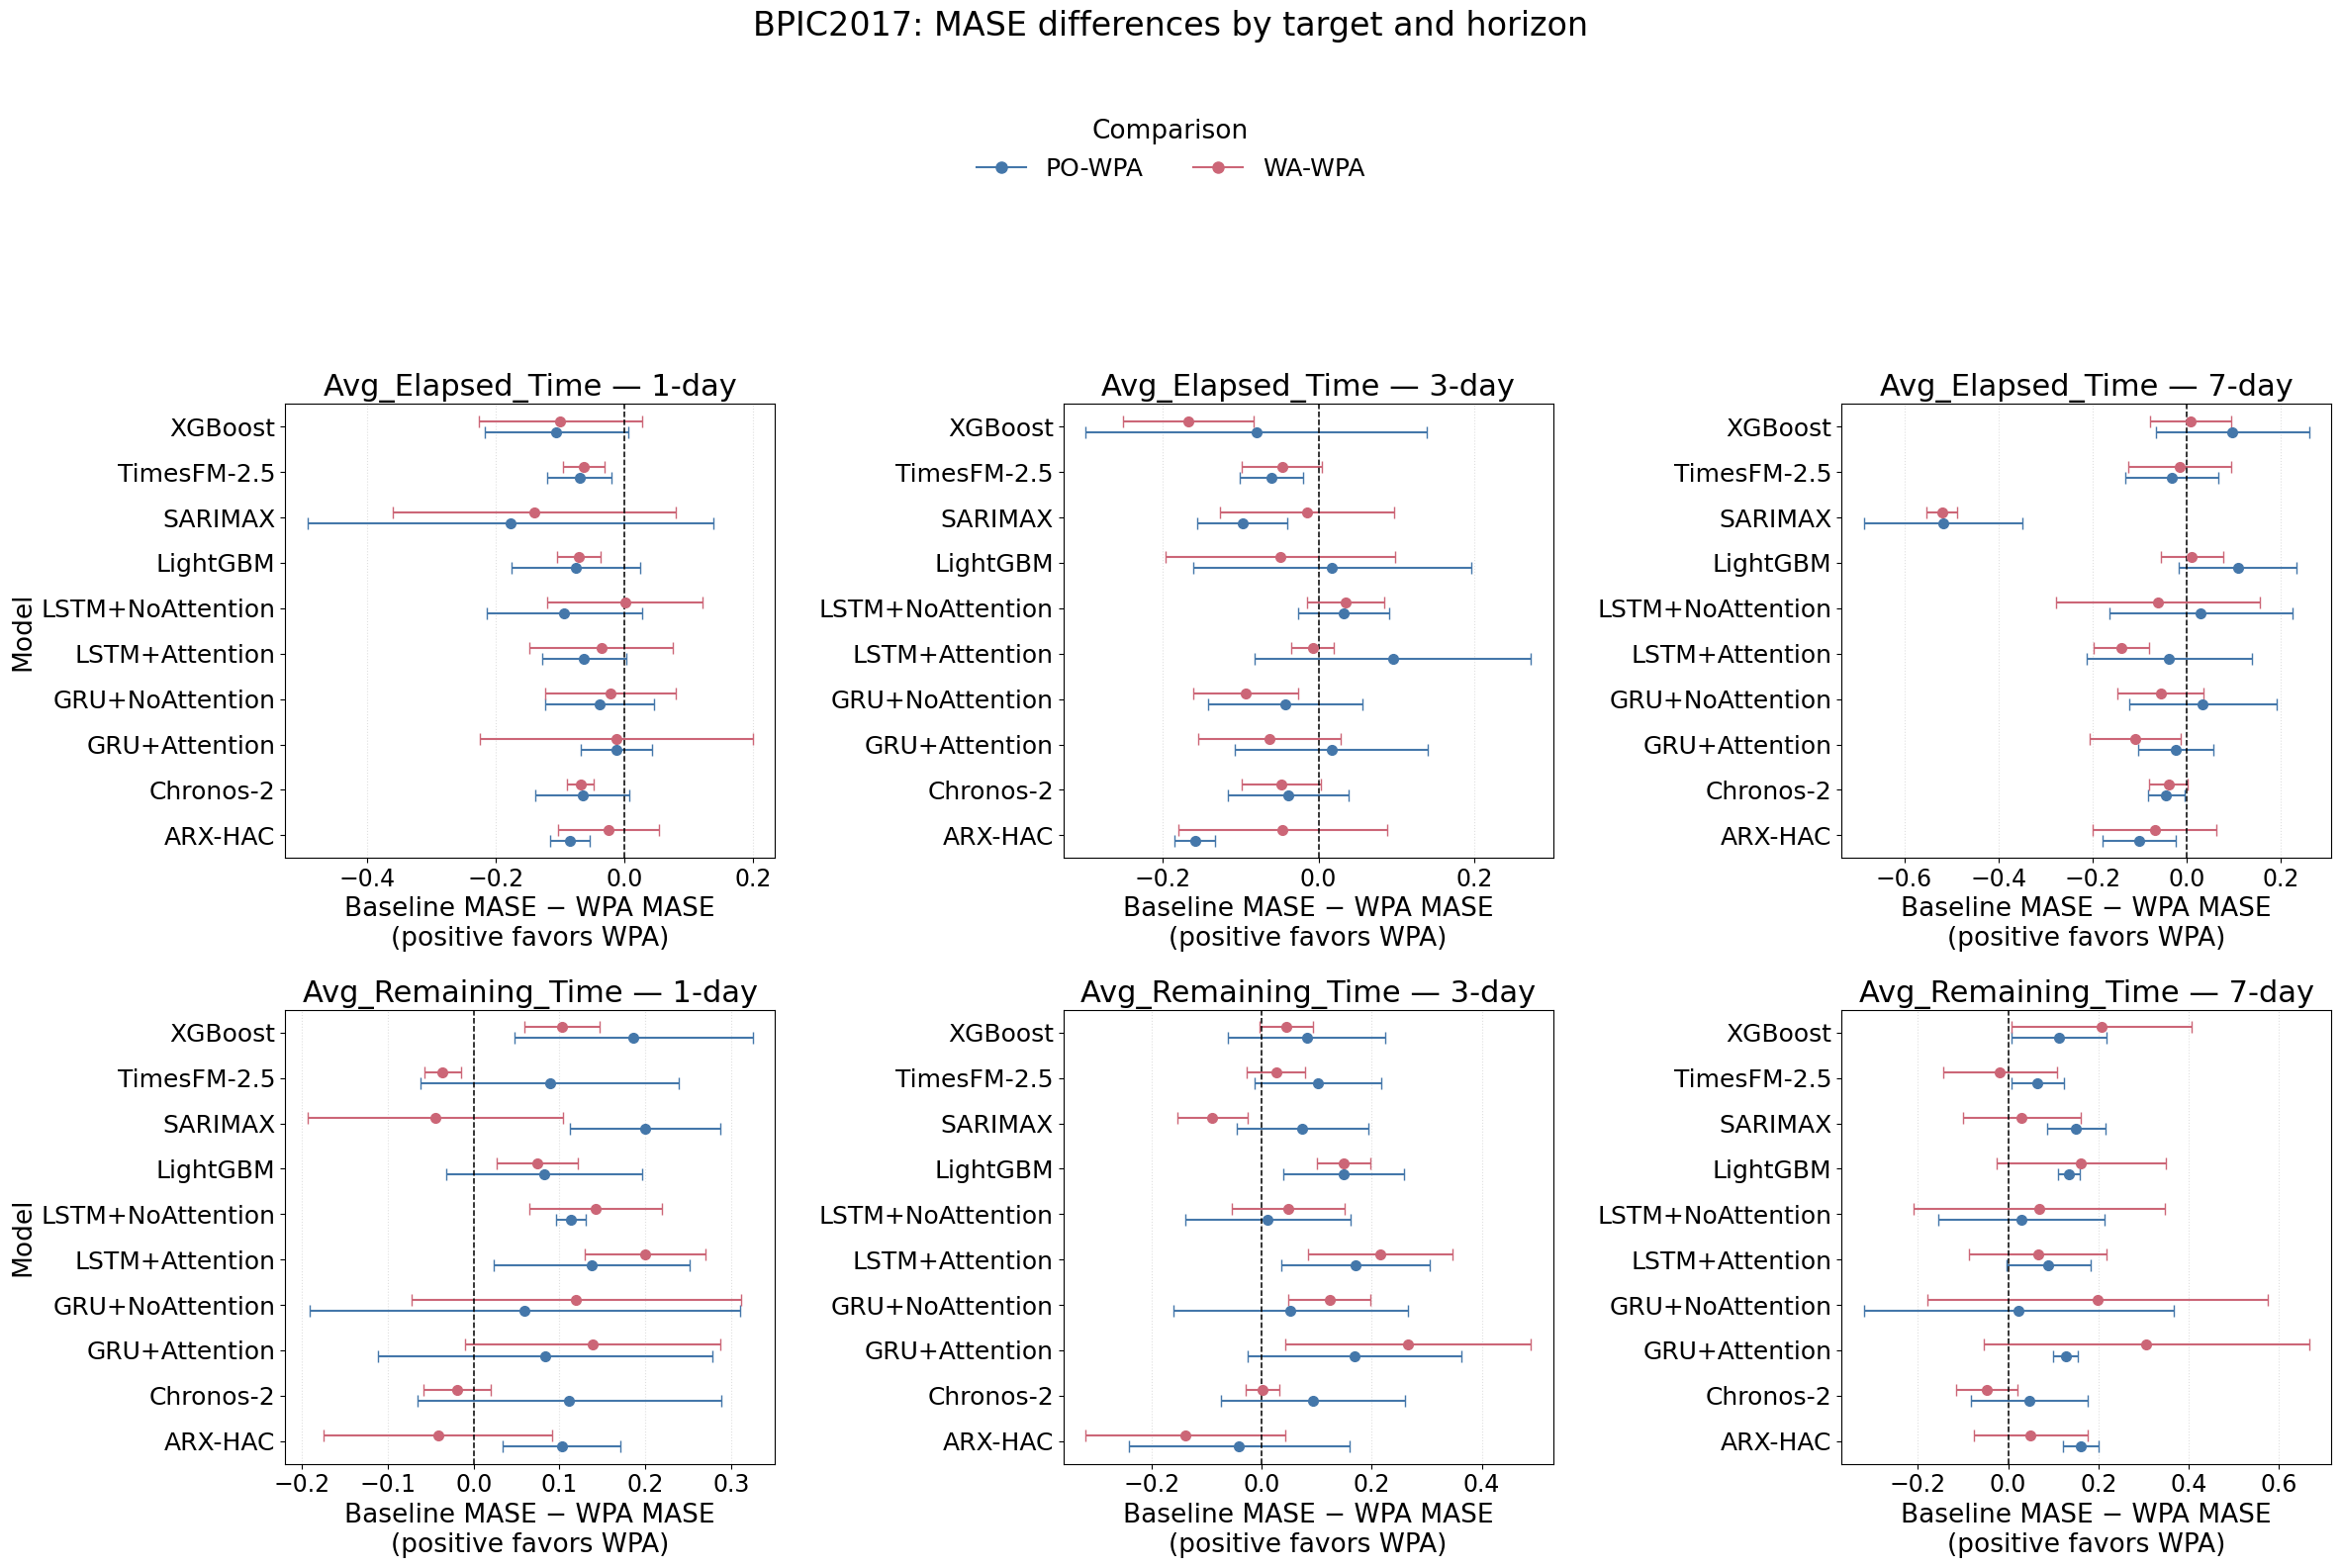

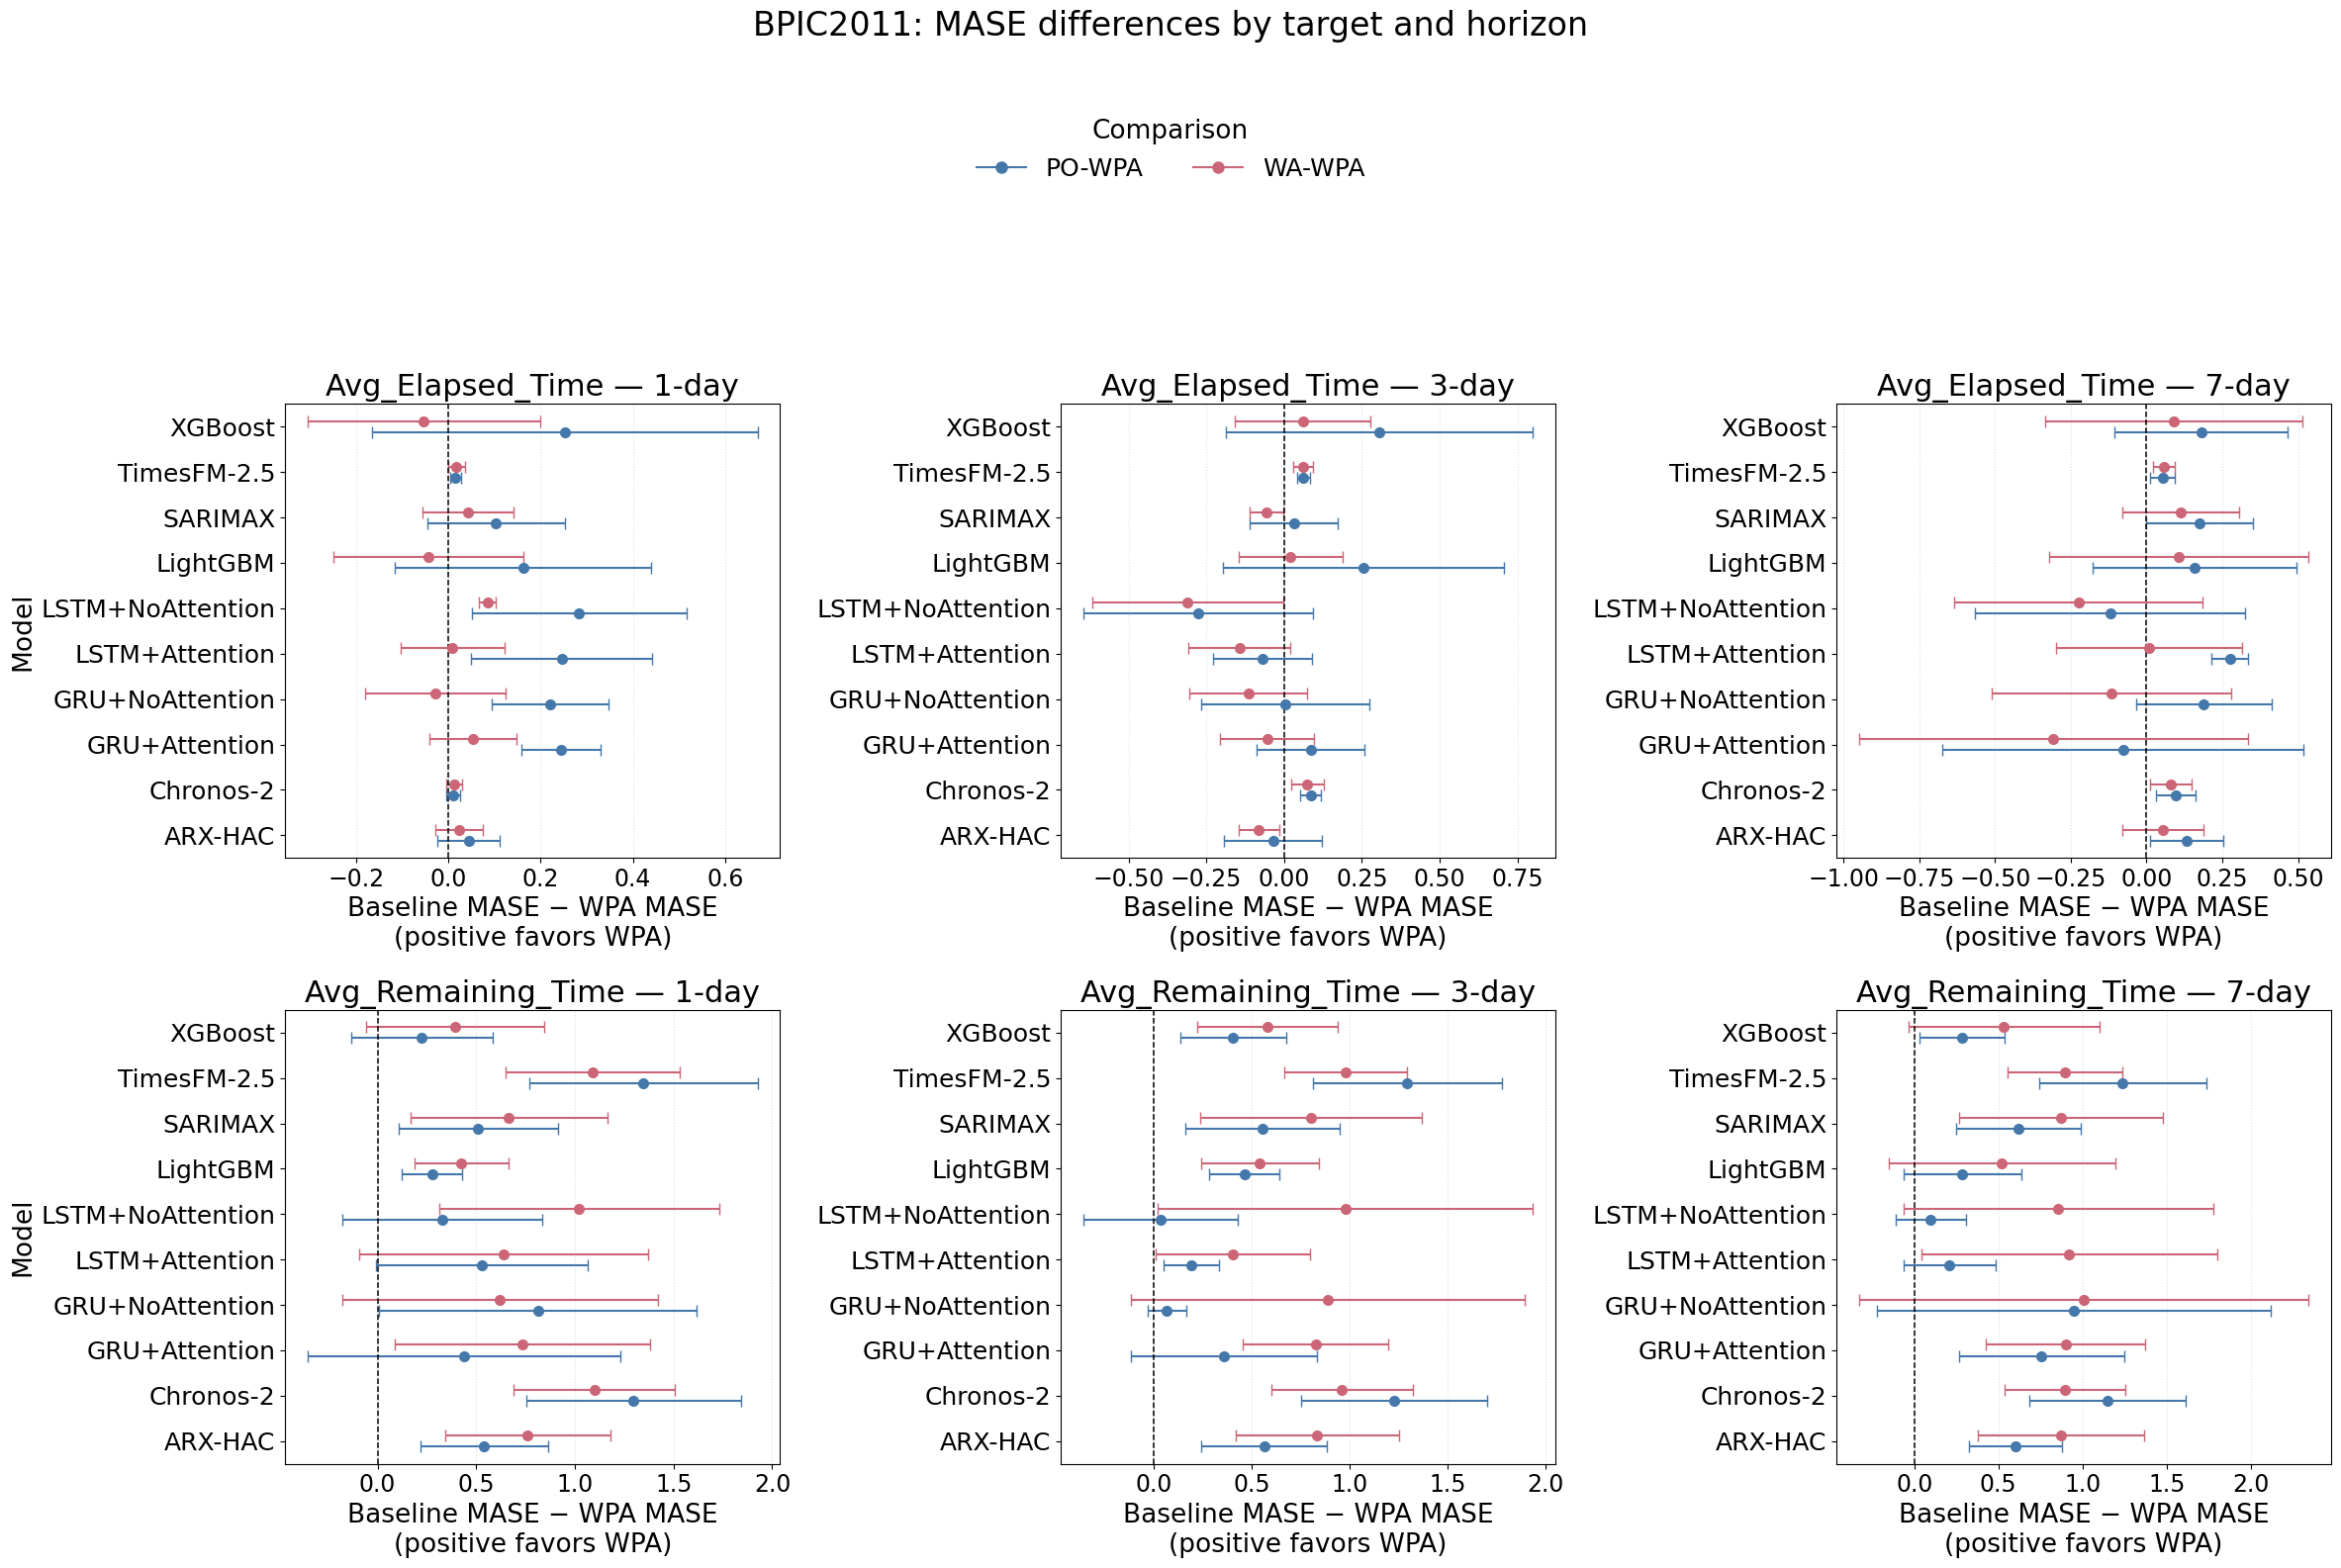


Created 2 pooled ranking figures and 3 per-dataset difference figures.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import io
import re
import zipfile
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from google.colab import files


# =============================================================
# FONT SIZES — change these numbers to adjust the text
# =============================================================

plt.rcParams.update({
    "font.size": 18,
    "axes.titlesize": 22,
    "axes.labelsize": 19,
    "xtick.labelsize": 17,
    "ytick.labelsize": 18,
    "legend.fontsize": 18,
    "legend.title_fontsize": 19,
    "figure.titlesize": 24,
})


# =============================================================
# UPLOAD ONE ZIP FOR EACH DATASET
# =============================================================

dataset_order = ["BPIC2012", "BPIC2017", "BPIC2011"]
dataset_zip_bytes = {}

for dataset in dataset_order:
    print(f"\nUpload the combined results ZIP for {dataset}.")
    uploaded = files.upload()

    if len(uploaded) != 1:
        raise ValueError(
            f"Expected exactly one ZIP for {dataset}; "
            f"received {len(uploaded)}."
        )

    name, content = next(iter(uploaded.items()))

    if not name.lower().endswith(".zip"):
        raise ValueError(f"{name} is not a ZIP file.")

    dataset_zip_bytes[dataset] = content
    print(f"Loaded {name} as {dataset}.")


def read_fold_metrics(zip_bytes, dataset):
    with zipfile.ZipFile(io.BytesIO(zip_bytes)) as archive:
        csv_names = [
            name for name in archive.namelist()
            if Path(name).name.lower()
            == "combined_rolling_origin_fold_metrics.csv"
        ]

        if not csv_names:
            csv_names = [
                name for name in archive.namelist()
                if "fold_metrics" in Path(name).name.lower()
                and name.lower().endswith(".csv")
            ]

        if not csv_names:
            raise FileNotFoundError(
                f"{dataset}: no fold-metrics CSV found in the ZIP."
            )

        if len(csv_names) > 1:
            print(f"{dataset}: using {csv_names[0]}")

        with archive.open(csv_names[0]) as source:
            return pd.read_csv(source)


def normalize_column(name):
    return (
        str(name).strip().lower()
        .replace(" ", "_")
        .replace("-", "_")
        .replace("/", "_")
    )


def find_column(columns, candidates):
    return next(
        (candidate for candidate in candidates if candidate in columns),
        None,
    )


def standardize_variant(value):
    key = (
        str(value).strip().lower()
        .replace("_", "")
        .replace("-", "")
        .replace(" ", "")
    )

    return {
        "po": "PO",
        "performanceonly": "PO",
        "wa": "WA",
        "workloadaware": "WA",
        "wpa": "WPA",
        "workloadplusactor": "WPA",
        "workloadawareplusactor": "WPA",
    }.get(key, str(value))


# =============================================================
# READ AND STANDARDIZE FOLD METRICS
# =============================================================

frames = []

for dataset in dataset_order:
    frame = read_fold_metrics(dataset_zip_bytes[dataset], dataset)
    frame.columns = [normalize_column(c) for c in frame.columns]
    columns = set(frame.columns)

    model_col = find_column(columns, ["model", "model_name"])
    target_col = find_column(columns, ["target", "target_name"])
    horizon_col = find_column(
        columns, ["horizon_days", "horizon", "h"]
    )
    variant_col = find_column(
        columns, ["variant", "feature_variant", "input_variant"]
    )
    mase_col = find_column(columns, ["mase", "mase_mean"])

    fold_col = find_column(
        columns,
        [
            "rolling_origin_fold",
            "rolling_fold",
            "fold_id",
            "fold",
            "fold_index",
            "origin_fold",
            "split_id",
        ],
    )

    if fold_col is None:
        fold_col = next(
            (c for c in frame.columns if "fold" in c),
            None,
        )

    required = [
        model_col, target_col, horizon_col,
        variant_col, mase_col, fold_col,
    ]

    if any(c is None for c in required):
        raise KeyError(
            f"{dataset}: could not identify all required columns. "
            f"Available columns: {list(frame.columns)}"
        )

    frame = frame.rename(columns={
        model_col: "model",
        target_col: "target",
        horizon_col: "horizon_days",
        variant_col: "variant",
        mase_col: "MASE",
        fold_col: "fold",
    })

    frame["dataset"] = dataset
    frame["model"] = frame["model"].astype(str)
    frame["target"] = frame["target"].astype(str)
    frame["variant"] = frame["variant"].map(standardize_variant)

    frame["horizon_days"] = pd.to_numeric(
        frame["horizon_days"], errors="coerce"
    )
    frame["MASE"] = pd.to_numeric(
        frame["MASE"], errors="coerce"
    )

    frame = frame.dropna(
        subset=[
            "dataset", "fold", "model", "target",
            "horizon_days", "variant", "MASE",
        ]
    )

    frames.append(frame[
        [
            "dataset", "fold", "model", "target",
            "horizon_days", "variant", "MASE",
        ]
    ])

all_metrics = pd.concat(frames, ignore_index=True)

variant_order = ["PO", "WA", "WPA"]
found_variants = set(all_metrics["variant"].unique())

if not set(variant_order).issubset(found_variants):
    raise ValueError(
        f"Expected PO, WA, and WPA variants; "
        f"found {sorted(found_variants)}."
    )

# Average repeated rows within each dataset-fold configuration.
fold_metrics = (
    all_metrics.groupby(
        ["dataset", "fold", "model", "target", "horizon_days", "variant"],
        as_index=False,
        dropna=False,
    )["MASE"]
    .mean()
)

print("\nFolds found per dataset:")
print(fold_metrics.groupby("dataset")["fold"].nunique())


# =============================================================
# POOLED MASE RANKINGS
# =============================================================

variant_colors = {
    "PO": "#0072B2",
    "WA": "#D55E00",
    "WPA": "#CC79A7",
}

variant_offsets = {
    "PO": -0.22,
    "WA": 0.0,
    "WPA": 0.22,
}

# Rank models within each dataset, fold, target, horizon, and variant.
fold_metrics["rank"] = (
    fold_metrics.groupby(
        ["dataset", "fold", "target", "horizon_days", "variant"]
    )["MASE"]
    .rank(method="average", ascending=True)
)

rank_summary = (
    fold_metrics.groupby(
        ["target", "horizon_days", "model", "variant"],
        as_index=False,
    )
    .agg(
        mean_rank=("rank", "mean"),
        sd_rank=("rank", "std"),
        n_dataset_folds=("rank", "count"),
        mean_mase=("MASE", "mean"),
    )
)

rank_summary["sd_rank"] = rank_summary["sd_rank"].fillna(0)

targets = sorted(rank_summary["target"].unique())
horizons = sorted(rank_summary["horizon_days"].unique())
ranking_files = []

for target in targets:
    target_data = rank_summary[
        rank_summary["target"] == target
    ].copy()

    n_models = target_data["model"].nunique()

    fig, axes = plt.subplots(
        nrows=1,
        ncols=len(horizons),
        figsize=(
            7.5 * len(horizons),
            max(8, 0.65 * n_models + 2),
        ),
        sharey=False,
        squeeze=False,
    )

    axes = axes[0]

    for col_i, horizon in enumerate(horizons):
        ax = axes[col_i]

        panel = target_data[
            target_data["horizon_days"] == horizon
        ].copy()

        plotted_panel = panel[
            panel["variant"].isin(variant_order)
        ]

        model_scores = (
            plotted_panel.groupby("model")["mean_rank"].mean()
        )

        model_order = (
            model_scores.sort_values(ascending=False)
            .index.tolist()
        )

        for variant in variant_order:
            variant_data = (
                panel[panel["variant"] == variant]
                .set_index("model")
            )

            x_values = []
            x_errors = []
            y_values = []

            for model_i, model in enumerate(model_order):
                if model not in variant_data.index:
                    continue

                result = variant_data.loc[model]

                x_values.append(result["mean_rank"])
                x_errors.append(result["sd_rank"])
                y_values.append(
                    model_i + variant_offsets[variant]
                )

            if x_values:
                ax.errorbar(
                    x_values,
                    y_values,
                    xerr=x_errors,
                    fmt="o",
                    color=variant_colors[variant],
                    ecolor=variant_colors[variant],
                    elinewidth=1.5,
                    capsize=4,
                    markersize=7,
                    markeredgecolor="black",
                    markeredgewidth=0.4,
                    label=variant,
                )

        ax.set_yticks(range(len(model_order)))
        ax.set_yticklabels(model_order, fontsize=18)
        ax.set_ylim(-0.5, len(model_order) - 0.5)

        ax.set_title(
            f"{int(horizon)}-day horizon",
            fontsize=22,
            fontweight="bold",
        )

        ax.set_xlabel(
            "Mean MASE rank\n(lower is better)",
            fontsize=19,
        )
        ax.set_ylabel("Model", fontsize=19)
        ax.tick_params(axis="x", labelsize=17)
        ax.grid(axis="x", linestyle=":", alpha=0.45)

    legend_handles = [
        Line2D(
            [0], [0],
            marker="o",
            linestyle="",
            color=variant_colors[variant],
            markeredgecolor="black",
            label=variant,
            markersize=8,
        )
        for variant in variant_order
    ]

    fig.suptitle(
        f"Pooled MASE rankings across BPIC datasets: {target}",
        fontsize=24,
        y=0.995,
    )

    fig.legend(
        handles=legend_handles,
        title="Input variant",
        title_fontsize=19,
        fontsize=26,
        loc="upper center",
        bbox_to_anchor=(0.5, 0.94),
        ncol=3,
        frameon=False,
    )

    fig.tight_layout(rect=[0, 0, 1, 0.82])

    safe_target = re.sub(
        r"[^A-Za-z0-9_-]+", "_", target
    )

    filename = (
        f"pooled_MASE_rankings_{safe_target}_all_horizons.png"
    )

    fig.savefig(
        filename,
        dpi=300,
        bbox_inches="tight",
    )

    ranking_files.append(filename)

    plt.show()
    plt.close(fig)


# =============================================================
# PER-DATASET MASE DIFFERENCES
# Positive baseline-minus-WPA differences favour WPA.
# =============================================================

comparison_pairs = [
    ("PO", "PO-WPA"),
    ("WA", "WA-WPA"),
]

merge_keys = [
    "dataset", "fold", "model", "target", "horizon_days"
]

difference_frames = []

for baseline_variant, contrast in comparison_pairs:
    baseline = (
        fold_metrics[
            fold_metrics["variant"] == baseline_variant
        ][merge_keys + ["MASE"]]
        .rename(columns={"MASE": "baseline_MASE"})
    )

    wpa = (
        fold_metrics[
            fold_metrics["variant"] == "WPA"
        ][merge_keys + ["MASE"]]
        .rename(columns={"MASE": "WPA_MASE"})
    )

    paired = baseline.merge(
        wpa,
        on=merge_keys,
        how="inner",
    )

    paired["contrast"] = contrast
    paired["MASE_difference"] = (
        paired["baseline_MASE"] - paired["WPA_MASE"]
    )

    difference_frames.append(paired)

differences = pd.concat(
    difference_frames,
    ignore_index=True,
)

if differences.empty:
    raise ValueError(
        "No paired PO-WPA or WA-WPA MASE results were found."
    )

difference_summary = (
    differences.groupby(
        ["dataset", "target", "horizon_days", "model", "contrast"],
        as_index=False,
    )
    .agg(
        mean_difference=("MASE_difference", "mean"),
        sd_difference=("MASE_difference", "std"),
        n_folds=("MASE_difference", "count"),
    )
)

difference_summary["sd_difference"] = (
    difference_summary["sd_difference"].fillna(0)
)

contrast_colors = {
    "PO-WPA": "#4477AA",
    "WA-WPA": "#CC6677",
}

difference_files = []

for dataset in dataset_order:
    dataset_summary = difference_summary[
        difference_summary["dataset"] == dataset
    ].copy()

    n_models = dataset_summary["model"].nunique()

    fig, axes = plt.subplots(
        nrows=len(targets),
        ncols=len(horizons),
        figsize=(
            8 * len(horizons),
            max(7, 0.65 * n_models + 1.5) * len(targets),
        ),
        squeeze=False,
    )

    for row_i, target in enumerate(targets):
        for col_i, horizon in enumerate(horizons):
            ax = axes[row_i, col_i]

            panel = dataset_summary[
                (dataset_summary["target"] == target)
                & (dataset_summary["horizon_days"] == horizon)
            ]

            models = sorted(
                panel["model"].astype(str).unique()
            )

            y_base = list(range(len(models)))

            offsets = {
                "PO-WPA": -0.12,
                "WA-WPA": 0.12,
            }

            for contrast in ["PO-WPA", "WA-WPA"]:
                contrast_data = panel[
                    panel["contrast"] == contrast
                ]

                for model_i, model in enumerate(models):
                    result_rows = contrast_data[
                        contrast_data["model"].astype(str) == model
                    ]

                    if result_rows.empty:
                        continue

                    result = result_rows.iloc[0]

                    ax.errorbar(
                        result["mean_difference"],
                        y_base[model_i] + offsets[contrast],
                        xerr=result["sd_difference"],
                        fmt="o",
                        capsize=4,
                        markersize=7,
                        color=contrast_colors[contrast],
                    )

            ax.axvline(
                0,
                color="black",
                linewidth=1.1,
                linestyle="--",
            )

            ax.set_yticks(y_base)
            ax.set_yticklabels(models, fontsize=18)
            ax.set_ylim(-0.5, len(models) - 0.5)

            ax.set_title(
                f"{target} — {int(horizon)}-day",
                fontsize=22,
            )

            ax.set_xlabel(
                "Baseline MASE − WPA MASE\n"
                "(positive favors WPA)",
                fontsize=19,
            )

            ax.tick_params(axis="x", labelsize=17)
            ax.grid(axis="x", linestyle=":", alpha=0.4)

            if col_i == 0:
                ax.set_ylabel("Model", fontsize=19)

    legend_handles = [
        Line2D(
            [0], [0],
            marker="o",
            linestyle="-",
            color=color,
            label=contrast,
            markersize=8,
        )
        for contrast, color in contrast_colors.items()
    ]

    fig.suptitle(
        f"{dataset}: MASE differences by target and horizon",
        fontsize=24,
        y=0.995,
    )

    fig.legend(
        handles=legend_handles,
        title="Comparison",
        title_fontsize=19,
        fontsize=18,
        loc="upper center",
        bbox_to_anchor=(0.5, 0.94),
        ncol=2,
        frameon=False,
    )

    fig.tight_layout(rect=[0, 0, 1, 0.82])

    filename = (
        f"{dataset}_MASE_differences_PO-WPA_WA-WPA.png"
    )

    fig.savefig(
        filename,
        dpi=300,
        bbox_inches="tight",
    )

    difference_files.append(filename)

    plt.show()
    plt.close(fig)


# =============================================================
# SAVE DATA AND DOWNLOAD ALL OUTPUTS
# =============================================================

rank_summary.to_csv(
    "pooled_MASE_ranking_summary.csv",
    index=False,
)

difference_summary.to_csv(
    "per_dataset_MASE_difference_summary.csv",
    index=False,
)

differences.to_csv(
    "per_fold_MASE_differences.csv",
    index=False,
)

output_zip = "pooled_MASE_rankings_and_dataset_differences.zip"

output_files = ranking_files + difference_files + [
    "pooled_MASE_ranking_summary.csv",
    "per_dataset_MASE_difference_summary.csv",
    "per_fold_MASE_differences.csv",
]

with zipfile.ZipFile(
    output_zip,
    "w",
    compression=zipfile.ZIP_DEFLATED,
) as archive:
    for filename in output_files:
        if Path(filename).exists():
            archive.write(filename)

print(
    f"\nCreated {len(ranking_files)} pooled ranking figures and "
    f"{len(difference_files)} per-dataset difference figures."
)
print(f"Downloading {output_zip}")

files.download(output_zip)

DM significance results table

In [ ]:
from IPython.display import display, HTML
from pathlib import Path
import pandas as pd

dm_results = out.copy()

if dm_results.empty:
    print("No DM comparisons were produced. Check the DM comparison output.")
else:
    # Show the available reporting columns, including any dataset identifier.
    preferred_cols = [
        "dataset_file",
        "comparison_family",
        "comparison",
        "target",
        "horizon_days",
        "n_paired_origins",
        "RMSE_a",
        "RMSE_b",
        "RMSE_difference_a_minus_b",
        "p_value_holm",
        "favored_by_mean_loss",
    ]
    show_cols = [c for c in preferred_cols if c in dm_results.columns]
    display_table = dm_results[show_cols].copy()

    # Sort where the relevant columns are present.
    sort_cols = [
        c for c in [
            "dataset_file", "target", "horizon_days",
            "comparison_family", "p_value_holm",
        ]
        if c in display_table.columns
    ]
    if sort_cols:
        display_table = display_table.sort_values(sort_cols)

    # Round numeric results for easier reading.
    numeric_cols = display_table.select_dtypes(include="number").columns
    display_table[numeric_cols] = display_table[numeric_cols].round(4)

    def show_full_table(table, title):
        print(title)
        html = table.reset_index(drop=True).to_html(
            index=False,
            escape=True,
            na_rep="—",
        )
        display(HTML(
            f'<div style="max-height:700px; overflow:auto;">{html}</div>'
        ))

    # Display every DM comparison, grouped by dataset and target if available.
    group_cols = [
        c for c in ["dataset_file", "target"]
        if c in display_table.columns
    ]

    if group_cols:
        for group_key, table in display_table.groupby(
            group_cols, dropna=False, sort=True
        ):
            if not isinstance(group_key, tuple):
                group_key = (group_key,)
            heading = " — ".join(
                f"{col}: {value}" for col, value in zip(group_cols, group_key)
            )
            show_full_table(table, f"All DM comparisons — {heading}")
    else:
        show_full_table(display_table, "All DM comparisons")

    # Show every comparison with Holm-adjusted p < 0.05.
    if "p_value_holm" in display_table.columns:
        significant = display_table[
            pd.to_numeric(display_table["p_value_holm"], errors="coerce") < 0.05
        ]

        if significant.empty:
            print("No comparisons were significant after Holm adjustment (p < 0.05).")
        elif group_cols:
            for group_key, table in significant.groupby(
                group_cols, dropna=False, sort=True
            ):
                if not isinstance(group_key, tuple):
                    group_key = (group_key,)
                heading = " — ".join(
                    f"{col}: {value}" for col, value in zip(group_cols, group_key)
                )
                show_full_table(
                    table,
                    f"Significant after Holm adjustment — {heading}",
                )
        else:
            show_full_table(
                significant,
                "Significant after Holm adjustment (p < 0.05)",
            )

    # Save the complete DM table, not only the displayed subset.
    output_csv = "/content/dm_results_complete.csv"
    dm_results.to_csv(output_csv, index=False)
    print(f"Complete DM results saved to: {output_csv}")

All DM comparisons — dataset_file: unknown_dataset — target: Avg_Elapsed_Time


dataset_file,comparison_family,comparison,target,horizon_days,n_paired_origins,RMSE_a,RMSE_b,RMSE_difference_a_minus_b,p_value_holm,favored_by_mean_loss
unknown_dataset,primary_SARIMAX_feature_variants,PerformanceOnly_vs_WorkloadAware,Avg_Elapsed_Time,1,43,41.4775,66.6295,-25.1520,0.1491,SARIMAX:PerformanceOnly
unknown_dataset,primary_SARIMAX_feature_variants,WorkloadAware_vs_WorkloadPlusActor,Avg_Elapsed_Time,1,43,66.6295,46.0425,20.5871,0.6181,SARIMAX:WorkloadPlusActor
unknown_dataset,primary_SARIMAX_feature_variants,PerformanceOnly_vs_WorkloadPlusActor,Avg_Elapsed_Time,1,43,41.4775,46.0425,-4.5649,1.0000,SARIMAX:PerformanceOnly
unknown_dataset,secondary_model_comparisons,FrozenFoundationModel_SupervisedReadout:Chronos-2_vs_SARIMAX,Avg_Elapsed_Time,1,37,48.4148,36.8209,11.5939,1.0000,FrozenFoundationModel_SupervisedReadout:Chronos-2:WorkloadPlusActor
unknown_dataset,secondary_model_comparisons,FrozenFoundationModel_SupervisedReadout:TimesFM-2.5_vs_SARIMAX,Avg_Elapsed_Time,1,37,48.4148,39.2572,9.1575,1.0000,FrozenFoundationModel_SupervisedReadout:TimesFM-2.5:WorkloadPlusActor
unknown_dataset,secondary_model_comparisons,Classical:ARX-HAC_vs_SARIMAX,Avg_Elapsed_Time,1,43,46.0425,43.8060,2.2365,1.0000,Classical:ARX-HAC:WorkloadPlusActor
unknown_dataset,secondary_model_comparisons,DeepLearning:GRU+Attention_vs_SARIMAX,Avg_Elapsed_Time,1,43,46.0425,62.1000,-16.0575,1.0000,SARIMAX:WorkloadPlusActor
unknown_dataset,secondary_model_comparisons,DeepLearning:LSTM+NoAttention_vs_SARIMAX,Avg_Elapsed_Time,1,43,46.0425,62.7777,-16.7352,1.0000,SARIMAX:WorkloadPlusActor
unknown_dataset,secondary_model_comparisons,DeepLearning:LSTM+Attention_vs_SARIMAX,Avg_Elapsed_Time,1,43,46.0425,59.9108,-13.8683,1.0000,SARIMAX:WorkloadPlusActor
unknown_dataset,secondary_model_comparisons,DeepLearning:GRU+NoAttention_vs_SARIMAX,Avg_Elapsed_Time,1,43,46.0425,61.6016,-15.5591,1.0000,SARIMAX:WorkloadPlusActor


All DM comparisons — dataset_file: unknown_dataset — target: Avg_Remaining_Time


dataset_file,comparison_family,comparison,target,horizon_days,n_paired_origins,RMSE_a,RMSE_b,RMSE_difference_a_minus_b,p_value_holm,favored_by_mean_loss
unknown_dataset,primary_SARIMAX_feature_variants,PerformanceOnly_vs_WorkloadAware,Avg_Remaining_Time,1,43,55.3941,63.0276,-7.6335,1.0,SARIMAX:PerformanceOnly
unknown_dataset,primary_SARIMAX_feature_variants,WorkloadAware_vs_WorkloadPlusActor,Avg_Remaining_Time,1,43,63.0276,67.1968,-4.1691,1.0,SARIMAX:WorkloadAware
unknown_dataset,primary_SARIMAX_feature_variants,PerformanceOnly_vs_WorkloadPlusActor,Avg_Remaining_Time,1,43,55.3941,67.1968,-11.8027,1.0,SARIMAX:PerformanceOnly
unknown_dataset,secondary_model_comparisons,FrozenFoundationModel_SupervisedReadout:Chronos-2_vs_SARIMAX,Avg_Remaining_Time,1,37,55.2942,53.3645,1.9297,1.0,FrozenFoundationModel_SupervisedReadout:Chronos-2:WorkloadPlusActor
unknown_dataset,secondary_model_comparisons,FrozenFoundationModel_SupervisedReadout:TimesFM-2.5_vs_SARIMAX,Avg_Remaining_Time,1,37,55.2942,49.9461,5.3481,1.0,FrozenFoundationModel_SupervisedReadout:TimesFM-2.5:WorkloadPlusActor
unknown_dataset,secondary_model_comparisons,Classical:ARX-HAC_vs_SARIMAX,Avg_Remaining_Time,1,43,67.1968,68.1339,-0.9372,1.0,SARIMAX:WorkloadPlusActor
unknown_dataset,secondary_model_comparisons,DeepLearning:GRU+Attention_vs_SARIMAX,Avg_Remaining_Time,1,43,67.1968,55.2796,11.9172,1.0,DeepLearning:GRU+Attention:WorkloadPlusActor
unknown_dataset,secondary_model_comparisons,DeepLearning:LSTM+NoAttention_vs_SARIMAX,Avg_Remaining_Time,1,43,67.1968,65.2903,1.9065,1.0,DeepLearning:LSTM+NoAttention:WorkloadPlusActor
unknown_dataset,secondary_model_comparisons,DeepLearning:LSTM+Attention_vs_SARIMAX,Avg_Remaining_Time,1,43,67.1968,64.2989,2.8979,1.0,DeepLearning:LSTM+Attention:WorkloadPlusActor
unknown_dataset,secondary_model_comparisons,DeepLearning:GRU+NoAttention_vs_SARIMAX,Avg_Remaining_Time,1,43,67.1968,60.1803,7.0165,1.0,DeepLearning:GRU+NoAttention:WorkloadPlusActor


No comparisons were significant after Holm adjustment (p < 0.05).
Complete DM results saved to: /content/dm_results_complete.csv


In [ ]:
import io
import re
import zipfile
from pathlib import Path
from html import escape

import numpy as np
import pandas as pd
from google.colab import files
from IPython.display import display, HTML

# Optional: set the dataset name if the ZIP contains "unknown_dataset".
# Examples: "BPIC2011", "BPIC2012", "BPIC2017"
DATASET_LABEL = None

METRICS = ["RMSE", "MAE", "MASE", "R2"]
VARIANT_PAIRS = [
    ("PerformanceOnly", "WorkloadAware"),
    ("PerformanceOnly", "WorkloadPlusActor"),
    ("WorkloadAware", "WorkloadPlusActor"),
]
SHORT_NAMES = {
    "PerformanceOnly": "PO",
    "WorkloadAware": "WA",
    "WorkloadPlusActor": "WPA",
}

# ------------------------------------------------------------
# 1. Upload the combined model-results ZIP
# ------------------------------------------------------------
print("Upload ONE combined model-results ZIP for the dataset.")
uploaded = files.upload()

zip_names = [
    name for name in uploaded
    if name.lower().endswith(".zip")
]
if len(zip_names) != 1:
    raise ValueError("Please upload exactly one combined results ZIP.")

zip_name = zip_names[0]

with zipfile.ZipFile(io.BytesIO(uploaded[zip_name])) as archive:
    csv_names = [
        name for name in archive.namelist()
        if not name.endswith("/")
        and "__MACOSX" not in name
        and name.lower().endswith(".csv")
    ]

    # Prefer the combined fold table; do not load summary tables.
    preferred = [
        name for name in csv_names
        if Path(name).name.lower()
        == "combined_rolling_origin_fold_metrics.csv"
    ]

    if preferred:
        selected_files = preferred
    else:
        selected_files = [
            name for name in csv_names
            if Path(name).name.lower()
            == "rolling_origin_fold_metrics.csv"
        ]

    if not selected_files:
        raise FileNotFoundError(
            "No rolling-origin fold metrics CSV was found. "
            "Upload the combined results ZIP containing "
            "combined_rolling_origin_fold_metrics.csv."
        )

    frames = [
        pd.read_csv(io.BytesIO(archive.read(name)))
        for name in selected_files
    ]

fold_metrics = pd.concat(frames, ignore_index=True)
fold_metrics.columns = fold_metrics.columns.str.strip()

# ------------------------------------------------------------
# 2. Validate the fold-level data
# ------------------------------------------------------------
required = {
    "group", "model", "target", "horizon_days",
    "variant", "fold", *METRICS,
}
missing = required - set(fold_metrics.columns)
if missing:
    raise KeyError(
        f"Fold metrics are missing columns: {sorted(missing)}"
    )

if DATASET_LABEL:
    fold_metrics["dataset_file"] = DATASET_LABEL
elif "dataset_file" not in fold_metrics.columns:
    fold_metrics["dataset_file"] = Path(zip_name).stem

fold_metrics["dataset_file"] = (
    fold_metrics["dataset_file"].fillna("unknown_dataset")
)

for col in ["group", "model", "target", "variant", "fold"]:
    if fold_metrics[col].isna().any():
        raise ValueError(f"Missing identifiers in column: {col}")
    fold_metrics[col] = fold_metrics[col].astype(str).str.strip()

fold_metrics["horizon_days"] = pd.to_numeric(
    fold_metrics["horizon_days"], errors="raise"
).astype(int)

for metric in METRICS:
    fold_metrics[metric] = pd.to_numeric(
        fold_metrics[metric], errors="raise"
    ).replace([np.inf, -np.inf], np.nan)

# Keep the three main input variants.
fold_metrics = fold_metrics[
    fold_metrics["variant"].isin(SHORT_NAMES)
].copy()

if fold_metrics.empty:
    raise ValueError("No PO, WA, or WPA fold results were found.")

base_keys = [
    "dataset_file", "group", "model",
    "target", "horizon_days",
]
unique_keys = base_keys + ["variant", "fold"]

# Remove identical duplicate metric records.
fold_metrics = fold_metrics.drop_duplicates(
    subset=unique_keys + METRICS
)

# Conflicting records must not be silently averaged.
conflicts = fold_metrics.duplicated(
    subset=unique_keys, keep=False
)
if conflicts.any():
    display(fold_metrics.loc[conflicts, unique_keys + METRICS])
    raise ValueError(
        "Conflicting results exist for the same model, "
        "variant, target, horizon, and fold."
    )

# ------------------------------------------------------------
# 3. Establish the fold order separately for each dataset
# ------------------------------------------------------------
def fold_sort_key(value):
    numbers = re.findall(r"\d+(?:\.\d+)?", str(value))
    return (tuple(float(x) for x in numbers), str(value))

fold_orders = {}

for dataset, group in fold_metrics.groupby("dataset_file"):
    order = sorted(
        group["fold"].unique(),
        key=fold_sort_key,
    )

    if len(order) > 3:
        raise ValueError(
            f"{dataset}: found {len(order)} fold identifiers: {order}. "
            "Check that this ZIP contains one evaluation run."
        )

    fold_orders[dataset] = order
    print(f"\nDataset: {dataset}")
    for i, fold in enumerate(order, start=1):
        print(f"  F{i} = {fold}")

    if len(order) < 3:
        print("  Warning: fewer than three folds are available.")

# ------------------------------------------------------------
# 4. Build comparisons within each fold
# ------------------------------------------------------------
paired_frames = []

for baseline_variant, compared_variant in VARIANT_PAIRS:
    baseline = fold_metrics[
        fold_metrics["variant"] == baseline_variant
    ][base_keys + ["fold"] + METRICS].rename(
        columns={m: f"{m}_baseline" for m in METRICS}
    )

    compared = fold_metrics[
        fold_metrics["variant"] == compared_variant
    ][base_keys + ["fold"] + METRICS].rename(
        columns={m: f"{m}_compared" for m in METRICS}
    )

    # Outer merge preserves incomplete fold coverage.
    paired = baseline.merge(
        compared,
        on=base_keys + ["fold"],
        how="outer",
        validate="one_to_one",
    )

    if paired.empty:
        continue

    paired["Baseline variant"] = baseline_variant
    paired["Compared variant"] = compared_variant

    # Positive differences favor the compared variant.
    for metric in ["RMSE", "MAE", "MASE"]:
        paired[f"delta_{metric}"] = (
            paired[f"{metric}_baseline"]
            - paired[f"{metric}_compared"]
        )

    paired["delta_R2"] = (
        paired["R2_compared"] - paired["R2_baseline"]
    )

    paired_frames.append(paired)

paired_folds = pd.concat(paired_frames, ignore_index=True)

# ------------------------------------------------------------
# 5. Put the three fold values into each table cell
# ------------------------------------------------------------
def fold_cell(table, column, fold_order):
    values = table.set_index("fold")[column]
    parts = []

    # Always show three positions, including missing results.
    for i in range(3):
        if i < len(fold_order):
            value = values.get(fold_order[i], np.nan)
        else:
            value = np.nan

        formatted = "—" if pd.isna(value) else f"{value:.3f}"
        parts.append(f"F{i + 1}: {formatted}")

    return " | ".join(parts)

display_rows = []
comparison_keys = base_keys + [
    "Baseline variant", "Compared variant"
]

for key, group in paired_folds.groupby(
    comparison_keys, sort=True, dropna=False
):
    identifiers = dict(zip(comparison_keys, key))
    dataset = identifiers["dataset_file"]
    order = fold_orders[dataset]

    baseline_variant = identifiers["Baseline variant"]
    compared_variant = identifiers["Compared variant"]

    # Require both variants to exist somewhere in this setting.
    has_baseline = group[
        [f"{m}_baseline" for m in METRICS]
    ].notna().any().any()
    has_compared = group[
        [f"{m}_compared" for m in METRICS]
    ].notna().any().any()

    if not (has_baseline and has_compared):
        continue

    row = {
        "dataset_file": dataset,
        "group": identifiers["group"],
        "model": identifiers["model"],
        "target": identifiers["target"],
        "H (days)": identifiers["horizon_days"],
        "Comparison": (
            f"{SHORT_NAMES[baseline_variant]} → "
            f"{SHORT_NAMES[compared_variant]}"
        ),
    }

    for metric in METRICS:
        label = "R²" if metric == "R2" else metric
        row[f"{label} baseline"] = fold_cell(
            group, f"{metric}_baseline", order
        )
        row[f"{label} compared"] = fold_cell(
            group, f"{metric}_compared", order
        )
        row[f"Δ{label}"] = fold_cell(
            group, f"delta_{metric}", order
        )

    display_rows.append(row)

paper_table = pd.DataFrame(display_rows)

if paper_table.empty:
    raise ValueError("No usable variant comparisons were found.")

# ------------------------------------------------------------
# 6. Display tables by dataset and target
# ------------------------------------------------------------
print(
    "\nEach cell reports F1 | F2 | F3, not mean ± standard deviation.\n"
    "Positive Δ values favor the compared variant.\n"
    "Differences use matched folds; unavailable values remain missing."
)

for (dataset, target), table in paper_table.groupby(
    ["dataset_file", "target"], sort=True
):
    print(f"\n{dataset} — {target}")

    shown = table.drop(
        columns=["dataset_file", "target"]
    ).reset_index(drop=True)

    display(HTML(
        '<div style="max-height:750px; overflow:auto;">'
        + shown.to_html(index=False, escape=True, na_rep="—")
        + "</div>"
    ))

# ------------------------------------------------------------
# 7. Save and download the complete results
# ------------------------------------------------------------
output_dir = Path("/content/fold_results_tables")
output_dir.mkdir(parents=True, exist_ok=True)

formatted_path = output_dir / "paper_results_three_folds_per_cell.csv"
numeric_path = output_dir / "paired_variant_results_by_fold.csv"
raw_path = output_dir / "model_metrics_by_fold.csv"
mapping_path = output_dir / "fold_label_mapping.csv"

paper_table.to_csv(formatted_path, index=False)
paired_folds.to_csv(numeric_path, index=False)
fold_metrics.to_csv(raw_path, index=False)

mapping_rows = [
    {
        "dataset_file": dataset,
        "display_label": f"F{i + 1}",
        "original_fold": fold,
    }
    for dataset, order in fold_orders.items()
    for i, fold in enumerate(order)
]
pd.DataFrame(mapping_rows).to_csv(mapping_path, index=False)

download_path = Path("/content/paper_fold_results.zip")
with zipfile.ZipFile(
    download_path, "w", compression=zipfile.ZIP_DEFLATED
) as archive:
    for path in [
        formatted_path, numeric_path, raw_path, mapping_path
    ]:
        archive.write(path, arcname=path.name)

print(f"\nSaved: {download_path}")
files.download(str(download_path))

Upload ONE combined model-results ZIP for the dataset.


Saving combined_uploaded_model_results.zip to combined_uploaded_model_results (1).zip

Dataset: unknown_dataset
  F1 = fold_70_10
  F2 = fold_80_10
  F3 = fold_90_10

Each cell reports F1 | F2 | F3, not mean ± standard deviation.
Positive Δ values favor the compared variant.
Differences use matched folds; unavailable values remain missing.

unknown_dataset — Avg_Elapsed_Time


group,model,H (days),Comparison,RMSE baseline,RMSE compared,ΔRMSE,MAE baseline,MAE compared,ΔMAE,MASE baseline,MASE compared,ΔMASE,R² baseline,R² compared,ΔR²
Classical,ARX-HAC,1,PO → WA,F1: 51.891 | F2: 51.147 | F3: 46.672,F1: 52.140 | F2: 49.610 | F3: 54.628,F1: -0.250 | F2: 1.537 | F3: -7.956,F1: 34.866 | F2: 35.188 | F3: 32.773,F1: 35.912 | F2: 34.351 | F3: 42.047,F1: -1.046 | F2: 0.836 | F3: -9.274,F1: 0.692 | F2: 0.691 | F3: 0.617,F1: 0.712 | F2: 0.675 | F3: 0.792,F1: -0.021 | F2: 0.016 | F3: -0.175,F1: 0.004 | F2: 0.272 | F3: 0.227,F1: -0.006 | F2: 0.315 | F3: -0.059,F1: -0.010 | F2: 0.043 | F3: -0.286
Classical,ARX-HAC,1,PO → WPA,F1: 51.891 | F2: 51.147 | F3: 46.672,F1: 51.292 | F2: 51.581 | F3: 50.960,F1: 0.599 | F2: -0.434 | F3: -4.288,F1: 34.866 | F2: 35.188 | F3: 32.773,F1: 39.590 | F2: 37.800 | F3: 38.594,F1: -4.724 | F2: -2.613 | F3: -5.821,F1: 0.692 | F2: 0.691 | F3: 0.617,F1: 0.785 | F2: 0.742 | F3: 0.727,F1: -0.094 | F2: -0.051 | F3: -0.110,F1: 0.004 | F2: 0.272 | F3: 0.227,F1: 0.027 | F2: 0.259 | F3: 0.078,F1: 0.023 | F2: -0.012 | F3: -0.149
Classical,ARX-HAC,1,WA → WPA,F1: 52.140 | F2: 49.610 | F3: 54.628,F1: 51.292 | F2: 51.581 | F3: 50.960,F1: 0.848 | F2: -1.971 | F3: 3.668,F1: 35.912 | F2: 34.351 | F3: 42.047,F1: 39.590 | F2: 37.800 | F3: 38.594,F1: -3.678 | F2: -3.449 | F3: 3.453,F1: 0.712 | F2: 0.675 | F3: 0.792,F1: 0.785 | F2: 0.742 | F3: 0.727,F1: -0.073 | F2: -0.068 | F3: 0.065,F1: -0.006 | F2: 0.315 | F3: -0.059,F1: 0.027 | F2: 0.259 | F3: 0.078,F1: 0.032 | F2: -0.056 | F3: 0.137
Classical,ARX-HAC,3,PO → WA,F1: 52.616 | F2: 52.869 | F3: 45.805,F1: 55.415 | F2: 52.296 | F3: 53.921,F1: -2.798 | F2: 0.573 | F3: -8.116,F1: 34.588 | F2: 36.153 | F3: 31.220,F1: 41.113 | F2: 35.736 | F3: 42.695,F1: -6.525 | F2: 0.417 | F3: -11.475,F1: 0.686 | F2: 0.710 | F3: 0.588,F1: 0.815 | F2: 0.702 | F3: 0.804,F1: -0.129 | F2: 0.008 | F3: -0.216,F1: 0.028 | F2: 0.264 | F3: 0.231,F1: -0.079 | F2: 0.280 | F3: -0.066,F1: -0.106 | F2: 0.016 | F3: -0.297
Classical,ARX-HAC,3,PO → WPA,F1: 52.616 | F2: 52.869 | F3: 45.805,F1: 53.483 | F2: 56.382 | F3: 48.746,F1: -0.867 | F2: -3.513 | F3: -2.941,F1: 34.588 | F2: 36.153 | F3: 31.220,F1: 43.403 | F2: 44.937 | F3: 38.044,F1: -8.816 | F2: -8.783 | F3: -6.824,F1: 0.686 | F2: 0.710 | F3: 0.588,F1: 0.861 | F2: 0.882 | F3: 0.716,F1: -0.175 | F2: -0.172 | F3: -0.129,F1: 0.028 | F2: 0.264 | F3: 0.231,F1: -0.005 | F2: 0.163 | F3: 0.129,F1: -0.032 | F2: -0.101 | F3: -0.102
Classical,ARX-HAC,3,WA → WPA,F1: 55.415 | F2: 52.296 | F3: 53.921,F1: 53.483 | F2: 56.382 | F3: 48.746,F1: 1.931 | F2: -4.086 | F3: 5.175,F1: 41.113 | F2: 35.736 | F3: 42.695,F1: 43.403 | F2: 44.937 | F3: 38.044,F1: -2.290 | F2: -9.200 | F3: 4.651,F1: 0.815 | F2: 0.702 | F3: 0.804,F1: 0.861 | F2: 0.882 | F3: 0.716,F1: -0.045 | F2: -0.181 | F3: 0.088,F1: -0.079 | F2: 0.280 | F3: -0.066,F1: -0.005 | F2: 0.163 | F3: 0.129,F1: 0.074 | F2: -0.117 | F3: 0.195
Classical,ARX-HAC,7,PO → WA,F1: 61.110 | F2: 60.443 | F3: 50.639,F1: 56.355 | F2: 54.991 | F3: 60.560,F1: 4.755 | F2: 5.452 | F3: -9.921,F1: 47.295 | F2: 43.905 | F3: 33.122,F1: 44.281 | F2: 38.512 | F3: 47.134,F1: 3.014 | F2: 5.393 | F3: -14.012,F1: 0.938 | F2: 0.862 | F3: 0.624,F1: 0.878 | F2: 0.756 | F3: 0.888,F1: 0.060 | F2: 0.106 | F3: -0.264,F1: -0.219 | F2: -0.027 | F3: 0.144,F1: -0.037 | F2: 0.150 | F3: -0.225,F1: 0.182 | F2: 0.177 | F3: -0.368
Classical,ARX-HAC,7,PO → WPA,F1: 61.110 | F2: 60.443 | F3: 50.639,F1: 57.849 | F2: 59.683 | F3: 57.192,F1: 3.261 | F2: 0.760 | F3: -6.553,F1: 47.295 | F2: 43.905 | F3: 33.122,F1: 49.154 | F2: 47.870 | F3: 43.147,F1: -1.859 | F2: -3.965 | F3: -10.025,F1: 0.938 | F2: 0.862 | F3: 0.624,F1: 0.975 | F2: 0.940 | F3: 0.813,F1: -0.037 | F2: -0.078 | F3: -0.189,F1: -0.219 | F2: -0.027 | F3: 0.144,F1: -0.092 | F2: -0.002 | F3: -0.092,F1: 0.127 | F2: 0.026 | F3: -0.236
Classical,ARX-HAC,7,WA → WPA,F1: 56.355 | F2: 54.991 | F3: 60.560,F1: 57.849 | F2: 59.683 | F3: 57.192,F1: -1.494 | F2: -4.692 | F3: 3.368,F1: 44.281 | F2: 38.512 | F3:


unknown_dataset — Avg_Remaining_Time


group,model,H (days),Comparison,RMSE baseline,RMSE compared,ΔRMSE,MAE baseline,MAE compared,ΔMAE,MASE baseline,MASE compared,ΔMASE,R² baseline,R² compared,ΔR²
Classical,ARX-HAC,1,PO → WA,F1: 60.531 | F2: 40.930 | F3: 53.089,F1: 62.886 | F2: 36.925 | F3: 33.870,F1: -2.355 | F2: 4.005 | F3: 19.219,F1: 44.681 | F2: 27.395 | F3: 41.119,F1: 43.389 | F2: 23.303 | F3: 24.525,F1: 1.292 | F2: 4.092 | F3: 16.594,F1: 0.860 | F2: 0.536 | F3: 0.813,F1: 0.835 | F2: 0.456 | F3: 0.485,F1: 0.025 | F2: 0.080 | F3: 0.328,F1: -0.718 | F2: 0.098 | F3: 0.041,F1: -0.854 | F2: 0.266 | F3: 0.610,F1: -0.136 | F2: 0.168 | F3: 0.569
Classical,ARX-HAC,1,PO → WPA,F1: 60.531 | F2: 40.930 | F3: 53.089,F1: 57.685 | F2: 37.419 | F3: 43.126,F1: 2.846 | F2: 3.511 | F3: 9.963,F1: 44.681 | F2: 27.395 | F3: 41.119,F1: 38.324 | F2: 26.065 | F3: 33.058,F1: 6.357 | F2: 1.330 | F3: 8.061,F1: 0.860 | F2: 0.536 | F3: 0.813,F1: 0.737 | F2: 0.510 | F3: 0.654,F1: 0.122 | F2: 0.026 | F3: 0.159,F1: -0.718 | F2: 0.098 | F3: 0.041,F1: -0.560 | F2: 0.246 | F3: 0.367,F1: 0.158 | F2: 0.148 | F3: 0.326
Classical,ARX-HAC,1,WA → WPA,F1: 62.886 | F2: 36.925 | F3: 33.870,F1: 57.685 | F2: 37.419 | F3: 43.126,F1: 5.201 | F2: -0.494 | F3: -9.256,F1: 43.389 | F2: 23.303 | F3: 24.525,F1: 38.324 | F2: 26.065 | F3: 33.058,F1: 5.066 | F2: -2.762 | F3: -8.533,F1: 0.835 | F2: 0.456 | F3: 0.485,F1: 0.737 | F2: 0.510 | F3: 0.654,F1: 0.097 | F2: -0.054 | F3: -0.169,F1: -0.854 | F2: 0.266 | F3: 0.610,F1: -0.560 | F2: 0.246 | F3: 0.367,F1: 0.294 | F2: -0.020 | F3: -0.243
Classical,ARX-HAC,3,PO → WA,F1: 57.291 | F2: 48.233 | F3: 54.025,F1: 58.255 | F2: 43.100 | F3: 49.669,F1: -0.963 | F2: 5.133 | F3: 4.356,F1: 42.976 | F2: 35.197 | F3: 40.813,F1: 35.658 | F2: 30.787 | F3: 37.584,F1: 7.318 | F2: 4.410 | F3: 3.229,F1: 0.827 | F2: 0.688 | F3: 0.807,F1: 0.686 | F2: 0.602 | F3: 0.743,F1: 0.141 | F2: 0.086 | F3: 0.064,F1: -0.453 | F2: -0.195 | F3: -0.072,F1: -0.502 | F2: 0.046 | F3: 0.094,F1: -0.049 | F2: 0.241 | F3: 0.166
Classical,ARX-HAC,3,PO → WPA,F1: 57.291 | F2: 48.233 | F3: 54.025,F1: 59.998 | F2: 42.544 | F3: 74.702,F1: -2.707 | F2: 5.689 | F3: -20.677,F1: 42.976 | F2: 35.197 | F3: 40.813,F1: 41.499 | F2: 29.324 | F3: 54.342,F1: 1.477 | F2: 5.873 | F3: -13.529,F1: 0.827 | F2: 0.688 | F3: 0.807,F1: 0.799 | F2: 0.574 | F3: 1.075,F1: 0.028 | F2: 0.115 | F3: -0.268,F1: -0.453 | F2: -0.195 | F3: -0.072,F1: -0.594 | F2: 0.071 | F3: -1.049,F1: -0.141 | F2: 0.265 | F3: -0.977
Classical,ARX-HAC,3,WA → WPA,F1: 58.255 | F2: 43.100 | F3: 49.669,F1: 59.998 | F2: 42.544 | F3: 74.702,F1: -1.744 | F2: 0.556 | F3: -25.033,F1: 35.658 | F2: 30.787 | F3: 37.584,F1: 41.499 | F2: 29.324 | F3: 54.342,F1: -5.841 | F2: 1.463 | F3: -16.758,F1: 0.686 | F2: 0.602 | F3: 0.743,F1: 0.799 | F2: 0.574 | F3: 1.075,F1: -0.112 | F2: 0.029 | F3: -0.331,F1: -0.502 | F2: 0.046 | F3: 0.094,F1: -0.594 | F2: 0.071 | F3: -1.049,F1: -0.091 | F2: 0.024 | F3: -1.143
Classical,ARX-HAC,7,PO → WA,F1: 56.389 | F2: 43.340 | F3: 60.754,F1: 60.706 | F2: 37.219 | F3: 48.000,F1: -4.317 | F2: 6.121 | F3: 12.754,F1: 44.891 | F2: 34.329 | F3: 44.024,F1: 44.034 | F2: 28.033 | F3: 34.296,F1: 0.857 | F2: 6.295 | F3: 9.728,F1: 0.864 | F2: 0.671 | F3: 0.871,F1: 0.847 | F2: 0.548 | F3: 0.678,F1: 0.016 | F2: 0.123 | F3: 0.192,F1: -0.362 | F2: -0.028 | F3: -0.214,F1: -0.578 | F2: 0.242 | F3: 0.242,F1: -0.216 | F2: 0.270 | F3: 0.456
Classical,ARX-HAC,7,PO → WPA,F1: 56.389 | F2: 43.340 | F3: 60.754,F1: 54.675 | F2: 35.558 | F3: 52.673,F1: 1.714 | F2: 7.782 | F3: 8.081,F1: 44.891 | F2: 34.329 | F3: 44.024,F1: 34.807 | F2: 25.593 | F3: 38.101,F1: 10.083 | F2: 8.735 | F3: 5.923,F1: 0.864 | F2: 0.671 | F3: 0.871,F1: 0.670 | F2: 0.501 | F3: 0.754,F1: 0.194 | F2: 0.171 | F3: 0.117,F1: -0.362 | F2: -0.028 | F3: -0.214,F1: -0.280 | F2: 0.308 | F3: 0.088,F1: 0.082 | F2: 0.336 | F3: 0.301
Classical,ARX-HAC,7,WA → WPA,F1: 60.706 | F2: 37.219 | F3: 48.000,F1: 54.675 | F2: 35.558 | F3: 52.673,F1: 6.031 | F2: 1.661 | F3: -4.673,F1: 44.034 | F2: 28.033 | F3: 34.296,F1: 34.807 | F2


Saved: /content/paper_fold_results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from IPython.display import display, HTML
from pathlib import Path
import pandas as pd

dm_results = out.copy()

if dm_results.empty:
    print("No DM comparisons were produced. Check the DM comparison output.")
else:
    # Show the available reporting columns, including any dataset identifier.
    preferred_cols = [
        "dataset_file",
        "comparison_family",
        "comparison",
        "target",
        "horizon_days",
        "n_paired_origins",
        "RMSE_a",
        "RMSE_b",
        "RMSE_difference_a_minus_b",
        "p_value_holm",
        "favored_by_mean_loss",
    ]
    show_cols = [c for c in preferred_cols if c in dm_results.columns]
    display_table = dm_results[show_cols].copy()

    # Sort where the relevant columns are present.
    sort_cols = [
        c for c in [
            "dataset_file", "target", "horizon_days",
            "comparison_family", "p_value_holm",
        ]
        if c in display_table.columns
    ]
    if sort_cols:
        display_table = display_table.sort_values(sort_cols)

    # Round numeric results for easier reading.
    numeric_cols = display_table.select_dtypes(include="number").columns
    display_table[numeric_cols] = display_table[numeric_cols].round(4)

    def show_full_table(table, title):
        print(title)
        html = table.reset_index(drop=True).to_html(
            index=False,
            escape=True,
            na_rep="—",
        )
        display(HTML(
            f'<div style="max-height:700px; overflow:auto;">{html}</div>'
        ))

    # Display every DM comparison, grouped by dataset and target if available.
    group_cols = [
        c for c in ["dataset_file", "target"]
        if c in display_table.columns
    ]

    if group_cols:
        for group_key, table in display_table.groupby(
            group_cols, dropna=False, sort=True
        ):
            if not isinstance(group_key, tuple):
                group_key = (group_key,)
            heading = " — ".join(
                f"{col}: {value}" for col, value in zip(group_cols, group_key)
            )
            show_full_table(table, f"All DM comparisons — {heading}")
    else:
        show_full_table(display_table, "All DM comparisons")

    # Show every comparison with Holm-adjusted p < 0.05.
    if "p_value_holm" in display_table.columns:
        significant = display_table[
            pd.to_numeric(display_table["p_value_holm"], errors="coerce") < 0.05
        ]

        if significant.empty:
            print("No comparisons were significant after Holm adjustment (p < 0.05).")
        elif group_cols:
            for group_key, table in significant.groupby(
                group_cols, dropna=False, sort=True
            ):
                if not isinstance(group_key, tuple):
                    group_key = (group_key,)
                heading = " — ".join(
                    f"{col}: {value}" for col, value in zip(group_cols, group_key)
                )
                show_full_table(
                    table,
                    f"Significant after Holm adjustment — {heading}",
                )
        else:
            show_full_table(
                significant,
                "Significant after Holm adjustment (p < 0.05)",
            )

    # Save the complete DM table, not only the displayed subset.
    output_csv = "/content/dm_results_complete.csv"
    dm_results.to_csv(output_csv, index=False)
    print(f"Complete DM results saved to: {output_csv}")

All DM comparisons — dataset_file: unknown_dataset — target: Avg_Elapsed_Time


dataset_file,comparison_family,comparison,target,horizon_days,n_paired_origins,RMSE_a,RMSE_b,RMSE_difference_a_minus_b,p_value_holm,favored_by_mean_loss
unknown_dataset,primary_SARIMAX_feature_variants,PerformanceOnly_vs_WorkloadPlusActor,Avg_Elapsed_Time,1,107,51.0644,63.1573,-12.0929,0.2849,SARIMAX:PerformanceOnly
unknown_dataset,primary_SARIMAX_feature_variants,WorkloadAware_vs_WorkloadPlusActor,Avg_Elapsed_Time,1,107,51.7581,63.1573,-11.3992,0.3328,SARIMAX:WorkloadAware
unknown_dataset,primary_SARIMAX_feature_variants,PerformanceOnly_vs_WorkloadAware,Avg_Elapsed_Time,1,107,51.0644,51.7581,-0.6937,1.0000,SARIMAX:PerformanceOnly
unknown_dataset,secondary_model_comparisons,Classical:ARX-HAC_vs_SARIMAX,Avg_Elapsed_Time,1,107,63.1573,51.2782,11.8791,0.3569,Classical:ARX-HAC:WorkloadPlusActor
unknown_dataset,secondary_model_comparisons,FrozenFoundationModel_SupervisedReadout:Chronos-2_vs_SARIMAX,Avg_Elapsed_Time,1,101,63.8601,52.3169,11.5431,0.9997,FrozenFoundationModel_SupervisedReadout:Chronos-2:WorkloadPlusActor
unknown_dataset,secondary_model_comparisons,FrozenFoundationModel_SupervisedReadout:TimesFM-2.5_vs_SARIMAX,Avg_Elapsed_Time,1,101,63.8601,52.9334,10.9267,0.9997,FrozenFoundationModel_SupervisedReadout:TimesFM-2.5:WorkloadPlusActor
unknown_dataset,secondary_model_comparisons,DeepLearning:GRU+Attention_vs_SARIMAX,Avg_Elapsed_Time,1,107,63.1573,56.9606,6.1967,1.0000,DeepLearning:GRU+Attention:WorkloadPlusActor
unknown_dataset,secondary_model_comparisons,DeepLearning:LSTM+NoAttention_vs_SARIMAX,Avg_Elapsed_Time,1,107,63.1573,58.9611,4.1962,1.0000,DeepLearning:LSTM+NoAttention:WorkloadPlusActor
unknown_dataset,secondary_model_comparisons,DeepLearning:LSTM+Attention_vs_SARIMAX,Avg_Elapsed_Time,1,107,63.1573,57.9157,5.2416,1.0000,DeepLearning:LSTM+Attention:WorkloadPlusActor
unknown_dataset,secondary_model_comparisons,DeepLearning:GRU+NoAttention_vs_SARIMAX,Avg_Elapsed_Time,1,107,63.1573,57.8448,5.3125,1.0000,DeepLearning:GRU+NoAttention:WorkloadPlusActor


All DM comparisons — dataset_file: unknown_dataset — target: Avg_Remaining_Time


dataset_file,comparison_family,comparison,target,horizon_days,n_paired_origins,RMSE_a,RMSE_b,RMSE_difference_a_minus_b,p_value_holm,favored_by_mean_loss
unknown_dataset,primary_SARIMAX_feature_variants,PerformanceOnly_vs_WorkloadPlusActor,Avg_Remaining_Time,1,107,56.3292,46.6975,9.6316,0.2836,SARIMAX:WorkloadPlusActor
unknown_dataset,primary_SARIMAX_feature_variants,PerformanceOnly_vs_WorkloadAware,Avg_Remaining_Time,1,107,56.3292,45.8451,10.4840,0.4624,SARIMAX:WorkloadAware
unknown_dataset,primary_SARIMAX_feature_variants,WorkloadAware_vs_WorkloadPlusActor,Avg_Remaining_Time,1,107,45.8451,46.6975,-0.8524,1.0000,SARIMAX:WorkloadAware
unknown_dataset,secondary_model_comparisons,DeepLearning:GRU+NoAttention_vs_SARIMAX,Avg_Remaining_Time,1,107,46.6975,57.4719,-10.7744,0.5567,SARIMAX:WorkloadPlusActor
unknown_dataset,secondary_model_comparisons,FrozenFoundationModel_SupervisedReadout:Chronos-2_vs_SARIMAX,Avg_Remaining_Time,1,101,47.3298,42.2552,5.0746,0.8319,FrozenFoundationModel_SupervisedReadout:Chronos-2:WorkloadPlusActor
unknown_dataset,secondary_model_comparisons,FrozenFoundationModel_SupervisedReadout:TimesFM-2.5_vs_SARIMAX,Avg_Remaining_Time,1,101,47.3298,44.6908,2.6390,1.0000,FrozenFoundationModel_SupervisedReadout:TimesFM-2.5:WorkloadPlusActor
unknown_dataset,secondary_model_comparisons,Classical:ARX-HAC_vs_SARIMAX,Avg_Remaining_Time,1,107,46.6975,46.7471,-0.0496,1.0000,SARIMAX:WorkloadPlusActor
unknown_dataset,secondary_model_comparisons,DeepLearning:GRU+Attention_vs_SARIMAX,Avg_Remaining_Time,1,107,46.6975,49.6708,-2.9733,1.0000,SARIMAX:WorkloadPlusActor
unknown_dataset,secondary_model_comparisons,DeepLearning:LSTM+NoAttention_vs_SARIMAX,Avg_Remaining_Time,1,107,46.6975,50.3372,-3.6397,1.0000,SARIMAX:WorkloadPlusActor
unknown_dataset,secondary_model_comparisons,DeepLearning:LSTM+Attention_vs_SARIMAX,Avg_Remaining_Time,1,107,46.6975,48.8732,-2.1757,1.0000,SARIMAX:WorkloadPlusActor


Significant after Holm adjustment — dataset_file: unknown_dataset — target: Avg_Elapsed_Time


dataset_file,comparison_family,comparison,target,horizon_days,n_paired_origins,RMSE_a,RMSE_b,RMSE_difference_a_minus_b,p_value_holm,favored_by_mean_loss
unknown_dataset,primary_SARIMAX_feature_variants,WorkloadAware_vs_WorkloadPlusActor,Avg_Elapsed_Time,7,89,56.8616,81.2176,-24.3560,0.0471,SARIMAX:WorkloadAware
unknown_dataset,secondary_model_comparisons,FrozenFoundationModel_SupervisedReadout:Chronos-2_vs_SARIMAX,Avg_Elapsed_Time,7,89,81.2176,51.9784,29.2392,0.0077,FrozenFoundationModel_SupervisedReadout:Chronos-2:WorkloadPlusActor
unknown_dataset,secondary_model_comparisons,Classical:ARX-HAC_vs_SARIMAX,Avg_Elapsed_Time,7,89,81.2176,58.2552,22.9624,0.0111,Classical:ARX-HAC:WorkloadPlusActor
unknown_dataset,secondary_model_comparisons,Tree:LightGBM_vs_SARIMAX,Avg_Elapsed_Time,7,89,81.2176,55.6466,25.5710,0.0124,Tree:LightGBM:WorkloadPlusActor
unknown_dataset,secondary_model_comparisons,Tree:XGBoost_vs_SARIMAX,Avg_Elapsed_Time,7,89,81.2176,57.5761,23.6414,0.0180,Tree:XGBoost:WorkloadPlusActor
unknown_dataset,secondary_model_comparisons,FrozenFoundationModel_SupervisedReadout:TimesFM-2.5_vs_SARIMAX,Avg_Elapsed_Time,7,89,81.2176,53.1983,28.0193,0.0295,FrozenFoundationModel_SupervisedReadout:TimesFM-2.5:WorkloadPlusActor


Significant after Holm adjustment — dataset_file: unknown_dataset — target: Avg_Remaining_Time


dataset_file,comparison_family,comparison,target,horizon_days,n_paired_origins,RMSE_a,RMSE_b,RMSE_difference_a_minus_b,p_value_holm,favored_by_mean_loss
unknown_dataset,secondary_model_comparisons,DeepLearning:LSTM+NoAttention_vs_SARIMAX,Avg_Remaining_Time,7,89,49.4196,58.1219,-8.7023,0.0051,SARIMAX:WorkloadPlusActor


Complete DM results saved to: /content/dm_results_complete.csv


In [ ]:
import io
import re
import zipfile
from pathlib import Path
from html import escape

import numpy as np
import pandas as pd
from google.colab import files
from IPython.display import display, HTML

# Optional: set the dataset name if the ZIP contains "unknown_dataset".
# Examples: "BPIC2011", "BPIC2012", "BPIC2017"
DATASET_LABEL = None

METRICS = ["RMSE", "MAE", "MASE", "R2"]
VARIANT_PAIRS = [
    ("PerformanceOnly", "WorkloadAware"),
    ("PerformanceOnly", "WorkloadPlusActor"),
    ("WorkloadAware", "WorkloadPlusActor"),
]
SHORT_NAMES = {
    "PerformanceOnly": "PO",
    "WorkloadAware": "WA",
    "WorkloadPlusActor": "WPA",
}

# ------------------------------------------------------------
# 1. Upload the combined model-results ZIP
# ------------------------------------------------------------
print("Upload ONE combined model-results ZIP for the dataset.")
uploaded = files.upload()

zip_names = [
    name for name in uploaded
    if name.lower().endswith(".zip")
]
if len(zip_names) != 1:
    raise ValueError("Please upload exactly one combined results ZIP.")

zip_name = zip_names[0]

with zipfile.ZipFile(io.BytesIO(uploaded[zip_name])) as archive:
    csv_names = [
        name for name in archive.namelist()
        if not name.endswith("/")
        and "__MACOSX" not in name
        and name.lower().endswith(".csv")
    ]

    # Prefer the combined fold table; do not load summary tables.
    preferred = [
        name for name in csv_names
        if Path(name).name.lower()
        == "combined_rolling_origin_fold_metrics.csv"
    ]

    if preferred:
        selected_files = preferred
    else:
        selected_files = [
            name for name in csv_names
            if Path(name).name.lower()
            == "rolling_origin_fold_metrics.csv"
        ]

    if not selected_files:
        raise FileNotFoundError(
            "No rolling-origin fold metrics CSV was found. "
            "Upload the combined results ZIP containing "
            "combined_rolling_origin_fold_metrics.csv."
        )

    frames = [
        pd.read_csv(io.BytesIO(archive.read(name)))
        for name in selected_files
    ]

fold_metrics = pd.concat(frames, ignore_index=True)
fold_metrics.columns = fold_metrics.columns.str.strip()

# ------------------------------------------------------------
# 2. Validate the fold-level data
# ------------------------------------------------------------
required = {
    "group", "model", "target", "horizon_days",
    "variant", "fold", *METRICS,
}
missing = required - set(fold_metrics.columns)
if missing:
    raise KeyError(
        f"Fold metrics are missing columns: {sorted(missing)}"
    )

if DATASET_LABEL:
    fold_metrics["dataset_file"] = DATASET_LABEL
elif "dataset_file" not in fold_metrics.columns:
    fold_metrics["dataset_file"] = Path(zip_name).stem

fold_metrics["dataset_file"] = (
    fold_metrics["dataset_file"].fillna("unknown_dataset")
)

for col in ["group", "model", "target", "variant", "fold"]:
    if fold_metrics[col].isna().any():
        raise ValueError(f"Missing identifiers in column: {col}")
    fold_metrics[col] = fold_metrics[col].astype(str).str.strip()

fold_metrics["horizon_days"] = pd.to_numeric(
    fold_metrics["horizon_days"], errors="raise"
).astype(int)

for metric in METRICS:
    fold_metrics[metric] = pd.to_numeric(
        fold_metrics[metric], errors="raise"
    ).replace([np.inf, -np.inf], np.nan)

# Keep the three main input variants.
fold_metrics = fold_metrics[
    fold_metrics["variant"].isin(SHORT_NAMES)
].copy()

if fold_metrics.empty:
    raise ValueError("No PO, WA, or WPA fold results were found.")

base_keys = [
    "dataset_file", "group", "model",
    "target", "horizon_days",
]
unique_keys = base_keys + ["variant", "fold"]

# Remove identical duplicate metric records.
fold_metrics = fold_metrics.drop_duplicates(
    subset=unique_keys + METRICS
)

# Conflicting records must not be silently averaged.
conflicts = fold_metrics.duplicated(
    subset=unique_keys, keep=False
)
if conflicts.any():
    display(fold_metrics.loc[conflicts, unique_keys + METRICS])
    raise ValueError(
        "Conflicting results exist for the same model, "
        "variant, target, horizon, and fold."
    )

# ------------------------------------------------------------
# 3. Establish the fold order separately for each dataset
# ------------------------------------------------------------
def fold_sort_key(value):
    numbers = re.findall(r"\d+(?:\.\d+)?", str(value))
    return (tuple(float(x) for x in numbers), str(value))

fold_orders = {}

for dataset, group in fold_metrics.groupby("dataset_file"):
    order = sorted(
        group["fold"].unique(),
        key=fold_sort_key,
    )

    if len(order) > 3:
        raise ValueError(
            f"{dataset}: found {len(order)} fold identifiers: {order}. "
            "Check that this ZIP contains one evaluation run."
        )

    fold_orders[dataset] = order
    print(f"\nDataset: {dataset}")
    for i, fold in enumerate(order, start=1):
        print(f"  F{i} = {fold}")

    if len(order) < 3:
        print("  Warning: fewer than three folds are available.")

# ------------------------------------------------------------
# 4. Build comparisons within each fold
# ------------------------------------------------------------
paired_frames = []

for baseline_variant, compared_variant in VARIANT_PAIRS:
    baseline = fold_metrics[
        fold_metrics["variant"] == baseline_variant
    ][base_keys + ["fold"] + METRICS].rename(
        columns={m: f"{m}_baseline" for m in METRICS}
    )

    compared = fold_metrics[
        fold_metrics["variant"] == compared_variant
    ][base_keys + ["fold"] + METRICS].rename(
        columns={m: f"{m}_compared" for m in METRICS}
    )

    # Outer merge preserves incomplete fold coverage.
    paired = baseline.merge(
        compared,
        on=base_keys + ["fold"],
        how="outer",
        validate="one_to_one",
    )

    if paired.empty:
        continue

    paired["Baseline variant"] = baseline_variant
    paired["Compared variant"] = compared_variant

    # Positive differences favor the compared variant.
    for metric in ["RMSE", "MAE", "MASE"]:
        paired[f"delta_{metric}"] = (
            paired[f"{metric}_baseline"]
            - paired[f"{metric}_compared"]
        )

    paired["delta_R2"] = (
        paired["R2_compared"] - paired["R2_baseline"]
    )

    paired_frames.append(paired)

paired_folds = pd.concat(paired_frames, ignore_index=True)

# ------------------------------------------------------------
# 5. Put the three fold values into each table cell
# ------------------------------------------------------------
def fold_cell(table, column, fold_order):
    values = table.set_index("fold")[column]
    parts = []

    # Always show three positions, including missing results.
    for i in range(3):
        if i < len(fold_order):
            value = values.get(fold_order[i], np.nan)
        else:
            value = np.nan

        formatted = "—" if pd.isna(value) else f"{value:.3f}"
        parts.append(f"F{i + 1}: {formatted}")

    return " | ".join(parts)

display_rows = []
comparison_keys = base_keys + [
    "Baseline variant", "Compared variant"
]

for key, group in paired_folds.groupby(
    comparison_keys, sort=True, dropna=False
):
    identifiers = dict(zip(comparison_keys, key))
    dataset = identifiers["dataset_file"]
    order = fold_orders[dataset]

    baseline_variant = identifiers["Baseline variant"]
    compared_variant = identifiers["Compared variant"]

    # Require both variants to exist somewhere in this setting.
    has_baseline = group[
        [f"{m}_baseline" for m in METRICS]
    ].notna().any().any()
    has_compared = group[
        [f"{m}_compared" for m in METRICS]
    ].notna().any().any()

    if not (has_baseline and has_compared):
        continue

    row = {
        "dataset_file": dataset,
        "group": identifiers["group"],
        "model": identifiers["model"],
        "target": identifiers["target"],
        "H (days)": identifiers["horizon_days"],
        "Comparison": (
            f"{SHORT_NAMES[baseline_variant]} → "
            f"{SHORT_NAMES[compared_variant]}"
        ),
    }

    for metric in METRICS:
        label = "R²" if metric == "R2" else metric
        row[f"{label} baseline"] = fold_cell(
            group, f"{metric}_baseline", order
        )
        row[f"{label} compared"] = fold_cell(
            group, f"{metric}_compared", order
        )
        row[f"Δ{label}"] = fold_cell(
            group, f"delta_{metric}", order
        )

    display_rows.append(row)

paper_table = pd.DataFrame(display_rows)

if paper_table.empty:
    raise ValueError("No usable variant comparisons were found.")

# ------------------------------------------------------------
# 6. Display tables by dataset and target
# ------------------------------------------------------------
print(
    "\nEach cell reports F1 | F2 | F3, not mean ± standard deviation.\n"
    "Positive Δ values favor the compared variant.\n"
    "Differences use matched folds; unavailable values remain missing."
)

for (dataset, target), table in paper_table.groupby(
    ["dataset_file", "target"], sort=True
):
    print(f"\n{dataset} — {target}")

    shown = table.drop(
        columns=["dataset_file", "target"]
    ).reset_index(drop=True)

    display(HTML(
        '<div style="max-height:750px; overflow:auto;">'
        + shown.to_html(index=False, escape=True, na_rep="—")
        + "</div>"
    ))

# ------------------------------------------------------------
# 7. Save and download the complete results
# ------------------------------------------------------------
output_dir = Path("/content/fold_results_tables")
output_dir.mkdir(parents=True, exist_ok=True)

formatted_path = output_dir / "paper_results_three_folds_per_cell.csv"
numeric_path = output_dir / "paired_variant_results_by_fold.csv"
raw_path = output_dir / "model_metrics_by_fold.csv"
mapping_path = output_dir / "fold_label_mapping.csv"

paper_table.to_csv(formatted_path, index=False)
paired_folds.to_csv(numeric_path, index=False)
fold_metrics.to_csv(raw_path, index=False)

mapping_rows = [
    {
        "dataset_file": dataset,
        "display_label": f"F{i + 1}",
        "original_fold": fold,
    }
    for dataset, order in fold_orders.items()
    for i, fold in enumerate(order)
]
pd.DataFrame(mapping_rows).to_csv(mapping_path, index=False)

download_path = Path("/content/paper_fold_results.zip")
with zipfile.ZipFile(
    download_path, "w", compression=zipfile.ZIP_DEFLATED
) as archive:
    for path in [
        formatted_path, numeric_path, raw_path, mapping_path
    ]:
        archive.write(path, arcname=path.name)

print(f"\nSaved: {download_path}")
files.download(str(download_path))

Upload ONE combined model-results ZIP for the dataset.


Saving combined_uploaded_model_results.zip to combined_uploaded_model_results (1).zip

Dataset: unknown_dataset
  F1 = fold_70_10
  F2 = fold_80_10
  F3 = fold_90_10

Each cell reports F1 | F2 | F3, not mean ± standard deviation.
Positive Δ values favor the compared variant.
Differences use matched folds; unavailable values remain missing.

unknown_dataset — Avg_Elapsed_Time


group,model,H (days),Comparison,RMSE baseline,RMSE compared,ΔRMSE,MAE baseline,MAE compared,ΔMAE,MASE baseline,MASE compared,ΔMASE,R² baseline,R² compared,ΔR²
Classical,ARX-HAC,1,PO → WA,F1: 51.891 | F2: 51.147 | F3: 46.672,F1: 52.140 | F2: 49.610 | F3: 54.628,F1: -0.250 | F2: 1.537 | F3: -7.956,F1: 34.866 | F2: 35.188 | F3: 32.773,F1: 35.912 | F2: 34.351 | F3: 42.047,F1: -1.046 | F2: 0.836 | F3: -9.274,F1: 0.692 | F2: 0.691 | F3: 0.617,F1: 0.712 | F2: 0.675 | F3: 0.792,F1: -0.021 | F2: 0.016 | F3: -0.175,F1: 0.004 | F2: 0.272 | F3: 0.227,F1: -0.006 | F2: 0.315 | F3: -0.059,F1: -0.010 | F2: 0.043 | F3: -0.286
Classical,ARX-HAC,1,PO → WPA,F1: 51.891 | F2: 51.147 | F3: 46.672,F1: 51.292 | F2: 51.581 | F3: 50.960,F1: 0.599 | F2: -0.434 | F3: -4.288,F1: 34.866 | F2: 35.188 | F3: 32.773,F1: 39.590 | F2: 37.800 | F3: 38.594,F1: -4.724 | F2: -2.613 | F3: -5.821,F1: 0.692 | F2: 0.691 | F3: 0.617,F1: 0.785 | F2: 0.742 | F3: 0.727,F1: -0.094 | F2: -0.051 | F3: -0.110,F1: 0.004 | F2: 0.272 | F3: 0.227,F1: 0.027 | F2: 0.259 | F3: 0.078,F1: 0.023 | F2: -0.012 | F3: -0.149
Classical,ARX-HAC,1,WA → WPA,F1: 52.140 | F2: 49.610 | F3: 54.628,F1: 51.292 | F2: 51.581 | F3: 50.960,F1: 0.848 | F2: -1.971 | F3: 3.668,F1: 35.912 | F2: 34.351 | F3: 42.047,F1: 39.590 | F2: 37.800 | F3: 38.594,F1: -3.678 | F2: -3.449 | F3: 3.453,F1: 0.712 | F2: 0.675 | F3: 0.792,F1: 0.785 | F2: 0.742 | F3: 0.727,F1: -0.073 | F2: -0.068 | F3: 0.065,F1: -0.006 | F2: 0.315 | F3: -0.059,F1: 0.027 | F2: 0.259 | F3: 0.078,F1: 0.032 | F2: -0.056 | F3: 0.137
Classical,ARX-HAC,3,PO → WA,F1: 52.616 | F2: 52.869 | F3: 45.805,F1: 55.415 | F2: 52.296 | F3: 53.921,F1: -2.798 | F2: 0.573 | F3: -8.116,F1: 34.588 | F2: 36.153 | F3: 31.220,F1: 41.113 | F2: 35.736 | F3: 42.695,F1: -6.525 | F2: 0.417 | F3: -11.475,F1: 0.686 | F2: 0.710 | F3: 0.588,F1: 0.815 | F2: 0.702 | F3: 0.804,F1: -0.129 | F2: 0.008 | F3: -0.216,F1: 0.028 | F2: 0.264 | F3: 0.231,F1: -0.079 | F2: 0.280 | F3: -0.066,F1: -0.106 | F2: 0.016 | F3: -0.297
Classical,ARX-HAC,3,PO → WPA,F1: 52.616 | F2: 52.869 | F3: 45.805,F1: 53.483 | F2: 56.382 | F3: 48.746,F1: -0.867 | F2: -3.513 | F3: -2.941,F1: 34.588 | F2: 36.153 | F3: 31.220,F1: 43.403 | F2: 44.937 | F3: 38.044,F1: -8.816 | F2: -8.783 | F3: -6.824,F1: 0.686 | F2: 0.710 | F3: 0.588,F1: 0.861 | F2: 0.882 | F3: 0.716,F1: -0.175 | F2: -0.172 | F3: -0.129,F1: 0.028 | F2: 0.264 | F3: 0.231,F1: -0.005 | F2: 0.163 | F3: 0.129,F1: -0.032 | F2: -0.101 | F3: -0.102
Classical,ARX-HAC,3,WA → WPA,F1: 55.415 | F2: 52.296 | F3: 53.921,F1: 53.483 | F2: 56.382 | F3: 48.746,F1: 1.931 | F2: -4.086 | F3: 5.175,F1: 41.113 | F2: 35.736 | F3: 42.695,F1: 43.403 | F2: 44.937 | F3: 38.044,F1: -2.290 | F2: -9.200 | F3: 4.651,F1: 0.815 | F2: 0.702 | F3: 0.804,F1: 0.861 | F2: 0.882 | F3: 0.716,F1: -0.045 | F2: -0.181 | F3: 0.088,F1: -0.079 | F2: 0.280 | F3: -0.066,F1: -0.005 | F2: 0.163 | F3: 0.129,F1: 0.074 | F2: -0.117 | F3: 0.195
Classical,ARX-HAC,7,PO → WA,F1: 61.110 | F2: 60.443 | F3: 50.639,F1: 56.355 | F2: 54.991 | F3: 60.560,F1: 4.755 | F2: 5.452 | F3: -9.921,F1: 47.295 | F2: 43.905 | F3: 33.122,F1: 44.281 | F2: 38.512 | F3: 47.134,F1: 3.014 | F2: 5.393 | F3: -14.012,F1: 0.938 | F2: 0.862 | F3: 0.624,F1: 0.878 | F2: 0.756 | F3: 0.888,F1: 0.060 | F2: 0.106 | F3: -0.264,F1: -0.219 | F2: -0.027 | F3: 0.144,F1: -0.037 | F2: 0.150 | F3: -0.225,F1: 0.182 | F2: 0.177 | F3: -0.368
Classical,ARX-HAC,7,PO → WPA,F1: 61.110 | F2: 60.443 | F3: 50.639,F1: 57.849 | F2: 59.683 | F3: 57.192,F1: 3.261 | F2: 0.760 | F3: -6.553,F1: 47.295 | F2: 43.905 | F3: 33.122,F1: 49.154 | F2: 47.870 | F3: 43.147,F1: -1.859 | F2: -3.965 | F3: -10.025,F1: 0.938 | F2: 0.862 | F3: 0.624,F1: 0.975 | F2: 0.940 | F3: 0.813,F1: -0.037 | F2: -0.078 | F3: -0.189,F1: -0.219 | F2: -0.027 | F3: 0.144,F1: -0.092 | F2: -0.002 | F3: -0.092,F1: 0.127 | F2: 0.026 | F3: -0.236
Classical,ARX-HAC,7,WA → WPA,F1: 56.355 | F2: 54.991 | F3: 60.560,F1: 57.849 | F2: 59.683 | F3: 57.192,F1: -1.494 | F2: -4.692 | F3: 3.368,F1: 44.281 | F2: 38.512 | F3:


unknown_dataset — Avg_Remaining_Time


group,model,H (days),Comparison,RMSE baseline,RMSE compared,ΔRMSE,MAE baseline,MAE compared,ΔMAE,MASE baseline,MASE compared,ΔMASE,R² baseline,R² compared,ΔR²
Classical,ARX-HAC,1,PO → WA,F1: 60.531 | F2: 40.930 | F3: 53.089,F1: 62.886 | F2: 36.925 | F3: 33.870,F1: -2.355 | F2: 4.005 | F3: 19.219,F1: 44.681 | F2: 27.395 | F3: 41.119,F1: 43.389 | F2: 23.303 | F3: 24.525,F1: 1.292 | F2: 4.092 | F3: 16.594,F1: 0.860 | F2: 0.536 | F3: 0.813,F1: 0.835 | F2: 0.456 | F3: 0.485,F1: 0.025 | F2: 0.080 | F3: 0.328,F1: -0.718 | F2: 0.098 | F3: 0.041,F1: -0.854 | F2: 0.266 | F3: 0.610,F1: -0.136 | F2: 0.168 | F3: 0.569
Classical,ARX-HAC,1,PO → WPA,F1: 60.531 | F2: 40.930 | F3: 53.089,F1: 57.685 | F2: 37.419 | F3: 43.126,F1: 2.846 | F2: 3.511 | F3: 9.963,F1: 44.681 | F2: 27.395 | F3: 41.119,F1: 38.324 | F2: 26.065 | F3: 33.058,F1: 6.357 | F2: 1.330 | F3: 8.061,F1: 0.860 | F2: 0.536 | F3: 0.813,F1: 0.737 | F2: 0.510 | F3: 0.654,F1: 0.122 | F2: 0.026 | F3: 0.159,F1: -0.718 | F2: 0.098 | F3: 0.041,F1: -0.560 | F2: 0.246 | F3: 0.367,F1: 0.158 | F2: 0.148 | F3: 0.326
Classical,ARX-HAC,1,WA → WPA,F1: 62.886 | F2: 36.925 | F3: 33.870,F1: 57.685 | F2: 37.419 | F3: 43.126,F1: 5.201 | F2: -0.494 | F3: -9.256,F1: 43.389 | F2: 23.303 | F3: 24.525,F1: 38.324 | F2: 26.065 | F3: 33.058,F1: 5.066 | F2: -2.762 | F3: -8.533,F1: 0.835 | F2: 0.456 | F3: 0.485,F1: 0.737 | F2: 0.510 | F3: 0.654,F1: 0.097 | F2: -0.054 | F3: -0.169,F1: -0.854 | F2: 0.266 | F3: 0.610,F1: -0.560 | F2: 0.246 | F3: 0.367,F1: 0.294 | F2: -0.020 | F3: -0.243
Classical,ARX-HAC,3,PO → WA,F1: 57.291 | F2: 48.233 | F3: 54.025,F1: 58.255 | F2: 43.100 | F3: 49.669,F1: -0.963 | F2: 5.133 | F3: 4.356,F1: 42.976 | F2: 35.197 | F3: 40.813,F1: 35.658 | F2: 30.787 | F3: 37.584,F1: 7.318 | F2: 4.410 | F3: 3.229,F1: 0.827 | F2: 0.688 | F3: 0.807,F1: 0.686 | F2: 0.602 | F3: 0.743,F1: 0.141 | F2: 0.086 | F3: 0.064,F1: -0.453 | F2: -0.195 | F3: -0.072,F1: -0.502 | F2: 0.046 | F3: 0.094,F1: -0.049 | F2: 0.241 | F3: 0.166
Classical,ARX-HAC,3,PO → WPA,F1: 57.291 | F2: 48.233 | F3: 54.025,F1: 59.998 | F2: 42.544 | F3: 74.702,F1: -2.707 | F2: 5.689 | F3: -20.677,F1: 42.976 | F2: 35.197 | F3: 40.813,F1: 41.499 | F2: 29.324 | F3: 54.342,F1: 1.477 | F2: 5.873 | F3: -13.529,F1: 0.827 | F2: 0.688 | F3: 0.807,F1: 0.799 | F2: 0.574 | F3: 1.075,F1: 0.028 | F2: 0.115 | F3: -0.268,F1: -0.453 | F2: -0.195 | F3: -0.072,F1: -0.594 | F2: 0.071 | F3: -1.049,F1: -0.141 | F2: 0.265 | F3: -0.977
Classical,ARX-HAC,3,WA → WPA,F1: 58.255 | F2: 43.100 | F3: 49.669,F1: 59.998 | F2: 42.544 | F3: 74.702,F1: -1.744 | F2: 0.556 | F3: -25.033,F1: 35.658 | F2: 30.787 | F3: 37.584,F1: 41.499 | F2: 29.324 | F3: 54.342,F1: -5.841 | F2: 1.463 | F3: -16.758,F1: 0.686 | F2: 0.602 | F3: 0.743,F1: 0.799 | F2: 0.574 | F3: 1.075,F1: -0.112 | F2: 0.029 | F3: -0.331,F1: -0.502 | F2: 0.046 | F3: 0.094,F1: -0.594 | F2: 0.071 | F3: -1.049,F1: -0.091 | F2: 0.024 | F3: -1.143
Classical,ARX-HAC,7,PO → WA,F1: 56.389 | F2: 43.340 | F3: 60.754,F1: 60.706 | F2: 37.219 | F3: 48.000,F1: -4.317 | F2: 6.121 | F3: 12.754,F1: 44.891 | F2: 34.329 | F3: 44.024,F1: 44.034 | F2: 28.033 | F3: 34.296,F1: 0.857 | F2: 6.295 | F3: 9.728,F1: 0.864 | F2: 0.671 | F3: 0.871,F1: 0.847 | F2: 0.548 | F3: 0.678,F1: 0.016 | F2: 0.123 | F3: 0.192,F1: -0.362 | F2: -0.028 | F3: -0.214,F1: -0.578 | F2: 0.242 | F3: 0.242,F1: -0.216 | F2: 0.270 | F3: 0.456
Classical,ARX-HAC,7,PO → WPA,F1: 56.389 | F2: 43.340 | F3: 60.754,F1: 54.675 | F2: 35.558 | F3: 52.673,F1: 1.714 | F2: 7.782 | F3: 8.081,F1: 44.891 | F2: 34.329 | F3: 44.024,F1: 34.807 | F2: 25.593 | F3: 38.101,F1: 10.083 | F2: 8.735 | F3: 5.923,F1: 0.864 | F2: 0.671 | F3: 0.871,F1: 0.670 | F2: 0.501 | F3: 0.754,F1: 0.194 | F2: 0.171 | F3: 0.117,F1: -0.362 | F2: -0.028 | F3: -0.214,F1: -0.280 | F2: 0.308 | F3: 0.088,F1: 0.082 | F2: 0.336 | F3: 0.301
Classical,ARX-HAC,7,WA → WPA,F1: 60.706 | F2: 37.219 | F3: 48.000,F1: 54.675 | F2: 35.558 | F3: 52.673,F1: 6.031 | F2: 1.661 | F3: -4.673,F1: 44.034 | F2: 28.033 | F3: 34.296,F1: 34.807 | F2


Saved: /content/paper_fold_results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from IPython.display import display, HTML
from pathlib import Path
import pandas as pd

dm_results = out.copy()

if dm_results.empty:
    print("No DM comparisons were produced. Check the DM comparison output.")
else:
    # Show the available reporting columns, including any dataset identifier.
    preferred_cols = [
        "dataset_file",
        "comparison_family",
        "comparison",
        "target",
        "horizon_days",
        "n_paired_origins",
        "RMSE_a",
        "RMSE_b",
        "RMSE_difference_a_minus_b",
        "p_value_holm",
        "favored_by_mean_loss",
    ]
    show_cols = [c for c in preferred_cols if c in dm_results.columns]
    display_table = dm_results[show_cols].copy()

    # Sort where the relevant columns are present.
    sort_cols = [
        c for c in [
            "dataset_file", "target", "horizon_days",
            "comparison_family", "p_value_holm",
        ]
        if c in display_table.columns
    ]
    if sort_cols:
        display_table = display_table.sort_values(sort_cols)

    # Round numeric results for easier reading.
    numeric_cols = display_table.select_dtypes(include="number").columns
    display_table[numeric_cols] = display_table[numeric_cols].round(4)

    def show_full_table(table, title):
        print(title)
        html = table.reset_index(drop=True).to_html(
            index=False,
            escape=True,
            na_rep="—",
        )
        display(HTML(
            f'<div style="max-height:700px; overflow:auto;">{html}</div>'
        ))

    # Display every DM comparison, grouped by dataset and target if available.
    group_cols = [
        c for c in ["dataset_file", "target"]
        if c in display_table.columns
    ]

    if group_cols:
        for group_key, table in display_table.groupby(
            group_cols, dropna=False, sort=True
        ):
            if not isinstance(group_key, tuple):
                group_key = (group_key,)
            heading = " — ".join(
                f"{col}: {value}" for col, value in zip(group_cols, group_key)
            )
            show_full_table(table, f"All DM comparisons — {heading}")
    else:
        show_full_table(display_table, "All DM comparisons")

    # Show every comparison with Holm-adjusted p < 0.05.
    if "p_value_holm" in display_table.columns:
        significant = display_table[
            pd.to_numeric(display_table["p_value_holm"], errors="coerce") < 0.05
        ]

        if significant.empty:
            print("No comparisons were significant after Holm adjustment (p < 0.05).")
        elif group_cols:
            for group_key, table in significant.groupby(
                group_cols, dropna=False, sort=True
            ):
                if not isinstance(group_key, tuple):
                    group_key = (group_key,)
                heading = " — ".join(
                    f"{col}: {value}" for col, value in zip(group_cols, group_key)
                )
                show_full_table(
                    table,
                    f"Significant after Holm adjustment — {heading}",
                )
        else:
            show_full_table(
                significant,
                "Significant after Holm adjustment (p < 0.05)",
            )

    # Save the complete DM table, not only the displayed subset.
    output_csv = "/content/dm_results_complete.csv"
    dm_results.to_csv(output_csv, index=False)
    print(f"Complete DM results saved to: {output_csv}")

All DM comparisons — dataset_file: unknown_dataset — target: Avg_Elapsed_Time


dataset_file,comparison_family,comparison,target,horizon_days,n_paired_origins,RMSE_a,RMSE_b,RMSE_difference_a_minus_b,p_value_holm,favored_by_mean_loss
unknown_dataset,primary_SARIMAX_feature_variants,PerformanceOnly_vs_WorkloadPlusActor,Avg_Elapsed_Time,1,107,51.0644,63.1573,-12.0929,0.2849,SARIMAX:PerformanceOnly
unknown_dataset,primary_SARIMAX_feature_variants,WorkloadAware_vs_WorkloadPlusActor,Avg_Elapsed_Time,1,107,51.7581,63.1573,-11.3992,0.3328,SARIMAX:WorkloadAware
unknown_dataset,primary_SARIMAX_feature_variants,PerformanceOnly_vs_WorkloadAware,Avg_Elapsed_Time,1,107,51.0644,51.7581,-0.6937,1.0000,SARIMAX:PerformanceOnly
unknown_dataset,secondary_model_comparisons,Classical:ARX-HAC_vs_SARIMAX,Avg_Elapsed_Time,1,107,63.1573,51.2782,11.8791,0.3569,Classical:ARX-HAC:WorkloadPlusActor
unknown_dataset,secondary_model_comparisons,FrozenFoundationModel_SupervisedReadout:Chronos-2_vs_SARIMAX,Avg_Elapsed_Time,1,101,63.8601,52.3169,11.5431,0.9997,FrozenFoundationModel_SupervisedReadout:Chronos-2:WorkloadPlusActor
unknown_dataset,secondary_model_comparisons,FrozenFoundationModel_SupervisedReadout:TimesFM-2.5_vs_SARIMAX,Avg_Elapsed_Time,1,101,63.8601,52.9334,10.9267,0.9997,FrozenFoundationModel_SupervisedReadout:TimesFM-2.5:WorkloadPlusActor
unknown_dataset,secondary_model_comparisons,DeepLearning:GRU+Attention_vs_SARIMAX,Avg_Elapsed_Time,1,107,63.1573,56.9606,6.1967,1.0000,DeepLearning:GRU+Attention:WorkloadPlusActor
unknown_dataset,secondary_model_comparisons,DeepLearning:LSTM+NoAttention_vs_SARIMAX,Avg_Elapsed_Time,1,107,63.1573,58.9611,4.1962,1.0000,DeepLearning:LSTM+NoAttention:WorkloadPlusActor
unknown_dataset,secondary_model_comparisons,DeepLearning:LSTM+Attention_vs_SARIMAX,Avg_Elapsed_Time,1,107,63.1573,57.9157,5.2416,1.0000,DeepLearning:LSTM+Attention:WorkloadPlusActor
unknown_dataset,secondary_model_comparisons,DeepLearning:GRU+NoAttention_vs_SARIMAX,Avg_Elapsed_Time,1,107,63.1573,57.8448,5.3125,1.0000,DeepLearning:GRU+NoAttention:WorkloadPlusActor


All DM comparisons — dataset_file: unknown_dataset — target: Avg_Remaining_Time


dataset_file,comparison_family,comparison,target,horizon_days,n_paired_origins,RMSE_a,RMSE_b,RMSE_difference_a_minus_b,p_value_holm,favored_by_mean_loss
unknown_dataset,primary_SARIMAX_feature_variants,PerformanceOnly_vs_WorkloadPlusActor,Avg_Remaining_Time,1,107,56.3292,46.6975,9.6316,0.2836,SARIMAX:WorkloadPlusActor
unknown_dataset,primary_SARIMAX_feature_variants,PerformanceOnly_vs_WorkloadAware,Avg_Remaining_Time,1,107,56.3292,45.8451,10.4840,0.4624,SARIMAX:WorkloadAware
unknown_dataset,primary_SARIMAX_feature_variants,WorkloadAware_vs_WorkloadPlusActor,Avg_Remaining_Time,1,107,45.8451,46.6975,-0.8524,1.0000,SARIMAX:WorkloadAware
unknown_dataset,secondary_model_comparisons,DeepLearning:GRU+NoAttention_vs_SARIMAX,Avg_Remaining_Time,1,107,46.6975,57.4719,-10.7744,0.5567,SARIMAX:WorkloadPlusActor
unknown_dataset,secondary_model_comparisons,FrozenFoundationModel_SupervisedReadout:Chronos-2_vs_SARIMAX,Avg_Remaining_Time,1,101,47.3298,42.2552,5.0746,0.8319,FrozenFoundationModel_SupervisedReadout:Chronos-2:WorkloadPlusActor
unknown_dataset,secondary_model_comparisons,FrozenFoundationModel_SupervisedReadout:TimesFM-2.5_vs_SARIMAX,Avg_Remaining_Time,1,101,47.3298,44.6908,2.6390,1.0000,FrozenFoundationModel_SupervisedReadout:TimesFM-2.5:WorkloadPlusActor
unknown_dataset,secondary_model_comparisons,Classical:ARX-HAC_vs_SARIMAX,Avg_Remaining_Time,1,107,46.6975,46.7471,-0.0496,1.0000,SARIMAX:WorkloadPlusActor
unknown_dataset,secondary_model_comparisons,DeepLearning:GRU+Attention_vs_SARIMAX,Avg_Remaining_Time,1,107,46.6975,49.6708,-2.9733,1.0000,SARIMAX:WorkloadPlusActor
unknown_dataset,secondary_model_comparisons,DeepLearning:LSTM+NoAttention_vs_SARIMAX,Avg_Remaining_Time,1,107,46.6975,50.3372,-3.6397,1.0000,SARIMAX:WorkloadPlusActor
unknown_dataset,secondary_model_comparisons,DeepLearning:LSTM+Attention_vs_SARIMAX,Avg_Remaining_Time,1,107,46.6975,48.8732,-2.1757,1.0000,SARIMAX:WorkloadPlusActor


Significant after Holm adjustment — dataset_file: unknown_dataset — target: Avg_Elapsed_Time


dataset_file,comparison_family,comparison,target,horizon_days,n_paired_origins,RMSE_a,RMSE_b,RMSE_difference_a_minus_b,p_value_holm,favored_by_mean_loss
unknown_dataset,primary_SARIMAX_feature_variants,WorkloadAware_vs_WorkloadPlusActor,Avg_Elapsed_Time,7,89,56.8616,81.2176,-24.3560,0.0471,SARIMAX:WorkloadAware
unknown_dataset,secondary_model_comparisons,FrozenFoundationModel_SupervisedReadout:Chronos-2_vs_SARIMAX,Avg_Elapsed_Time,7,89,81.2176,51.9784,29.2392,0.0077,FrozenFoundationModel_SupervisedReadout:Chronos-2:WorkloadPlusActor
unknown_dataset,secondary_model_comparisons,Classical:ARX-HAC_vs_SARIMAX,Avg_Elapsed_Time,7,89,81.2176,58.2552,22.9624,0.0111,Classical:ARX-HAC:WorkloadPlusActor
unknown_dataset,secondary_model_comparisons,Tree:LightGBM_vs_SARIMAX,Avg_Elapsed_Time,7,89,81.2176,55.6466,25.5710,0.0124,Tree:LightGBM:WorkloadPlusActor
unknown_dataset,secondary_model_comparisons,Tree:XGBoost_vs_SARIMAX,Avg_Elapsed_Time,7,89,81.2176,57.5761,23.6414,0.0180,Tree:XGBoost:WorkloadPlusActor
unknown_dataset,secondary_model_comparisons,FrozenFoundationModel_SupervisedReadout:TimesFM-2.5_vs_SARIMAX,Avg_Elapsed_Time,7,89,81.2176,53.1983,28.0193,0.0295,FrozenFoundationModel_SupervisedReadout:TimesFM-2.5:WorkloadPlusActor


Significant after Holm adjustment — dataset_file: unknown_dataset — target: Avg_Remaining_Time


dataset_file,comparison_family,comparison,target,horizon_days,n_paired_origins,RMSE_a,RMSE_b,RMSE_difference_a_minus_b,p_value_holm,favored_by_mean_loss
unknown_dataset,secondary_model_comparisons,DeepLearning:LSTM+NoAttention_vs_SARIMAX,Avg_Remaining_Time,7,89,49.4196,58.1219,-8.7023,0.0051,SARIMAX:WorkloadPlusActor


Complete DM results saved to: /content/dm_results_complete.csv


## 5.1 Browse and load saved artifacts for further analysis

After Section 5 extracts the uploaded result ZIPs, this cell lists the available models, design matrices, predictions, and SHAP files. It does not retrain models. Use the returned file paths to load specific artifacts for visualizations or additional analyses. The original per-group ZIPs remain the durable copies to keep.


gain split importance and SHAP per target


gain importance and shap more summarized




In [ ]:
import io
import zipfile
import tempfile
from pathlib import Path
from google.colab import files

# The next analysis cell uses DATASET_BUNDLE_DIRS.
IMPORTANCE_ROOT = Path("/content/importance_model_bundles")
IMPORTANCE_ROOT.mkdir(parents=True, exist_ok=True)

DATASET_BUNDLE_DIRS = {}
BUNDLE_DATASET_LABELS = {}

datasets_to_upload = [
    "BPIC2012",
    "BPIC2017",
    "BPIC2011",
]

for dataset_name in datasets_to_upload:
    print(
        f"\nUpload the tree rolling-origin results ZIP "
        f"for {dataset_name}."
    )
    uploaded = files.upload()

    zip_files = [
        (filename, content)
        for filename, content in uploaded.items()
        if filename.lower().endswith(".zip")
    ]

    if len(zip_files) != 1:
        raise ValueError(
            f"Expected one ZIP file for {dataset_name}, but received "
            f"{len(zip_files)}. Run this cell again and upload one "
            f"tree-results ZIP at each prompt."
        )

    zip_name, zip_bytes = zip_files[0]
    zip_stream = io.BytesIO(zip_bytes)

    if not zipfile.is_zipfile(zip_stream):
        raise ValueError(f"{zip_name} is not a readable ZIP archive.")

    # Create a fresh folder for this upload so that files from
    # earlier runs cannot be mixed with the new upload.
    dataset_dir = Path(
        tempfile.mkdtemp(
            prefix=f"{dataset_name}_",
            dir=str(IMPORTANCE_ROOT),
        )
    )

    zip_stream.seek(0)
    with zipfile.ZipFile(zip_stream, "r") as archive:
        archive.extractall(dataset_dir)

    # Find the actor-enriched LightGBM models.
    model_files = sorted(
        dataset_dir.rglob(
            "Tree_LightGBM_*_WorkloadPlusActor.joblib"
        )
    )

    # Find their held-out design matrices.
    design_matrix_files = [
        path
        for path in dataset_dir.rglob(
            "Tree_LightGBM_*_WorkloadPlusActor.csv"
        )
        if path.parent.name == "design_matrices"
    ]

    if not model_files:
        raise FileNotFoundError(
            f"No WPA LightGBM models were found in {zip_name} "
            f"for {dataset_name}. Please upload the tree "
            f"rolling-origin results ZIP, not the combined "
            f"model-results ZIP."
        )

    matrix_stems = {path.stem for path in design_matrix_files}

    unmatched_models = [
        path.name
        for path in model_files
        if path.stem not in matrix_stems
    ]

    if unmatched_models:
        raise FileNotFoundError(
            f"{dataset_name}: {len(unmatched_models)} model(s) "
            f"have no matching design matrix. Example: "
            f"{unmatched_models[0]}"
        )

    DATASET_BUNDLE_DIRS[dataset_name] = dataset_dir
    BUNDLE_DATASET_LABELS[dataset_name] = dataset_name

    print(f"Uploaded: {zip_name}")
    print(f"  WPA LightGBM models: {len(model_files)}")
    print(f"  Matching design matrices: {len(design_matrix_files)}")

print("\nUploads complete.")
print("Datasets ready:", list(DATASET_BUNDLE_DIRS))
print("Now run the gain-and-SHAP analysis cell.")


Upload the tree rolling-origin results ZIP for BPIC2012.


Saving tree_rolling_origin_results.zip to tree_rolling_origin_results (2).zip
Uploaded: tree_rolling_origin_results (2).zip
  WPA LightGBM models: 18
  Matching design matrices: 18

Upload the tree rolling-origin results ZIP for BPIC2017.


Saving tree_rolling_origin_results.zip to tree_rolling_origin_results (3).zip
Uploaded: tree_rolling_origin_results (3).zip
  WPA LightGBM models: 18
  Matching design matrices: 18

Upload the tree rolling-origin results ZIP for BPIC2011.


Saving tree_rolling_origin_results.zip to tree_rolling_origin_results (4).zip
Uploaded: tree_rolling_origin_results (4).zip
  WPA LightGBM models: 18
  Matching design matrices: 18

Uploads complete.
Datasets ready: ['BPIC2012', 'BPIC2017', 'BPIC2011']
Now run the gain-and-SHAP analysis cell.


BPIC2012: processing 18 models
BPIC2017: processing 18 models
BPIC2011: processing 18 models
Saved: /content/WPA_LightGBM_importance_results/Avg_Elapsed_Time_gain_importance_by_dataset_horizon.png


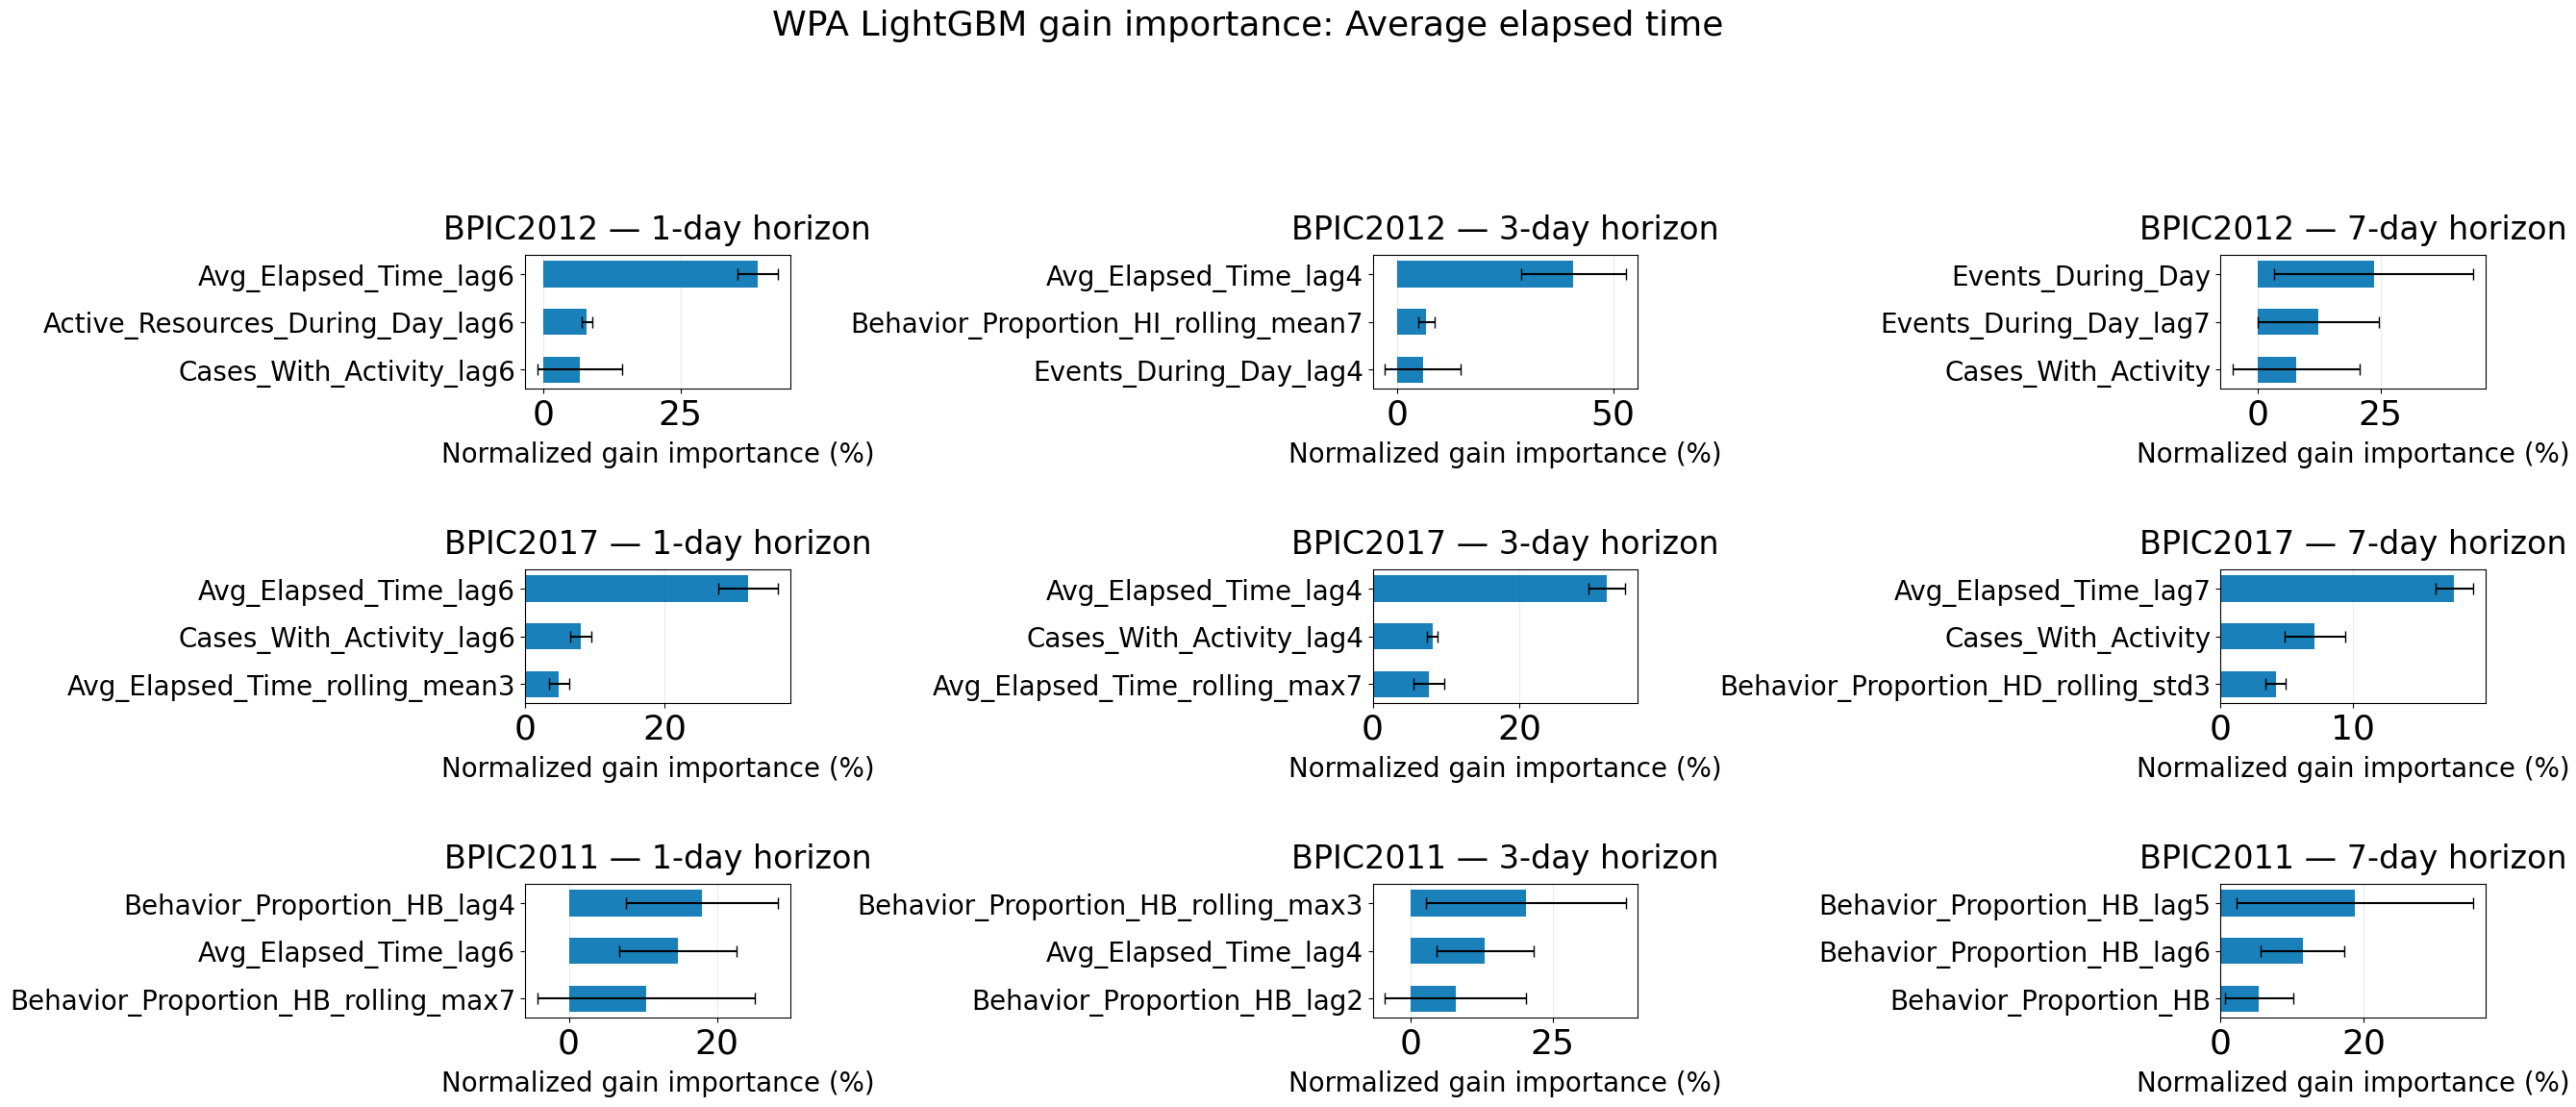

Saved: /content/WPA_LightGBM_importance_results/Avg_Remaining_Time_gain_importance_by_dataset_horizon.png


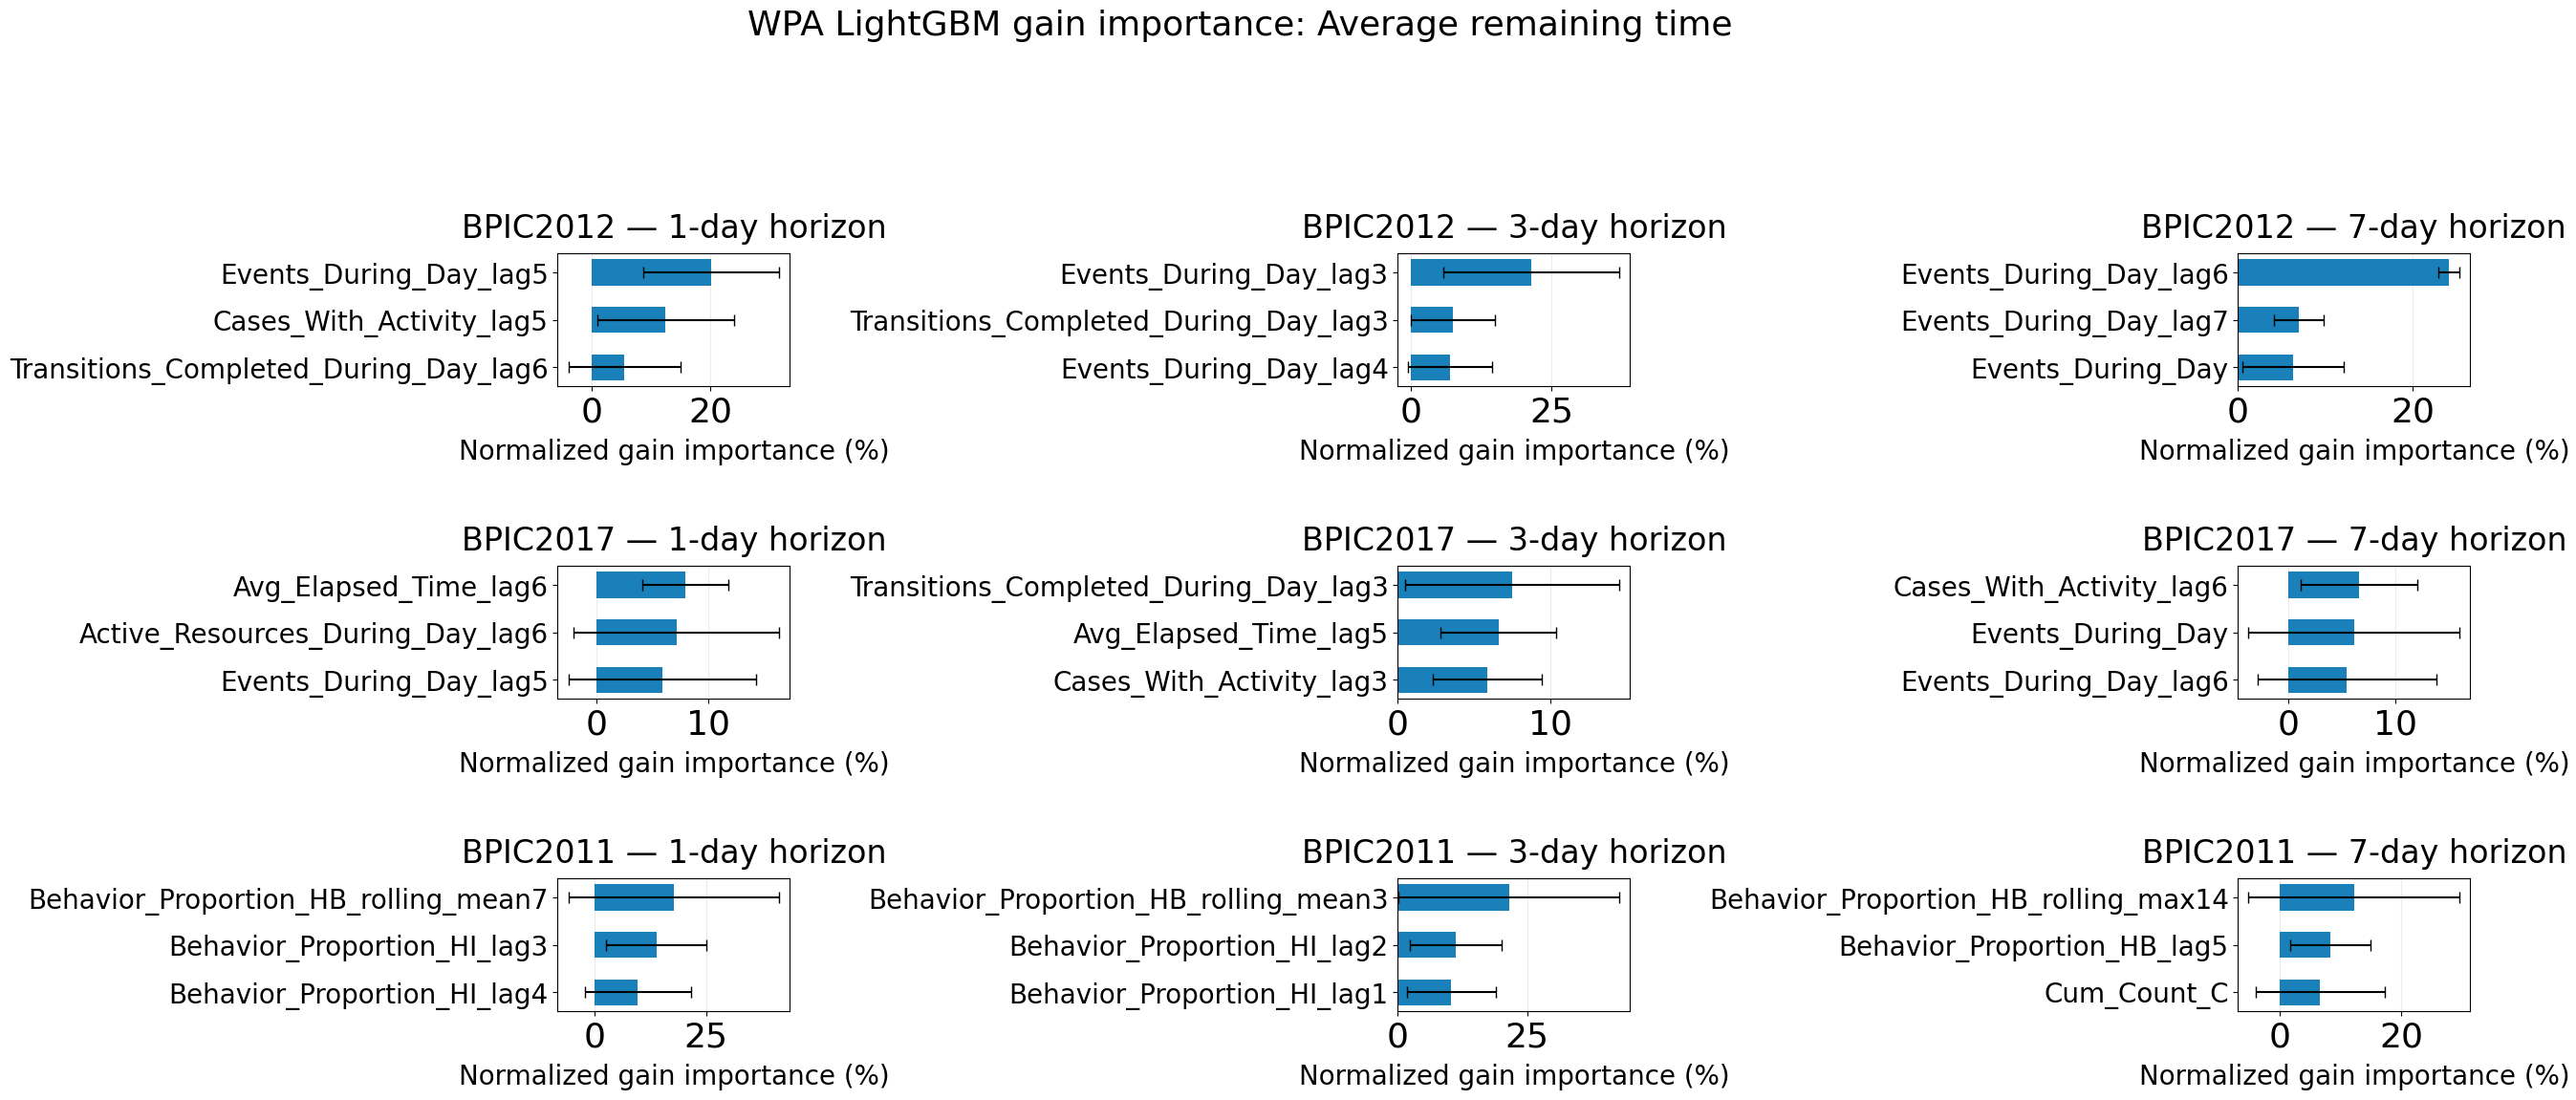

Models analyzed: 54
Results saved in: /content/WPA_LightGBM_importance_results
Downloading: /content/WPA_LightGBM_gain_only_all_datasets.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# Install SHAP if this Colab runtime does not already have it.
import importlib.util
import subprocess
import sys

if importlib.util.find_spec("shap") is None:
    subprocess.check_call(
        [sys.executable, "-m", "pip", "install", "-q", "shap"]
    )

import re
import zipfile
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap
from google.colab import files


# ============================================================
# SETTINGS
# ============================================================

# Run the ZIP-upload cell first to define DATASET_BUNDLE_DIRS.
if "DATASET_BUNDLE_DIRS" not in globals():
    raise NameError(
        "DATASET_BUNDLE_DIRS is not defined. "
        "Run the model ZIP-upload cell first."
    )

OUT_DIR = Path("/content/WPA_LightGBM_importance_results")
OUT_DIR.mkdir(parents=True, exist_ok=True)

dataset_order = ["BPIC2012", "BPIC2017", "BPIC2011"]
horizons = [1, 3, 7]
targets = ["Avg_Elapsed_Time", "Avg_Remaining_Time"]

# Adjust these values to change the appearance of all plots.
FIGURE_SIZE = (27, 12)
MAIN_TITLE_SIZE = 26
PANEL_TITLE_SIZE = 24
FEATURE_NAME_SIZE = 20
AXIS_LABEL_SIZE = 20
AXIS_NUMBER_SIZE = 26
LEGEND_SIZE = 26

task_pattern = re.compile(
    r"(fold_\d+_10)_(Avg_Elapsed_Time|Avg_Remaining_Time)_h([137])_"
    r"WorkloadPlusActor$"
)


# ============================================================
# CALCULATE GAIN AND SHAP IMPORTANCE
# ============================================================

importance_rows = []

for dataset, bundle_dir in DATASET_BUNDLE_DIRS.items():
    model_paths = sorted(
        bundle_dir.rglob("Tree_LightGBM_*_WorkloadPlusActor.joblib")
    )

    if not model_paths:
        raise FileNotFoundError(
            f"No WPA LightGBM models found for {dataset}."
        )

    print(f"{dataset}: processing {len(model_paths)} models")

    for model_path in model_paths:
        match = task_pattern.search(model_path.stem)

        if not match:
            print(f"Skipping unrecognized model filename: {model_path.name}")
            continue

        fold, target, horizon = match.groups()
        horizon = int(horizon)

        design_paths = [
            path
            for path in bundle_dir.rglob(f"{model_path.stem}.csv")
            if path.parent.name == "design_matrices"
        ]

        if len(design_paths) != 1:
            print(
                f"Skipping {model_path.name}: found "
                f"{len(design_paths)} matching design matrices."
            )
            continue

        saved = joblib.load(model_path)
        model = saved["model"]
        features = list(saved["features"])
        test_data = pd.read_csv(design_paths[0])

        missing = [
            feature
            for feature in features
            if feature not in test_data.columns
        ]

        if missing:
            print(
                f"Skipping {model_path.name}: "
                f"{len(missing)} model features are absent from its matrix."
            )
            continue

        # Use only the features supplied to the fitted model.
        X_test = test_data.loc[:, features]

        # Normalize gain within the fitted model.
        gain = np.asarray(
            model.booster_.feature_importance(importance_type="gain"),
            dtype=float,
        )

        gain_total = gain.sum()

        if gain_total > 0:
            gain_percent = gain / gain_total * 100
        else:
            gain_percent = np.zeros_like(gain)

        # Calculate SHAP values on the fold's held-out observations.
        explainer = shap.TreeExplainer(model)
        shap_values = explainer.shap_values(X_test)

        if isinstance(shap_values, list):
            shap_values = shap_values[0]

        shap_values = np.asarray(shap_values)

        # Handle SHAP versions with a singleton output dimension.
        if shap_values.ndim == 3:
            if shap_values.shape[-1] == 1:
                shap_values = shap_values[:, :, 0]
            elif shap_values.shape[0] == 1:
                shap_values = shap_values[0]

        if shap_values.ndim != 2:
            raise ValueError(
                f"Unexpected SHAP array shape for {model_path.name}: "
                f"{shap_values.shape}"
            )

        mean_abs_shap = np.abs(shap_values).mean(axis=0)
        shap_total = mean_abs_shap.sum()

        if shap_total > 0:
            shap_percent = mean_abs_shap / shap_total * 100
        else:
            shap_percent = np.zeros_like(mean_abs_shap)

        if len(features) != len(gain) or len(features) != len(shap_percent):
            raise ValueError(
                f"Feature-count mismatch for {model_path.name}: "
                f"{len(features)} features, {len(gain)} gain values, "
                f"{len(shap_percent)} SHAP values."
            )

        for feature, gain_value, gain_pct, shap_value, shap_pct in zip(
            features,
            gain,
            gain_percent,
            mean_abs_shap,
            shap_percent,
        ):
            importance_rows.append({
                "dataset": dataset,
                "fold": fold,
                "target": target,
                "horizon_days": horizon,
                "feature": feature,
                "gain": gain_value,
                "gain_percent": gain_pct,
                "mean_abs_shap": shap_value,
                "shap_percent": shap_pct,
                "n_heldout_rows": len(X_test),
            })


importance_results = pd.DataFrame(importance_rows)

if importance_results.empty:
    raise ValueError(
        "No importance values were calculated. Check the uploaded ZIPs "
        "and their model/design-matrix file pairs."
    )

importance_results.to_csv(
    OUT_DIR / "gain_and_shap_importance_by_fold.csv",
    index=False,
)


# ============================================================
# SUMMARIZE ACROSS FOLDS
# ============================================================

importance_summary = (
    importance_results
    .groupby(
        ["dataset", "target", "horizon_days", "feature"],
        as_index=False,
    )
    .agg(
        gain_mean=("gain_percent", "mean"),
        gain_sd=("gain_percent", "std"),
        shap_mean=("shap_percent", "mean"),
        shap_sd=("shap_percent", "std"),
        n_folds=("fold", "nunique"),
    )
)

importance_summary[["gain_sd", "shap_sd"]] = (
    importance_summary[["gain_sd", "shap_sd"]].fillna(0)
)

importance_summary.to_csv(
    OUT_DIR / "gain_and_shap_importance_fold_summary.csv",
    index=False,
)

# ============================================================
# CREATE GAIN-ONLY FIGURES
# Rows: datasets
# Columns: forecast horizons
# ============================================================

# Number of features to display in each panel.
TOP_FEATURES = 3

for target in targets:
    fig, axes = plt.subplots(
        nrows=len(dataset_order),
        ncols=len(horizons),
        figsize=FIGURE_SIZE,
        squeeze=False,
    )

    for row, dataset in enumerate(dataset_order):
        for col, horizon in enumerate(horizons):
            ax = axes[row, col]

            panel = importance_summary[
                (importance_summary["dataset"] == dataset)
                & (importance_summary["target"] == target)
                & (importance_summary["horizon_days"] == horizon)
            ].copy()

            if panel.empty:
                ax.set_title(
                    f"{dataset} — {horizon}-day: no data",
                    fontsize=PANEL_TITLE_SIZE,
                )
                ax.axis("off")
                continue

            # Select and order features using mean normalized
            # LightGBM gain across the available folds.
            selected = (
                panel.nlargest(TOP_FEATURES, "gain_mean")
                .sort_values("gain_mean", ascending=True)
                .copy()
            )

            y = np.arange(len(selected))

            ax.barh(
                y,
                selected["gain_mean"],
                xerr=selected["gain_sd"],
                height=0.55,
                color="#0072B2",
                alpha=0.9,
                capsize=4,
                error_kw={"elinewidth": 1.5},
            )

            ax.set_yticks(y)
            ax.set_yticklabels(
                selected["feature"],
                fontsize=FEATURE_NAME_SIZE,
            )

            ax.set_title(
                f"{dataset} — {horizon}-day horizon",
                fontsize=PANEL_TITLE_SIZE,
                pad=12,
            )

            ax.set_xlabel(
                "Normalized gain importance (%)",
                fontsize=AXIS_LABEL_SIZE,
                labelpad=8,
            )

            ax.tick_params(
                axis="x",
                labelsize=AXIS_NUMBER_SIZE,
            )

            ax.grid(axis="x", alpha=0.25)
            ax.set_axisbelow(True)

    target_title = {
        "Avg_Elapsed_Time": "Average elapsed time",
        "Avg_Remaining_Time": "Average remaining time",
    }[target]

    fig.suptitle(
        f"WPA LightGBM gain importance: {target_title}",
        fontsize=MAIN_TITLE_SIZE,
        y=0.995,
    )

    # There is only one measure and one colour, so no legend
    # is needed. The title and axis label identify the measure.
    fig.tight_layout(
        rect=[0, 0, 1, 0.95],
        pad=2.5,
    )

    figure_path = (
        OUT_DIR / f"{target}_gain_importance_by_dataset_horizon.png"
    )

    fig.savefig(
        figure_path,
        dpi=220,
        bbox_inches="tight",
    )

    print(f"Saved: {figure_path}")
    plt.show()
    plt.close(fig)


# ============================================================
# DOWNLOAD THE NEW FIGURES AND IMPORTANCE TABLES
# ============================================================

zip_path = Path("/content/WPA_LightGBM_gain_only_all_datasets.zip")

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as archive:
    # Add the two new gain-only figures.
    for target in targets:
        figure_path = (
            OUT_DIR / f"{target}_gain_importance_by_dataset_horizon.png"
        )
        if figure_path.exists():
            archive.write(
                figure_path,
                arcname=figure_path.name,
            )

    # Keep both gain and SHAP results available in the CSV files.
    for filename in [
        "gain_and_shap_importance_by_fold.csv",
        "gain_and_shap_importance_fold_summary.csv",
    ]:
        csv_path = OUT_DIR / filename
        if csv_path.exists():
            archive.write(
                csv_path,
                arcname=csv_path.name,
            )

n_models = importance_results[
    ["dataset", "fold", "target", "horizon_days"]
].drop_duplicates().shape[0]

print(f"Models analyzed: {n_models}")
print(f"Results saved in: {OUT_DIR}")
print(f"Downloading: {zip_path}")

files.download(str(zip_path))

Saved: /content/WPA_LightGBM_SHAP_by_fold/Avg_Elapsed_Time_SHAP_by_fold.png


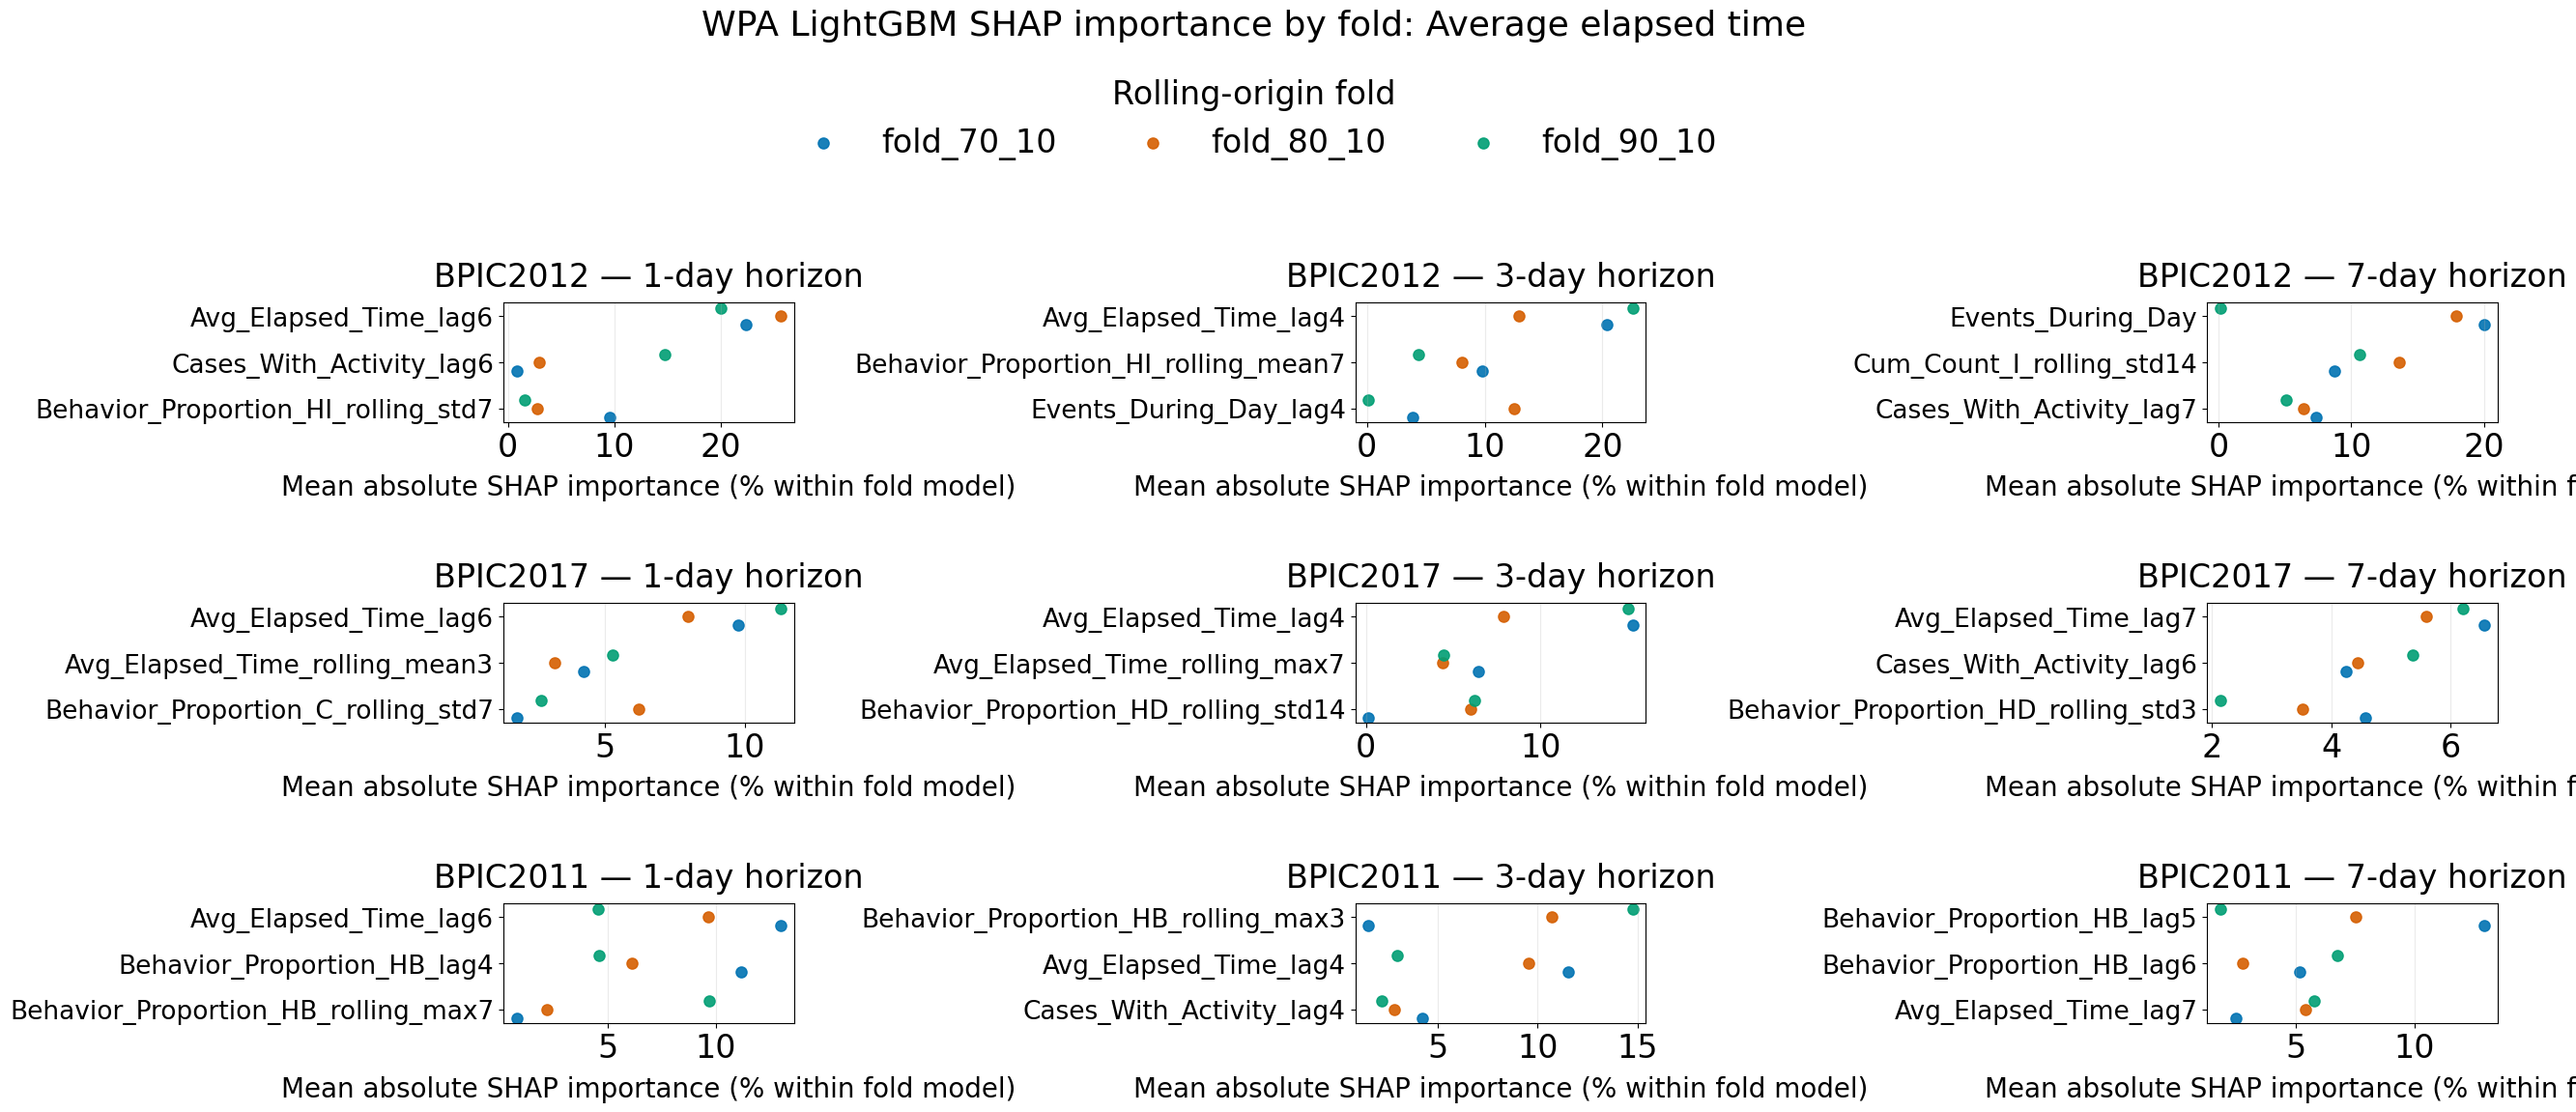

Saved: /content/WPA_LightGBM_SHAP_by_fold/Avg_Remaining_Time_SHAP_by_fold.png


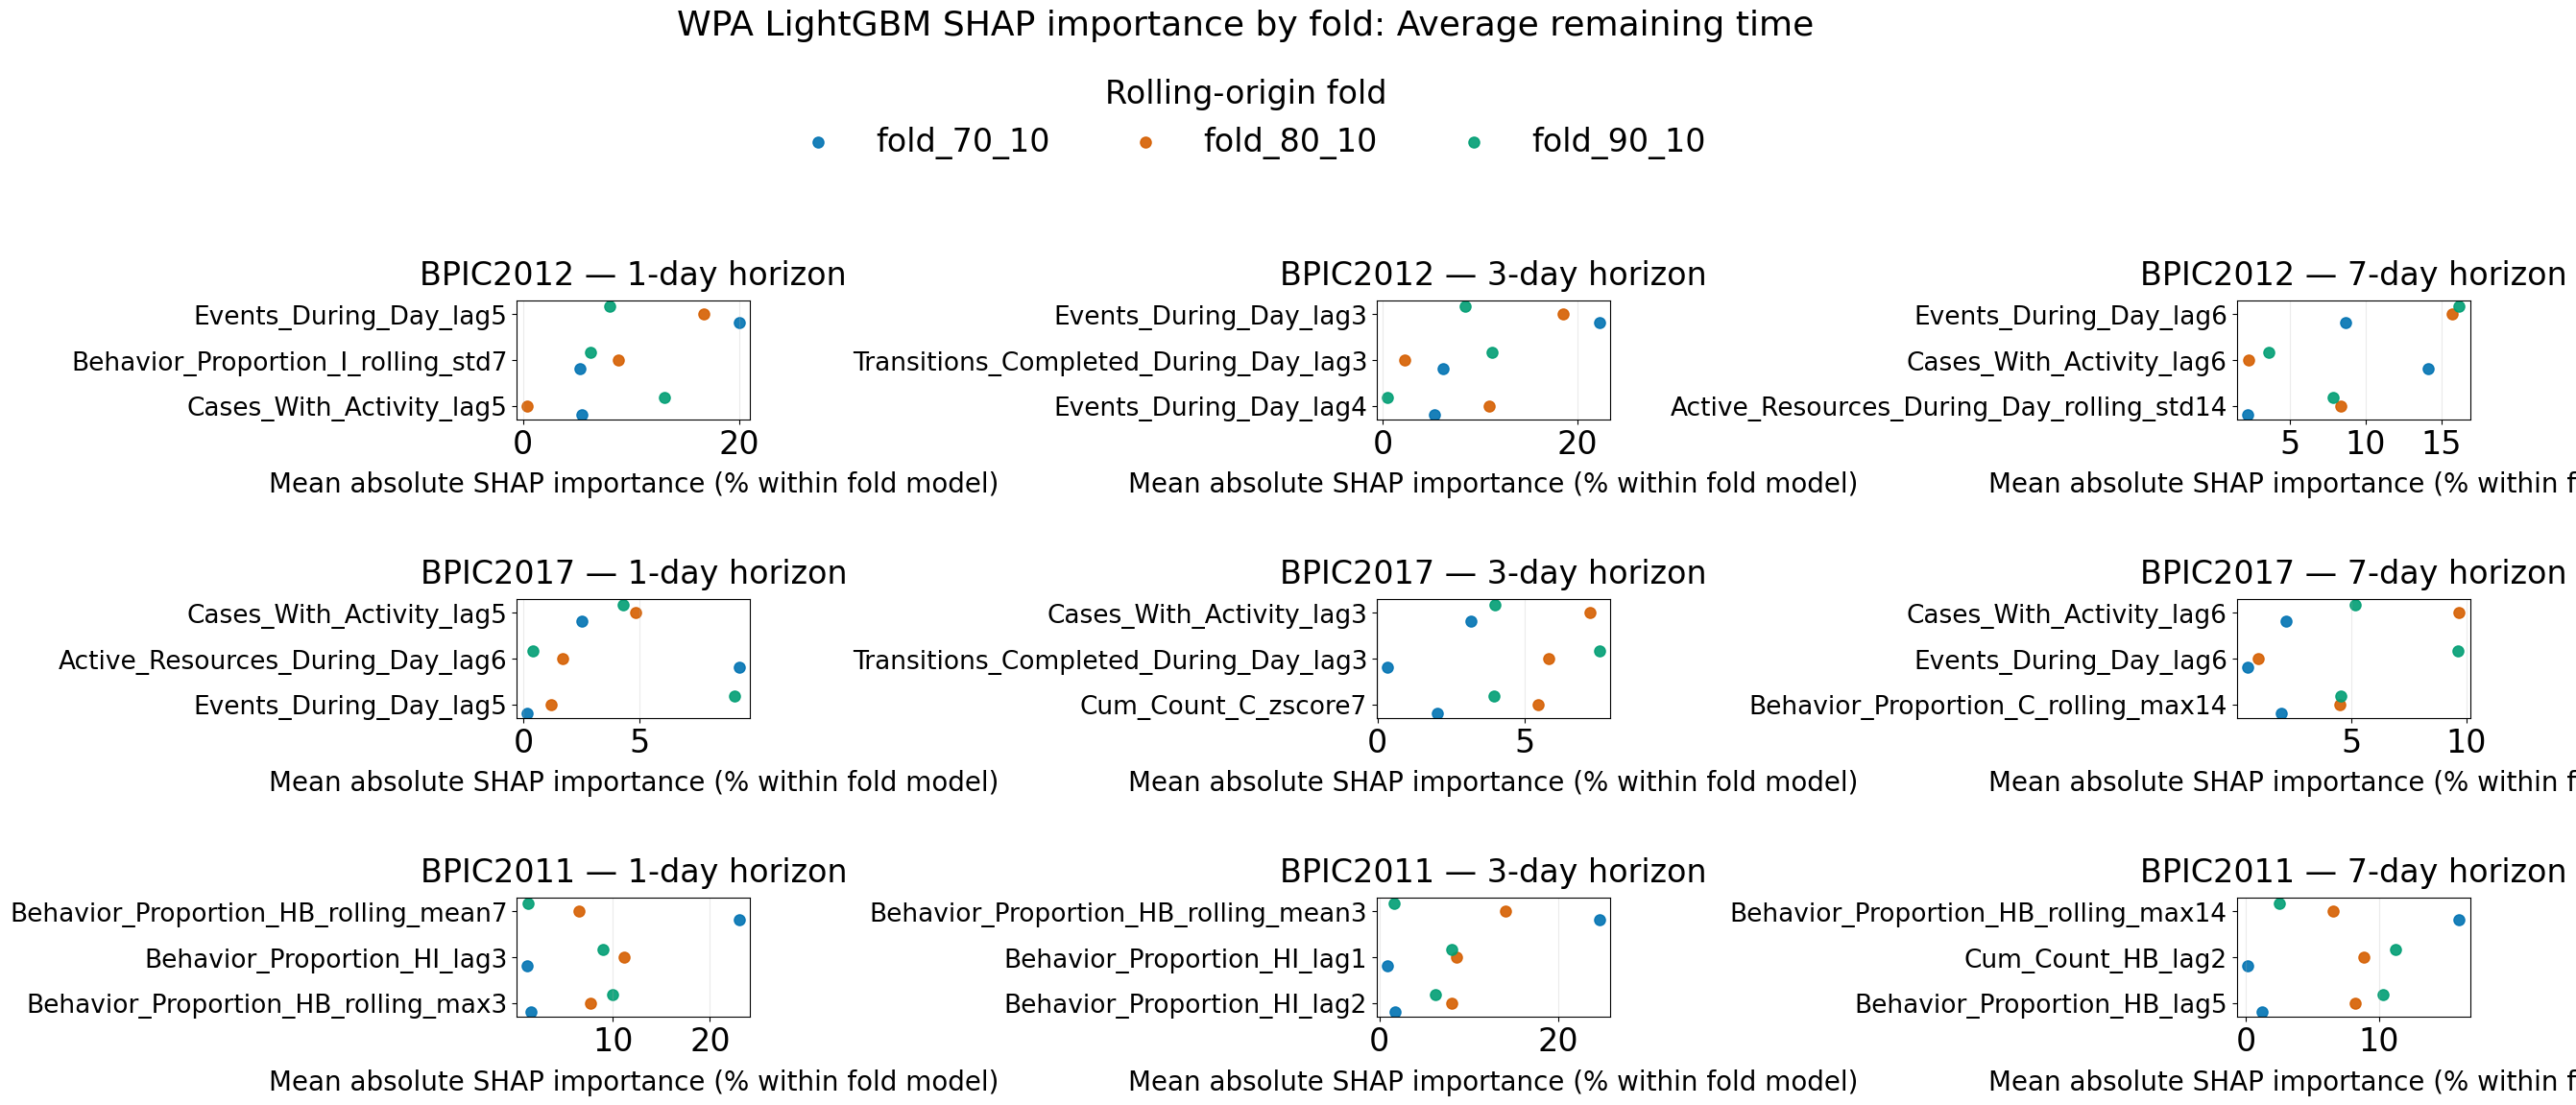

Results saved in: /content/WPA_LightGBM_SHAP_by_fold
Downloading: /content/WPA_LightGBM_SHAP_by_fold.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import zipfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from google.colab import files


# ============================================================
# CHECK THAT THE PREVIOUS CELL HAS BEEN RUN
# ============================================================

if "importance_results" not in globals() or importance_results.empty:
    raise RuntimeError(
        "Run the previous gain-and-SHAP cell first to calculate "
        "the fold-level SHAP values."
    )


# ============================================================
# SETTINGS
# ============================================================

# Adjust these values to change the appearance of all plots.
FIGURE_SIZE = (27, 12)
MAIN_TITLE_SIZE = 26
PANEL_TITLE_SIZE = 24
FEATURE_NAME_SIZE = 19
AXIS_LABEL_SIZE = 20
AXIS_NUMBER_SIZE = 24
LEGEND_SIZE = 24
LEGEND_TITLE_SIZE = 24

# Marker size for the individual fold results.
MARKER_SIZE = 65

FOLD_COLORS = {
    "fold_70_10": "#0072B2",
    "fold_80_10": "#D55E00",
    "fold_90_10": "#009E73",
}

FOLD_OFFSETS = {
    "fold_70_10": -0.18,
    "fold_80_10": 0.00,
    "fold_90_10": 0.18,
}

fold_plot_dir = Path("/content/WPA_LightGBM_SHAP_by_fold")
fold_plot_dir.mkdir(parents=True, exist_ok=True)

dataset_order = ["BPIC2012", "BPIC2017", "BPIC2011"]
horizons = [1, 3, 7]
targets = ["Avg_Elapsed_Time", "Avg_Remaining_Time"]


# ============================================================
# CREATE ONE FIGURE PER TARGET
# Rows: datasets
# Columns: forecast horizons
# Colours: rolling-origin folds
# ============================================================

for target in targets:
    fig, axes = plt.subplots(
        nrows=len(dataset_order),
        ncols=len(horizons),
        figsize=FIGURE_SIZE,
        squeeze=False,
    )

    # Collect legend entries from all panels. This also works
    # when the first panel has no data or a fold is missing.
    legend_entries = {}

    for row, dataset in enumerate(dataset_order):
        for col, horizon in enumerate(horizons):
            ax = axes[row, col]

            panel = importance_results[
                (importance_results["dataset"] == dataset)
                & (importance_results["target"] == target)
                & (importance_results["horizon_days"] == horizon)
            ].copy()

            if panel.empty:
                ax.set_title(
                    f"{dataset} — {horizon}-day: no data",
                    fontsize=PANEL_TITLE_SIZE,
                )
                ax.axis("off")
                continue

            # Select a common set of ten features for the panel,
            # ordered by mean normalized SHAP importance across folds.
            feature_order = (
                panel.groupby("feature")["shap_percent"]
                .mean()
                .nlargest(3)
                .sort_values(ascending=True)
                .index.tolist()
            )

            y_positions = {
                feature: index
                for index, feature in enumerate(feature_order)
            }

            for fold, fold_data in panel.groupby("fold"):
                if fold not in FOLD_COLORS:
                    continue

                fold_data = fold_data[
                    fold_data["feature"].isin(feature_order)
                ]

                y = [
                    y_positions[feature] + FOLD_OFFSETS[fold]
                    for feature in fold_data["feature"]
                ]

                points = ax.scatter(
                    fold_data["shap_percent"],
                    y,
                    color=FOLD_COLORS[fold],
                    label=fold,
                    s=MARKER_SIZE,
                    alpha=0.9,
                )

                legend_entries[fold] = points

            ax.set_yticks(range(len(feature_order)))
            ax.set_yticklabels(
                feature_order,
                fontsize=FEATURE_NAME_SIZE,
            )

            ax.set_title(
                f"{dataset} — {horizon}-day horizon",
                fontsize=PANEL_TITLE_SIZE,
                pad=12,
            )

            ax.set_xlabel(
                "Mean absolute SHAP importance (% within fold model)",
                fontsize=AXIS_LABEL_SIZE,
                labelpad=8,
            )

            ax.tick_params(
                axis="x",
                labelsize=AXIS_NUMBER_SIZE,
            )

            ax.grid(axis="x", alpha=0.25)

    target_title = {
        "Avg_Elapsed_Time": "Average elapsed time",
        "Avg_Remaining_Time": "Average remaining time",
    }[target]

    fig.suptitle(
        f"WPA LightGBM SHAP importance by fold: {target_title}",
        fontsize=MAIN_TITLE_SIZE,
        y=0.995,
    )

    # Display the folds in chronological order.
    fold_order = [
        "fold_70_10",
        "fold_80_10",
        "fold_90_10",
    ]

    available_folds = [
        fold for fold in fold_order
        if fold in legend_entries
    ]

    if available_folds:
        fig.legend(
            [legend_entries[fold] for fold in available_folds],
            available_folds,
            loc="upper center",
            bbox_to_anchor=(0.5, 0.96),
            ncol=3,
            title="Rolling-origin fold",
            fontsize=LEGEND_SIZE,
            title_fontsize=LEGEND_TITLE_SIZE,
            frameon=False,
        )

    # Reserve space above the panels for the title and legend.
    fig.tight_layout(
        rect=[0, 0, 1, 0.91],
        pad=2.5,
    )

    figure_path = fold_plot_dir / f"{target}_SHAP_by_fold.png"

    fig.savefig(
        figure_path,
        dpi=220,
        bbox_inches="tight",
    )

    print(f"Saved: {figure_path}")
    plt.show()
    plt.close(fig)


# ============================================================
# SAVE THE FOLD-LEVEL TABLE AND DOWNLOAD EVERYTHING
# ============================================================

importance_results.to_csv(
    fold_plot_dir / "SHAP_importance_by_dataset_fold_target_horizon.csv",
    index=False,
)

zip_path = Path("/content/WPA_LightGBM_SHAP_by_fold.zip")

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as archive:
    for path in fold_plot_dir.rglob("*"):
        if path.is_file():
            archive.write(
                path,
                arcname=path.relative_to(fold_plot_dir),
            )

print(f"Results saved in: {fold_plot_dir}")
print(f"Downloading: {zip_path}")

files.download(str(zip_path))